# CS781 Phase 3 – Rhetorical / document classification (all 4 backbones)

Each architecture section includes:
1. **Phase-1 model + tokenizer classes** (for `load_phase1` / backbone wrapper)
2. Full Phase-3 cells (views, LoRMA / AdaLoRA / BitFit / KD, train, `results_df`, plots, threshold tuning, submission)

Activate the architecture, Run All.


In [1]:
# !mkdir -p /kaggle/working/cs781_phase1/
# !cp -rv /kaggle/input/datasets/vidya6364/phase1-models/* /kaggle/working/cs781_phase1/
# !cp -v /kaggle/input/datasets/vidya6364/phase1-tokenizers/* /kaggle/working/phase1_models/
# !ls /kaggle/input/datasets/vidya6364/models/

# !mkdir -p /kaggle/working/phase3-alibi-gqa/
# !mkdir -p /kaggle/working/phase3-custom-mha/
# !mkdir -p /kaggle/working/phase3-gqa-conv/
# !mkdir -p /kaggle/working/phase3-mla-moe/
# !cp -rv /kaggle/input/datasets/vidya6364/phase3-models/phase3_bundle_alibi_gqa/* /kaggle/working/phase3-alibi-gqa/
# !cp -rv /kaggle/input/datasets/vidya6364/phase3-models/phase3_bundle_custom_mha/* /kaggle/working/phase3-custom-mha/
# !cp -rv /kaggle/input/datasets/vidya6364/phase3-models/phase3_bundle_gqa_conv/* /kaggle/working/phase3-gqa-conv/
# !cp -rv /kaggle/input/datasets/vidya6364/phase3-models/phase3_bundle_mla_moe/* /kaggle/working/phase3-mla-moe/
# !ls

'/kaggle/input/datasets/vidya6364/phase1-models/latest_checkpoint_alibi_gqa.pt' -> '/kaggle/working/cs781_phase1/latest_checkpoint_alibi_gqa.pt'
'/kaggle/input/datasets/vidya6364/phase1-models/latest_checkpoint_gqa_conv.pt' -> '/kaggle/working/cs781_phase1/latest_checkpoint_gqa_conv.pt'
'/kaggle/input/datasets/vidya6364/phase1-models/latest_checkpoint_mla_moe.pt' -> '/kaggle/working/cs781_phase1/latest_checkpoint_mla_moe.pt'
'/kaggle/input/datasets/vidya6364/phase1-models/legal_bpe_custom_mha.json' -> '/kaggle/working/cs781_phase1/legal_bpe_custom_mha.json'
'/kaggle/input/datasets/vidya6364/phase1-models/legal_bpe_gqa_conv.json' -> '/kaggle/working/cs781_phase1/legal_bpe_gqa_conv.json'
'/kaggle/input/datasets/vidya6364/phase1-models/legal_bpe_mla_moe.json' -> '/kaggle/working/cs781_phase1/legal_bpe_mla_moe.json'
'/kaggle/input/datasets/vidya6364/phase1-models/legal_bpe_tokenizer_gqa_alibi.pkl' -> '/kaggle/working/cs781_phase1/legal_bpe_tokenizer_gqa_alibi.pkl'
'/kaggle/input/datasets/v

In [2]:
# !cp -rv "/kaggle/input/datasets/vidya6364/phase1-models-1k"/* /kaggle/working/cs781_phase1/

In [3]:
# ═══════════════════════════════════════════════════════════════════════════
# Shared path resolution for all 4 Phase-1 backbones
# ═══════════════════════════════════════════════════════════════════════════
import os
try:
    from kaggle_secrets import UserSecretsClient
    from huggingface_hub import login
    HF_TOKEN = UserSecretsClient().get_secret("HF")
    login(token=HF_TOKEN)
    print("HF login OK")
except Exception as e:
    HF_TOKEN = os.environ.get("HF_TOKEN")
    print("HF login skipped:", e)
    
OUT_DIR = "/kaggle/working/cs781_phase1" if os.path.isdir("/kaggle/working") else "./cs781_phase1"
DATASET_DIR = os.environ.get("DATASET_DIR", OUT_DIR)
os.makedirs(OUT_DIR, exist_ok=True)

def _first(*paths):
    for p in paths:
        if p and os.path.exists(p):
            return p
    return paths[0]

TOK_PATHS = {
    "custom_mha": _first(
        os.path.join(DATASET_DIR, "legal_bpe_custom_mha.json"),
        os.path.join(DATASET_DIR, "legal_bpe_v2.json"),
    ),
    "mla_moe": _first(
        os.path.join(DATASET_DIR, "legal_bpe_mla_moe.json"),
        os.path.join(DATASET_DIR, "legal_bpe_v2.json"),
    ),
    "gqa_conv": _first(
        os.path.join(DATASET_DIR, "legal_bpe_gqa_conv.json"),
        os.path.join(DATASET_DIR, "legal_bpe_v2.json"),
    ),
    "gqa_alibi": _first(
        os.path.join(DATASET_DIR, "legal_bpe_tokenizer_gqa_alibi.pkl"),
        os.path.join(DATASET_DIR, "legal_bpe_alibi_gqa.pkl"),
        os.path.join(DATASET_DIR, "legal_bpe_v2.json"),
    ),
}

CKPT_V2 = _first(
    os.path.join(DATASET_DIR, "legal_lm_custom_mha.pt"),
    os.path.join(DATASET_DIR, "phase1_models", "legal_lm_custom_mha.pt"),
    os.path.join(OUT_DIR, "legal_lm_custom_mha.pt"),
)
CKPT_V3 = _first(
    os.path.join(DATASET_DIR, "latest_checkpoint_mla_moe_1k.pt"),
    os.path.join(DATASET_DIR, "legal_lm_mla_moe.pt"),
    
    os.path.join(DATASET_DIR, "phase1_models", "legal_lm_mla_moe_1k.pt"),
    os.path.join(OUT_DIR, "latest_checkpoint_v3.pt"),
)
CKPT_GQA = _first(
    os.path.join(DATASET_DIR, "latest_checkpoint_gqa_conv.pt"),
    os.path.join(DATASET_DIR, "legal_lm_gqa_conv.pt"),
    
    os.path.join(DATASET_DIR, "phase1_models", "legal_lm_gqa_conv.pt"),
    os.path.join(OUT_DIR, "latest_checkpoint_v3_fixed.pt"),
)
CKPT_ALIBI = _first(
    os.path.join(DATASET_DIR, "latest_checkpoint_alibi_gqa.pt"),
    os.path.join(DATASET_DIR, "legal_lm_alibi_gqa.pt"),
    
    os.path.join(DATASET_DIR, "legal_lm_alibi.pt"),
    os.path.join(DATASET_DIR, "phase1_models", "legal_lm_alibi_gqa.pt"),
    os.path.join(OUT_DIR, "latest_checkpoint_alibi.pt"),
)
CKPTS = {
    "custom_mha": CKPT_V2,
    "mla_moe": CKPT_V3,
    "gqa_conv": CKPT_GQA,
    "gqa_alibi": CKPT_ALIBI,
}

print("Available tokenizers / checkpoints:")
for k in TOK_PATHS:
    print(f"  tok [{k:12s}] exists={str(os.path.exists(TOK_PATHS[k])):5s}  {TOK_PATHS[k]}")
for k in CKPTS:
    print(f"  ckpt[{k:12s}] exists={str(os.path.exists(CKPTS[k])):5s}  {CKPTS[k]}")


HF login OK
Available tokenizers / checkpoints:
  tok [custom_mha  ] exists=True   /kaggle/working/cs781_phase1/legal_bpe_custom_mha.json
  tok [mla_moe     ] exists=True   /kaggle/working/cs781_phase1/legal_bpe_mla_moe.json
  tok [gqa_conv    ] exists=True   /kaggle/working/cs781_phase1/legal_bpe_gqa_conv.json
  tok [gqa_alibi   ] exists=True   /kaggle/working/cs781_phase1/legal_bpe_tokenizer_gqa_alibi.pkl
  ckpt[custom_mha  ] exists=True   /kaggle/working/cs781_phase1/legal_lm_custom_mha.pt
  ckpt[mla_moe     ] exists=True   /kaggle/working/cs781_phase1/latest_checkpoint_mla_moe_1k.pt
  ckpt[gqa_conv    ] exists=True   /kaggle/working/cs781_phase1/latest_checkpoint_gqa_conv.pt
  ckpt[gqa_alibi   ] exists=True   /kaggle/working/cs781_phase1/latest_checkpoint_alibi_gqa.pt


---
## Architecture: `custom_mha`

Source: `cs781-legal-lm-custom-mha.ipynb`


In [4]:
# ── Activate backbone: custom_mha ──────────────────────────────────────────────
BACKBONE = "custom_mha"
TOKENIZER_PATH = TOK_PATHS["custom_mha"]
PHASE1_CKPT = CKPTS["custom_mha"]
MODEL_PATH = PHASE1_CKPT
CKPT_PATH = PHASE1_CKPT
if "OUT_DIR" not in dir() or not OUT_DIR:
    OUT_DIR = "/kaggle/working/cs781_phase1" if os.path.isdir("/kaggle/working") else "./cs781_phase1"
DATA_DIR = os.path.join(OUT_DIR, "data")
os.makedirs(DATA_DIR, exist_ok=True)
print(f"[active] BACKBONE={BACKBONE}")
print(f"[active] TOKENIZER_PATH={TOKENIZER_PATH}  exists={os.path.exists(TOKENIZER_PATH)}")
print(f"[active] PHASE1_CKPT={PHASE1_CKPT}  exists={os.path.exists(PHASE1_CKPT)}")
print(f"[active] MODEL_CKPT={MODEL_PATH}  exists={os.path.exists(MODEL_PATH)}")


[active] BACKBONE=custom_mha
[active] TOKENIZER_PATH=/kaggle/working/cs781_phase1/legal_bpe_custom_mha.json  exists=True
[active] PHASE1_CKPT=/kaggle/working/cs781_phase1/legal_lm_custom_mha.pt  exists=True
[active] MODEL_CKPT=/kaggle/working/cs781_phase1/legal_lm_custom_mha.pt  exists=True


### Phase-1 classes for `custom_mha` (tokenizer + model, needed to reload checkpoints)

These cells are taken from Phase 1 of the same source notebook. They define `BPETokenizer`,
the model stack (`LegalLM` / `DualPathLM` / …), and `load_model`. Internal bodies are unchanged.


In [5]:
import os, sys, re, gc, json, math, time, heapq, random, hashlib, unicodedata, zipfile, subprocess
import multiprocessing as mp
from collections import Counter, defaultdict, deque
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import torch.utils.checkpoint
from tqdm.auto import tqdm

try:
    import ijson
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "-q", "install", "ijson"])
    import ijson
from huggingface_hub import hf_hub_download, login

# ------------------------------- configuration -------------------------------
SEED = 42
HF_REPO = "Exploration-Lab/CS-781-Capstone"
TRAIN_FILES = {
    "acts":          "Phase_1_Pretraining/Train/train_acts.json",
    "supreme_court": "Phase_1_Pretraining/Train/train_supreme_court.json",
    "high_courts":   "Phase_1_Pretraining/Train/train_high_courts.json",
    "tribunals":     "Phase_1_Pretraining/Train/train_tribunals.json",
}
TEST_FILE = "Phase_1_Pretraining/Test/test.json"

# How many tokens to EXTRACT from each file (files differ a lot in size, so caps differ).
# Documents are sampled spread across the whole file, not just the first N rows.
SOURCE_TOKENS = {"acts": 15_000_000, "supreme_court": 35_000_000, "high_courts": 35_000_000, "tribunals": 25_000_000}
# How often each source is SAMPLED during training (equal by default).
SAMPLE_MIX = {"acts": 1.0, "supreme_court": 1.0, "high_courts": 0.15, "tribunals": 0.2}
VAL_TOKENS_PER_SOURCE = 500_000   # held-out docs (≈2% of docs, never used for training)
VAL_MOD = 50                      # doc goes to validation if hash % VAL_MOD == 0
BYTES_PER_TOKEN = 4.0             # rough, only used to decide how sparsely to sample a file
NUM_WORKERS = 3                   # tokenizer processes for preprocessing (0 = single process)

VOCAB_SIZE = 24000
TOK_CHARS_PER_SOURCE = 4_000_000  # text used to train the BPE, per source

# model (~66M params with SwiGLU)
BLOCK_SIZE, N_EMBD, N_LAYER, N_HEAD = 1024, 768, 8, 12
BATCH_SIZE, GRAD_ACCUM = 8, 8    # 16*4*1024 = 65k tokens / optimizer step
TRAIN_TOKENS = 150_000_000        # total tokens seen in training (several passes over small sources is fine)
LR, MIN_LR, WEIGHT_DECAY, WARMUP_STEPS = 6e-4, 6e-5, 0.1, 100
EVAL_EVERY, EVAL_WINDOWS, LOG_EVERY, CKPT_EVERY = 250, 48, 10, 250
MAX_TRAIN_HOURS = 8.0             # schedule is shortened automatically if throughput is too low
USE_GRAD_CKPT = True             # set True only if you hit OOM (about 30% slower)
USE_COMPILE = False

# generation
TARGET_WORDS, MAX_NEW_TOKENS, GEN_BATCH = 128, 320, 16
TEMPERATURE, TOP_P, TOP_K, REP_PENALTY = 0.7, 0.9, 50, 1.15

OUT_DIR = "/kaggle/working/cs781_phase1" if os.path.isdir("/kaggle/working") else "./cs781_phase1"
DATA_DIR = os.path.join(OUT_DIR, "data")
os.makedirs(DATA_DIR, exist_ok=True)
TOKENIZER_PATH = os.path.join(OUT_DIR, "legal_bpe_v2.json")
MODEL_PATH = os.path.join(OUT_DIR, "legal_lm_custom_mha.pt")
CKPT_PATH = os.path.join(OUT_DIR, "legal_lm_custom_mha.pt")
PREDICTION_PATH = os.path.join(OUT_DIR, "prediction.json")

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
AMP_DTYPE = torch.bfloat16 if (USE_AMP and torch.cuda.is_bf16_supported()) else torch.float16
if DEVICE.type == "cuda":
    torch.backends.cuda.matmul.allow_tf32 = True
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

# Never print the token (your previous notebook printed it - rotate that token on huggingface.co).
try:
    from kaggle_secrets import UserSecretsClient
    HF_TOKEN = UserSecretsClient().get_secret("HF")
except Exception:
    HF_TOKEN = os.environ.get("HF_TOKEN")
try:
    if HF_TOKEN: login(token=HF_TOKEN)
except Exception as e:
    print("HF login skipped:", e)
print("device:", DEVICE, "| amp dtype:", AMP_DTYPE if USE_AMP else None)

device: cpu | amp dtype: None


## 1. Text cleaning + byte-level BPE tokenizer

In [6]:
_QUOTES = str.maketrans({"“": '"', "”": '"', "„": '"', "‘": "'", "’": "'", "‚": "'", "`": "'", "´": "'",
                         "–": "-", "—": "-", "−": "-", "\u00ad": ""})
_CTRL = re.compile(r"[\x00-\x08\x0b\x0c\x0e-\x1f\x7f-\x9f]")
_WS = re.compile(r"[ \t\u00a0\u1680\u2000-\u200b\u202f\u205f\u3000\ufeff]+")
_DOTS = re.compile(r"\.{4,}|(?:\. ){4,}")
_RULE = re.compile(r"[_\-=*~#]{3,}")
_PAGE = re.compile(r"(?mi)^[ \t]*(?:page\s+)?\d{1,4}[ \t]*$\n?")
_HYPH = re.compile(r"(?<=[a-z])-\n(?=[a-z])")
_WRAP = re.compile(r"(?<=[a-z,;])\n(?=[a-z(])")

def clean_text(t):
    """Light, conservative normalisation of legal text."""
    t = unicodedata.normalize("NFKC", str(t)).replace("\r\n", "\n").replace("\r", "\n")
    t = t.translate(_QUOTES)
    t = _CTRL.sub(" ", t)
    t = _HYPH.sub("", t)
    t = _DOTS.sub("...", t)
    t = _RULE.sub(" ", t)
    t = _PAGE.sub("", t)
    t = _WS.sub(" ", t)
    t = re.sub(r" *\n *", "\n", t)
    t = _WRAP.sub(" ", t)
    t = re.sub(r"\n{3,}", "\n\n", t)
    return t.strip()


class BPETokenizer:
    SPECIALS = ["<pad>", "<unk>", "<s>", "</s>"]
    _split = re.compile(r" ?[^\W\d_]+| ?\d+| ?[^\s\w]+| ?_+|\s+(?!\S)|\s+")

    def __init__(self, vocab_size=12000):
        self.vocab_size = vocab_size
        self.merges = []
        self._reset()

    def _reset(self):
        self.itos = list(self.SPECIALS) + [bytes([i]) for i in range(256)]
        self._cache = {}

    def _build(self):
        self.itos = list(self.SPECIALS) + [bytes([i]) for i in range(256)]
        seen = set(self.itos[4:])
        for a, b in self.merges:
            m = a + b
            if m not in seen:
                seen.add(m); self.itos.append(m)
        self.stoi = {t: i for i, t in enumerate(self.itos)}
        self.ranks = {pair: r for r, pair in enumerate(self.merges)}
        self.merged = {pair: pair[0] + pair[1] for pair in self.merges}
        self._cache = {}
        self.pad_id, self.unk_id, self.bos_id, self.eos_id = 0, 1, 2, 3
        self.vocab_size = len(self.itos)

    def _word(self, w):
        r = self._cache.get(w)
        if r is not None: return r
        toks = [bytes([b]) for b in w.encode("utf-8")]
        while len(toks) > 1:
            best_i, best_r = -1, 1 << 60
            for i in range(len(toks) - 1):
                r_ = self.ranks.get((toks[i], toks[i + 1]), 1 << 60)
                if r_ < best_r: best_i, best_r = i, r_
            if best_i < 0: break
            toks[best_i:best_i + 2] = [toks[best_i] + toks[best_i + 1]]
        r = [self.stoi.get(t, self.unk_id) for t in toks]
        if len(self._cache) > 500_000: self._cache.clear()
        self._cache[w] = r
        return r

    def encode(self, text, add_bos=False, add_eos=False):
        ids = []
        if add_bos: ids.append(self.bos_id)
        for w in self._split.findall(text):
            ids.extend(self._word(w))
        if add_eos: ids.append(self.eos_id)
        return ids

    def decode(self, ids):
        if isinstance(ids, torch.Tensor): ids = ids.tolist()
        parts = []
        for i in ids:
            if i < 4: continue
            t = self.itos[i] if i < len(self.itos) else b""
            if isinstance(t, bytes):
                try: parts.append(t.decode("utf-8"))
                except Exception: parts.append("�")
            else:
                parts.append(str(t))
        return "".join(parts)

    def save(self, path):
        with open(path, "w") as f:
            json.dump({"merges": [[a.hex(), b.hex()] for a, b in self.merges]}, f)

    @classmethod
    def load(cls, path):
        with open(path) as f:
            data = json.load(f)
        tok = cls()
        tok.merges = [(bytes.fromhex(a), bytes.fromhex(b)) for a, b in data["merges"]]
        tok._build()
        return tok

    @classmethod
    def load_any(cls, path):
        """Load from either the original JSON format or a pickle dump.

        Why this exists
        ---------------
        Phase-1 models were trained with different BPE tables.  Some exports
        are the original JSON (list of hex merges); others are full pickle
        dumps of the tokenizer object or of a dict containing "merges".
        This helper accepts both so you can drop .pkl files straight into
        DATASET_DIR without converting them first.
        """
        path = str(path)
        if path.endswith((".pkl", ".pickle")):
            import pickle
            with open(path, "rb") as f:
                obj = pickle.load(f)
            if isinstance(obj, cls):
                return obj
            if isinstance(obj, dict):
                tok = cls()
                if "merges" in obj:
                    merges = obj["merges"]
                    # hex-encoded (from .json export) or raw bytes
                    if merges and isinstance(merges[0][0], str):
                        tok.merges = [(bytes.fromhex(a), bytes.fromhex(b)) for a, b in merges]
                    else:
                        tok.merges = [(bytes(a), bytes(b)) for a, b in merges]
                    tok._build()
                    return tok
                # full state-dict style
                for k, v in obj.items():
                    setattr(tok, k, v)
                if not getattr(tok, "stoi", None):
                    tok._build()
                return tok
            raise TypeError(f"Unrecognised pickle content in {path}: {type(obj)}")
        # original JSON path
        return cls.load(path)


assert os.path.exists(TOKENIZER_PATH), f"Tokenizer not found at {TOKENIZER_PATH}"
tokenizer = BPETokenizer.load_any(TOKENIZER_PATH)
print(f"Tokenizer loaded | vocab_size = {tokenizer.vocab_size} | from {TOKENIZER_PATH}")

# Pre-load every available tokenizer so Phase 4 can switch per experiment.
# Specials (pad/unk/bos/eos = 0/1/2/3) are identical across files; only merges/vocab differ.
TOKENIZERS = {}
for _name, _path in TOK_PATHS.items():
    if os.path.exists(_path):
        TOKENIZERS[_name] = BPETokenizer.load_any(_path)
        print(f"  tok[{_name}]: vocab={TOKENIZERS[_name].vocab_size}  <- {_path}")
    else:
        print(f"  tok[{_name}]: MISSING {_path}")
# keep global `tokenizer` pointing at the BACKBONE selected in the config cell
tokenizer = TOKENIZERS.get(BACKBONE, tokenizer)
print(f"Active tokenizer for BACKBONE={BACKBONE}: vocab={tokenizer.vocab_size}")


Tokenizer loaded | vocab_size = 30000 | from /kaggle/working/cs781_phase1/legal_bpe_v2.json
  tok[custom_mha]: vocab=24000  <- /kaggle/working/cs781_phase1/legal_bpe_custom_mha.json
  tok[mla_moe]: vocab=30000  <- /kaggle/working/cs781_phase1/legal_bpe_mla_moe.json
  tok[gqa_conv]: vocab=30000  <- /kaggle/working/cs781_phase1/legal_bpe_gqa_conv.json
  tok[gqa_alibi]: vocab=32000  <- /kaggle/working/cs781_phase1/legal_bpe_tokenizer_gqa_alibi.pkl
Active tokenizer for BACKBONE=custom_mha: vocab=24000


## 4. Model: RoPE + RMSNorm + SwiGLU decoder, with KV-cache generation

In [7]:
class RMSNorm(nn.Module):
    def __init__(self, d, eps=1e-6):
        super().__init__(); self.w = nn.Parameter(torch.ones(d)); self.eps = eps
    def forward(self, x):
        xf = x.float()
        return (xf * torch.rsqrt(xf.pow(2).mean(-1, keepdim=True) + self.eps)).type_as(x) * self.w

class RoPE(nn.Module):
    def __init__(self, hd, max_len, base=10000.0):
        super().__init__()
        inv = 1.0 / (base ** (torch.arange(0, hd, 2).float() / hd))
        fr = torch.outer(torch.arange(max_len).float(), inv)
        self.register_buffer("cos", fr.cos(), persistent=False)
        self.register_buffer("sin", fr.sin(), persistent=False)
    def forward(self, x, start=0):                      # x: (b, heads, t, hd)
        t = x.size(2)
        cos, sin = self.cos[start:start + t].to(x.dtype), self.sin[start:start + t].to(x.dtype)
        x1, x2 = x.chunk(2, dim=-1)
        return torch.cat((x1 * cos - x2 * sin, x2 * cos + x1 * sin), dim=-1)

class Attention(nn.Module):
    def __init__(self, dim, heads, block_size):
        super().__init__()
        assert dim % heads == 0
        self.h, self.hd = heads, dim // heads
        self.qkv = nn.Linear(dim, 3 * dim, bias=False)
        self.proj = nn.Linear(dim, dim, bias=False)
        self.rope = RoPE(self.hd, block_size)
    def forward(self, x, mask=None, cache=None, start=0):
        b, t, c = x.shape
        q, k, v = self.qkv(x).reshape(b, t, 3, self.h, self.hd).permute(2, 0, 3, 1, 4)
        q, k = self.rope(q, start), self.rope(k, start)
        if cache is not None:
            if cache[0] is not None:
                k, v = torch.cat([cache[0], k], 2), torch.cat([cache[1], v], 2)
            cache = (k, v)
        if mask is not None:   y = F.scaled_dot_product_attention(q, k, v, attn_mask=mask)
        elif t > 1:            y = F.scaled_dot_product_attention(q, k, v, is_causal=True)
        else:                  y = F.scaled_dot_product_attention(q, k, v)
        return self.proj(y.transpose(1, 2).reshape(b, t, c)), cache

class SwiGLU(nn.Module):
    def __init__(self, dim):
        super().__init__()
        hid = int(8 * dim / 3 / 64) * 64
        self.w13 = nn.Linear(dim, 2 * hid, bias=False)
        self.w2 = nn.Linear(hid, dim, bias=False)
    def forward(self, x):
        a, b = self.w13(x).chunk(2, dim=-1)
        return self.w2(F.silu(a) * b)

class Block(nn.Module):
    def __init__(self, dim, heads, block_size):
        super().__init__()
        self.n1, self.n2 = RMSNorm(dim), RMSNorm(dim)
        self.attn, self.mlp = Attention(dim, heads, block_size), SwiGLU(dim)
    def forward(self, x, mask=None, cache=None, start=0):
        h, cache = self.attn(self.n1(x), mask, cache, start)
        x = x + h
        return x + self.mlp(self.n2(x)), cache

class LegalLM(nn.Module):
    def __init__(self, vocab_size, dim=N_EMBD, layers=N_LAYER, heads=N_HEAD, block_size=BLOCK_SIZE):
        super().__init__()
        self.block_size = block_size
        self.wte = nn.Embedding(vocab_size, dim)
        self.blocks = nn.ModuleList([Block(dim, heads, block_size) for _ in range(layers)])
        self.ln_f = RMSNorm(dim)
        self.lm_head = nn.Linear(dim, vocab_size, bias=False)
        self.lm_head.weight = self.wte.weight                      # weight tying
        self.apply(self._init)
        for n, p in self.named_parameters():                        # GPT-2 style scaled residual init
            if n.endswith("proj.weight") or n.endswith("w2.weight"):
                nn.init.normal_(p, 0.0, 0.02 / math.sqrt(2 * layers))
    @staticmethod
    def _init(m):
        if isinstance(m, (nn.Linear, nn.Embedding)): nn.init.normal_(m.weight, 0.0, 0.02)

    def forward(self, idx, targets=None):
        x = self.wte(idx)
        for blk in self.blocks:
            if self.training and USE_GRAD_CKPT:
                def run_block(t, block=blk):
                    out, _ = block(t, mask=None, cache=None, start=0)
                    return out
        
                x = torch.utils.checkpoint.checkpoint(
                    run_block, x, use_reentrant=False
                )
            else:
                x, _ = blk(x, mask=None, cache=None, start=0)
        logits = self.lm_head(self.ln_f(x))
        loss = F.cross_entropy(logits.float().reshape(-1, logits.size(-1)), targets.reshape(-1)) if targets is not None else None
        return logits, loss

    def step(self, idx, caches, start, mask):
        """Inference step with KV cache. Returns logits of the LAST position and the updated caches."""
        x = self.wte(idx); new = []
        for blk, c in zip(self.blocks, caches):
            x, c = blk(x, mask, c, start); new.append(c)
        return self.lm_head(self.ln_f(x[:, -1:]))[:, 0], new


@torch.inference_mode()
def generate_batch(model, tok, prompts, max_new, temperature, top_p, top_k, rep_pen, target_words):
    """Batched sampling with left-padding. Returns a list of generated id-lists."""
    model.eval()
    dev = next(model.parameters()).device
    b, L = len(prompts), max(len(p) for p in prompts)
    assert L + max_new <= model.block_size, "prompt too long for the context window"
    idx = torch.full((b, L), tok.pad_id, dtype=torch.long)
    valid = torch.zeros(b, L, dtype=torch.bool)
    for i, p in enumerate(prompts):
        idx[i, L - len(p):] = torch.tensor(p); valid[i, L - len(p):] = True
    idx, valid = idx.to(dev), valid.to(dev)
    causal = torch.ones(L, L, dtype=torch.bool, device=dev).tril()
    eye = torch.eye(L, dtype=torch.bool, device=dev)
    mask = causal[None, None] & (valid[:, None, None, :] | eye[None, None])   # pad rows attend to themselves (no NaN)
    V = len(tok.itos)
    seen = torch.zeros(b, V, dtype=torch.bool, device=dev)
    gen = []
    with torch.autocast(device_type=dev.type, dtype=AMP_DTYPE, enabled=dev.type == "cuda"):
        logits, caches = model.step(idx, [(None, None)] * len(model.blocks), 0, mask)
        for n in range(max_new):
            lg = logits.float()
            lg[:, [tok.pad_id, tok.unk_id, tok.bos_id, tok.eos_id]] = float("-inf")   # always keep writing text
            if rep_pen != 1.0:
                lg = torch.where(seen, torch.where(lg > 0, lg / rep_pen, lg * rep_pen), lg)
            lg = lg / max(temperature, 1e-5)
            if top_k:
                kth = lg.topk(min(top_k, V), dim=-1).values[:, -1:]
                lg = lg.masked_fill(lg < kth, float("-inf"))
            if top_p < 1.0:
                sl, si = lg.sort(descending=True)
                cp = sl.softmax(-1).cumsum(-1)
                rm = cp - sl.softmax(-1) > top_p
                lg = lg.masked_fill(rm.scatter(1, si, rm), float("-inf"))
            nxt = torch.multinomial(lg.softmax(-1), 1)
            gen.append(nxt); seen.scatter_(1, nxt, True)
            valid = torch.cat([valid, torch.ones(b, 1, dtype=torch.bool, device=dev)], 1)
            if (n + 1) % 32 == 0:
                g = torch.cat(gen, 1).tolist()
                if all(len(tok.decode(r).split()) >= target_words + 8 for r in g): break
            if n + 1 < max_new:
                logits, caches = model.step(nxt, caches, L + n, valid[:, None, None, :])
    return torch.cat(gen, 1).tolist()

## 6. Generation: exactly 128 words per prompt

In [8]:
def load_model(path=MODEL_PATH):
    if os.path.exists(MODEL_PATH):
        path = MODEL_PATH
    else:
        path = "/kaggle/working/cs781_phase1/legal_lm_custom_mha.pt"
    print(path)
    ck = torch.load(path, map_location=DEVICE, weights_only=False); c = ck["config"]
    m = LegalLM(c["vocab_size"], c["dim"], c["layers"], c["heads"], c["block_size"]).to(DEVICE)
    m.load_state_dict({k.replace("_orig_mod.", ""): v for k, v in ck["model"].items()}); return m.eval()

def continue_texts(model, prompts, target_words=TARGET_WORDS, bs=GEN_BATCH, rounds=4, progress=True):
    max_ctx = BLOCK_SIZE - MAX_NEW_TOKENS
    ctx = [tokenizer.encode(clean_text(p), add_bos=True)[-max_ctx:] for p in prompts]   # no </s> after the prompt
    gen = [[] for _ in prompts]
    todo = list(range(len(prompts)))
    for _ in range(rounds):
        if not todo: break
        todo.sort(key=lambda i: len(ctx[i]))
        bar = tqdm(range(0, len(todo), bs), desc="generating", disable=not progress)
        for s in bar:
            chunk = todo[s:s + bs]
            outs = generate_batch(model, tokenizer, [ctx[i] for i in chunk], MAX_NEW_TOKENS,
                                  TEMPERATURE, TOP_P, TOP_K, REP_PENALTY, target_words)
            for i, o in zip(chunk, outs):
                gen[i] += o; ctx[i] = (ctx[i] + o)[-max_ctx:]
        todo = [i for i in todo if len(tokenizer.decode(gen[i]).split()) < target_words]
    return [" ".join(tokenizer.decode(g).split()[:target_words]) for g in gen]

model = load_model()
samples = ["The respondent submits that the appeal should be dismissed.",
           "Section 302 of the Indian Penal Code shall apply.",
           "The Court, having considered the evidence, hereby orders"]
for p, o in zip(samples, continue_texts(model, samples, progress=False)):
    print(f"PROMPT: {p}\n -> [{len(o.split())} words] {o}\n")

/kaggle/working/cs781_phase1/legal_lm_custom_mha.pt
PROMPT: The respondent submits that the appeal should be dismissed.
 -> [128 words] In this appeal, the appellant is directed to submit a copy of the order in writing which is enclosed. With the above observations, the appeal is disposed of. (V.K. Sharma) (S.C.) Heard learned counsel for the parties. The applicant has no objection against the order dated 28th August, 2022 passed by the High Court at Patna and has also submitted that it is in the interest of justice that the amount of compensation was deposited with an amount of Rs. 2,000/- as compensation along with interest @ 10% per annum from 1st December. The appellant is further directed to pay the amount of money towards the amount of compensation and/or any other sum of money to be paid by the respondent. As such, the said decision is pronounced

PROMPT: Section 302 of the Indian Penal Code shall apply.
 -> [128 words] (3) No person shall be allowed to have been discharged unde

In [9]:
# Load tokenizer from the path resolved for this backbone (handles 24k vs 30k vocabs)
# if os.path.exists(TOKENIZER_PATH):
#     try:
#         tokenizer = BPETokenizer.load(TOKENIZER_PATH)
#         print(f"Loaded tokenizer vocab={tokenizer.vocab_size} from {TOKENIZER_PATH}")
#     except Exception as e:
#         print("Tokenizer load failed:", e)
# else:
#     print(f"WARNING: tokenizer not found at {TOKENIZER_PATH}")


### Phase content (`p3`) – cells [44:59] from source


# Phase-3

In [10]:
# !mkdir -p /kaggle/working/phase3-custom-mha
# !cp -rv /kaggle/input/datasets/vidya6364/phase3-models/phase3_bundle_custom_mha/* /kaggle/working/phase3-custom-mha

In [11]:
import os, sys, re, gc, json, math, time, random, copy, pickle, zipfile, unicodedata
from collections import Counter, defaultdict
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import torch.utils.checkpoint as ckpt_util
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score, precision_score, recall_score, accuracy_score, confusion_matrix
from huggingface_hub import hf_hub_download, login

SEED = 42
HF_REPO = "Exploration-Lab/CS-781-Capstone"
P3 = "Phase_3_RR"
KAGGLE = os.path.isdir("/kaggle/working")
WORK = "/kaggle/working/phase3-custom-mha" if KAGGLE else "./phase3"
CK, PRED_DIR = f"{WORK}/ckpts", f"{WORK}/test_preds"
for d in (WORK, CK, PRED_DIR): os.makedirs(d, exist_ok=True)

# ---- Phase-1 artefacts (edit these paths; e.g. a Kaggle dataset under /kaggle/input/...) ----
PHASE1_DIR = "/kaggle/working/cs781_phase1" if KAGGLE else "./cs781_phase1"
TOKENIZER_PATH = f"{PHASE1_DIR}/legal_bpe_v2.json"
PHASE1_CKPT    = f"{PHASE1_DIR}/legal_lm_custom_mha.pt"     # or latest_checkpoint_v3.pt

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
AMP_DTYPE = torch.bfloat16 if (USE_AMP and torch.cuda.is_bf16_supported()) else torch.float16
USE_GRAD_CKPT = False          # referenced by Phase-1 DualPathLM.forward (unused here)
if USE_AMP: torch.backends.cuda.matmul.allow_tf32 = True

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed(SEED)

try:
    from kaggle_secrets import UserSecretsClient
    HF_TOKEN = UserSecretsClient().get_secret("HF")
except Exception:
    HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN: login(token=HF_TOKEN)

# ---- run-time knobs ----
TRAIN_DOC_LIMIT = None      # e.g. 30 for a False test (docs per domain)
MAX_MIN_PER_RUN = 45        # wall-clock cap per experiment (minutes)
print(DEVICE, AMP_DTYPE)

cpu torch.float16


In [12]:
# tokenizer = BPETokenizer.load(TOKENIZER_PATH)
# print("vocab", tokenizer.vocab_size)

label_vocab.json:   0%|          | 0.00/340 [00:00<?, ?B/s]

13 labels: ['Fact', 'Issue', 'ArgumentPetitioner', 'ArgumentRespondent', 'Statute', 'Dissent', 'PrecedentReliedUpon', 'PrecedentNotReliedUpon', 'PrecedentOverruled', 'RulingByLowerCourt', 'RatioOfTheDecision', 'RulingByPresentCourt', 'None']


CL_train.json:   0%|          | 0.00/2.46M [00:00<?, ?B/s]

CL_dev.json:   0%|          | 0.00/336k [00:00<?, ?B/s]

CL_test.json:   0%|          | 0.00/281k [00:00<?, ?B/s]

IT_train.json:   0%|          | 0.00/1.51M [00:00<?, ?B/s]

... (5 outputs left out)

  0%|          | 0/40 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

  domain  split  docs  sents  tokens  tok_per_doc
0     CL  train    40  10593  431437    10785.925
1     CL    dev     5   1396   58938    11787.600
2     CL   test     5   1339   53570    10714.000
3     IT  train    40   6252  269407     6735.175
4     IT    dev     5    746   29911     5982.200
5     IT   test     5    858   38652     7730.400
duplicate test ids across domains: 0


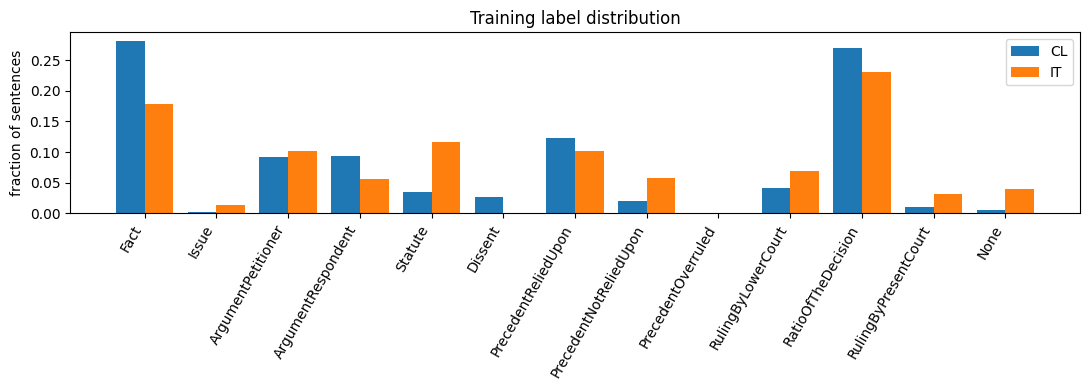

In [13]:
def hf(fn): return hf_hub_download(HF_REPO, fn, repo_type="dataset", token=HF_TOKEN)

lv = json.load(open(hf(f"{P3}/Train/label_vocab.json"), encoding="utf-8"))
if isinstance(lv, dict):
    if "labels" in lv and isinstance(lv["labels"], list): LABELS = lv["labels"]
    elif all(isinstance(v, int) for v in lv.values()):   LABELS = [k for k, _ in sorted(lv.items(), key=lambda kv: kv[1])]
    else: LABELS = list(lv.keys())
else: LABELS = list(lv)
LABELS = [str(x) for x in LABELS]; L2I = {l: i for i, l in enumerate(LABELS)}; NL = len(LABELS)
print(NL, "labels:", LABELS)

# def load_docs(path, domain, labelled=True):
#     raw = json.load(open(path, encoding="utf-8"))
#     items = raw.items() if isinstance(raw, dict) else [(str(d.get("id", i)), d) for i, d in enumerate(raw)]
#     docs = []
#     for k, d in items:
#         s = d["text"]; s = s.split("\n") if isinstance(s, str) else list(s)
#         y = None
#         if labelled and "labels" in d:
#             y = [L2I[str(l)] for l in d["labels"]]; assert len(y) == len(s), (k, len(y), len(s))
#         docs.append(dict(id=str(k), sents=[str(x) for x in s], y=y, domain=domain))
#     return docs

def load_docs(path, domain, labelled=True):
    with open(path, encoding="utf-8") as f:
        raw = json.load(f)

    items = raw.items() if isinstance(raw, dict) else [
        (str(d.get("id", i) if isinstance(d, dict) else i), d)
        for i, d in enumerate(raw)
    ]
    docs = []

    for k, d in items:
        if isinstance(d, dict):
            text_val = next(
                (d[key] for key in ("text", "content", "body", "judgment", "document")
                 if key in d and d[key] is not None),
                ""
            )
            y_raw = d.get("labels") if labelled else None
        else:
            text_val = d
            y_raw = None

        # Preserve an existing list of sentence strings.
        if isinstance(text_val, list):
            s_list = [clean_text(s) for s in text_val]
            s_list = [s for s in s_list if s]
        elif isinstance(text_val, str):
            s = clean_text(text_val)
            s_list = [x.strip() for x in s.split("\n") if x.strip()]
        else:
            raise TypeError(
                f"Unexpected text type for domain={domain}, doc_id={k}: "
                f"{type(text_val).__name__}"
            )

        y = None
        if y_raw is not None:
            if not isinstance(y_raw, list):
                raise TypeError(
                    f"Labels must be a list: domain={domain}, doc_id={k}"
                )
            if len(y_raw) != len(s_list):
                raise ValueError(
                    f"Alignment error: domain={domain}, doc_id={k}, "
                    f"text_type={type(text_val).__name__}, "
                    f"sentences={len(s_list)}, labels={len(y_raw)}"
                )
            unknown = sorted(set(map(str, y_raw)) - set(L2I))
            if unknown:
                raise ValueError(f"Unknown labels in {k}: {unknown}")
            y = [L2I[str(label)] for label in y_raw]

        docs.append(dict(
            id=str(k), sents=s_list, y=y, domain=domain
        ))

    return docs


DATA = {}
for dom in ("CL", "IT"):
    DATA[(dom, "train")] = load_docs(hf(f"{P3}/Train/{dom}_train.json"), dom)
    DATA[(dom, "dev")]   = load_docs(hf(f"{P3}/Train/{dom}_dev.json"), dom)
    DATA[(dom, "test")] = load_docs(hf(f"{P3}/Test/{dom}_test.json"), dom, labelled=False)
    # except Exception as e: print("test file not available for", dom, e); DATA[(dom, "test")] = []
if TRAIN_DOC_LIMIT:
    for dom in ("CL", "IT"): DATA[(dom, "train")] = DATA[(dom, "train")][:TRAIN_DOC_LIMIT]; DATA[(dom, "dev")] = DATA[(dom, "dev")][:max(5, TRAIN_DOC_LIMIT // 3)]

MAX_SENT_TOK = 160
def tokenize_docs(docs):
    for d in tqdm(docs, leave=False):
        d["ids"] = [tokenizer.encode(clean_text(s))[:MAX_SENT_TOK] + [tokenizer.eos_id] for s in d["sents"]]
for k, v in DATA.items(): tokenize_docs(v)

rows = []
for (dom, sp), docs in DATA.items():
    ns = sum(len(d["sents"]) for d in docs); nt = sum(sum(map(len, d["ids"])) for d in docs)
    rows.append(dict(domain=dom, split=sp, docs=len(docs), sents=ns, tokens=nt, tok_per_doc=nt / max(1, len(docs))))
print(pd.DataFrame(rows))
ids_all = [d["id"] for dom in ("CL", "IT") for d in DATA[(dom, "test")]]
print("duplicate test ids across domains:", len(ids_all) - len(set(ids_all)))

# label distribution plot
fig, ax = plt.subplots(figsize=(11, 4)); w = 0.4
for j, dom in enumerate(("CL", "IT")):
    c = Counter(l for d in DATA[(dom, "train")] for l in d["y"]); tot = sum(c.values())
    ax.bar(np.arange(NL) + (j - .5) * w, [c[i] / tot for i in range(NL)], w, label=dom)
ax.set_xticks(range(NL)); ax.set_xticklabels(LABELS, rotation=60, ha="right"); ax.set_ylabel("fraction of sentences"); ax.legend()
ax.set_title("Training label distribution"); plt.tight_layout(); plt.savefig(f"{WORK}/eda_labels.png", dpi=150); plt.show()

In [14]:
# Each chunk = [BOS] + sentences (context-only ones first, then targets). Decoder is causal, so a sentence's
# representation (its </s> token + mean pool) sees all earlier sentences inside the chunk.
CTX = {
    "sentence":   dict(max_len=192,  ctx_prev=0, max_tgt=1,   bs=64, accum=1, head="none"),
    "window3":    dict(max_len=512,  ctx_prev=3, max_tgt=1,   bs=24, accum=2, head="none"),
    "doc":        dict(max_len=1024, ctx_prev=6, max_tgt=999, bs=4,  accum=4, head="none"),
    "doc_bigru":  dict(max_len=1024, ctx_prev=6, max_tgt=999, bs=4,  accum=4, head="bigru"),
}

def make_chunks(docs, ctxc, eff_len, train=False, rng=None):
    out, budget = [], eff_len - 1
    for di, d in enumerate(docs):
        S, n, i, first = d["ids"], len(d["ids"]), 0, True
        while i < n:
            tb = budget * (rng.uniform(0.3, 1.0) if (train and first and ctxc["max_tgt"] > 1) else 1.0)
            j, used = i, 0
            while j < n and (j - i) < ctxc["max_tgt"] and (j == i or used + len(S[j]) <= tb):
                used += len(S[j]); j += 1
            c = i
            while c > 0 and (i - c) < ctxc["ctx_prev"] and used + len(S[c - 1]) <= budget:
                c -= 1; used += len(S[c])
            out.append((di, c, i, j)); i = j; first = False
    return out

def make_item(doc, c, i, j):
    ids, st, en = [tokenizer.bos_id], [], []
    for k in range(c, j):
        st.append(len(ids)); ids += doc["ids"][k]; en.append(len(ids))
    tm = [k >= i for k in range(c, j)]
    lab = [(doc["y"][k] if (doc["y"] is not None and k >= i) else -100) for k in range(c, j)]
    return dict(ids=ids, st=st, en=en, tm=tm, lab=lab, sidx=list(range(c, j)))

def collate(items, dis):
    B, T, S = len(items), max(len(x["ids"]) for x in items), max(len(x["st"]) for x in items)
    ids = torch.full((B, T), tokenizer.pad_id, dtype=torch.long)
    st = torch.zeros(B, S, dtype=torch.long); en = torch.ones(B, S, dtype=torch.long)
    sm = torch.zeros(B, S, dtype=torch.bool); tm = torch.zeros(B, S, dtype=torch.bool); lab = torch.full((B, S), -100, dtype=torch.long)
    for b, x in enumerate(items):
        n, s = len(x["ids"]), len(x["st"])
        ids[b, :n] = torch.tensor(x["ids"]); st[b, :s] = torch.tensor(x["st"]); en[b, :s] = torch.tensor(x["en"])
        sm[b, :s] = True; tm[b, :s] = torch.tensor(x["tm"]); lab[b, :s] = torch.tensor(x["lab"])
    return dict(ids=ids, st=st, en=en, sm=sm, tm=tm, y=lab, doc=dis, sidx=[x["sidx"] for x in items], tml=[x["tm"] for x in items])

def batches(docs, chunks, bs, shuffle=False, rng=None):
    idx = list(range(len(chunks)))
    if shuffle: rng.shuffle(idx)
    for s in range(0, len(idx), bs):
        sel = [chunks[k] for k in idx[s:s + bs]]
        yield collate([make_item(docs[a], c, i, j) for a, c, i, j in sel], [a for a, *_ in sel])

def to_dev(b): return {k: (v.to(DEVICE, non_blocking=True) if torch.is_tensor(v) else v) for k, v in b.items()}

In [15]:
# ---------------- backbone wrapper (replace this class for other Phase-1 architectures) ----------------
# class LMBackbone(nn.Module):
#     def __init__(self, lm):
#         super().__init__(); self.wte, self.blocks, self.ln_f = lm.wte, lm.blocks, lm.ln_f; self.dim = lm.cfg["dim"]
#     def hidden(self, x, gc=False):
#         for b in self.blocks:
#             x = ckpt_util.checkpoint(b.train_fwd, x, use_reentrant=False) if (gc and self.training) else b(x)[0]
#         return self.ln_f(x)
# ---------------- backbone wrapper ----------------
class LMBackbone(nn.Module):
    def __init__(self, lm):
        super().__init__()
        self.wte, self.blocks, self.ln_f = lm.wte, lm.blocks, lm.ln_f
        # Safely get the embedding dimension from wte instead of lm.cfg
        self.dim = lm.wte.embedding_dim  

    def hidden(self, x, gc=False):
        for b in self.blocks:
            x = ckpt_util.checkpoint(b, x, use_reentrant=False) if (gc and self.training) else b(x)[0]
        return self.ln_f(x)

def load_phase1(layers_keep=None, random_init=False):
    ck = torch.load(PHASE1_CKPT, map_location="cpu", weights_only=False)
    cfg = dict(ck["config"])
    sd = {k.replace("_orig_mod.", ""): v for k, v in ck["model"].items()}
    
    if layers_keep is None:
        lm = LegalLM(vocab_size=cfg.get("vocab_size", 24000), 
                     dim=cfg.get("dim", 768), 
                     layers=cfg.get("layers", 8), 
                     heads=cfg.get("heads", 12), 
                     block_size=cfg.get("block_size", 1024))
        if not random_init: 
            lm.load_state_dict(sd)
    else:
        lm = LegalLM(vocab_size=cfg.get("vocab_size", 24000), 
                     dim=cfg.get("dim", 768), 
                     layers=len(layers_keep), 
                     heads=cfg.get("heads", 12), 
                     block_size=cfg.get("block_size", 1024))
        new = {}
        for k, v in sd.items():
            m = re.match(r"blocks\.(\d+)\.(.*)", k)
            if m is None: 
                new[k] = v
            elif int(m[1]) in layers_keep: 
                new[f"blocks.{layers_keep.index(int(m[1]))}.{m[2]}"] = v
        lm.load_state_dict(new, strict=True)
    return lm

# ---------------- classifier on top of backbone ----------------
class RRModel(nn.Module):
    def __init__(self, bb, n_labels, head="bigru", pool="last_mean", n_prompt=0, drop=0.1):
        super().__init__()
        self.bb, self.pool, D = bb, pool, bb.dim
        pdim = 2 * D if pool == "last_mean" else D
        self.proj = nn.Sequential(nn.LayerNorm(pdim), nn.Dropout(drop), nn.Linear(pdim, D), nn.GELU())
        self.ctx = nn.GRU(D, D // 2, batch_first=True, bidirectional=True) if head == "bigru" else None
        self.cls = nn.Sequential(nn.Dropout(drop), nn.Linear(D, n_labels))
        self.n_prompt = n_prompt
        if n_prompt:
            self.prompt = nn.Parameter(bb.wte.weight[torch.randint(0, bb.wte.weight.size(0), (n_prompt,))].detach().clone())
        self.ada = None; self.gc = False

    def forward(self, ids, st, en, sm):
        emb = self.bb.wte(ids); off = 0
        if self.n_prompt:
            emb = torch.cat([self.prompt.unsqueeze(0).expand(ids.size(0), -1, -1).to(emb.dtype), emb], 1); off = self.n_prompt
        h = self.bb.hidden(emb, self.gc).float()
        B, T, D = h.shape
        cs = F.pad(h.cumsum(1), (0, 0, 1, 0))
        s, e = st + off, en + off
        last = h.gather(1, (e - 1).unsqueeze(-1).expand(-1, -1, D))
        if self.pool == "last": rep = last
        else:
            mean = (cs.gather(1, e.unsqueeze(-1).expand(-1, -1, D)) - cs.gather(1, s.unsqueeze(-1).expand(-1, -1, D))) / (e - s).clamp(min=1).unsqueeze(-1)
            rep = torch.cat([last, mean], -1)
        z = self.proj(rep)
        if self.ctx is not None:
            S = z.size(1)
            pk = nn.utils.rnn.pack_padded_sequence(z.float(), sm.sum(1).cpu(), batch_first=True, enforce_sorted=False)
            o, _ = self.ctx(pk); o, _ = nn.utils.rnn.pad_packed_sequence(o, batch_first=True, total_length=S)
            z = z + o.to(z.dtype)
        return self.cls(z), z

# ---------------- adapters ----------------
class LoRALinear(nn.Module):                      # LoRA / rsLoRA (scale = a/r  vs  a/sqrt(r))
    def __init__(self, base, r=16, alpha=32, dropout=0.05, rs=False):
        super().__init__(); self.base = base
        self.A = nn.Parameter(torch.empty(r, base.in_features)); self.B = nn.Parameter(torch.zeros(base.out_features, r))
        nn.init.kaiming_uniform_(self.A, a=math.sqrt(5)); self.scale = alpha / (math.sqrt(r) if rs else r); self.drop = nn.Dropout(dropout)
    def forward(self, x): return self.base(x) + F.linear(F.linear(self.drop(x), self.A), self.B) * self.scale

class LoRMALinear(nn.Module):                     # multiplicative: W' = (I + B A) W   ->  y = h + B A h, h = W x
    def __init__(self, base, r=16, alpha=16):
        super().__init__(); self.base = base
        self.A = nn.Parameter(torch.empty(r, base.out_features)); self.B = nn.Parameter(torch.zeros(base.out_features, r))
        nn.init.kaiming_uniform_(self.A, a=math.sqrt(5)); self.scale = alpha / r
    def forward(self, x):
        h = self.base(x); return h + F.linear(F.linear(h, self.A), self.B) * self.scale

NF4 = torch.tensor([-1.0, -0.6961928009986877, -0.5250730514526367, -0.39491748809814453, -0.28444138169288635, -0.18477343022823334,
                    -0.09105003625154495, 0.0, 0.07958029955625534, 0.16093020141029358, 0.24611230194568634, 0.33791524171829224,
                    0.44070982933044434, 0.5626170039176941, 0.7229568362236023, 1.0])
class QLoRALinear(nn.Module):                     # frozen NF4 (4-bit, blockwise absmax, packed 2/byte) + LoRA
    def __init__(self, base, r=16, alpha=32, dropout=0.05, bs=64):
        super().__init__(); w = base.weight.data.float().to(DEVICE); self.shape, self.n, self.bs = w.shape, w.numel(), bs
        f = F.pad(w.flatten(), (0, (-w.numel()) % bs)).view(-1, bs); am = f.abs().amax(1, keepdim=True).clamp(min=1e-8); nrm = f / am
        idx = torch.empty(nrm.shape, dtype=torch.uint8, device=w.device); tab = NF4.to(w.device)
        for s in range(0, nrm.size(0), 8192): idx[s:s + 8192] = (nrm[s:s + 8192, :, None] - tab).abs().argmin(-1).to(torch.uint8)
        fl = idx.flatten(); self.register_buffer("packed", ((fl[0::2] << 4) | fl[1::2]).cpu()); self.register_buffer("absmax", am.half().cpu())
        self.in_features, self.out_features = base.in_features, base.out_features
        self.A = nn.Parameter(torch.empty(r, base.in_features)); self.B = nn.Parameter(torch.zeros(base.out_features, r))
        nn.init.kaiming_uniform_(self.A, a=math.sqrt(5)); self.scale = alpha / r; self.drop = nn.Dropout(dropout)
    def deq(self, dtype):
        p = self.packed; i = torch.stack([p >> 4, p & 15], -1).flatten().long()
        w = NF4.to(p.device)[i].view(-1, self.bs) * self.absmax.float(); return w.flatten()[:self.n].view(self.shape).to(dtype)
    def forward(self, x): return F.linear(x, self.deq(x.dtype)) + F.linear(F.linear(self.drop(x), self.A), self.B) * self.scale

class AdaLoRALinear(nn.Module):                   # dW = B diag(E) A, SVD-style, rank pruned by AdaLoRAManager
    def __init__(self, base, r=12, alpha=24, dropout=0.05):
        super().__init__(); self.base = base
        self.A = nn.Parameter(torch.randn(r, base.in_features) * 0.02); self.B = nn.Parameter(torch.randn(base.out_features, r) * 0.02)
        self.E = nn.Parameter(torch.zeros(r)); self.register_buffer("mask", torch.ones(r)); self.scale = alpha / r; self.drop = nn.Dropout(dropout)
    def forward(self, x):
        return self.base(x) + F.linear(F.linear(self.drop(x), self.A) * (self.E * self.mask).to(x.dtype), self.B) * self.scale
    def orth(self):
        I = torch.eye(self.E.numel(), device=self.A.device)
        return ((self.A @ self.A.t() - I) ** 2).sum() + ((self.B.t() @ self.B - I) ** 2).sum()

class AdaLoRAManager:
    def __init__(self, model, total_steps, target_rank=4, beta=0.85, ti=0.1, tf=0.2, dt=10):
        self.mods = [m for m in model.modules() if isinstance(m, AdaLoRALinear)]
        self.T, self.beta, self.ti, self.tf, self.dt = total_steps, beta, ti, tf, dt
        self.b0 = sum(m.E.numel() for m in self.mods); self.bT = target_rank * len(self.mods); self.I, self.U = {}, {}
    def budget(self, t):
        ti, tf = int(self.ti * self.T), int(self.tf * self.T)
        if t < ti: return self.b0
        if t >= self.T - tf: return self.bT
        return int(self.bT + (self.b0 - self.bT) * (1 - (t - ti) / max(1, self.T - tf - ti)) ** 3)
    def orth_loss(self): return sum(m.orth() for m in self.mods)
    @torch.no_grad()
    def update(self, t):
        for k, m in enumerate(self.mods):
            if m.E.grad is None or m.A.grad is None: return
            s = (m.E * m.E.grad).abs() + (m.A * m.A.grad).abs().mean(1) + (m.B * m.B.grad).abs().mean(0)
            if k not in self.I: self.I[k], self.U[k] = s.clone(), torch.zeros_like(s)
            else:
                self.I[k] = self.beta * self.I[k] + (1 - self.beta) * s
                self.U[k] = self.beta * self.U[k] + (1 - self.beta) * (s - self.I[k]).abs()
        if t % self.dt == 0 and len(self.I) == len(self.mods):
            sc = torch.cat([self.I[k] * self.U[k] for k in range(len(self.mods))]); keep = self.budget(t)
            mk = torch.zeros_like(sc); mk[sc.topk(min(keep, sc.numel())).indices] = 1; o = 0
            for m in self.mods:
                r = m.E.numel(); m.mask.copy_(mk[o:o + r]); m.E.mul_(m.mask); o += r
    def active_rank(self): return float(sum(m.mask.sum().item() for m in self.mods) / len(self.mods))

class IA3Linear(nn.Module):                       # learned rescaling vector on output (k,v) or input (FFN hidden)
    def __init__(self, base, where):
        super().__init__(); self.base, self.where = base, where
        self.s = nn.Parameter(torch.ones(base.out_features if where == "out" else base.in_features))
    def forward(self, x): return self.base(x * self.s.to(x.dtype)) if self.where == "in" else self.base(x) * self.s.to(x.dtype)

class PrefixAttn(nn.Module):                      # learned per-layer key/value prefix (shared across heads of a KV group)
    def __init__(self, attn, P):
        super().__init__(); self.attn = attn
        self.pk = nn.Parameter(torch.randn(attn.hk, P, attn.hd)); self.pv = nn.Parameter(torch.randn(attn.hk, P, attn.hd) * 0.1)
    def forward(self, x, mask=None, cache=None, start=0):
        a = self.attn; b, t, _ = x.shape; r = a.h // a.hk
        q = a.q(x).view(b, t, a.h, a.hd).transpose(1, 2)
        k, v = a.kv(x).view(b, t, 2, a.hk, a.hd).permute(2, 0, 3, 1, 4)
        q, k = a.rope(a.qn(q), start), a.rope(a.kn(k), start)
        P = self.pk.size(1)
        k = torch.cat([self.pk.unsqueeze(0).expand(b, -1, -1, -1).to(k.dtype), k], 2)
        v = torch.cat([self.pv.unsqueeze(0).expand(b, -1, -1, -1).to(v.dtype), v], 2)
        k, v = k.repeat_interleave(r, 1), v.repeat_interleave(r, 1)
        m = torch.ones(t, P + t, dtype=torch.bool, device=x.device).tril(diagonal=P)   # prefix visible to all, causal on tokens
        y = F.scaled_dot_product_attention(q, k, v, attn_mask=m)
        return a.o(y.transpose(1, 2).reshape(b, t, a.h * a.hd)), cache

TARGETS = ("qkv", "proj", "w13", "w2")
def replace_linears(root, suffixes, factory):
    for name, mod in list(root.named_modules()):
        for cn, ch in list(mod.named_children()):
            full = f"{name}.{cn}" if name else cn
            if isinstance(ch, nn.Linear) and any(full.endswith(s) for s in suffixes): setattr(mod, cn, factory(full, ch))

def apply_method(model, cfg):
    m, bb = cfg["method"], model.bb
    if m != "full":
        for p in bb.parameters(): p.requires_grad = False
    if m in ("lora", "rslora"):
        replace_linears(bb, TARGETS, lambda n, l: LoRALinear(l, cfg["r"], cfg["alpha"], 0.05, rs=(m == "rslora")))
    elif m == "qlora":  replace_linears(bb, TARGETS, lambda n, l: QLoRALinear(l, cfg["r"], cfg["alpha"]))
    elif m == "adalora": replace_linears(bb, TARGETS, lambda n, l: AdaLoRALinear(l, cfg["r"], cfg["alpha"]))
    elif m == "lorma":  replace_linears(bb, TARGETS, lambda n, l: LoRMALinear(l, cfg["r"], cfg["alpha"]))
    elif m == "ia3":
        replace_linears(bb, ("attn.kv",), lambda n, l: IA3Linear(l, "out")); replace_linears(bb, ("ffn.w2",), lambda n, l: IA3Linear(l, "in"))
    elif m == "prefix":
        for blk in bb.blocks: blk.attn = PrefixAttn(blk.attn, cfg["n_prefix"])
    elif m not in ("full", "linear_probe", "prompt"): raise ValueError(m)

def build_model(cfg):
    lm = load_phase1(cfg.get("layers_keep"), cfg.get("random_init", False)); bb = LMBackbone(lm)
    npr = cfg.get("n_prompt", 0) if cfg["method"] == "prompt" else 0
    model = RRModel(bb, NL, head=CTX[cfg["ctx"]]["head"], pool=cfg.get("pool", "last_mean"), n_prompt=npr)
    if cfg["method"] == "prompt":
        for p in bb.parameters(): p.requires_grad = False
    apply_method(model, cfg); model.gc = cfg.get("grad_ckpt", False)
    return model.to(DEVICE)

def model_stats(model):
    tr = sum(p.numel() for p in model.parameters() if p.requires_grad); tot = sum(p.numel() for p in model.parameters())
    mb = (sum(p.numel() * p.element_size() for p in model.parameters()) + sum(b.numel() * b.element_size() for b in model.buffers())) / 2**20
    return tr, tot, mb

In [16]:
RESULTS_PATH, PRED_PATH = f"{WORK}/results.json", f"{WORK}/dev_preds.pkl"
RESULTS = json.load(open(RESULTS_PATH)) if os.path.exists(RESULTS_PATH) else {}
PRED = pickle.load(open(PRED_PATH, "rb")) if os.path.exists(PRED_PATH) else {}
def save_all():
    json.dump(RESULTS, open(RESULTS_PATH, "w"), default=lambda o: o.item() if hasattr(o, "item") else str(o))
    pickle.dump(PRED, open(PRED_PATH, "wb"))

def class_weights(docs):
    c = np.bincount([l for d in docs for l in d["y"]], minlength=NL).astype(np.float64) + 1
    w = (c.sum() / (NL * c)) ** 0.5; return torch.tensor(w / w.mean(), dtype=torch.float32, device=DEVICE)

def rr_loss(logits, y, kind, w):
    m = y != -100; lg, yy = logits[m].float(), y[m]
    if kind == "focal":
        lp = F.log_softmax(lg, -1).gather(1, yy[:, None])[:, 0]; pt = lp.exp()
        return (-(1 - pt) ** 2 * lp * (w[yy] if w is not None else 1.0)).mean()
    return F.cross_entropy(lg, yy, weight=w if kind in ("wce", "focal") else None, label_smoothing=0.0)

def metrics(y, p):
    return dict(f1=f1_score(y, p, average="macro", zero_division=0), P=precision_score(y, p, average="macro", zero_division=0),
                R=recall_score(y, p, average="macro", zero_division=0), acc=accuracy_score(y, p),
                f1_all=f1_score(y, p, average="macro", labels=list(range(NL)), zero_division=0))

@torch.no_grad()
def predict(model, docs, ctxc, eff_len):
    model.eval(); chunks = make_chunks(docs, ctxc, eff_len)
    chunks.sort(key=lambda ch: sum(len(x) for x in docs[ch[0]]["ids"][ch[1]:ch[3]]))
    Lg = [np.zeros((len(d["sents"]), NL), np.float32) for d in docs]
    for b in batches(docs, chunks, ctxc["bs"] * 2):
        bd = to_dev(b)
        with torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=USE_AMP):
            lg, _ = model(bd["ids"], bd["st"], bd["en"], bd["sm"])
        lg = lg.float().cpu().numpy()
        for r, (di, sidx, tml) in enumerate(zip(b["doc"], b["sidx"], b["tml"])):
            for q, (k, t) in enumerate(zip(sidx, tml)):
                if t: Lg[di][k] = lg[r, q]
    return [l.argmax(1) for l in Lg], Lg

def eval_domains(model, dev_sets, ctxc, eff_len, doms):
    out = {}
    for dom in doms:
        P, _ = predict(model, dev_sets[dom], ctxc, eff_len)
        out[dom] = metrics(np.concatenate([d["y"] for d in dev_sets[dom]]), np.concatenate(P))
    return out

def load_teacher(tname):
    tc = RESULTS[tname]["cfg"]; t = build_model(tc); t.load_state_dict(torch.load(f"{CK}/{tname}.pt", map_location=DEVICE)); t.eval()
    for p in t.parameters(): p.requires_grad = False
    return t

def train_run(cfg):
    name = cfg["name"]
    if name in RESULTS: print("skip (done):", name); return RESULTS[name]
    print(f"\n=== {name} | {cfg['method']} | ctx={cfg['ctx']} | train={cfg['train_domains']} | loss={cfg['loss']} ===")
    set_seed(cfg.get("seed", SEED)); rng = random.Random(cfg.get("seed", SEED))
    ctxc = CTX[cfg["ctx"]]; eff_len = ctxc["max_len"] - (cfg.get("n_prompt", 0) if cfg["method"] == "prompt" else 0)
    train_docs = [d for dom in cfg["train_domains"] for d in DATA[(dom, "train")]]
    dev_sets = {dom: DATA[(dom, "dev")] for dom in ("CL", "IT")}
    model = build_model(cfg); tr, tot, mb = model_stats(model)
    print(f"params trainable {tr/1e6:.2f}M / total {tot/1e6:.1f}M | size {mb:.0f} MB")
    w = class_weights(train_docs) if cfg["loss"] in ("wce", "focal") else None
    teacher = load_teacher(cfg["kd"]["teacher"]) if cfg.get("kd") else None

    groups = {"bb": [], "head": []}
    for n, p in model.named_parameters():
        if p.requires_grad: groups["bb" if n.startswith("bb.") or n == "prompt" else "head"].append(p)
    opt = torch.optim.AdamW([dict(params=groups["bb"], lr=cfg["lr"], base=cfg["lr"]),
                             dict(params=groups["head"], lr=cfg["head_lr"], base=cfg["head_lr"])], weight_decay=0.01, betas=(0.9, 0.98))
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP and AMP_DTYPE == torch.float16)
    n_chunks = len(make_chunks(train_docs, ctxc, eff_len)); spe = max(1, math.ceil(n_chunks / (ctxc["bs"] * ctxc["accum"])))
    total = cfg["epochs"] * spe; warm = max(1, int(0.06 * total))
    if cfg["method"] == "adalora": model.ada = AdaLoRAManager(model, total, cfg.get("target_rank", 4))
    track = {n for n, p in model.named_parameters() if p.requires_grad} | {n for n, _ in model.named_buffers() if n.endswith(".mask")}
    sel_doms = cfg["train_domains"]; best, best_state, bad, hist, step, t0 = -1, None, 0, [], 0, time.time()
    # 2. Setup resume variables
    start_ep = 0
    best = -1
    best_state = None
    bad = 0
    hist = []
    step = 0
    # Resume from checkpoint if it exists
    ckpt_file = f"{CK}/{name}_ckpt.pt"
    if os.path.exists(ckpt_file):
        print(f"Resuming checkpoint from {ckpt_file}")
        checkpoint = torch.load(ckpt_file, map_location=DEVICE)
        model.load_state_dict(checkpoint["model_state"], strict=False)
        opt.load_state_dict(checkpoint["optimizer_state"])
        if "scaler_state" in checkpoint and checkpoint["scaler_state"] is not None:
            scaler.load_state_dict(checkpoint["scaler_state"])
        start_ep = checkpoint["epoch"] + 1
        best = checkpoint["best"]
        best_state = checkpoint["best_state"]
        bad = checkpoint["bad"]
        hist = checkpoint["hist"]
        step = checkpoint["step"]
    for ep in range(start_ep, cfg["epochs"]):
        model.train(); chunks = make_chunks(train_docs, ctxc, eff_len, train=True, rng=rng); run_loss, nb = 0.0, 0
        opt.zero_grad(set_to_none=True)
        pbar = tqdm(batches(train_docs, chunks, ctxc["bs"], True, rng), total=math.ceil(len(chunks) / ctxc["bs"]), desc=f"ep{ep+1}", leave=False)
        for mi, b in enumerate(pbar):
            bd = to_dev(b)
            with torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=USE_AMP):
                lg, z = model(bd["ids"], bd["st"], bd["en"], bd["sm"])
                loss = rr_loss(lg, bd["y"], cfg["loss"], w)
                if teacher is not None:
                    with torch.no_grad(): tl, tz = teacher(bd["ids"], bd["st"], bd["en"], bd["sm"])
                    m = bd["y"] != -100; T = cfg["kd"]["T"]
                    kd = F.kl_div(F.log_softmax(lg[m].float() / T, -1), F.softmax(tl[m].float() / T, -1), reduction="batchmean") * T * T
                    loss = cfg["kd"]["alpha"] * loss + (1 - cfg["kd"]["alpha"]) * kd
                    if cfg["kd"].get("beta", 0) > 0: loss = loss + cfg["kd"]["beta"] * (1 - F.cosine_similarity(z[m].float(), tz[m].float(), dim=-1)).mean()
                if model.ada is not None: loss = loss + 0.1 * model.ada.orth_loss()
            scaler.scale(loss / ctxc["accum"]).backward(); run_loss += loss.item(); nb += 1
            if (mi + 1) % ctxc["accum"] == 0:
                lr_f = (step + 1) / warm if step < warm else 0.5 * (1 + math.cos(math.pi * (step - warm) / max(1, total - warm)))
                for g in opt.param_groups: g["lr"] = g["base"] * max(lr_f, 0.02)
                scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_([p for g in groups.values() for p in g], 1.0)
                if model.ada is not None: model.ada.update(step)
                scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True); step += 1
            if (time.time() - t0) / 60 > MAX_MIN_PER_RUN: break
        dm = eval_domains(model, dev_sets, ctxc, eff_len, sel_doms); score = float(np.mean([dm[d]["f1"] for d in sel_doms]))
        hist.append(dict(epoch=ep + 1, loss=run_loss / max(1, nb), **{f"f1_{d}": dm[d]["f1"] for d in sel_doms}, score=score))
        print(f"ep{ep+1} loss {run_loss/max(1,nb):.4f} | dev macro-F1 " + " ".join(f"{d}:{dm[d]['f1']:.4f}" for d in sel_doms) + f" | {(time.time()-t0)/60:.1f} min")
        if score > best: best, bad, best_state = score, 0, {k: v.detach().cpu().clone() for k, v in model.state_dict().items() if k in track}
        else:
            bad += 1
            if bad >= cfg.get("patience", 3): break
        # 3. Save lightweight epoch checkpoint to keep storage footprint minimal
        torch.save({
            "epoch": ep,
            "step": step,
            "best": best,
            "bad": bad,
            "hist": hist,
            "model_state": {k: v.cpu() for k, v in model.state_dict().items() if k in track},
            "optimizer_state": opt.state_dict(),
            "scaler_state": scaler.state_dict() if USE_AMP else None,
            "best_state": best_state
        }, ckpt_file)
        if (time.time() - t0) / 60 > MAX_MIN_PER_RUN: print("time cap reached"); break
    train_min = (time.time() - t0) / 60
    model.load_state_dict(best_state, strict=False)
    if cfg.get("save_ckpt"): torch.save({k: v.cpu() for k, v in model.state_dict().items()}, f"{CK}/{name}.pt")

    # final evaluation on both dev domains (+ timing), test prediction
    res = dict(name=name, group=cfg["group"], cfg=cfg, trainable=tr, total=tot, size_mb=mb, train_min=train_min, hist=hist, dev={}, perclass={}, conf={})
    PRED[name] = {}; t1 = time.time(); nsent = 0
    for dom in ("CL", "IT"):
        P, Lg = predict(model, dev_sets[dom], ctxc, eff_len); y, p = np.concatenate([d["y"] for d in dev_sets[dom]]), np.concatenate(P); nsent += len(y)
        res["dev"][dom] = metrics(y, p); res["perclass"][dom] = f1_score(y, p, average=None, labels=list(range(NL)), zero_division=0).tolist()
        res["conf"][dom] = confusion_matrix(y, p, labels=list(range(NL))).tolist(); PRED[name][dom] = dict(y=y, p=p, logits=np.concatenate(Lg))
    res["infer_s_per_1k"] = (time.time() - t1) / nsent * 1000
    res["f1_CL"], res["f1_IT"] = res["dev"]["CL"]["f1"], res["dev"]["IT"]["f1"]; res["f1_mean"] = (res["f1_CL"] + res["f1_IT"]) / 2
    if model.ada is not None: res["active_rank"] = model.ada.active_rank()
    for dom in ("CL", "IT"):
        td = DATA[(dom, "test")]
        if td:
            P, _ = predict(model, td, ctxc, eff_len)
            json.dump({d["id"]: [LABELS[i] for i in p] for d, p in zip(td, P)}, open(f"{PRED_DIR}/{name}_{dom}.json", "w"))
    RESULTS[name] = res; save_all()
    print(f"-> {name}: CL {res['f1_CL']:.4f} | IT {res['f1_IT']:.4f} | mean {res['f1_mean']:.4f} | {train_min:.1f} min | {res['infer_s_per_1k']:.2f}s/1k sents")
    del model, opt, teacher; gc.collect(); torch.cuda.empty_cache()
    return res

In [17]:
BASE = dict(ctx="doc_bigru", loss="wce", train_domains=["CL", "IT"], epochs=8, patience=3, head_lr=1e-3, lr=5e-4, seed=SEED)
METHOD_HP = {
    "linear_probe": dict(head_lr=2e-3),
    "full":    dict(lr=1e-4, epochs=6),
    "lora":    dict(r=16, alpha=32, lr=5e-4),
    "rslora":  dict(r=64, alpha=16, lr=5e-4),            # scale alpha/sqrt(r)
    "qlora":   dict(r=16, alpha=32, lr=5e-4),
    "adalora": dict(r=12, alpha=24, target_rank=4, lr=1e-3),
    "lorma":   dict(r=16, alpha=16, lr=5e-4),
    "ia3":     dict(lr=3e-3),
    "prefix":  dict(n_prefix=32, lr=5e-3),
    "prompt":  dict(n_prompt=32, lr=3e-3),
}
def C(name, group, method="lora", **kw):
    c = dict(BASE); c.update(METHOD_HP.get(method, {})); c.update(name=name, group=group, method=method); c.update(kw); return c
def best_of(prefix, key="f1_mean"):
    c = {k: v for k, v in RESULTS.items() if k.startswith(prefix)}; return max(c, key=lambda k: c[k][key]) if c else None

# ---- Group 1: how much context helps (LoRA fixed) ----
# for ctx in ["sentence", "window3", "doc", "doc_bigru"]: train_run(C(f"ctx_{ctx}", "context", "lora", ctx=ctx, epochs=4))
for ctx in ["doc_bigru"]: train_run(C(f"ctx_{ctx}", "context", "lora", ctx=ctx, epochs=4))
BEST_CTX = RESULTS[best_of("ctx_")]["cfg"]["ctx"]; print("\nBEST CONTEXT MODE:", BEST_CTX)

# ---- Group 2: fine-tuning / PEFT techniques (all with BEST_CTX) ----
for m in ["full","rslora", "lorma"]:
    train_run(C(f"m_{m}", "method", m, ctx=BEST_CTX, save_ckpt=(m == "full"), epochs=4))

skip (done): ctx_doc_bigru

BEST CONTEXT MODE: doc_bigru
skip (done): m_full
skip (done): m_rslora
skip (done): m_lorma


In [18]:
# ---- Group 3: class-balancing (LoRA, BEST_CTX; 'wce' already = m_lora) ----
# for lo in ["ce", "focal"]: train_run(C(f"loss_{lo}", "loss", "lora", ctx=BEST_CTX, loss=lo))
for lo in ["focal"]: train_run(C(f"loss_{lo}", "loss", "lora", ctx=BEST_CTX, loss=lo))
# ---- Group 4: domain study (train on one domain, evaluate on both) ----
# for dom in ["CL", "IT"]: train_run(C(f"dom_{dom}", "domain", "lora", ctx=BEST_CTX, train_domains=[dom]))
# ---- Group 5: value of Phase-1 pre-training (random init, same arch) ----
# train_run(C("p1_random_full", "phase1", "full", ctx=BEST_CTX, random_init=True))
# train_run(C("p1_random_lora", "phase1", "lora", ctx=BEST_CTX, random_init=True))

skip (done): loss_focal


In [19]:
# ---- Group 6: knowledge distillation ----
# Teacher = full FT of the 8-layer Phase-1 model (m_full). Student = 4 layers initialised from Phase-1 layers {0,2,5,7}.
STUDENT = dict(layers_keep=[0, 2, 5, 7], lr=2e-4, epochs=2)
# train_run(C("kd_student_ce", "kd", "full", ctx=BEST_CTX, **STUDENT))                                   # no-KD baseline
train_run(C("kd_student_logits", "kd", "full", ctx=BEST_CTX, kd=dict(teacher="m_full", T=2.0, alpha=0.3, beta=0.0), **STUDENT))
# train_run(C("kd_student_logits_rep", "kd", "full", ctx=BEST_CTX, kd=dict(teacher="m_full", T=2.0, alpha=0.3, beta=0.5), **STUDENT))

skip (done): kd_student_logits


{'name': 'kd_student_logits',
 'group': 'kd',
 'cfg': {'ctx': 'doc_bigru',
  'loss': 'wce',
  'train_domains': ['CL', 'IT'],
  'epochs': 2,
  'patience': 3,
  'head_lr': 0.001,
  'lr': 0.0002,
  'seed': 42,
  'name': 'kd_student_logits',
  'group': 'kd',
  'method': 'full',
  'kd': {'teacher': 'm_full', 'T': 2.0, 'alpha': 0.3, 'beta': 0.0},
  'layers_keep': [0, 2, 5, 7]},
 'trainable': 50602765,
 'total': 50602765,
 'size_mb': 194.03422927856445,
 'train_min': 4.952348474661509,
 'hist': [{'epoch': 1,
   'loss': 2.486971520885979,
   'f1_CL': 0.2605810872935684,
   'f1_IT': 0.27870862465378876,
   'score': 0.2696448559736786},
  {'epoch': 2,
   'loss': 1.3670768629281949,
   'f1_CL': 0.3381032185944492,
   'f1_IT': 0.3348929332755551,
   'score': 0.33649807593500214}],
 'dev': {'CL': {'f1': 0.3381032185944492,
   'P': 0.394790959361455,
   'R': 0.37533376383062567,
   'acc': 0.4484240687679083,
   'f1_all': 0.2600793989188071},
  'IT': {'f1': 0.3348929332755551,
   'P': 0.3702823397780

             name   group method       ctx  loss train  trainable_M  total_M  size_MB  train_min  infer_s_per_1k  F1_CL  F1_IT  F1_mean  P_mean  R_mean
    ctx_doc_bigru context   lora doc_bigru   wce CL,IT       5.4252  80.4933 309.0577    10.2389          3.7156 0.3675 0.5050   0.4362  0.4727  0.4423
kd_student_logits      kd   full doc_bigru   wce CL,IT      50.6028  50.6028 194.0342     4.9523          1.7192 0.3381 0.3349   0.3365  0.3825  0.3538
       loss_focal    loss   lora doc_bigru focal CL,IT       5.4252  80.4933 309.0577    20.4549          3.7317 0.4211 0.4791   0.4501  0.4833  0.4668
         m_rslora  method rslora doc_bigru   wce CL,IT      10.1438  85.2119 327.0577    10.4648          3.8247 0.4213 0.5025   0.4619  0.5056  0.4649
           m_full  method   full doc_bigru   wce CL,IT      78.9205  78.9205 303.0577    11.3703          3.4285 0.4020 0.5052   0.4536  0.4754  0.4630
          m_lorma  method  lorma doc_bigru   wce CL,IT       5.8839  80.9521 310.8077   

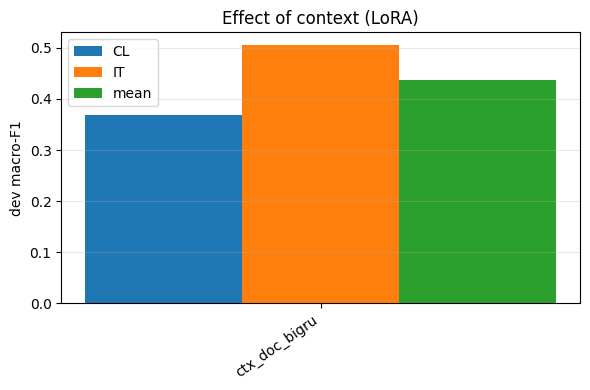

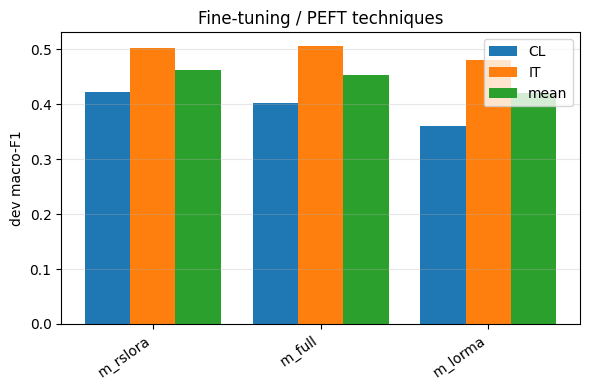

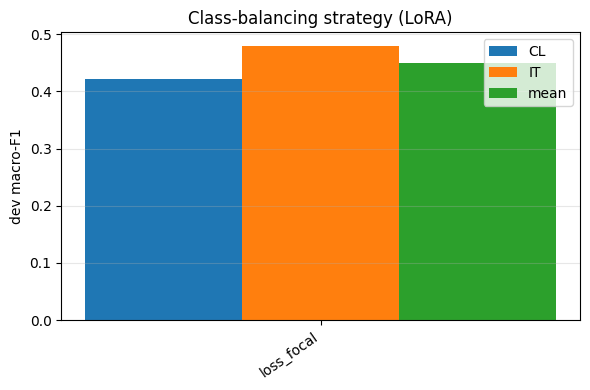

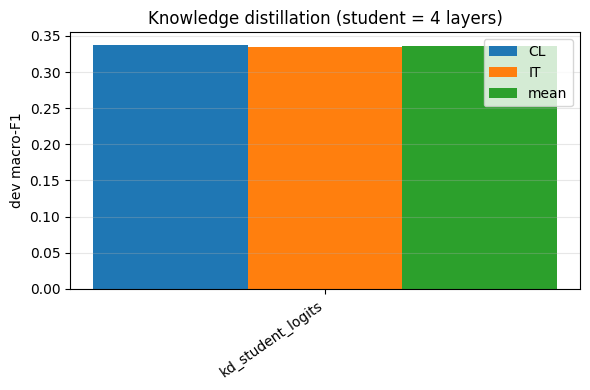

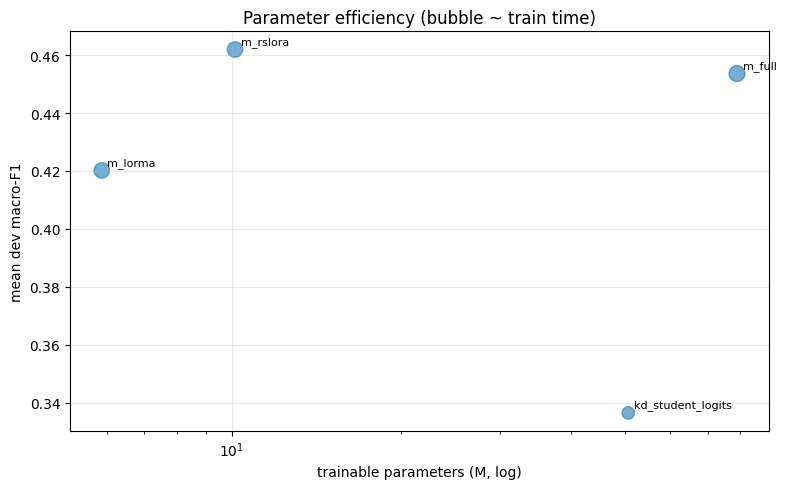

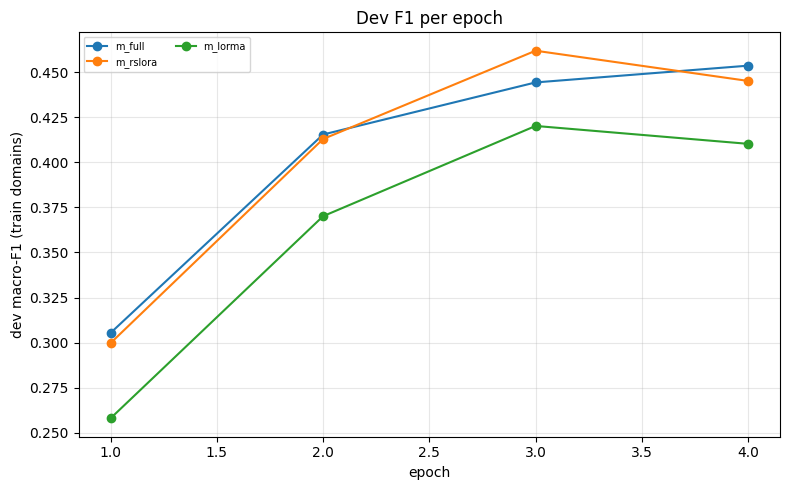

             name  total_M  size_MB  infer_s_per_1k  F1_CL  F1_IT  F1_mean
           m_full  78.9205 303.0577          3.4285 0.4020 0.5052   0.4536
kd_student_logits  50.6028 194.0342          1.7192 0.3381 0.3349   0.3365


In [20]:
def results_df():
    rows = []
    for n, r in RESULTS.items():
        c = r["cfg"]; rows.append(dict(name=n, group=r["group"], method=c["method"], ctx=c["ctx"], loss=c["loss"], train=",".join(c["train_domains"]),
            trainable_M=r["trainable"] / 1e6, total_M=r["total"] / 1e6, size_MB=r["size_mb"], train_min=r["train_min"], infer_s_per_1k=r["infer_s_per_1k"],
            F1_CL=r["f1_CL"], F1_IT=r["f1_IT"], F1_mean=r["f1_mean"],
            P_mean=(r["dev"]["CL"]["P"] + r["dev"]["IT"]["P"]) / 2, R_mean=(r["dev"]["CL"]["R"] + r["dev"]["IT"]["R"]) / 2))
    return pd.DataFrame(rows)
df = results_df(); pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)
print(df.sort_values(["group", "F1_mean"], ascending=[True, False]).round(4).to_string(index=False))
df.to_csv(f"{WORK}/summary.csv", index=False)

def bar_group(g, key="name", title=None, fn=None):
    d = df[df.group == g].sort_values("F1_mean", ascending=False)
    if g == "method" and "ctx_" + BEST_CTX in RESULTS: pass
    x = np.arange(len(d)); fig, ax = plt.subplots(figsize=(max(6, 1.0 * len(d) + 2), 4))
    ax.bar(x - .27, d.F1_CL, .27, label="CL"); ax.bar(x, d.F1_IT, .27, label="IT"); ax.bar(x + .27, d.F1_mean, .27, label="mean")
    ax.set_xticks(x); ax.set_xticklabels(d[key], rotation=35, ha="right"); ax.set_ylabel("dev macro-F1"); ax.set_title(title or g); ax.legend(); ax.grid(axis="y", alpha=.3)
    plt.tight_layout(); plt.savefig(f"{WORK}/{fn or g}.png", dpi=150); plt.show()

for g, t in [("context", "Effect of context (LoRA)"), ("method", "Fine-tuning / PEFT techniques"), ("loss", "Class-balancing strategy (LoRA)"),
             ("phase1", "Phase-1 pretrained vs random init"), ("kd", "Knowledge distillation (student = 4 layers)")]:
    if (df.group == g).any(): bar_group(g, title=t)

# efficiency: trainable params vs F1 (bubble = train minutes)
d = df[df.group.isin(["method", "kd"])]
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(d.trainable_M, d.F1_mean, s=40 + 8 * d.train_min, alpha=.6)
for _, r in d.iterrows(): ax.annotate(r["name"], (r.trainable_M, r.F1_mean), fontsize=8, xytext=(4, 4), textcoords="offset points")
ax.set_xscale("log"); ax.set_xlabel("trainable parameters (M, log)"); ax.set_ylabel("mean dev macro-F1"); ax.set_title("Parameter efficiency (bubble ~ train time)"); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(f"{WORK}/efficiency.png", dpi=150); plt.show()

# training curves
fig, ax = plt.subplots(figsize=(8, 5))
for n, r in RESULTS.items():
    if r["group"] == "method": ax.plot([h["epoch"] for h in r["hist"]], [h["score"] for h in r["hist"]], marker="o", label=n)
ax.set_xlabel("epoch"); ax.set_ylabel("dev macro-F1 (train domains)"); ax.legend(fontsize=7, ncol=2); ax.grid(alpha=.3); ax.set_title("Dev F1 per epoch")
plt.tight_layout(); plt.savefig(f"{WORK}/curves.png", dpi=150); plt.show()

# domain transfer matrix (rows = trained on, cols = evaluated on)
dm = {"CL-only": "dom_CL", "IT-only": "dom_IT", "joint": "m_lora"}
if all(v in RESULTS for v in dm.values()):
    M = np.array([[RESULTS[v]["f1_CL"], RESULTS[v]["f1_IT"]] for v in dm.values()])
    fig, ax = plt.subplots(figsize=(4.5, 3.5)); im = ax.imshow(M, cmap="viridis")
    ax.set_xticks([0, 1]); ax.set_xticklabels(["eval CL", "eval IT"]); ax.set_yticks(range(3)); ax.set_yticklabels(dm.keys())
    for i in range(3):
        for j in range(2): ax.text(j, i, f"{M[i,j]:.3f}", ha="center", va="center", color="w")
    ax.set_title("Domain transfer (macro-F1)"); plt.tight_layout(); plt.savefig(f"{WORK}/domain_matrix.png", dpi=150); plt.show()

# KD summary: size / latency / F1
k = df[df.name.isin(["m_full", "kd_student_ce", "kd_student_logits", "kd_student_logits_rep"])]
print(k[["name", "total_M", "size_MB", "infer_s_per_1k", "F1_CL", "F1_IT", "F1_mean"]].round(4).to_string(index=False))

best experiment: m_rslora


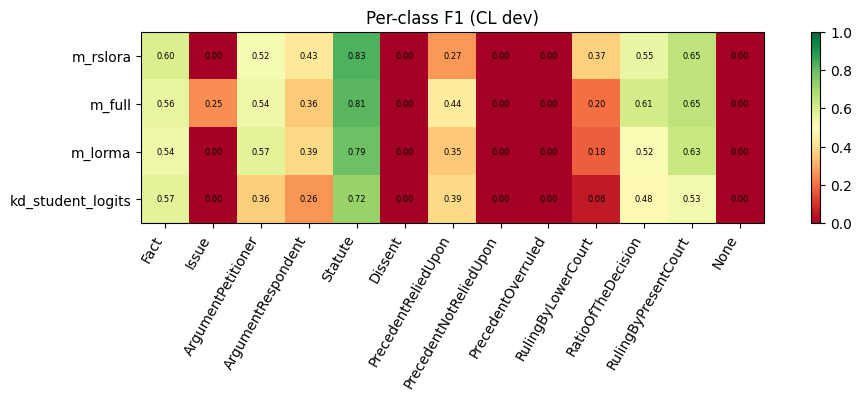

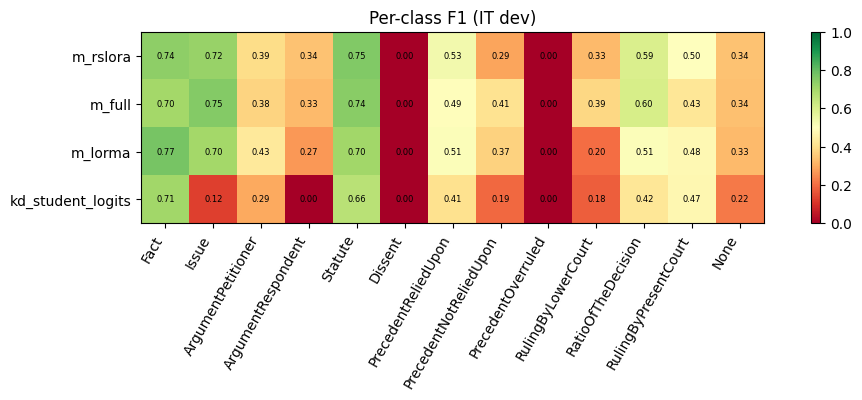

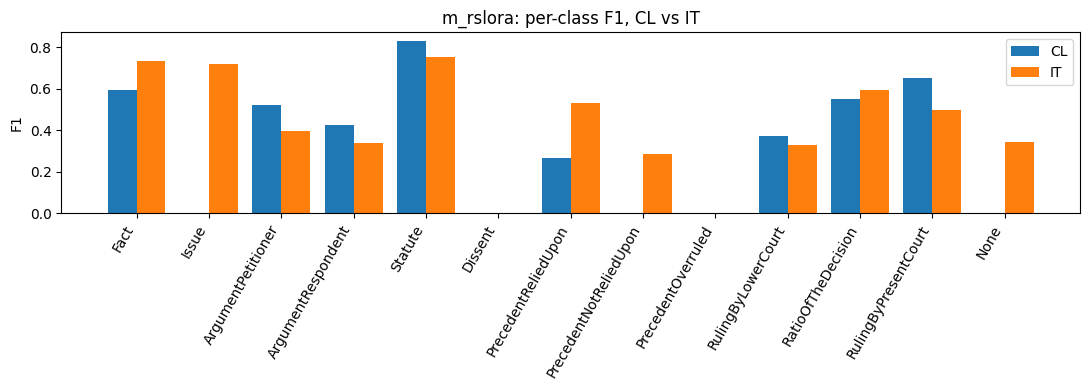

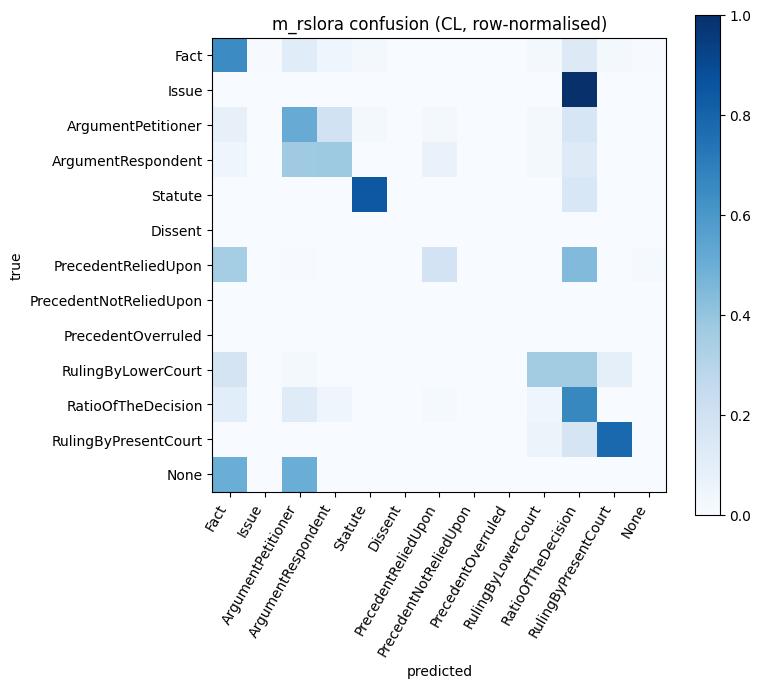


Top confusions [CL] (true -> pred):
               true               pred  count  row_frac
 ArgumentRespondent ArgumentPetitioner     87     0.369
 ArgumentPetitioner ArgumentRespondent     65     0.189
PrecedentReliedUpon RatioOfTheDecision     63     0.444
 ArgumentPetitioner RatioOfTheDecision     55     0.160
PrecedentReliedUpon               Fact     50     0.352
 RatioOfTheDecision ArgumentPetitioner     34     0.118
               Fact RatioOfTheDecision     32     0.129
 RatioOfTheDecision               Fact     31     0.108
               Fact ArgumentPetitioner     29     0.116
 ArgumentRespondent RatioOfTheDecision     29     0.123


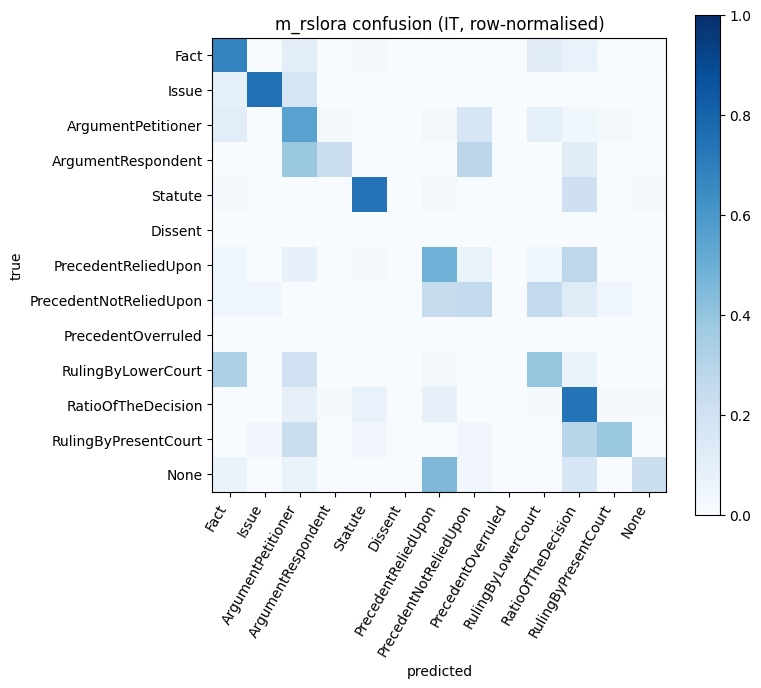


Top confusions [IT] (true -> pred):
                  true                pred  count  row_frac
   PrecedentReliedUpon  RatioOfTheDecision     31     0.277
                  Fact  RulingByLowerCourt     22     0.113
                  Fact  ArgumentPetitioner     19     0.097
    RulingByLowerCourt                Fact     15     0.326
    ArgumentRespondent  ArgumentPetitioner     14     0.389
                  None PrecedentReliedUpon     14     0.452
                  Fact  RatioOfTheDecision     13     0.067
               Statute  RatioOfTheDecision     13     0.210
PrecedentNotReliedUpon  RulingByLowerCourt     13     0.260
PrecedentNotReliedUpon PrecedentReliedUpon     12     0.240

[CL] within-group confusion share (errors that stay inside the related group):
  Precedent*         errors from these classes:   116 | of which stay in-group: 0.00%
  Arguments          errors from these classes:   317 | of which stay in-group: 47.95%
  Reasoning/Ruling   errors from these classes:   

In [21]:
def best_name(groups=("method", "kd", "loss", "domain", "context")):
    d = df[df.group.isin(groups)]; return d.loc[d.F1_mean.idxmax(), "name"]
BEST = best_name(); print("best experiment:", BEST)

# per-class F1 heatmap, one per domain, across method-group experiments
for dom in ("CL", "IT"):
    names = [n for n in df[df.group.isin(["method", "kd"])].sort_values("F1_mean", ascending=False).name]
    M = np.array([RESULTS[n]["perclass"][dom] for n in names])
    fig, ax = plt.subplots(figsize=(11, 0.4 * len(names) + 2)); im = ax.imshow(M, vmin=0, vmax=1, cmap="RdYlGn")
    ax.set_xticks(range(NL)); ax.set_xticklabels(LABELS, rotation=60, ha="right"); ax.set_yticks(range(len(names))); ax.set_yticklabels(names)
    for i in range(M.shape[0]):
        for j in range(NL): ax.text(j, i, f"{M[i,j]:.2f}", ha="center", va="center", fontsize=6)
    ax.set_title(f"Per-class F1 ({dom} dev)"); plt.colorbar(im); plt.tight_layout(); plt.savefig(f"{WORK}/perclass_{dom}.png", dpi=150); plt.show()

# CL vs IT per-class for the best model
fig, ax = plt.subplots(figsize=(11, 4)); w = .4
for j, dom in enumerate(("CL", "IT")): ax.bar(np.arange(NL) + (j - .5) * w, RESULTS[BEST]["perclass"][dom], w, label=dom)
ax.set_xticks(range(NL)); ax.set_xticklabels(LABELS, rotation=60, ha="right"); ax.set_ylabel("F1"); ax.legend(); ax.set_title(f"{BEST}: per-class F1, CL vs IT")
plt.tight_layout(); plt.savefig(f"{WORK}/best_perclass_cl_it.png", dpi=150); plt.show()

# normalised confusion matrices + top confused pairs
for dom in ("CL", "IT"):
    C_ = np.array(RESULTS[BEST]["conf"][dom], float); Cn = C_ / np.maximum(C_.sum(1, keepdims=True), 1)
    fig, ax = plt.subplots(figsize=(8, 7)); im = ax.imshow(Cn, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(NL)); ax.set_xticklabels(LABELS, rotation=60, ha="right"); ax.set_yticks(range(NL)); ax.set_yticklabels(LABELS)
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(f"{BEST} confusion ({dom}, row-normalised)"); plt.colorbar(im)
    plt.tight_layout(); plt.savefig(f"{WORK}/confusion_{dom}.png", dpi=150); plt.show()
    off = [(LABELS[i], LABELS[j], int(C_[i, j]), Cn[i, j]) for i in range(NL) for j in range(NL) if i != j and C_[i, j] > 0]
    print(f"\nTop confusions [{dom}] (true -> pred):")
    print(pd.DataFrame(sorted(off, key=lambda t: -t[2])[:10], columns=["true", "pred", "count", "row_frac"]).round(3).to_string(index=False))

# related-role groups: accuracy inside the group vs leakage within the group
GROUPS = {"Precedent*": ["PrecedentReliedUpon", "PrecedentNotReliedUpon", "PrecedentOverruled"],
          "Arguments": ["ArgumentPetitioner", "ArgumentRespondent"],
          "Reasoning/Ruling": ["RatioOfTheDecision", "RulingByPresentCourt", "RulingByLowerCourt"]}
for dom in ("CL", "IT"):
    C_ = np.array(RESULTS[BEST]["conf"][dom]); print(f"\n[{dom}] within-group confusion share (errors that stay inside the related group):")
    for g, ls in GROUPS.items():
        ix = [L2I[l] for l in ls if l in L2I]
        if len(ix) < 2: continue
        err = C_[ix].sum() - np.trace(C_[np.ix_(ix, ix)]); inside = C_[np.ix_(ix, ix)].sum() - np.trace(C_[np.ix_(ix, ix)])
        print(f"  {g:18s} errors from these classes: {int(err):5d} | of which stay in-group: {inside/max(err,1):.2%}")

In [22]:
# Pick the 4 best experiments with different techniques; make sure the KD student is included. Override SUBMIT manually if you like.
cand = df[df.group.isin(["method", "kd"])].sort_values("F1_mean", ascending=False)
SUBMIT, seen = [], set()
# kd_best = cand[cand.group == "kd"].name.tolist()[:1]
# for _, r in cand.iterrows():
#     tech = "kd" if r.group == "kd" else r.method
#     if tech in seen or r.method == "linear_probe": continue
#     seen.add(tech); SUBMIT.append(r["name"])
#     if len(SUBMIT) == 4: break
# if kd_best and kd_best[0] not in SUBMIT: SUBMIT[-1] = kd_best[0]
SUBMIT = list(RESULTS.keys())
print("all submissions:", SUBMIT)

for n in SUBMIT:
    out, ok = {}, True
    for dom in ("CL", "IT"):
        f = f"{PRED_DIR}/{n}_{dom}.json"
        if not os.path.exists(f): print("missing test preds for", n, dom); ok = False; continue
        p = json.load(open(f))
        for d in DATA[(dom, "test")]:
            assert len(p[d["id"]]) == len(d["sents"]) and all(l in L2I for l in p[d["id"]]), d["id"]
        out.update(p)
    if not ok: continue
    sub_dir = f"{WORK}/submission_{n}"; os.makedirs(sub_dir, exist_ok=True)
    json.dump(out, open(f"{sub_dir}/prediction.json", "w"), ensure_ascii=False, indent=1)
    with zipfile.ZipFile(f"{sub_dir}/submission.zip", "w", zipfile.ZIP_DEFLATED) as z: z.write(f"{sub_dir}/prediction.json", arcname="prediction.json")
    print("wrote", sub_dir, "|", len(out), "docs")

all submissions: ['ctx_doc_bigru', 'm_full', 'm_rslora', 'm_lorma', 'loss_focal', 'kd_student_logits']
wrote /kaggle/working/phase3-custom-mha/submission_ctx_doc_bigru | 10 docs
wrote /kaggle/working/phase3-custom-mha/submission_m_full | 10 docs
wrote /kaggle/working/phase3-custom-mha/submission_m_rslora | 10 docs
wrote /kaggle/working/phase3-custom-mha/submission_m_lorma | 10 docs
wrote /kaggle/working/phase3-custom-mha/submission_loss_focal | 10 docs
wrote /kaggle/working/phase3-custom-mha/submission_kd_student_logits | 10 docs


---
## Architecture: `mla_moe`

Source: `cs781-legal-lm-v3-mla-moe.ipynb`


In [23]:
# ── Activate backbone: mla_moe ──────────────────────────────────────────────
BACKBONE = "mla_moe"
TOKENIZER_PATH = TOK_PATHS["mla_moe"]
PHASE1_CKPT = CKPTS["mla_moe"]
MODEL_PATH = PHASE1_CKPT
CKPT_PATH = PHASE1_CKPT
if "OUT_DIR" not in dir() or not OUT_DIR:
    OUT_DIR = "/kaggle/working/cs781_phase1" if os.path.isdir("/kaggle/working") else "./cs781_phase1"
DATA_DIR = os.path.join(OUT_DIR, "data")
os.makedirs(DATA_DIR, exist_ok=True)
print(f"[active] BACKBONE={BACKBONE}")
print(f"[active] TOKENIZER_PATH={TOKENIZER_PATH}  exists={os.path.exists(TOKENIZER_PATH)}")
print(f"[active] PHASE1_CKPT={PHASE1_CKPT}  exists={os.path.exists(PHASE1_CKPT)}")




[active] BACKBONE=mla_moe
[active] TOKENIZER_PATH=/kaggle/working/cs781_phase1/legal_bpe_mla_moe.json  exists=True
[active] PHASE1_CKPT=/kaggle/working/cs781_phase1/latest_checkpoint_mla_moe_1k.pt  exists=True


### Phase-1 classes for `mla_moe` (tokenizer + model, needed to reload checkpoints)

These cells are taken from Phase 1 of the same source notebook. They define `BPETokenizer`,
the model stack (`LegalLM` / `DualPathLM` / …), and `load_model`. Internal bodies are unchanged.


## 1. Text cleaning + byte-level BPE tokenizer

In [24]:
_QUOTES = str.maketrans({"“": '"', "”": '"', "„": '"', "‘": "'", "’": "'", "‚": "'", "`": "'", "´": "'",
                         "–": "-", "—": "-", "−": "-", "\u00ad": ""})
_CTRL = re.compile(r"[\x00-\x08\x0b\x0c\x0e-\x1f\x7f-\x9f]")
_WS = re.compile(r"[ \t\u00a0\u1680\u2000-\u200b\u202f\u205f\u3000\ufeff]+")
_DOTS = re.compile(r"\.{4,}|(?:\. ){4,}")
_RULE = re.compile(r"[_\-=*~#]{3,}")
_PAGE = re.compile(r"(?mi)^[ \t]*(?:page\s+)?\d{1,4}[ \t]*$\n?")
_HYPH = re.compile(r"(?<=[a-z])-\n(?=[a-z])")
_WRAP = re.compile(r"(?<=[a-z,;])\n(?=[a-z(])")

def clean_text(t):
    """Light, conservative normalisation of legal text (used for training data AND test prompts)."""
    t = unicodedata.normalize("NFKC", str(t)).replace("\r\n", "\n").replace("\r", "\n")
    t = t.translate(_QUOTES)
    t = _CTRL.sub(" ", t)
    t = _HYPH.sub("", t)                 # de-hyphenate line-wrapped words
    t = _DOTS.sub("...", t)              # ".........." table-of-contents leaders
    t = _RULE.sub(" ", t)                # ------ / ====== separators
    t = _PAGE.sub("", t)                 # lines that are only a page number
    t = _WS.sub(" ", t)
    t = re.sub(r" *\n *", "\n", t)
    t = _WRAP.sub(" ", t)                # join hard-wrapped lines inside a sentence
    t = re.sub(r"\n{3,}", "\n\n", t)
    return t.strip()

def keep_doc(c):
    """Quality filter for cleaned documents."""
    if len(c) < 600: return False
    head = c[:5000]
    if sum(ch.isalpha() for ch in head) / len(head) < 0.6: return False
    if sum(ord(ch) > 127 for ch in head) / len(head) > 0.2: return False   # mostly non-English OCR/Indic
    w = c.split()
    if len(w) < 100: return False
    w = w[:3000]
    return len(set(w)) / len(w) >= 0.15                                       # drop repetitive junk

def extract_text(rec):
    if isinstance(rec, str): return rec
    if isinstance(rec, dict):
        for k in ("text", "train_text", "content", "body", "judgment", "document"):
            v = rec.get(k)
            if isinstance(v, str) and v.strip(): return v
        for v in rec.values():
            if isinstance(v, (dict, list)):
                s = extract_text(v)
                if s: return s
    if isinstance(rec, list):
        return "\n".join(filter(None, map(extract_text, rec)))
    return ""

def iter_docs(path):
    """Constant-memory iteration over a huge JSON file ({id: record} or [record, ...])."""
    with open(path, "rb") as f:
        head = f.read(256).lstrip(b"\xef\xbb\xbf \n\r\t")[:1]
        f.seek(0)
        it = (v for _, v in ijson.kvitems(f, "")) if head == b"{" else ijson.items(f, "item")
        for rec in it:
            t = extract_text(rec)
            if t: yield t


class BPETokenizer:
    SPECIALS = ["<pad>", "<unk>", "<s>", "</s>"]
    # GPT-2 style: a leading space stays attached to the word, so "the" / " the" are one token each
    _split = re.compile(r" ?[^\W\d_]+| ?\d+| ?[^\s\w]+| ?_+|\s+(?!\S)|\s+")

    def __init__(self, vocab_size=12000):
        self.vocab_size = vocab_size
        self.merges = []
        self._reset()

    def _reset(self):
        self.itos = list(self.SPECIALS) + [bytes([i]) for i in range(256)]
        self._cache = {}

    def _build(self):
        self.itos = list(self.SPECIALS) + [bytes([i]) for i in range(256)]
        seen = set(self.itos[4:])
        for a, b in self.merges:
            m = a + b
            if m not in seen:
                seen.add(m); self.itos.append(m)
        self.stoi = {t: i for i, t in enumerate(self.itos)}
        self.ranks = {pair: r for r, pair in enumerate(self.merges)}
        self.merged = {pair: pair[0] + pair[1] for pair in self.merges}
        self._cache = {}
        self.pad_id, self.unk_id, self.bos_id, self.eos_id = 0, 1, 2, 3
        self.vocab_size = len(self.itos)

    def train(self, texts, max_unique_words=200_000, min_freq=2):
        counts = Counter()
        for t in tqdm(texts, desc="counting pre-tokens"):
            counts.update(self._split.findall(t))
        if len(counts) > max_unique_words:
            counts = Counter(dict(counts.most_common(max_unique_words)))
        words, freqs = [], []
        pair_counts, pair_words = defaultdict(int), defaultdict(set)
        for wid, (w, c) in enumerate(counts.items()):
            toks = [bytes([b]) for b in w.encode("utf-8")]
            words.append(toks); freqs.append(c)
            for p in zip(toks, toks[1:]):
                pair_counts[p] += c; pair_words[p].add(wid)
        heap = [(-c, p) for p, c in pair_counts.items()]
        heapq.heapify(heap)
        self.merges = []
        n_target = self.vocab_size - (4 + 256)
        seen = set(bytes([i]) for i in range(256))
        pbar = tqdm(total=n_target, desc="BPE merges")
        while len(self.merges) < n_target and heap:
            best = None
            while heap:                                  # lazy-deletion max-heap
                negc, p = heapq.heappop(heap)
                cur = pair_counts.get(p, 0)
                if cur <= 0: continue
                if cur != -negc:
                    heapq.heappush(heap, (-cur, p)); continue
                best = p; break
            if best is None or pair_counts[best] < min_freq: break
            a, b = best; merged = a + b
            self.merges.append(best); seen.add(merged)
            for wid in list(pair_words.pop(best, ())):
                w, f = words[wid], freqs[wid]
                new, i = [], 0
                while i < len(w):
                    if i < len(w) - 1 and w[i] == a and w[i + 1] == b:
                        new.append(merged); i += 2
                    else:
                        new.append(w[i]); i += 1
                if len(new) == len(w): continue
                for p in zip(w, w[1:]): pair_counts[p] -= f
                for p in zip(new, new[1:]):
                    pair_counts[p] += f; pair_words[p].add(wid)
                    heapq.heappush(heap, (-pair_counts[p], p))
                words[wid] = new
            pbar.update(1)
        pbar.close()
        self._build()
        return self

    def _word(self, w):
        r = self._cache.get(w)
        if r is not None: return r
        toks = [bytes([b]) for b in w.encode("utf-8")]
        while len(toks) > 1:
            best_i, best_r = -1, 1 << 60
            for i in range(len(toks) - 1):
                r_ = self.ranks.get((toks[i], toks[i + 1]), 1 << 60)
                if r_ < best_r: best_i, best_r = i, r_
            if best_i < 0: break
            toks[best_i:best_i + 2] = [toks[best_i] + toks[best_i + 1]]
        r = [self.stoi[t] for t in toks]
        if len(self._cache) > 500_000: self._cache.clear()
        self._cache[w] = r
        return r

    def encode(self, text, add_bos=False, add_eos=False):
        ids = [self.bos_id] if add_bos else []
        for ch in self._split.findall(text): ids.extend(self._word(ch))
        if add_eos: ids.append(self.eos_id)
        return ids

    def decode(self, ids):
        return b"".join(self.itos[i] for i in ids if 4 <= i < len(self.itos)).decode("utf-8", errors="replace")

    def save(self, path):
        with open(path, "w") as f:
            json.dump({"vocab_size": self.vocab_size, "merges": [[a.hex(), b.hex()] for a, b in self.merges]}, f)

    @classmethod
    def load(cls, path):
        d = json.load(open(path))
        t = cls(d["vocab_size"]); t.merges = [(bytes.fromhex(a), bytes.fromhex(b)) for a, b in d["merges"]]
        t._build(); return t
    @classmethod
    def load_any(cls, path):
        """Load from either the original JSON format or a pickle dump.

        Why this exists
        ---------------
        Phase-1 models were trained with different BPE tables.  Some exports
        are the original JSON (list of hex merges); others are full pickle
        dumps of the tokenizer object or of a dict containing "merges".
        This helper accepts both so you can drop .pkl files straight into
        DATASET_DIR without converting them first.
        """
        path = str(path)
        if path.endswith((".pkl", ".pickle")):
            import pickle
            with open(path, "rb") as f:
                obj = pickle.load(f)
            if isinstance(obj, cls):
                return obj
            if isinstance(obj, dict):
                tok = cls()
                if "merges" in obj:
                    merges = obj["merges"]
                    # hex-encoded (from .json export) or raw bytes
                    if merges and isinstance(merges[0][0], str):
                        tok.merges = [(bytes.fromhex(a), bytes.fromhex(b)) for a, b in merges]
                    else:
                        tok.merges = [(bytes(a), bytes(b)) for a, b in merges]
                    tok._build()
                    return tok
                # full state-dict style
                for k, v in obj.items():
                    setattr(tok, k, v)
                if not getattr(tok, "stoi", None):
                    tok._build()
                return tok
            raise TypeError(f"Unrecognised pickle content in {path}: {type(obj)}")
        # original JSON path
        return cls.load(path)

assert os.path.exists(TOKENIZER_PATH), f"Tokenizer not found at {TOKENIZER_PATH}"
tokenizer = BPETokenizer.load_any(TOKENIZER_PATH)
print(f"Tokenizer loaded | vocab_size = {tokenizer.vocab_size} | from {TOKENIZER_PATH}")

# Pre-load every available tokenizer so Phase 4 can switch per experiment.
# Specials (pad/unk/bos/eos = 0/1/2/3) are identical across files; only merges/vocab differ.
TOKENIZERS = {}
for _name, _path in TOK_PATHS.items():
    if os.path.exists(_path):
        TOKENIZERS[_name] = BPETokenizer.load_any(_path)
        print(f"  tok[{_name}]: vocab={TOKENIZERS[_name].vocab_size}  <- {_path}")
    else:
        print(f"  tok[{_name}]: MISSING {_path}")
# keep global `tokenizer` pointing at the BACKBONE selected in the config cell
tokenizer = TOKENIZERS.get(BACKBONE, tokenizer)
print(f"Active tokenizer for BACKBONE={BACKBONE}: vocab={tokenizer.vocab_size}")

Tokenizer loaded | vocab_size = 30000 | from /kaggle/working/cs781_phase1/legal_bpe_mla_moe.json
  tok[custom_mha]: vocab=24000  <- /kaggle/working/cs781_phase1/legal_bpe_custom_mha.json
  tok[mla_moe]: vocab=30000  <- /kaggle/working/cs781_phase1/legal_bpe_mla_moe.json
  tok[gqa_conv]: vocab=30000  <- /kaggle/working/cs781_phase1/legal_bpe_gqa_conv.json
  tok[gqa_alibi]: vocab=32000  <- /kaggle/working/cs781_phase1/legal_bpe_tokenizer_gqa_alibi.pkl
Active tokenizer for BACKBONE=mla_moe: vocab=30000


## 4. Model: MLA attention (with weight absorption at inference) + DeepSeekMoE feed-forward
* **MLA**: keys/values are compressed into a small latent `c_kv` (+ a tiny decoupled RoPE key). Training uses the
  expanded form; inference uses the *absorbed* form: `W_UK` is folded into the query and `W_UV` into the output,
  so attention runs directly on the cached latent (cache = d_c + d_rope numbers per token instead of 2*heads*head_dim).
* **MoE**: 1 shared expert + routed experts (top-k). Experts are split into one group per data source; during training the
  router gets a small supervised "domain" loss so each group specialises (Acts / Supreme Court / High Courts / Tribunals).
  At inference there are no labels - the router infers the domain from the prompt text.

In [25]:
class RMSNorm(nn.Module):
    def __init__(self, d, eps=1e-6):
        super().__init__(); self.w = nn.Parameter(torch.ones(d)); self.eps = eps
    def forward(self, x):
        xf = x.float()
        return (xf * torch.rsqrt(xf.pow(2).mean(-1, keepdim=True) + self.eps) * self.w).type_as(x)

class RoPE(nn.Module):
    def __init__(self, hd, max_len, base=10000.0):
        super().__init__()
        inv = 1.0 / (base ** (torch.arange(0, hd, 2).float() / hd))
        fr = torch.outer(torch.arange(max_len).float(), inv)
        self.register_buffer("cos", fr.cos(), persistent=False)
        self.register_buffer("sin", fr.sin(), persistent=False)
    def forward(self, x, start=0):                      # x: (b, heads, t, hd)
        t = x.size(2)
        cos, sin = self.cos[start:start + t].to(x.dtype), self.sin[start:start + t].to(x.dtype)
        x1, x2 = x.chunk(2, dim=-1)
        return torch.cat((x1 * cos - x2 * sin, x2 * cos + x1 * sin), dim=-1)


class MLA(nn.Module):
    """Multi-head Latent Attention (DeepSeek-V2/V3) with decoupled RoPE and weight absorption for inference."""
    def __init__(self, c):
        super().__init__()
        dim, H = c["dim"], c["heads"]
        self.h, self.dc, self.dn, self.dr, self.dv = H, c["d_c"], c["d_nope"], c["d_rope"], c["d_v"]
        self.dq = nn.Linear(dim, c["d_cq"], bias=False);  self.q_norm = RMSNorm(c["d_cq"])
        self.uq = nn.Linear(c["d_cq"], H * (self.dn + self.dr), bias=False)           # -> [q_nope | q_rope] per head
        self.dkv = nn.Linear(dim, self.dc + self.dr, bias=False); self.kv_norm = RMSNorm(self.dc)   # -> [c_kv | k_rope]
        self.uk = nn.Linear(self.dc, H * self.dn, bias=False)                          # W_UK
        self.uv = nn.Linear(self.dc, H * self.dv, bias=False)                          # W_UV
        self.o = nn.Linear(H * self.dv, dim, bias=False)
        self.rope = RoPE(self.dr, c["block_size"])
        self.scale = 1.0 / math.sqrt(self.dn + self.dr)

    def forward(self, x, mask=None, cache=None, start=0):
        b, t, _ = x.shape
        q = self.uq(self.q_norm(self.dq(x))).reshape(b, t, self.h, self.dn + self.dr).transpose(1, 2)
        q_nope, q_rope = q.split([self.dn, self.dr], dim=-1)
        ckv, k_rope = self.dkv(x).split([self.dc, self.dr], dim=-1)
        ckv = self.kv_norm(ckv)                                                       # (b, t, dc)  <- this is what is cached
        q_rope = self.rope(q_rope, start)
        k_rope = self.rope(k_rope.unsqueeze(1), start)                                # (b, 1, t, dr) shared by all heads

        if cache is None:                                                             # ---- training: expanded form
            k_nope = self.uk(ckv).reshape(b, t, self.h, self.dn).transpose(1, 2)
            v = self.uv(ckv).reshape(b, t, self.h, self.dv).transpose(1, 2)
            qf = torch.cat([q_nope, q_rope], -1)
            kf = torch.cat([k_nope, k_rope.expand(-1, self.h, -1, -1)], -1)
            y = F.scaled_dot_product_attention(qf, kf, v, is_causal=True)             # default scale = 1/sqrt(dn+dr)
            return self.o(y.transpose(1, 2).reshape(b, t, self.h * self.dv)), None

        # ---- inference: ABSORBED form, attention runs in latent space on the compressed cache
        r = k_rope.squeeze(1)
        if cache[0] is not None:
            ckv, r = torch.cat([cache[0], ckv], 1), torch.cat([cache[1], r], 1)
        new_cache = (ckv, r)
        Wuk = self.uk.weight.reshape(self.h, self.dn, self.dc)
        q_abs = torch.einsum("bhtn,hnc->bhtc", q_nope, Wuk.to(q_nope.dtype))          # q_nope @ W_UK  (absorb W_UK into q)
        qq = torch.cat([q_abs, q_rope], -1)                                           # (b, H, t, dc+dr)
        kk = torch.cat([ckv, r], -1).to(qq.dtype)[:, None].expand(-1, self.h, -1, -1) # (b, H, T, dc+dr)  (MQA-like, shared)
        vv = ckv.to(qq.dtype)[:, None].expand(-1, self.h, -1, -1)                     # values ARE the latent
        if mask is not None:  ctx = F.scaled_dot_product_attention(qq, kk, vv, attn_mask=mask, scale=self.scale)
        elif t > 1:           ctx = F.scaled_dot_product_attention(qq, kk, vv, is_causal=True, scale=self.scale)
        else:                 ctx = F.scaled_dot_product_attention(qq, kk, vv, scale=self.scale)
        Wuv = self.uv.weight.reshape(self.h, self.dv, self.dc)
        out = torch.einsum("bhtc,hvc->bthv", ctx, Wuv.to(ctx.dtype)).reshape(b, t, self.h * self.dv)   # absorb W_UV after attention
        return self.o(out), new_cache


class FFN(nn.Module):
    def __init__(self, dim, hid):
        super().__init__()
        self.w13 = nn.Linear(dim, 2 * hid, bias=False)
        self.w2 = nn.Linear(hid, dim, bias=False)
    def forward(self, x):
        a, b = self.w13(x).chunk(2, dim=-1)
        return self.w2(F.silu(a) * b)


class MoE(nn.Module):
    """DeepSeekMoE-style: shared expert(s) + top-k routed experts. Routed experts are grouped per domain."""
    def __init__(self, c):
        super().__init__()
        dim, self.n, self.k, self.D = c["dim"], c["n_routed"], c["topk_experts"], c["n_domains"]
        assert self.n % self.D == 0, "n_routed must be a multiple of n_domains"
        self.router = nn.Linear(dim, self.n, bias=False)
        self.experts = nn.ModuleList([FFN(dim, c["expert_hid"]) for _ in range(self.n)])
        self.shared = FFN(dim, c["shared_hid"])

    def forward(self, x, domain=None):
        b, t, d = x.shape
        xf = x.reshape(-1, d); N = xf.size(0)
        probs = self.router(xf).float().softmax(-1)                                   # (N, n_routed)
        topv, topi = probs.topk(self.k, dim=-1)
        topv = topv / topv.sum(-1, keepdim=True)
        flat_e = topi.reshape(-1)
        order = flat_e.argsort()
        tok = order // self.k                                                         # token index for each (sorted) assignment
        w = topv.reshape(-1)[order]
        counts = torch.bincount(flat_e, minlength=self.n)
        xs, outs, pos = xf[tok], [], 0
        for e, cnt in enumerate(counts.tolist()):
            if cnt:
                outs.append(self.experts[e](xs[pos:pos + cnt])); pos += cnt
        ys = torch.cat(outs, 0)
        routed = torch.zeros(N, d, dtype=ys.dtype, device=x.device).index_add_(0, tok, ys * w[:, None].to(ys.dtype))
        y = (self.shared(xf) + routed).reshape(b, t, d)

        z = probs.new_zeros(())
        bal, dom, acc = z, z, z
        if self.training:                                                             # switch-style load balancing
            f = counts.float() / (N * self.k)
            bal = self.n * (f * probs.mean(0)).sum()
        if domain is not None:                                                        # domain-guided routing
            g = probs.reshape(N, self.D, self.n // self.D).sum(-1)                       # router mass per expert group
            dt = domain[:, None].expand(b, t).reshape(-1)
            dom = -g.gather(1, dt[:, None]).clamp_min(1e-9).log().mean()
            acc = (g.argmax(-1) == dt).float().mean()
        return y, torch.stack([bal, dom, acc])


class Block(nn.Module):
    def __init__(self, c, dense):
        super().__init__()
        self.n1, self.n2, self.dense = RMSNorm(c["dim"]), RMSNorm(c["dim"]), dense
        self.attn = MLA(c)
        self.ffn = FFN(c["dim"], c["dense_hid"]) if dense else MoE(c)
    def forward(self, x, mask=None, cache=None, start=0, domain=None):
        h, cache = self.attn(self.n1(x), mask, cache, start)
        x = x + h
        if self.dense:
            return x + self.ffn(self.n2(x)), cache, x.new_zeros(3, dtype=torch.float32)
        y, aux = self.ffn(self.n2(x), domain)
        return x + y, cache, aux


class LegalLM(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.cfg, self.block_size = cfg, cfg["block_size"]
        self.wte = nn.Embedding(cfg["vocab_size"], cfg["dim"])
        self.blocks = nn.ModuleList([Block(cfg, i < cfg["dense_first"]) for i in range(cfg["layers"])])
        self.n_moe = max(1, cfg["layers"] - cfg["dense_first"])
        self.ln_f = RMSNorm(cfg["dim"])
        self.lm_head = nn.Linear(cfg["dim"], cfg["vocab_size"], bias=False)
        self.lm_head.weight = self.wte.weight                                          # weight tying
        self.apply(self._init)
        for n, p in self.named_parameters():
            if n.endswith("attn.o.weight") or n.endswith("w2.weight"):
                nn.init.normal_(p, 0.0, 0.02 / math.sqrt(2 * cfg["layers"]))
    @staticmethod
    def _init(m):
        if isinstance(m, (nn.Linear, nn.Embedding)): nn.init.normal_(m.weight, 0.0, 0.02)

    def forward(self, idx, targets=None, domain=None):
        """Returns logits, CE loss (or None) and aux = mean over MoE layers of [balance_loss, domain_loss, routing_acc]."""
        x, aux = self.wte(idx), 0.0
        for blk in self.blocks:
            if self.training and USE_GRAD_CKPT:
                x, a = torch.utils.checkpoint.checkpoint(lambda t, b=blk: b(t, domain=domain)[0::2], x, use_reentrant=False)
            else:
                x, _, a = blk(x, domain=domain)
            aux = aux + a
        logits = self.lm_head(self.ln_f(x))
        loss = F.cross_entropy(logits.float().reshape(-1, logits.size(-1)), targets.reshape(-1)) if targets is not None else None
        return logits, loss, aux / self.n_moe

    def step(self, idx, caches, start, mask):
        """Inference step on the compressed MLA cache. Returns logits of the LAST position and the new caches."""
        x = self.wte(idx); new = []
        for blk, c in zip(self.blocks, caches):
            x, c, _ = blk(x, mask, c, start); new.append(c)
        return self.lm_head(self.ln_f(x[:, -1:]))[:, 0], new


def make_cfg(vocab_size):
    return dict(vocab_size=vocab_size, dim=N_EMBD, layers=N_LAYER, heads=N_HEAD, block_size=BLOCK_SIZE,
                d_c=D_C, d_cq=D_CQ, d_nope=D_NOPE, d_rope=D_ROPE, d_v=D_V,
                n_routed=N_ROUTED, topk_experts=TOPK_EXPERTS, expert_hid=EXPERT_HID, shared_hid=SHARED_HID,
                dense_hid=DENSE_HID, n_domains=N_DOMAINS, dense_first=DENSE_FIRST)

def count_params(m):
    total = sum(p.numel() for p in m.parameters())
    routed = sum(p.numel() for n, p in m.named_parameters() if ".experts." in n)
    c = m.cfg
    return total, total - routed * (1 - c["topk_experts"] / c["n_routed"])


@torch.inference_mode()
def generate_batch(model, tok, prompts, max_new, temperature, top_p, top_k, rep_pen, target_words):
    """Batched sampling with left-padding on the MLA latent cache. Returns a list of generated id-lists."""
    model.eval()
    dev = next(model.parameters()).device
    b, L = len(prompts), max(len(p) for p in prompts)
    assert L + max_new <= model.block_size, "prompt too long for the context window"
    idx = torch.full((b, L), tok.pad_id, dtype=torch.long)
    valid = torch.zeros(b, L, dtype=torch.bool)
    for i, p in enumerate(prompts):
        idx[i, L - len(p):] = torch.tensor(p); valid[i, L - len(p):] = True
    idx, valid = idx.to(dev), valid.to(dev)
    causal = torch.ones(L, L, dtype=torch.bool, device=dev).tril()
    eye = torch.eye(L, dtype=torch.bool, device=dev)
    mask = causal[None, None] & (valid[:, None, None, :] | eye[None, None])   # pad rows attend to themselves (no NaN)
    V = len(tok.itos)
    seen = torch.zeros(b, V, dtype=torch.bool, device=dev)
    gen = []
    with torch.autocast(device_type=dev.type, dtype=AMP_DTYPE, enabled=dev.type == "cuda"):
        logits, caches = model.step(idx, [(None, None)] * len(model.blocks), 0, mask)
        for n in range(max_new):
            lg = logits.float()
            lg[:, [tok.pad_id, tok.unk_id, tok.bos_id, tok.eos_id]] = float("-inf")   # always keep writing text
            if rep_pen != 1.0:
                lg = torch.where(seen, torch.where(lg > 0, lg / rep_pen, lg * rep_pen), lg)
            lg = lg / max(temperature, 1e-5)
            if top_k:
                kth = lg.topk(min(top_k, V), dim=-1).values[:, -1:]
                lg = lg.masked_fill(lg < kth, float("-inf"))
            if top_p < 1.0:
                sl, si = lg.sort(descending=True)
                cp = sl.softmax(-1).cumsum(-1)
                rm = cp - sl.softmax(-1) > top_p
                lg = lg.masked_fill(rm.scatter(1, si, rm), float("-inf"))
            nxt = torch.multinomial(lg.softmax(-1), 1)
            gen.append(nxt); seen.scatter_(1, nxt, True)
            valid = torch.cat([valid, torch.ones(b, 1, dtype=torch.bool, device=dev)], 1)
            if (n + 1) % 32 == 0:
                g = torch.cat(gen, 1).tolist()
                if all(len(tok.decode(r).split()) >= target_words + 8 for r in g): break
            if n + 1 < max_new:
                logits, caches = model.step(nxt, caches, L + n, valid[:, None, None, :])
    return torch.cat(gen, 1).tolist()

## 6. Generation: exactly 128 words per prompt

In [26]:
def load_model(path=MODEL_PATH):
    ck = torch.load(path, map_location=DEVICE, weights_only=False)
    m = LegalLM(ck["config"]).to(DEVICE)
    m.load_state_dict({k.replace("_orig_mod.", ""): v for k, v in ck["model"].items()}); return m.eval()

def continue_texts(model, prompts, target_words=TARGET_WORDS, bs=GEN_BATCH, rounds=4, progress=True):
    max_ctx = BLOCK_SIZE - MAX_NEW_TOKENS
    ctx = [tokenizer.encode(clean_text(p), add_bos=True)[-max_ctx:] for p in prompts]   # no </s> after the prompt
    gen = [[] for _ in prompts]
    todo = list(range(len(prompts)))
    for _ in range(rounds):
        if not todo: break
        todo.sort(key=lambda i: len(ctx[i]))
        bar = tqdm(range(0, len(todo), bs), desc="generating", disable=not progress)
        for s in bar:
            chunk = todo[s:s + bs]
            outs = generate_batch(model, tokenizer, [ctx[i] for i in chunk], MAX_NEW_TOKENS,
                                  TEMPERATURE, TOP_P, TOP_K, REP_PENALTY, target_words)
            for i, o in zip(chunk, outs):
                gen[i] += o; ctx[i] = (ctx[i] + o)[-max_ctx:]
        todo = [i for i in todo if len(tokenizer.decode(gen[i]).split()) < target_words]
    return [" ".join(tokenizer.decode(g).split()[:target_words]) for g in gen]

model = load_model()
samples = ["The respondent submits that the appeal should be dismissed.",
           "Section 302 of the Indian Penal Code shall apply.",
           "The Court, having considered the evidence, hereby orders"]
for p, o in zip(samples, continue_texts(model, samples, progress=False)):
    print(f"PROMPT: {p}\n -> [{len(o.split())} words] {o}\n")

PROMPT: The respondent submits that the appeal should be dismissed.
 -> [128 words] The petitioner will not be entitled to get the bail application. With the aforesaid, this appeal is dismissed as withdrawn with a liberty to the petitioner to file fresh revision petition before the court below within a period of six weeks from today. The writ petition stands disposed of accordingly. No costs. A copy of this order be supplied to the parties on proper application. K.P.M.S.C.,J. (Rajiv Sharma), Judge. Interim order dated 05.06.2008 passed by learned District Judge-cum-Special Judge, South Tripura in Criminal Appeal No. 9/2003 has been set aside and the same has been preferred. Accordingly, the appeal stands disposed of. All these appeals are disposed of accordingly. Issue urgent certified copy as per rules. S.P. Singh-I, J. A copy of this order be granted on proper

PROMPT: Section 302 of the Indian Penal Code shall apply.
 -> [128 words] Chapter VII Offences Of The Indian Penal Code (XII

## 7. Predict on the test set -> prediction.json + submission.zip

In [27]:
def load_model(path=MODEL_PATH):
    ck = torch.load(path, map_location=DEVICE, weights_only=False)
    m = LegalLM(ck["config"]).to(DEVICE)
    m.load_state_dict({k.replace("_orig_mod.", ""): v for k, v in ck["model"].items()}); return m.eval()

def continue_texts(model, prompts, target_words=TARGET_WORDS, bs=GEN_BATCH, rounds=4, progress=True):
    max_ctx = BLOCK_SIZE - MAX_NEW_TOKENS
    ctx = [tokenizer.encode(clean_text(p), add_bos=True)[-max_ctx:] for p in prompts]   # no </s> after the prompt
    gen = [[] for _ in prompts]
    # max_prompt_len = max(len(p) for p in prompts)
    # safe_max_new = min(MAX_NEW_TOKENS, model.block_size - max_prompt_len)
    todo = list(range(len(prompts)))
    for _ in range(rounds):
        if not todo: break
        todo.sort(key=lambda i: len(ctx[i]))
        bar = tqdm(range(0, len(todo), bs), desc="generating", disable=not progress)
        for s in bar:
            chunk = todo[s:s + bs]
            outs = generate_batch(model, tokenizer, [ctx[i] for i in chunk], MAX_NEW_TOKENS,
                                  TEMPERATURE, TOP_P, TOP_K, REP_PENALTY, target_words)
            for i, o in zip(chunk, outs):
                gen[i] += o; ctx[i] = (ctx[i] + o)[-max_ctx:]
        todo = [i for i in todo if len(tokenizer.decode(gen[i]).split()) < target_words]
    return [" ".join(tokenizer.decode(g).split()[:target_words]) for g in gen]

model = load_model()

In [28]:
# # Load tokenizer from the path resolved for this backbone (handles 24k vs 30k vocabs)
# if os.path.exists(TOKENIZER_PATH):
#     try:
#         tokenizer = BPETokenizer.load(TOKENIZER_PATH)
#         print(f"Loaded tokenizer vocab={tokenizer.vocab_size} from {TOKENIZER_PATH}")
#     except Exception as e:
#         print("Tokenizer load failed:", e)
# else:
#     print(f"WARNING: tokenizer not found at {TOKENIZER_PATH}")


### Phase content (`p3`) – cells [55:72] from source


# Phase 3

In [29]:
import os, sys, re, gc, json, math, time, random, copy, pickle, zipfile, unicodedata
from collections import Counter, defaultdict
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import torch.utils.checkpoint as ckpt_util
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score, precision_score, recall_score, accuracy_score, confusion_matrix
from huggingface_hub import hf_hub_download, login

SEED = 42
HF_REPO = "Exploration-Lab/CS-781-Capstone"
P3 = "Phase_3_RR"
KAGGLE = os.path.isdir("/kaggle/working")
WORK = "/kaggle/working/phase3-mla-moe" if KAGGLE else "./phase3"
CK, PRED_DIR = f"{WORK}/ckpts", f"{WORK}/test_preds"
for d in (WORK, CK, PRED_DIR): os.makedirs(d, exist_ok=True)

# ---- Phase-1 artefacts (edit these paths; e.g. a Kaggle dataset under /kaggle/input/...) ----
PHASE1_DIR = "/kaggle/working/cs781_phase1" if KAGGLE else "./cs781_phase1"
TOKENIZER_PATH = f"{PHASE1_DIR}/legal_bpe_v2.json"
PHASE1_CKPT    = f"{PHASE1_DIR}/legal_lm_mla_moe.pt"     # or latest_checkpoint_v3.pt

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
AMP_DTYPE = torch.bfloat16 if (USE_AMP and torch.cuda.is_bf16_supported()) else torch.float16
USE_GRAD_CKPT = False          # referenced by Phase-1 LegalLM.forward (unused here)
if USE_AMP: torch.backends.cuda.matmul.allow_tf32 = True

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed(SEED)

try:
    from kaggle_secrets import UserSecretsClient
    HF_TOKEN = UserSecretsClient().get_secret("HF")
except Exception:
    HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN: login(token=HF_TOKEN)

# ---- run-time knobs ----
TRAIN_DOC_LIMIT = None      # e.g. 30 for a False test (docs per domain)
MAX_MIN_PER_RUN = 45        # wall-clock cap per experiment (minutes)
print(DEVICE, AMP_DTYPE)

cpu torch.float16


In [30]:
# tokenizer = BPETokenizer.load(TOKENIZER_PATH)
# print("vocab", tokenizer.vocab_size)

13 labels: ['Fact', 'Issue', 'ArgumentPetitioner', 'ArgumentRespondent', 'Statute', 'Dissent', 'PrecedentReliedUpon', 'PrecedentNotReliedUpon', 'PrecedentOverruled', 'RulingByLowerCourt', 'RatioOfTheDecision', 'RulingByPresentCourt', 'None']


  0%|          | 0/40 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/40 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

  domain  split  docs  sents  tokens  tok_per_doc
0     CL  train    40  15868  439189    10979.725
1     CL    dev     5   1937   60210    12042.000
2     CL   test     5   1339   53153    10630.600
3     IT  train    40   9896  277482     6937.050
4     IT    dev     5   1259   30655     6131.000
5     IT   test     5    858   38395     7679.000
duplicate test ids across domains: 0


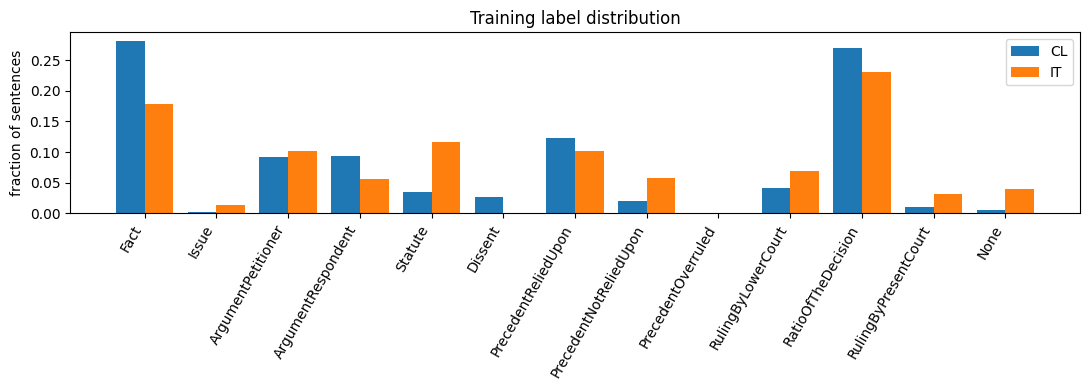

In [31]:
def hf(fn): return hf_hub_download(HF_REPO, fn, repo_type="dataset", token=HF_TOKEN)

lv = json.load(open(hf(f"{P3}/Train/label_vocab.json"), encoding="utf-8"))
if isinstance(lv, dict):
    if "labels" in lv and isinstance(lv["labels"], list): LABELS = lv["labels"]
    elif all(isinstance(v, int) for v in lv.values()):   LABELS = [k for k, _ in sorted(lv.items(), key=lambda kv: kv[1])]
    else: LABELS = list(lv.keys())
else: LABELS = list(lv)
LABELS = [str(x) for x in LABELS]; L2I = {l: i for i, l in enumerate(LABELS)}; NL = len(LABELS)
print(NL, "labels:", LABELS)

# def load_docs(path, domain, labelled=True):
#     raw = json.load(open(path, encoding="utf-8"))
#     items = raw.items() if isinstance(raw, dict) else [(str(d.get("id", i)), d) for i, d in enumerate(raw)]
#     docs = []
#     for k, d in items:
#         s = d["text"]; s = s.split("\n") if isinstance(s, str) else list(s)
#         y = None
#         if labelled and "labels" in d:
#             y = [L2I[str(l)] for l in d["labels"]]; assert len(y) == len(s), (k, len(y), len(s))
#         docs.append(dict(id=str(k), sents=[str(x) for x in s], y=y, domain=domain))
#     return docs
def load_docs(path, domain, labelled=True):
    raw = json.load(open(path, encoding="utf-8"))
    items = raw.items() if isinstance(raw, dict) else [(str(d.get("id", i) if isinstance(d, dict) else i), d) for i, d in enumerate(raw)]
    docs = []
    for k, d in items:
        # Extract text based on whether d is a str, dict, or list
        if isinstance(d, str):
            text_val = d
        elif isinstance(d, dict):
            text_val = d.get("text", d.get("content", d.get("body", "")))
        elif isinstance(d, list):
            text_val = "\n".join([str(x) for x in d])
        else:
            text_val = str(d)
            
        s = clean_text(text_val)
        s_list = s.split("\n") if isinstance(s, str) else list(s)
        
        y = None
        if labelled and isinstance(d, dict) and "labels" in d:
            y_raw = d["labels"]
            if len(y_raw) != len(s_list) and len(s_list) == 1:
                s_list = [sent.strip() for sent in s.split(".") if sent.strip()]
            y = [L2I[str(l)] for l in y_raw[:len(s_list)]]
            
        docs.append(dict(id=str(k), sents=[str(x) for x in s_list], y=y, domain=domain))
    return docs

DATA = {}
for dom in ("CL", "IT"):
    DATA[(dom, "train")] = load_docs(hf(f"{P3}/Train/{dom}_train.json"), dom)
    DATA[(dom, "dev")]   = load_docs(hf(f"{P3}/Train/{dom}_dev.json"), dom)
    DATA[(dom, "test")] = load_docs(hf(f"{P3}/Test/{dom}_test.json"), dom, labelled=False)
    # except Exception as e: print("test file not available for", dom, e); DATA[(dom, "test")] = []
if TRAIN_DOC_LIMIT:
    for dom in ("CL", "IT"): DATA[(dom, "train")] = DATA[(dom, "train")][:TRAIN_DOC_LIMIT]; DATA[(dom, "dev")] = DATA[(dom, "dev")][:max(5, TRAIN_DOC_LIMIT // 3)]

MAX_SENT_TOK = 160
def tokenize_docs(docs):
    for d in tqdm(docs, leave=False):
        d["ids"] = [tokenizer.encode(clean_text(s))[:MAX_SENT_TOK] + [tokenizer.eos_id] for s in d["sents"]]
for k, v in DATA.items(): tokenize_docs(v)

rows = []
for (dom, sp), docs in DATA.items():
    ns = sum(len(d["sents"]) for d in docs); nt = sum(sum(map(len, d["ids"])) for d in docs)
    rows.append(dict(domain=dom, split=sp, docs=len(docs), sents=ns, tokens=nt, tok_per_doc=nt / max(1, len(docs))))
print(pd.DataFrame(rows))
ids_all = [d["id"] for dom in ("CL", "IT") for d in DATA[(dom, "test")]]
print("duplicate test ids across domains:", len(ids_all) - len(set(ids_all)))

# label distribution plot
fig, ax = plt.subplots(figsize=(11, 4)); w = 0.4
for j, dom in enumerate(("CL", "IT")):
    c = Counter(l for d in DATA[(dom, "train")] for l in d["y"]); tot = sum(c.values())
    ax.bar(np.arange(NL) + (j - .5) * w, [c[i] / tot for i in range(NL)], w, label=dom)
ax.set_xticks(range(NL)); ax.set_xticklabels(LABELS, rotation=60, ha="right"); ax.set_ylabel("fraction of sentences"); ax.legend()
ax.set_title("Training label distribution"); plt.tight_layout(); plt.savefig(f"{WORK}/eda_labels.png", dpi=150); plt.show()

In [32]:
# Each chunk = [BOS] + sentences (context-only ones first, then targets). Decoder is causal, so a sentence's
# representation (its </s> token + mean pool) sees all earlier sentences inside the chunk.
CTX = {
    "sentence":   dict(max_len=192,  ctx_prev=0, max_tgt=1,   bs=64, accum=1, head="none"),
    "window3":    dict(max_len=512,  ctx_prev=3, max_tgt=1,   bs=24, accum=2, head="none"),
    "doc":        dict(max_len=1024, ctx_prev=6, max_tgt=999, bs=4,  accum=4, head="none"),
    "doc_bigru":  dict(max_len=1024, ctx_prev=6, max_tgt=999, bs=4,  accum=4, head="bigru"),
}

def make_chunks(docs, ctxc, eff_len, train=False, rng=None):
    out, budget = [], eff_len - 1
    for di, d in enumerate(docs):
        S, n, i, first = d["ids"], len(d["ids"]), 0, True
        while i < n:
            tb = budget * (rng.uniform(0.3, 1.0) if (train and first and ctxc["max_tgt"] > 1) else 1.0)
            j, used = i, 0
            while j < n and (j - i) < ctxc["max_tgt"] and (j == i or used + len(S[j]) <= tb):
                used += len(S[j]); j += 1
            c = i
            while c > 0 and (i - c) < ctxc["ctx_prev"] and used + len(S[c - 1]) <= budget:
                c -= 1; used += len(S[c])
            out.append((di, c, i, j)); i = j; first = False
    return out

def make_item(doc, c, i, j):
    ids, st, en = [tokenizer.bos_id], [], []
    for k in range(c, j):
        st.append(len(ids)); ids += doc["ids"][k]; en.append(len(ids))
    
    tm = [k >= i for k in range(c, j)]
    
    # Safe lab construction preventing IndexError if doc["y"] is shorter than k
    y_list = doc.get("y")
    lab = []
    for k in range(c, j):
        if y_list is not None and k >= i and k < len(y_list):
            lab.append(y_list[k])
        else:
            lab.append(-100)
            
    return dict(ids=ids, st=st, en=en, tm=tm, lab=lab, sidx=list(range(c, j)))
    
def collate(items, dis):
    B, T, S = len(items), max(len(x["ids"]) for x in items), max(len(x["st"]) for x in items)
    ids = torch.full((B, T), tokenizer.pad_id, dtype=torch.long)
    st = torch.zeros(B, S, dtype=torch.long); en = torch.ones(B, S, dtype=torch.long)
    sm = torch.zeros(B, S, dtype=torch.bool); tm = torch.zeros(B, S, dtype=torch.bool); lab = torch.full((B, S), -100, dtype=torch.long)
    for b, x in enumerate(items):
        n, s = len(x["ids"]), len(x["st"])
        ids[b, :n] = torch.tensor(x["ids"]); st[b, :s] = torch.tensor(x["st"]); en[b, :s] = torch.tensor(x["en"])
        sm[b, :s] = True; tm[b, :s] = torch.tensor(x["tm"]); lab[b, :s] = torch.tensor(x["lab"])
    return dict(ids=ids, st=st, en=en, sm=sm, tm=tm, y=lab, doc=dis, sidx=[x["sidx"] for x in items], tml=[x["tm"] for x in items])

def batches(docs, chunks, bs, shuffle=False, rng=None):
    idx = list(range(len(chunks)))
    if shuffle: rng.shuffle(idx)
    for s in range(0, len(idx), bs):
        sel = [chunks[k] for k in idx[s:s + bs]]
        yield collate([make_item(docs[a], c, i, j) for a, c, i, j in sel], [a for a, *_ in sel])

def to_dev(b): return {k: (v.to(DEVICE, non_blocking=True) if torch.is_tensor(v) else v) for k, v in b.items()}

In [33]:
# ---------------- backbone wrapper (replace this class for other Phase-1 architectures) ----------------
class LMBackbone(nn.Module):
    def __init__(self, lm):
        super().__init__(); self.wte, self.blocks, self.ln_f = lm.wte, lm.blocks, lm.ln_f; self.dim = lm.cfg["dim"]
    def hidden(self, x, gc=False):
        for b in self.blocks:
            x = ckpt_util.checkpoint(b.train_fwd, x, use_reentrant=False) if (gc and self.training) else b(x)[0]
        return self.ln_f(x)

def load_phase1(layers_keep=None, random_init=False):
    ck = torch.load(PHASE1_CKPT, map_location="cpu", weights_only=False)
    cfg = dict(ck["config"]); sd = {k.replace("_orig_mod.", ""): v for k, v in ck["model"].items()}
    if layers_keep is None:
        lm = LegalLM(cfg)
        if not random_init: lm.load_state_dict(sd)
    else:   # student: keep a subset of Phase-1 layers (initialised from Phase-1 weights)
        lm = LegalLM(dict(cfg, layers=len(layers_keep))); new = {}
        for k, v in sd.items():
            m = re.match(r"blocks\.(\d+)\.(.*)", k)
            if m is None: new[k] = v
            elif int(m[1]) in layers_keep: new[f"blocks.{layers_keep.index(int(m[1]))}.{m[2]}"] = v
        lm.load_state_dict(new, strict=True)
    return lm

# ---------------- classifier on top of backbone ----------------
class RRModel(nn.Module):
    def __init__(self, bb, n_labels, head="bigru", pool="last_mean", n_prompt=0, drop=0.1):
        super().__init__()
        self.bb, self.pool, D = bb, pool, bb.dim
        pdim = 2 * D if pool == "last_mean" else D
        self.proj = nn.Sequential(nn.LayerNorm(pdim), nn.Dropout(drop), nn.Linear(pdim, D), nn.GELU())
        self.ctx = nn.GRU(D, D // 2, batch_first=True, bidirectional=True) if head == "bigru" else None
        self.cls = nn.Sequential(nn.Dropout(drop), nn.Linear(D, n_labels))
        self.n_prompt = n_prompt
        if n_prompt:
            self.prompt = nn.Parameter(bb.wte.weight[torch.randint(0, bb.wte.weight.size(0), (n_prompt,))].detach().clone())
        self.ada = None; self.gc = False

    def forward(self, ids, st, en, sm):
        emb = self.bb.wte(ids); off = 0
        if self.n_prompt:
            emb = torch.cat([self.prompt.unsqueeze(0).expand(ids.size(0), -1, -1).to(emb.dtype), emb], 1); off = self.n_prompt
        h = self.bb.hidden(emb, self.gc).float()
        B, T, D = h.shape
        cs = F.pad(h.cumsum(1), (0, 0, 1, 0))
        s, e = st + off, en + off
        last = h.gather(1, (e - 1).unsqueeze(-1).expand(-1, -1, D))
        if self.pool == "last": rep = last
        else:
            mean = (cs.gather(1, e.unsqueeze(-1).expand(-1, -1, D)) - cs.gather(1, s.unsqueeze(-1).expand(-1, -1, D))) / (e - s).clamp(min=1).unsqueeze(-1)
            rep = torch.cat([last, mean], -1)
        z = self.proj(rep)
        if self.ctx is not None:
            S = z.size(1)
            pk = nn.utils.rnn.pack_padded_sequence(z.float(), sm.sum(1).cpu(), batch_first=True, enforce_sorted=False)
            o, _ = self.ctx(pk); o, _ = nn.utils.rnn.pad_packed_sequence(o, batch_first=True, total_length=S)
            z = z + o.to(z.dtype)
        return self.cls(z), z

# ---------------- adapters ----------------
class LoRALinear(nn.Module):                      # LoRA / rsLoRA (scale = a/r  vs  a/sqrt(r))
    def __init__(self, base, r=16, alpha=32, dropout=0.05, rs=False):
        super().__init__(); self.base = base
        self.A = nn.Parameter(torch.empty(r, base.in_features)); self.B = nn.Parameter(torch.zeros(base.out_features, r))
        nn.init.kaiming_uniform_(self.A, a=math.sqrt(5)); self.scale = alpha / (math.sqrt(r) if rs else r); self.drop = nn.Dropout(dropout)
    def forward(self, x): return self.base(x) + F.linear(F.linear(self.drop(x), self.A), self.B) * self.scale

class LoRMALinear(nn.Module):                     # multiplicative: W' = (I + B A) W   ->  y = h + B A h, h = W x
    def __init__(self, base, r=16, alpha=16):
        super().__init__(); self.base = base
        self.A = nn.Parameter(torch.empty(r, base.out_features)); self.B = nn.Parameter(torch.zeros(base.out_features, r))
        nn.init.kaiming_uniform_(self.A, a=math.sqrt(5)); self.scale = alpha / r
    def forward(self, x):
        h = self.base(x); return h + F.linear(F.linear(h, self.A), self.B) * self.scale

NF4 = torch.tensor([-1.0, -0.6961928009986877, -0.5250730514526367, -0.39491748809814453, -0.28444138169288635, -0.18477343022823334,
                    -0.09105003625154495, 0.0, 0.07958029955625534, 0.16093020141029358, 0.24611230194568634, 0.33791524171829224,
                    0.44070982933044434, 0.5626170039176941, 0.7229568362236023, 1.0])
class QLoRALinear(nn.Module):                     # frozen NF4 (4-bit, blockwise absmax, packed 2/byte) + LoRA
    def __init__(self, base, r=16, alpha=32, dropout=0.05, bs=64):
        super().__init__(); w = base.weight.data.float().to(DEVICE); self.shape, self.n, self.bs = w.shape, w.numel(), bs
        f = F.pad(w.flatten(), (0, (-w.numel()) % bs)).view(-1, bs); am = f.abs().amax(1, keepdim=True).clamp(min=1e-8); nrm = f / am
        idx = torch.empty(nrm.shape, dtype=torch.uint8, device=w.device); tab = NF4.to(w.device)
        for s in range(0, nrm.size(0), 8192): idx[s:s + 8192] = (nrm[s:s + 8192, :, None] - tab).abs().argmin(-1).to(torch.uint8)
        fl = idx.flatten(); self.register_buffer("packed", ((fl[0::2] << 4) | fl[1::2]).cpu()); self.register_buffer("absmax", am.half().cpu())
        self.in_features, self.out_features = base.in_features, base.out_features
        self.A = nn.Parameter(torch.empty(r, base.in_features)); self.B = nn.Parameter(torch.zeros(base.out_features, r))
        nn.init.kaiming_uniform_(self.A, a=math.sqrt(5)); self.scale = alpha / r; self.drop = nn.Dropout(dropout)
    def deq(self, dtype):
        p = self.packed; i = torch.stack([p >> 4, p & 15], -1).flatten().long()
        w = NF4.to(p.device)[i].view(-1, self.bs) * self.absmax.float(); return w.flatten()[:self.n].view(self.shape).to(dtype)
    def forward(self, x): return F.linear(x, self.deq(x.dtype)) + F.linear(F.linear(self.drop(x), self.A), self.B) * self.scale

class AdaLoRALinear(nn.Module):                   # dW = B diag(E) A, SVD-style, rank pruned by AdaLoRAManager
    def __init__(self, base, r=12, alpha=24, dropout=0.05):
        super().__init__(); self.base = base
        self.A = nn.Parameter(torch.randn(r, base.in_features) * 0.02); self.B = nn.Parameter(torch.randn(base.out_features, r) * 0.02)
        self.E = nn.Parameter(torch.zeros(r)); self.register_buffer("mask", torch.ones(r)); self.scale = alpha / r; self.drop = nn.Dropout(dropout)
    def forward(self, x):
        return self.base(x) + F.linear(F.linear(self.drop(x), self.A) * (self.E * self.mask).to(x.dtype), self.B) * self.scale
    def orth(self):
        I = torch.eye(self.E.numel(), device=self.A.device)
        return ((self.A @ self.A.t() - I) ** 2).sum() + ((self.B.t() @ self.B - I) ** 2).sum()

class AdaLoRAManager:
    def __init__(self, model, total_steps, target_rank=4, beta=0.85, ti=0.1, tf=0.2, dt=10):
        self.mods = [m for m in model.modules() if isinstance(m, AdaLoRALinear)]
        self.T, self.beta, self.ti, self.tf, self.dt = total_steps, beta, ti, tf, dt
        self.b0 = sum(m.E.numel() for m in self.mods); self.bT = target_rank * len(self.mods); self.I, self.U = {}, {}
    def budget(self, t):
        ti, tf = int(self.ti * self.T), int(self.tf * self.T)
        if t < ti: return self.b0
        if t >= self.T - tf: return self.bT
        return int(self.bT + (self.b0 - self.bT) * (1 - (t - ti) / max(1, self.T - tf - ti)) ** 3)
    def orth_loss(self): return sum(m.orth() for m in self.mods)
    @torch.no_grad()
    def update(self, t):
        for k, m in enumerate(self.mods):
            if m.E.grad is None or m.A.grad is None: return
            s = (m.E * m.E.grad).abs() + (m.A * m.A.grad).abs().mean(1) + (m.B * m.B.grad).abs().mean(0)
            if k not in self.I: self.I[k], self.U[k] = s.clone(), torch.zeros_like(s)
            else:
                self.I[k] = self.beta * self.I[k] + (1 - self.beta) * s
                self.U[k] = self.beta * self.U[k] + (1 - self.beta) * (s - self.I[k]).abs()
        if t % self.dt == 0 and len(self.I) == len(self.mods):
            sc = torch.cat([self.I[k] * self.U[k] for k in range(len(self.mods))]); keep = self.budget(t)
            mk = torch.zeros_like(sc); mk[sc.topk(min(keep, sc.numel())).indices] = 1; o = 0
            for m in self.mods:
                r = m.E.numel(); m.mask.copy_(mk[o:o + r]); m.E.mul_(m.mask); o += r
    def active_rank(self): return float(sum(m.mask.sum().item() for m in self.mods) / len(self.mods))

class IA3Linear(nn.Module):                       # learned rescaling vector on output (k,v) or input (FFN hidden)
    def __init__(self, base, where):
        super().__init__(); self.base, self.where = base, where
        self.s = nn.Parameter(torch.ones(base.out_features if where == "out" else base.in_features))
    def forward(self, x): return self.base(x * self.s.to(x.dtype)) if self.where == "in" else self.base(x) * self.s.to(x.dtype)

class PrefixAttn(nn.Module):                      # learned per-layer key/value prefix (shared across heads of a KV group)
    def __init__(self, attn, P):
        super().__init__(); self.attn = attn
        self.pk = nn.Parameter(torch.randn(attn.hk, P, attn.hd)); self.pv = nn.Parameter(torch.randn(attn.hk, P, attn.hd) * 0.1)
    def forward(self, x, mask=None, cache=None, start=0):
        a = self.attn; b, t, _ = x.shape; r = a.h // a.hk
        q = a.q(x).view(b, t, a.h, a.hd).transpose(1, 2)
        k, v = a.kv(x).view(b, t, 2, a.hk, a.hd).permute(2, 0, 3, 1, 4)
        q, k = a.rope(a.qn(q), start), a.rope(a.kn(k), start)
        P = self.pk.size(1)
        k = torch.cat([self.pk.unsqueeze(0).expand(b, -1, -1, -1).to(k.dtype), k], 2)
        v = torch.cat([self.pv.unsqueeze(0).expand(b, -1, -1, -1).to(v.dtype), v], 2)
        k, v = k.repeat_interleave(r, 1), v.repeat_interleave(r, 1)
        m = torch.ones(t, P + t, dtype=torch.bool, device=x.device).tril(diagonal=P)   # prefix visible to all, causal on tokens
        y = F.scaled_dot_product_attention(q, k, v, attn_mask=m)
        return a.o(y.transpose(1, 2).reshape(b, t, a.h * a.hd)), cache

TARGETS = ("attn.dq", "attn.uq", "attn.dkv", "attn.uk", "attn.uv", "attn.o", "ffn.w13", "ffn.w2")
def replace_linears(root, suffixes, factory):
    for name, mod in list(root.named_modules()):
        for cn, ch in list(mod.named_children()):
            full = f"{name}.{cn}" if name else cn
            if isinstance(ch, nn.Linear) and any(full.endswith(s) for s in suffixes): setattr(mod, cn, factory(full, ch))

def apply_method(model, cfg):
    m, bb = cfg["method"], model.bb
    if m != "full":
        for p in bb.parameters(): p.requires_grad = False
    if m in ("lora", "rslora"):
        replace_linears(bb, TARGETS, lambda n, l: LoRALinear(l, cfg["r"], cfg["alpha"], 0.05, rs=(m == "rslora")))
    elif m == "qlora":  replace_linears(bb, TARGETS, lambda n, l: QLoRALinear(l, cfg["r"], cfg["alpha"]))
    elif m == "adalora": replace_linears(bb, TARGETS, lambda n, l: AdaLoRALinear(l, cfg["r"], cfg["alpha"]))
    elif m == "lorma":  replace_linears(bb, TARGETS, lambda n, l: LoRMALinear(l, cfg["r"], cfg["alpha"]))
    elif m == "ia3":
        replace_linears(bb, ("attn.kv",), lambda n, l: IA3Linear(l, "out")); replace_linears(bb, ("ffn.w2",), lambda n, l: IA3Linear(l, "in"))
    elif m == "prefix":
        for blk in bb.blocks: blk.attn = PrefixAttn(blk.attn, cfg["n_prefix"])
    elif m not in ("full", "linear_probe", "prompt"): raise ValueError(m)

def build_model(cfg):
    lm = load_phase1(cfg.get("layers_keep"), cfg.get("random_init", False)); bb = LMBackbone(lm)
    npr = cfg.get("n_prompt", 0) if cfg["method"] == "prompt" else 0
    model = RRModel(bb, NL, head=CTX[cfg["ctx"]]["head"], pool=cfg.get("pool", "last_mean"), n_prompt=npr)
    if cfg["method"] == "prompt":
        for p in bb.parameters(): p.requires_grad = False
    apply_method(model, cfg); model.gc = cfg.get("grad_ckpt", False)
    return model.to(DEVICE)

def model_stats(model):
    tr = sum(p.numel() for p in model.parameters() if p.requires_grad); tot = sum(p.numel() for p in model.parameters())
    mb = (sum(p.numel() * p.element_size() for p in model.parameters()) + sum(b.numel() * b.element_size() for b in model.buffers())) / 2**20
    return tr, tot, mb

In [34]:
RESULTS_PATH, PRED_PATH = f"{WORK}/results.json", f"{WORK}/dev_preds.pkl"
RESULTS = json.load(open(RESULTS_PATH)) if os.path.exists(RESULTS_PATH) else {}
PRED = pickle.load(open(PRED_PATH, "rb")) if os.path.exists(PRED_PATH) else {}
def save_all():
    json.dump(RESULTS, open(RESULTS_PATH, "w"), default=lambda o: o.item() if hasattr(o, "item") else str(o))
    pickle.dump(PRED, open(PRED_PATH, "wb"))

def class_weights(docs):
    c = np.bincount([l for d in docs for l in d["y"]], minlength=NL).astype(np.float64) + 1
    w = (c.sum() / (NL * c)) ** 0.5; return torch.tensor(w / w.mean(), dtype=torch.float32, device=DEVICE)

def rr_loss(logits, y, kind, w):
    m = y != -100; lg, yy = logits[m].float(), y[m]
    if kind == "focal":
        lp = F.log_softmax(lg, -1).gather(1, yy[:, None])[:, 0]; pt = lp.exp()
        return (-(1 - pt) ** 2 * lp * (w[yy] if w is not None else 1.0)).mean()
    return F.cross_entropy(lg, yy, weight=w if kind in ("wce", "focal") else None, label_smoothing=0.0)

def metrics(y, p):
    return dict(f1=f1_score(y, p, average="macro", zero_division=0), P=precision_score(y, p, average="macro", zero_division=0),
                R=recall_score(y, p, average="macro", zero_division=0), acc=accuracy_score(y, p),
                f1_all=f1_score(y, p, average="macro", labels=list(range(NL)), zero_division=0))

@torch.no_grad()
def predict(model, docs, ctxc, eff_len):
    model.eval(); chunks = make_chunks(docs, ctxc, eff_len)
    chunks.sort(key=lambda ch: sum(len(x) for x in docs[ch[0]]["ids"][ch[1]:ch[3]]))
    Lg = [np.zeros((len(d["sents"]), NL), np.float32) for d in docs]
    for b in batches(docs, chunks, ctxc["bs"] * 2):
        bd = to_dev(b)
        with torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=USE_AMP):
            lg, _ = model(bd["ids"], bd["st"], bd["en"], bd["sm"])
        lg = lg.float().cpu().numpy()
        for r, (di, sidx, tml) in enumerate(zip(b["doc"], b["sidx"], b["tml"])):
            for q, (k, t) in enumerate(zip(sidx, tml)):
                if t: Lg[di][k] = lg[r, q]
    return [l.argmax(1) for l in Lg], Lg

def eval_domains(model, dev_sets, ctxc, eff_len, doms):
    out = {}
    for dom in doms:
        P, _ = predict(model, dev_sets[dom], ctxc, eff_len)
        out[dom] = metrics(np.concatenate([d["y"] for d in dev_sets[dom]]), np.concatenate(P))
    return out

def load_teacher(tname):
    tc = RESULTS[tname]["cfg"]; t = build_model(tc); t.load_state_dict(torch.load(f"{CK}/{tname}.pt", map_location=DEVICE)); t.eval()
    for p in t.parameters(): p.requires_grad = False
    return t

def train_run(cfg):
    name = cfg["name"]
    if name in RESULTS: print("skip (done):", name); return RESULTS[name]
    print(f"\n=== {name} | {cfg['method']} | ctx={cfg['ctx']} | train={cfg['train_domains']} | loss={cfg['loss']} ===")
    set_seed(cfg.get("seed", SEED)); rng = random.Random(cfg.get("seed", SEED))
    ctxc = CTX[cfg["ctx"]]; eff_len = ctxc["max_len"] - (cfg.get("n_prompt", 0) if cfg["method"] == "prompt" else 0)
    train_docs = [d for dom in cfg["train_domains"] for d in DATA[(dom, "train")]]
    dev_sets = {dom: DATA[(dom, "dev")] for dom in ("CL", "IT")}
    model = build_model(cfg); tr, tot, mb = model_stats(model)
    print(f"params trainable {tr/1e6:.2f}M / total {tot/1e6:.1f}M | size {mb:.0f} MB")
    w = class_weights(train_docs) if cfg["loss"] in ("wce", "focal") else None
    teacher = load_teacher(cfg["kd"]["teacher"]) if cfg.get("kd") else None

    groups = {"bb": [], "head": []}
    for n, p in model.named_parameters():
        if p.requires_grad: groups["bb" if n.startswith("bb.") or n == "prompt" else "head"].append(p)
    opt = torch.optim.AdamW([dict(params=groups["bb"], lr=cfg["lr"], base=cfg["lr"]),
                             dict(params=groups["head"], lr=cfg["head_lr"], base=cfg["head_lr"])], weight_decay=0.01, betas=(0.9, 0.98))
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP and AMP_DTYPE == torch.float16)
    n_chunks = len(make_chunks(train_docs, ctxc, eff_len)); spe = max(1, math.ceil(n_chunks / (ctxc["bs"] * ctxc["accum"])))
    total = cfg["epochs"] * spe; warm = max(1, int(0.06 * total))
    if cfg["method"] == "adalora": model.ada = AdaLoRAManager(model, total, cfg.get("target_rank", 4))
    track = {n for n, p in model.named_parameters() if p.requires_grad} | {n for n, _ in model.named_buffers() if n.endswith(".mask")}
    sel_doms = cfg["train_domains"]; best, best_state, bad, hist, step, t0 = -1, None, 0, [], 0, time.time()
    # 2. Setup resume variables
    start_ep = 0
    best = -1
    best_state = None
    bad = 0
    hist = []
    step = 0
    # Resume from checkpoint if it exists
    ckpt_file = f"{CK}/{name}_ckpt.pt"
    print(ckpt_file, os.path.exists(ckpt_file))
    if os.path.exists(ckpt_file):
        print(f"Resuming checkpoint from {ckpt_file}")
        checkpoint = torch.load(ckpt_file, map_location=DEVICE)
        model.load_state_dict(checkpoint["model_state"], strict=False)
        opt.load_state_dict(checkpoint["optimizer_state"])
        if "scaler_state" in checkpoint and checkpoint["scaler_state"] is not None:
            scaler.load_state_dict(checkpoint["scaler_state"])
        start_ep = checkpoint["epoch"] + 1
        best = checkpoint["best"]
        best_state = checkpoint["best_state"]
        bad = checkpoint["bad"]
        hist = checkpoint["hist"]
        step = checkpoint["step"]
    for ep in range(start_ep, cfg["epochs"]):
        model.train(); chunks = make_chunks(train_docs, ctxc, eff_len, train=True, rng=rng); run_loss, nb = 0.0, 0
        opt.zero_grad(set_to_none=True)
        pbar = tqdm(batches(train_docs, chunks, ctxc["bs"], True, rng), total=math.ceil(len(chunks) / ctxc["bs"]), desc=f"ep{ep+1}", leave=False)
        for mi, b in enumerate(pbar):
            bd = to_dev(b)
            with torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=USE_AMP):
                lg, z = model(bd["ids"], bd["st"], bd["en"], bd["sm"])
                loss = rr_loss(lg, bd["y"], cfg["loss"], w)
                if teacher is not None:
                    with torch.no_grad(): tl, tz = teacher(bd["ids"], bd["st"], bd["en"], bd["sm"])
                    m = bd["y"] != -100; T = cfg["kd"]["T"]
                    kd = F.kl_div(F.log_softmax(lg[m].float() / T, -1), F.softmax(tl[m].float() / T, -1), reduction="batchmean") * T * T
                    loss = cfg["kd"]["alpha"] * loss + (1 - cfg["kd"]["alpha"]) * kd
                    if cfg["kd"].get("beta", 0) > 0: loss = loss + cfg["kd"]["beta"] * (1 - F.cosine_similarity(z[m].float(), tz[m].float(), dim=-1)).mean()
                if model.ada is not None: loss = loss + 0.1 * model.ada.orth_loss()
            scaler.scale(loss / ctxc["accum"]).backward(); run_loss += loss.item(); nb += 1
            if (mi + 1) % ctxc["accum"] == 0:
                lr_f = (step + 1) / warm if step < warm else 0.5 * (1 + math.cos(math.pi * (step - warm) / max(1, total - warm)))
                for g in opt.param_groups: g["lr"] = g["base"] * max(lr_f, 0.02)
                scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_([p for g in groups.values() for p in g], 1.0)
                if model.ada is not None: model.ada.update(step)
                scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True); step += 1
            if (time.time() - t0) / 60 > MAX_MIN_PER_RUN: break
        dm = eval_domains(model, dev_sets, ctxc, eff_len, sel_doms); score = float(np.mean([dm[d]["f1"] for d in sel_doms]))
        hist.append(dict(epoch=ep + 1, loss=run_loss / max(1, nb), **{f"f1_{d}": dm[d]["f1"] for d in sel_doms}, score=score))
        print(f"ep{ep+1} loss {run_loss/max(1,nb):.4f} | dev macro-F1 " + " ".join(f"{d}:{dm[d]['f1']:.4f}" for d in sel_doms) + f" | {(time.time()-t0)/60:.1f} min")
        if score > best: best, bad, best_state = score, 0, {k: v.detach().cpu().clone() for k, v in model.state_dict().items() if k in track}
        else:
            bad += 1
            if bad >= cfg.get("patience", 3): break
        # 3. Save lightweight epoch checkpoint to keep storage footprint minimal
        torch.save({
            "epoch": ep,
            "step": step,
            "best": best,
            "bad": bad,
            "hist": hist,
            "model_state": {k: v.cpu() for k, v in model.state_dict().items() if k in track},
            "optimizer_state": opt.state_dict(),
            "scaler_state": scaler.state_dict() if USE_AMP else None,
            "best_state": best_state
        }, ckpt_file)
        if (time.time() - t0) / 60 > MAX_MIN_PER_RUN: print("time cap reached"); break
    train_min = (time.time() - t0) / 60
    model.load_state_dict(best_state, strict=False)
    if cfg.get("save_ckpt"): torch.save({k: v.cpu() for k, v in model.state_dict().items()}, f"{CK}/{name}.pt")

    # final evaluation on both dev domains (+ timing), test prediction
    res = dict(name=name, group=cfg["group"], cfg=cfg, trainable=tr, total=tot, size_mb=mb, train_min=train_min, hist=hist, dev={}, perclass={}, conf={})
    PRED[name] = {}; t1 = time.time(); nsent = 0
    for dom in ("CL", "IT"):
        P, Lg = predict(model, dev_sets[dom], ctxc, eff_len); y, p = np.concatenate([d["y"] for d in dev_sets[dom]]), np.concatenate(P); nsent += len(y)
        res["dev"][dom] = metrics(y, p); res["perclass"][dom] = f1_score(y, p, average=None, labels=list(range(NL)), zero_division=0).tolist()
        res["conf"][dom] = confusion_matrix(y, p, labels=list(range(NL))).tolist(); PRED[name][dom] = dict(y=y, p=p, logits=np.concatenate(Lg))
    res["infer_s_per_1k"] = (time.time() - t1) / nsent * 1000
    res["f1_CL"], res["f1_IT"] = res["dev"]["CL"]["f1"], res["dev"]["IT"]["f1"]; res["f1_mean"] = (res["f1_CL"] + res["f1_IT"]) / 2
    if model.ada is not None: res["active_rank"] = model.ada.active_rank()
    for dom in ("CL", "IT"):
        td = DATA[(dom, "test")]
        if td:
            P, _ = predict(model, td, ctxc, eff_len)
            json.dump({d["id"]: [LABELS[i] for i in p] for d, p in zip(td, P)}, open(f"{PRED_DIR}/{name}_{dom}.json", "w"))
    RESULTS[name] = res; save_all()
    print(f"-> {name}: CL {res['f1_CL']:.4f} | IT {res['f1_IT']:.4f} | mean {res['f1_mean']:.4f} | {train_min:.1f} min | {res['infer_s_per_1k']:.2f}s/1k sents")
    del model, opt, teacher; gc.collect(); torch.cuda.empty_cache()
    return res

In [35]:
BASE = dict(ctx="doc_bigru", loss="wce", train_domains=["CL", "IT"], epochs=8, patience=3, head_lr=1e-3, lr=5e-4, seed=SEED)
METHOD_HP = {
    "linear_probe": dict(head_lr=2e-3),
    "full":    dict(lr=1e-4, epochs=6),
    "lora":    dict(r=16, alpha=32, lr=5e-4),
    "rslora":  dict(r=64, alpha=16, lr=5e-4),            # scale alpha/sqrt(r)
    "qlora":   dict(r=16, alpha=32, lr=5e-4),
    "adalora": dict(r=12, alpha=24, target_rank=4, lr=1e-3),
    "lorma":   dict(r=16, alpha=16, lr=5e-4),
    "ia3":     dict(lr=3e-3),
    "prefix":  dict(n_prefix=32, lr=5e-3),
    "prompt":  dict(n_prompt=32, lr=3e-3),
}
def C(name, group, method="lora", **kw):
    c = dict(BASE); c.update(METHOD_HP.get(method, {})); c.update(name=name, group=group, method=method); c.update(kw); return c
def best_of(prefix, key="f1_mean"):
    c = {k: v for k, v in RESULTS.items() if k.startswith(prefix)}; return max(c, key=lambda k: c[k][key]) if c else None

# ---- Group 1: how much context helps (LoRA fixed) ----
# for ctx in ["sentence", "window3", "doc", "doc_bigru"]: train_run(C(f"ctx_{ctx}", "context", "lora", ctx=ctx, epochs=4))
for ctx in ["sentence", "doc_bigru"]: train_run(C(f"ctx_{ctx}", "context", "lora", ctx=ctx, epochs=4))
BEST_CTX = RESULTS[best_of("ctx_")]["cfg"]["ctx"]; print("\nBEST CONTEXT MODE:", BEST_CTX)

# ---- Group 2: fine-tuning / PEFT techniques (all with BEST_CTX) ----
# for m in ["linear_probe", "full", "lora", "rslora", "qlora", "adalora", "lorma", "ia3", "prefix", "prompt"]:
#     train_run(C(f"m_{m}", "method", m, ctx=BEST_CTX, save_ckpt=(m == "full"), epochs=4))
for m in ["full", "lora", "rslora"]:
    train_run(C(f"m_{m}", "method", m, ctx=BEST_CTX, save_ckpt=(m == "full"), epochs=4))

skip (done): ctx_sentence
skip (done): ctx_doc_bigru

BEST CONTEXT MODE: doc_bigru
skip (done): m_full
skip (done): m_lora
skip (done): m_rslora


In [36]:
# # ---- Group 3: class-balancing (LoRA, BEST_CTX; 'wce' already = m_lora) ----
# for lo in ["ce", "focal"]: train_run(C(f"loss_{lo}", "loss", "lora", ctx=BEST_CTX, loss=lo))
# # ---- Group 4: domain study (train on one domain, evaluate on both) ----
# for dom in ["CL", "IT"]: train_run(C(f"dom_{dom}", "domain", "lora", ctx=BEST_CTX, train_domains=[dom]))
# # ---- Group 5: value of Phase-1 pre-training (random init, same arch) ----
# train_run(C("p1_random_full", "phase1", "full", ctx=BEST_CTX, random_init=True))
# train_run(C("p1_random_lora", "phase1", "lora", ctx=BEST_CTX, random_init=True))

In [37]:
# ---- Group 6: knowledge distillation ----
# Teacher = full FT of the 8-layer Phase-1 model (m_full). Student = 4 layers initialised from Phase-1 layers {0,2,5,7}.
STUDENT = dict(layers_keep=[0, 2, 5, 7], lr=2e-4, epochs=4)
train_run(C("kd_student_ce", "kd", "full", ctx=BEST_CTX, **STUDENT))                                   # no-KD baseline
train_run(C("kd_student_logits", "kd", "full", ctx=BEST_CTX, kd=dict(teacher="m_full", T=2.0, alpha=0.3, beta=0.0), **STUDENT))
train_run(C("kd_student_logits_rep", "kd", "full", ctx=BEST_CTX, kd=dict(teacher="m_full", T=2.0, alpha=0.3, beta=0.5), **STUDENT))

skip (done): kd_student_ce
skip (done): kd_student_logits
skip (done): kd_student_logits_rep


{'name': 'kd_student_logits_rep',
 'group': 'kd',
 'cfg': {'ctx': 'doc_bigru',
  'loss': 'wce',
  'train_domains': ['CL', 'IT'],
  'epochs': 4,
  'patience': 3,
  'head_lr': 0.001,
  'lr': 0.0002,
  'seed': 42,
  'name': 'kd_student_logits_rep',
  'group': 'kd',
  'method': 'full',
  'kd': {'teacher': 'm_full', 'T': 2.0, 'alpha': 0.3, 'beta': 0.5},
  'layers_keep': [0, 2, 5, 7]},
 'trainable': 59051149,
 'total': 59051149,
 'size_mb': 225.76225662231445,
 'train_min': 8.33331998984019,
 'hist': [{'epoch': 1,
   'loss': 2.753194329639276,
   'f1_CL': 0.24437941465143762,
   'f1_IT': 0.27069338689243333,
   'score': 0.25753640077193546},
  {'epoch': 2,
   'loss': 1.6035653717159608,
   'f1_CL': 0.3158026485227753,
   'f1_IT': 0.3190636462227204,
   'score': 0.31743314737274786},
  {'epoch': 3,
   'loss': 0.9378037376639744,
   'f1_CL': 0.3340386291593562,
   'f1_IT': 0.4560007519858838,
   'score': 0.39501969057262},
  {'epoch': 4,
   'loss': 0.6303484266653111,
   'f1_CL': 0.35177915881

                 name   group method       ctx loss train  trainable_M  total_M  size_MB  train_min  infer_s_per_1k  F1_CL  F1_IT  F1_mean  P_mean  R_mean
        ctx_doc_bigru context   lora doc_bigru  wce CL,IT       3.5144 103.5783 396.1197     8.8930          2.9676 0.3627 0.4088   0.3857  0.3869  0.4332
          ctx_window3 context   lora   window3  wce CL,IT       1.6673 101.7312 389.0738    45.3148          8.5257 0.3029 0.3927   0.3478  0.3675  0.3607
         ctx_sentence context   lora  sentence  wce CL,IT       1.6673 101.7312 389.0738    18.8734          2.4961 0.2621 0.3683   0.3152  0.3326  0.3246
    kd_student_logits      kd   full doc_bigru  wce CL,IT      59.0511  59.0511 225.7623     8.3282          1.4007 0.3898 0.4867   0.4382  0.4764  0.4336
        kd_student_ce      kd   full doc_bigru  wce CL,IT      59.0511  59.0511 225.7623     4.9466          1.4078 0.3931 0.4577   0.4254  0.5174  0.4136
kd_student_logits_rep      kd   full doc_bigru  wce CL,IT      59.0511

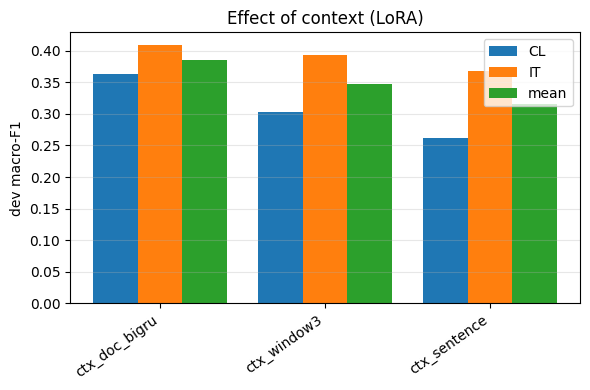

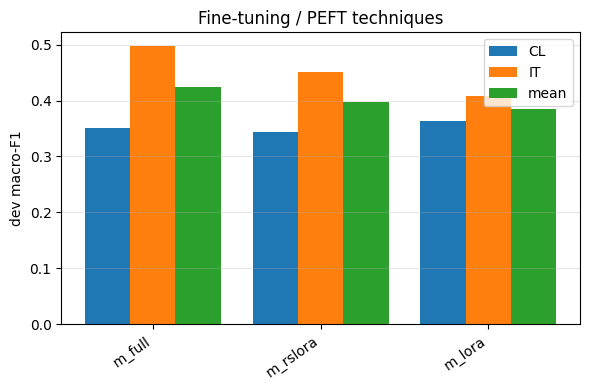

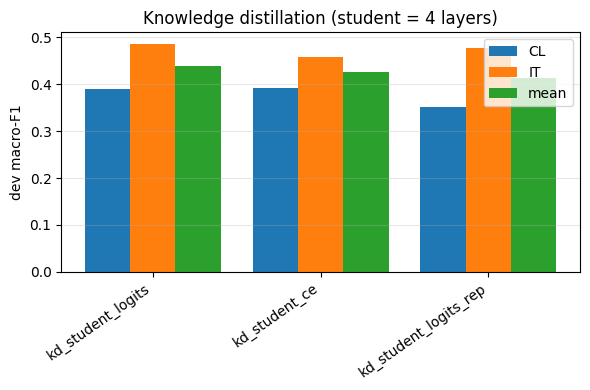

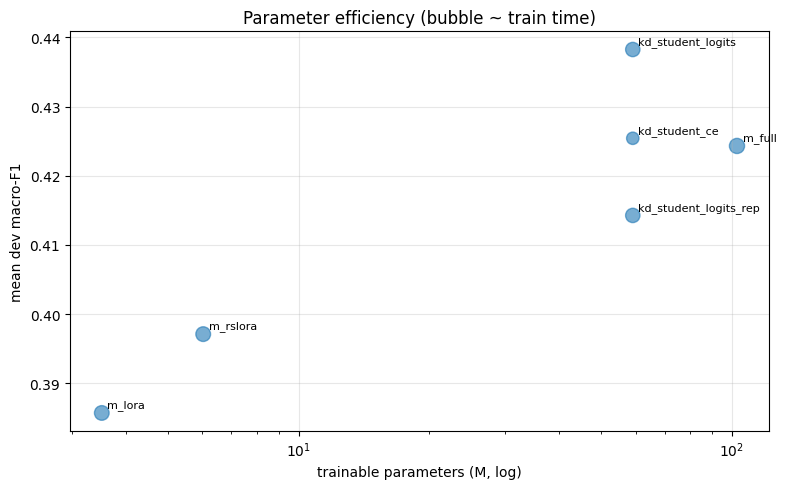

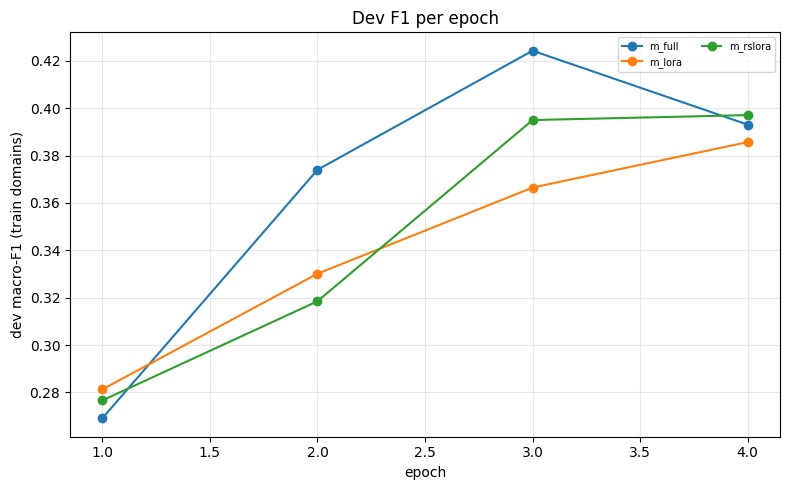

                 name  total_M  size_MB  infer_s_per_1k  F1_CL  F1_IT  F1_mean
               m_full 102.7416 392.9283          2.8195 0.3515 0.4971   0.4243
        kd_student_ce  59.0511 225.7623          1.4078 0.3931 0.4577   0.4254
    kd_student_logits  59.0511 225.7623          1.4007 0.3898 0.4867   0.4382
kd_student_logits_rep  59.0511 225.7623          1.4010 0.3518 0.4768   0.4143


In [38]:
def results_df():
    rows = []
    for n, r in RESULTS.items():
        c = r["cfg"]; rows.append(dict(name=n, group=r["group"], method=c["method"], ctx=c["ctx"], loss=c["loss"], train=",".join(c["train_domains"]),
            trainable_M=r["trainable"] / 1e6, total_M=r["total"] / 1e6, size_MB=r["size_mb"], train_min=r["train_min"], infer_s_per_1k=r["infer_s_per_1k"],
            F1_CL=r["f1_CL"], F1_IT=r["f1_IT"], F1_mean=r["f1_mean"],
            P_mean=(r["dev"]["CL"]["P"] + r["dev"]["IT"]["P"]) / 2, R_mean=(r["dev"]["CL"]["R"] + r["dev"]["IT"]["R"]) / 2))
    return pd.DataFrame(rows)
df = results_df(); pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)
print(df.sort_values(["group", "F1_mean"], ascending=[True, False]).round(4).to_string(index=False))
df.to_csv(f"{WORK}/summary.csv", index=False)

def bar_group(g, key="name", title=None, fn=None):
    d = df[df.group == g].sort_values("F1_mean", ascending=False)
    if g == "method" and "ctx_" + BEST_CTX in RESULTS: pass
    x = np.arange(len(d)); fig, ax = plt.subplots(figsize=(max(6, 1.0 * len(d) + 2), 4))
    ax.bar(x - .27, d.F1_CL, .27, label="CL"); ax.bar(x, d.F1_IT, .27, label="IT"); ax.bar(x + .27, d.F1_mean, .27, label="mean")
    ax.set_xticks(x); ax.set_xticklabels(d[key], rotation=35, ha="right"); ax.set_ylabel("dev macro-F1"); ax.set_title(title or g); ax.legend(); ax.grid(axis="y", alpha=.3)
    plt.tight_layout(); plt.savefig(f"{WORK}/{fn or g}.png", dpi=150); plt.show()

for g, t in [("context", "Effect of context (LoRA)"), ("method", "Fine-tuning / PEFT techniques"), ("loss", "Class-balancing strategy (LoRA)"),
             ("phase1", "Phase-1 pretrained vs random init"), ("kd", "Knowledge distillation (student = 4 layers)")]:
    if (df.group == g).any(): bar_group(g, title=t)

# efficiency: trainable params vs F1 (bubble = train minutes)
d = df[df.group.isin(["method", "kd"])]
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(d.trainable_M, d.F1_mean, s=40 + 8 * d.train_min, alpha=.6)
for _, r in d.iterrows(): ax.annotate(r["name"], (r.trainable_M, r.F1_mean), fontsize=8, xytext=(4, 4), textcoords="offset points")
ax.set_xscale("log"); ax.set_xlabel("trainable parameters (M, log)"); ax.set_ylabel("mean dev macro-F1"); ax.set_title("Parameter efficiency (bubble ~ train time)"); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(f"{WORK}/efficiency.png", dpi=150); plt.show()

# training curves
fig, ax = plt.subplots(figsize=(8, 5))
for n, r in RESULTS.items():
    if r["group"] == "method": ax.plot([h["epoch"] for h in r["hist"]], [h["score"] for h in r["hist"]], marker="o", label=n)
ax.set_xlabel("epoch"); ax.set_ylabel("dev macro-F1 (train domains)"); ax.legend(fontsize=7, ncol=2); ax.grid(alpha=.3); ax.set_title("Dev F1 per epoch")
plt.tight_layout(); plt.savefig(f"{WORK}/curves.png", dpi=150); plt.show()

# domain transfer matrix (rows = trained on, cols = evaluated on)
dm = {"CL-only": "dom_CL", "IT-only": "dom_IT", "joint": "m_lora"}
if all(v in RESULTS for v in dm.values()):
    M = np.array([[RESULTS[v]["f1_CL"], RESULTS[v]["f1_IT"]] for v in dm.values()])
    fig, ax = plt.subplots(figsize=(4.5, 3.5)); im = ax.imshow(M, cmap="viridis")
    ax.set_xticks([0, 1]); ax.set_xticklabels(["eval CL", "eval IT"]); ax.set_yticks(range(3)); ax.set_yticklabels(dm.keys())
    for i in range(3):
        for j in range(2): ax.text(j, i, f"{M[i,j]:.3f}", ha="center", va="center", color="w")
    ax.set_title("Domain transfer (macro-F1)"); plt.tight_layout(); plt.savefig(f"{WORK}/domain_matrix.png", dpi=150); plt.show()

# KD summary: size / latency / F1
k = df[df.name.isin(["m_full", "kd_student_ce", "kd_student_logits", "kd_student_logits_rep"])]
print(k[["name", "total_M", "size_MB", "infer_s_per_1k", "F1_CL", "F1_IT", "F1_mean"]].round(4).to_string(index=False))

best experiment: kd_student_logits


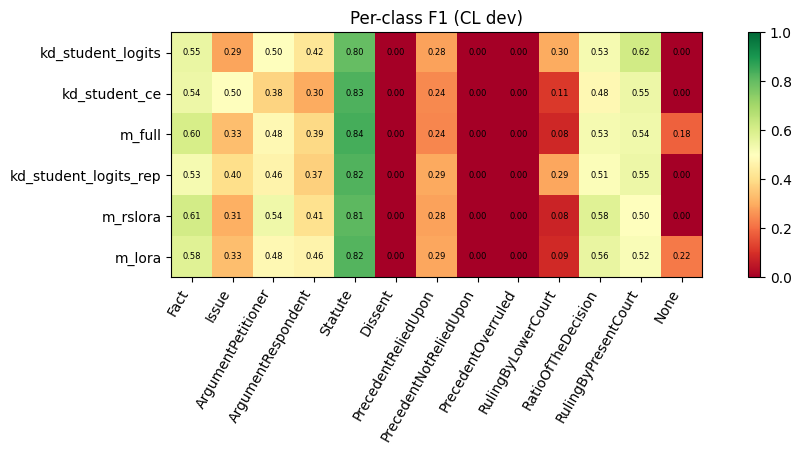

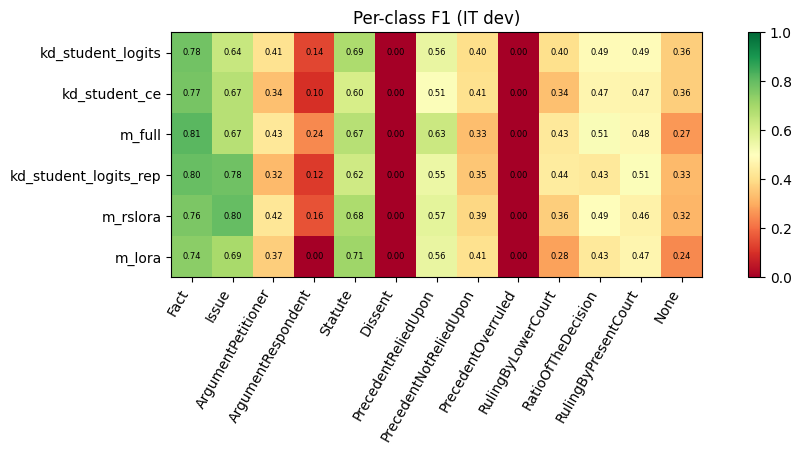

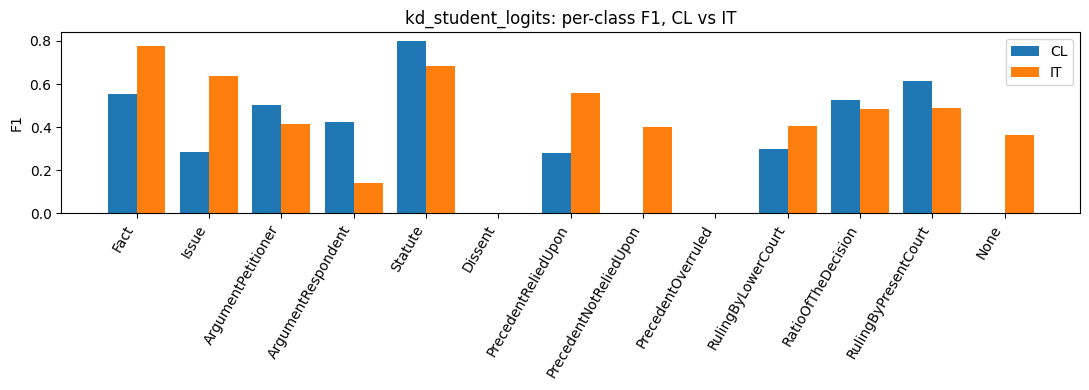

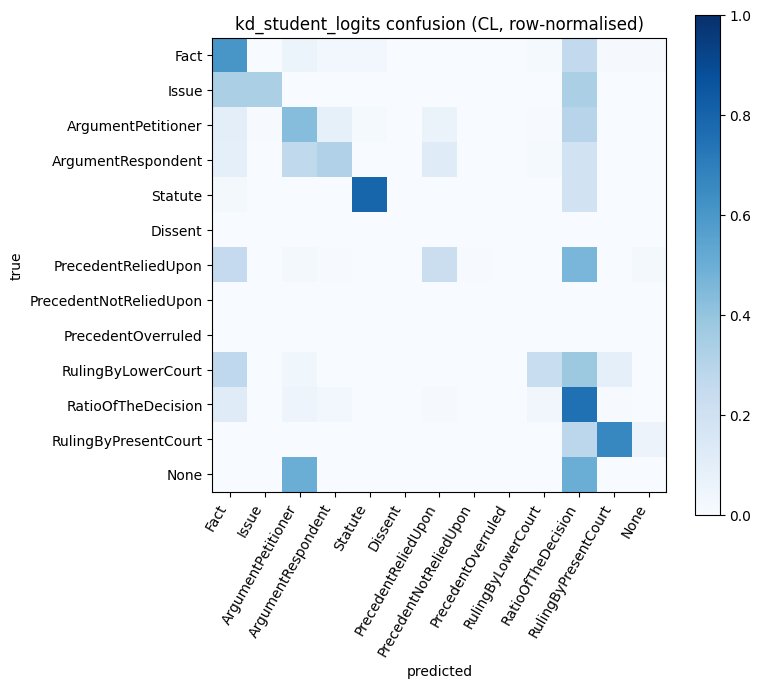


Top confusions [CL] (true -> pred):
               true                pred  count  row_frac
 ArgumentPetitioner  RatioOfTheDecision    102     0.297
PrecedentReliedUpon  RatioOfTheDecision     66     0.465
               Fact  RatioOfTheDecision     65     0.261
 ArgumentRespondent  ArgumentPetitioner     62     0.263
 ArgumentRespondent  RatioOfTheDecision     46     0.195
PrecedentReliedUpon                Fact     36     0.254
 RatioOfTheDecision                Fact     34     0.118
 ArgumentPetitioner                Fact     33     0.096
 ArgumentPetitioner  ArgumentRespondent     29     0.084
 ArgumentRespondent PrecedentReliedUpon     28     0.119


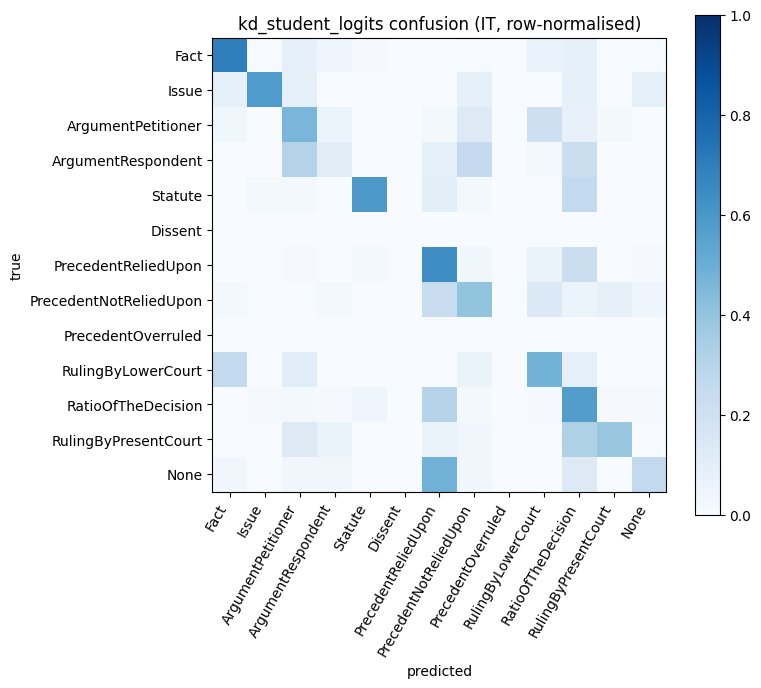


Top confusions [IT] (true -> pred):
                  true                pred  count  row_frac
    RatioOfTheDecision PrecedentReliedUpon     35     0.304
   PrecedentReliedUpon  RatioOfTheDecision     25     0.223
                  Fact  ArgumentPetitioner     18     0.092
                  Fact  RatioOfTheDecision     16     0.082
               Statute  RatioOfTheDecision     16     0.258
                  None PrecedentReliedUpon     15     0.484
                  Fact  RulingByLowerCourt     13     0.067
    ArgumentPetitioner  RulingByLowerCourt     12     0.214
PrecedentNotReliedUpon PrecedentReliedUpon     12     0.240
    RulingByLowerCourt                Fact     12     0.261

[CL] within-group confusion share (errors that stay inside the related group):
  Precedent*         errors from these classes:   110 | of which stay in-group: 0.91%
  Arguments          errors from these classes:   357 | of which stay in-group: 25.49%
  Reasoning/Ruling   errors from these classes:   

In [39]:
def best_name(groups=("method", "kd", "loss", "domain", "context")):
    d = df[df.group.isin(groups)]; return d.loc[d.F1_mean.idxmax(), "name"]
BEST = best_name(); print("best experiment:", BEST)

# per-class F1 heatmap, one per domain, across method-group experiments
for dom in ("CL", "IT"):
    names = [n for n in df[df.group.isin(["method", "kd"])].sort_values("F1_mean", ascending=False).name]
    M = np.array([RESULTS[n]["perclass"][dom] for n in names])
    fig, ax = plt.subplots(figsize=(11, 0.4 * len(names) + 2)); im = ax.imshow(M, vmin=0, vmax=1, cmap="RdYlGn")
    ax.set_xticks(range(NL)); ax.set_xticklabels(LABELS, rotation=60, ha="right"); ax.set_yticks(range(len(names))); ax.set_yticklabels(names)
    for i in range(M.shape[0]):
        for j in range(NL): ax.text(j, i, f"{M[i,j]:.2f}", ha="center", va="center", fontsize=6)
    ax.set_title(f"Per-class F1 ({dom} dev)"); plt.colorbar(im); plt.tight_layout(); plt.savefig(f"{WORK}/perclass_{dom}.png", dpi=150); plt.show()

# CL vs IT per-class for the best model
fig, ax = plt.subplots(figsize=(11, 4)); w = .4
for j, dom in enumerate(("CL", "IT")): ax.bar(np.arange(NL) + (j - .5) * w, RESULTS[BEST]["perclass"][dom], w, label=dom)
ax.set_xticks(range(NL)); ax.set_xticklabels(LABELS, rotation=60, ha="right"); ax.set_ylabel("F1"); ax.legend(); ax.set_title(f"{BEST}: per-class F1, CL vs IT")
plt.tight_layout(); plt.savefig(f"{WORK}/best_perclass_cl_it.png", dpi=150); plt.show()

# normalised confusion matrices + top confused pairs
for dom in ("CL", "IT"):
    C_ = np.array(RESULTS[BEST]["conf"][dom], float); Cn = C_ / np.maximum(C_.sum(1, keepdims=True), 1)
    fig, ax = plt.subplots(figsize=(8, 7)); im = ax.imshow(Cn, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(NL)); ax.set_xticklabels(LABELS, rotation=60, ha="right"); ax.set_yticks(range(NL)); ax.set_yticklabels(LABELS)
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(f"{BEST} confusion ({dom}, row-normalised)"); plt.colorbar(im)
    plt.tight_layout(); plt.savefig(f"{WORK}/confusion_{dom}.png", dpi=150); plt.show()
    off = [(LABELS[i], LABELS[j], int(C_[i, j]), Cn[i, j]) for i in range(NL) for j in range(NL) if i != j and C_[i, j] > 0]
    print(f"\nTop confusions [{dom}] (true -> pred):")
    print(pd.DataFrame(sorted(off, key=lambda t: -t[2])[:10], columns=["true", "pred", "count", "row_frac"]).round(3).to_string(index=False))

# related-role groups: accuracy inside the group vs leakage within the group
GROUPS = {"Precedent*": ["PrecedentReliedUpon", "PrecedentNotReliedUpon", "PrecedentOverruled"],
          "Arguments": ["ArgumentPetitioner", "ArgumentRespondent"],
          "Reasoning/Ruling": ["RatioOfTheDecision", "RulingByPresentCourt", "RulingByLowerCourt"]}
for dom in ("CL", "IT"):
    C_ = np.array(RESULTS[BEST]["conf"][dom]); print(f"\n[{dom}] within-group confusion share (errors that stay inside the related group):")
    for g, ls in GROUPS.items():
        ix = [L2I[l] for l in ls if l in L2I]
        if len(ix) < 2: continue
        err = C_[ix].sum() - np.trace(C_[np.ix_(ix, ix)]); inside = C_[np.ix_(ix, ix)].sum() - np.trace(C_[np.ix_(ix, ix)])
        print(f"  {g:18s} errors from these classes: {int(err):5d} | of which stay in-group: {inside/max(err,1):.2%}")

In [40]:
# Pick the 4 best experiments with different techniques; make sure the KD student is included. Override SUBMIT manually if you like.
cand = df[df.group.isin(["method", "kd"])].sort_values("F1_mean", ascending=False)
SUBMIT, seen = [], set()
kd_best = cand[cand.group == "kd"].name.tolist()[:1]
for _, r in cand.iterrows():
    tech = "kd" if r.group == "kd" else r.method
    if tech in seen or r.method == "linear_probe": continue
    seen.add(tech); SUBMIT.append(r["name"])
    if len(SUBMIT) == 4: break
if kd_best and kd_best[0] not in SUBMIT: SUBMIT[-1] = kd_best[0]
print("submissions:", SUBMIT)

for n in SUBMIT:
    out, ok = {}, True
    for dom in ("CL", "IT"):
        f = f"{PRED_DIR}/{n}_{dom}.json"
        print(f)
        if not os.path.exists(f): print("missing test preds for", n, dom); ok = False; continue
        p = json.load(open(f))
        for d in DATA[(dom, "test")]:
            assert len(p[d["id"]]) == len(d["sents"]) and all(l in L2I for l in p[d["id"]]), d["id"]
        out.update(p)
    if not ok: continue
    sub_dir = f"{WORK}/submission_{n}"; os.makedirs(sub_dir, exist_ok=True)
    json.dump(out, open(f"{sub_dir}/prediction.json", "w"), ensure_ascii=False, indent=1)
    with zipfile.ZipFile(f"{sub_dir}/submission.zip", "w", zipfile.ZIP_DEFLATED) as z: z.write(f"{sub_dir}/prediction.json", arcname="prediction.json")
    print("wrote", sub_dir, "|", len(out), "docs")

submissions: ['kd_student_logits', 'm_full', 'm_rslora', 'm_lora']
/kaggle/working/phase3-mla-moe/test_preds/kd_student_logits_CL.json
/kaggle/working/phase3-mla-moe/test_preds/kd_student_logits_IT.json
wrote /kaggle/working/phase3-mla-moe/submission_kd_student_logits | 10 docs
/kaggle/working/phase3-mla-moe/test_preds/m_full_CL.json
/kaggle/working/phase3-mla-moe/test_preds/m_full_IT.json
wrote /kaggle/working/phase3-mla-moe/submission_m_full | 10 docs
/kaggle/working/phase3-mla-moe/test_preds/m_rslora_CL.json
/kaggle/working/phase3-mla-moe/test_preds/m_rslora_IT.json
wrote /kaggle/working/phase3-mla-moe/submission_m_rslora | 10 docs
/kaggle/working/phase3-mla-moe/test_preds/m_lora_CL.json
/kaggle/working/phase3-mla-moe/test_preds/m_lora_IT.json
wrote /kaggle/working/phase3-mla-moe/submission_m_lora | 10 docs


In [41]:
DATA[("IT", "test")][0]

{'id': 'SC_2009_710',
 'sents': ['B. Sinha, J. Leave granted.',
  'These two appeals, being interconnected, were taken up for hearing together and are being disposed of by this common judgment.',
  'They arise out of a common judgment and order dated 2.3.2006 in ITA Number 50 of 2005 and Civil Writ Petition Number800 of 2005 as also out of common judgment and order dated 3.4.2007 in Civil Review Number 15 and 16 of 2006 in ITA Number50 of 2005 and C.W.P. Number 800 of 2005 passed by the High court of Himachal Pradesh, Shimla.',
  'M s Green World Corporation is a partnership concern of Shri R.S. Gupta and his wife Smt.',
  'Sushila Gupta.',
  'They had set up two units for manufacturing exercise books, writing pads, etc.',
  'at Parwanoo in the State of Himachal Pradesh in the year 1995.',
  'The said purported units were established after declaration and enforcement of a policy for tax holiday for certain period specified in the Union Budget.',
  'They had also set up a third unit for

---
## Architecture: `gqa_alibi`

Source: `cs781_phase1_alibi_gqa_clean.ipynb`


In [42]:
# ── Activate backbone: gqa_alibi ──────────────────────────────────────────────
BACKBONE = "gqa_alibi"
TOKENIZER_PATH = TOK_PATHS["gqa_alibi"]
PHASE1_CKPT = CKPTS["gqa_alibi"]
MODEL_PATH = PHASE1_CKPT
CKPT_PATH = PHASE1_CKPT

# --- Configuration & Hyperparameters ---
import os, sys, re, gc, json, math, time, random, copy, pickle, zipfile, unicodedata
from collections import Counter, defaultdict
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import torch.utils.checkpoint as ckpt_util
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score, precision_score, recall_score, accuracy_score, confusion_matrix
from huggingface_hub import hf_hub_download, login

SEED = 42
HF_REPO = "Exploration-Lab/CS-781-Capstone"
HF_DATASET_REPO = HF_REPO
P3 = "Phase_3_RR"
KAGGLE = os.path.isdir("/kaggle/working")
WORK = "/kaggle/working/phase3" if KAGGLE else "./phase3"
CK, PRED_DIR = f"{WORK}/ckpts", f"{WORK}/test_preds"
for d in (WORK, CK, PRED_DIR): os.makedirs(d, exist_ok=True)

# ---- Phase-1 artefacts (edit these paths; e.g. a Kaggle dataset under /kaggle/input/...) ----
PHASE1_DIR = "/kaggle/working/cs781_phase1" if KAGGLE else "./cs781_phase1"
TOKENIZER_PATH = f"{PHASE1_DIR}/legal_bpe_tokenizer_gqa_alibi.pkl"
PHASE1_CKPT    = f"{PHASE1_DIR}/legal_lm_alibi_gqa.pt"     # or latest_checkpoint_v3.pt

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
AMP_DTYPE = torch.bfloat16 if (USE_AMP and torch.cuda.is_bf16_supported()) else torch.float16
USE_GRAD_CKPT = False          # referenced by Phase-1 LegalLM.forward (unused here)
if USE_AMP: torch.backends.cuda.matmul.allow_tf32 = True

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed(SEED)

try:
    from kaggle_secrets import UserSecretsClient
    HF_TOKEN = UserSecretsClient().get_secret("HF")
except Exception:
    HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN: login(token=HF_TOKEN)

CHARS_PER_SOURCE   = 40_000_000     # ~160M chars total ≈ 35M+ tokens
MAX_DOCS_SCAN      = 200_000
MAX_CHARS_PER_DOC  = 40_000
MIN_WORDS_PER_DOC  = 60
VAL_FRACTION       = 0.01
TOKENIZER_TRAIN_CHARS = 30_000_000
DEDUP_THRESHOLD, DEDUP_PERM, DEDUP_SHINGLE, DEDUP_MAX_WORDS = 0.80, 64, 5, 2500

# ---- run-time knobs ----
TRAIN_DOC_LIMIT = None      # e.g. 30 for a False test (docs per domain)
MAX_MIN_PER_RUN = 45        # wall-clock cap per experiment (minutes)
print(DEVICE, AMP_DTYPE)

OUT_DIR = os.environ.get("OUT_DIR") or (
    "/kaggle/working/cs781_phase1" if os.path.isdir("/kaggle/working") else "./cs781_phase1"
)
os.makedirs(OUT_DIR, exist_ok=True)
P = lambda n: os.path.join(OUT_DIR, n)

DATA_DIR = os.path.join(OUT_DIR, "data")
os.makedirs(DATA_DIR, exist_ok=True)
print(f"[active] BACKBONE={BACKBONE}")
print(f"[active] TOKENIZER_PATH={TOKENIZER_PATH}  exists={os.path.exists(TOKENIZER_PATH)}")
print(f"[active] PHASE1_CKPT={PHASE1_CKPT}  exists={os.path.exists(PHASE1_CKPT)}")


cpu torch.float16
[active] BACKBONE=gqa_alibi
[active] TOKENIZER_PATH=/kaggle/working/cs781_phase1/legal_bpe_tokenizer_gqa_alibi.pkl  exists=True
[active] PHASE1_CKPT=/kaggle/working/cs781_phase1/legal_lm_alibi_gqa.pt  exists=True


### Phase-1 classes for `gqa_alibi` (tokenizer + model, needed to reload checkpoints)

These cells are taken from Phase 1 of the same source notebook. They define `BPETokenizer`,
the model stack (`LegalLM` / `DualPathLM` / …), and `load_model`. Internal bodies are unchanged.


## 1. Cleaning (regex) and de-duplication (exact + fuzzy)

In [43]:
!pip install datasketch

In [44]:
_QUOTES = {
    "‘": "'", "’": "'", "‚": "'", "‛": "'",
    "“": '"', "”": '"', "„": '"',
    "–": "-", "—": "-", "−": "-", "…": "...",
    "\u00a0": " ", "•": "-", "·": "-",
}
_QTABLE = str.maketrans(_QUOTES)

RE_CTRL   = re.compile(r"[\x00-\x08\x0b-\x1f\x7f-\x9f]")
RE_URL    = re.compile(r"(?:https?://|www\.)\S+", re.I)
RE_EMAIL  = re.compile(r"\b[\w.+-]+@[\w-]+\.[\w.-]+\b")
RE_HTML   = re.compile(r"<[^>\n]{1,200}>")

# Standalone page-number lines
RE_PAGE = re.compile(
    r"(?im)^[ \t]*(?:"
    r"page\s*\d+(?:\s*(?:of|/)\s*\d+)?"
    r"|\d+\s*/\s*\d+"
    r"|-+\s*\d+\s*-+"
    r"|\[?\s*\d{1,4}\s*\]?"
    r")[ \t]*$"
)

RE_SITE = re.compile(
    r"(?im)^[ \t]*(?:"
    r"Indian\s+Kanoon.*|"
    r"Manupatra.*|"
    r"SCC\s+Online.*|"
    r"Digitally\s+signed.*|"
    r"Downloaded\s+from.*|"
    r"True\s+copy.*"
    r")[ \t]*$"
)

RE_PAGE_INLINE = re.compile(
    r"(?i)\s*[.;,:-]?\s*page\s*\d+(?:\s*(?:of|/)\s*\d+)?"
)
RE_REPEAT     = re.compile(r"([^\w\s])\1{2,}")
RE_UNDERSC    = re.compile(r"_{2,}")
RE_NONASCII   = re.compile(r"[^\x20-\x7e\n]")
RE_WS         = re.compile(r"\s+")
RE_SPACE_PUNCT = re.compile(r"\s+([,.;:!?])")


def normalize_text(t):
    """Light normalisation (also applied to test prompts): unicode → ASCII-ish, collapse whitespace."""
    t = unicodedata.normalize("NFKC", str(t)).translate(_QTABLE)
    t = RE_CTRL.sub(" ", t)
    t = RE_NONASCII.sub(" ", t)
    return RE_WS.sub(" ", t).strip()


def clean_text(t):
    t = unicodedata.normalize("NFKC", str(t)).translate(_QTABLE)
    t = RE_CTRL.sub(" ", t)
    t = RE_HTML.sub(" ", t)

    # Remove obvious standalone scraper/watermark lines.
    t = RE_SITE.sub("\n", t)

    # Remove standalone page-number lines.
    t = RE_PAGE.sub("\n", t)

    # Remove inline page markers such as ".Page 3 of 10".
    t = RE_PAGE_INLINE.sub(" ", t)

    # Remove URLs/emails.
    t = RE_URL.sub(" ", t)
    t = RE_EMAIL.sub(" ", t)

    # Remove obvious formatting/OCR noise.
    t = RE_UNDERSC.sub(" ", t)
    t = RE_REPEAT.sub(r"\1", t)
    t = RE_NONASCII.sub(" ", t)

    # Final whitespace normalisation.
    t = RE_WS.sub(" ", t).strip()
    t = RE_SPACE_PUNCT.sub(r"\1", t)

    if len(t) > MAX_CHARS_PER_DOC:
        t = t[:MAX_CHARS_PER_DOC].rsplit(" ", 1)[0]

    return t


def good_doc(t):
    if len(t.split()) < MIN_WORDS_PER_DOC:
        return False
    letters = sum(c.isalpha() for c in t)
    return letters / max(len(t), 1) > 0.6          # drop tables / garbage / OCR noise


def extract_text(rec):
    if isinstance(rec, str):
        return rec
    if isinstance(rec, dict):
        for k in ("train_text", "text", "content", "body", "judgment", "document", "input"):
            v = rec.get(k)
            if isinstance(v, str) and v.strip():
                return v
        return "\n".join(
            filter(None, (extract_text(v) for v in rec.values() if isinstance(v, (dict, list))))
        )
    if isinstance(rec, list):
        return "\n".join(filter(None, map(extract_text, rec)))
    return ""


def iter_records(path):
    import ijson
    with open(path, "rb") as f:
        head = f.read(4096).lstrip()[:1]
        f.seek(0)
        if head == b"[":
            yield from ijson.items(f, "item")
        else:
            for _, v in ijson.kvitems(f, ""):
                yield v


def shingles(text, k=DEDUP_SHINGLE, max_words=DEDUP_MAX_WORDS):
    w = text.lower().split()[:max_words]
    return {" ".join(w[i:i + k]) for i in range(max(1, len(w) - k + 1))}


def dedup(docs, threshold=DEDUP_THRESHOLD):
    """Exact (md5 of lowercase text) then fuzzy (MinHash-LSH, Jaccard >= threshold). Keeps first occurrence."""
    from datasketch import MinHash, MinHashLSH
    seen, kept, exact_dup, fuzzy_dup = set(), [], 0, 0
    lsh = MinHashLSH(threshold=threshold, num_perm=DEDUP_PERM)
    for i, (src, t) in enumerate(tqdm(docs, desc="dedup")):
        h = hashlib.md5(t.lower().encode()).hexdigest()
        if h in seen:
            exact_dup += 1
            continue
        seen.add(h)
        m = MinHash(num_perm=DEDUP_PERM)
        for s in shingles(t):
            m.update(s.encode())
        if lsh.query(m):
            fuzzy_dup += 1
            continue
        lsh.insert(str(i), m)
        kept.append((src, t))
    print(f"dedup: {len(docs):,} → {len(kept):,}  (exact dup {exact_dup:,}, fuzzy dup {fuzzy_dup:,})")
    return kept


# quick regex sanity check
print(clean_text(
    "Having received the first information report PW-11 registered a case against all the accused "
    "on the file of Yadrami Police Station for the offences punishable under .Page 3 of 10\n"
    "Indian Kanoon - http://indiankanoon.org/doc/1/ 5\n"
    "“Held” — see www.x.com ..... ok ____ done Nice, Further reliance. was placed by the counsel "
    "appearing for the appellant on Serial No. 285 of Notification 17 / 2001 Cus d"
))

Having received the first information report PW-11 registered a case against all the accused on the file of Yadrami Police Station for the offences punishable under "Held" - see. ok done Nice, Further reliance. was placed by the counsel appearing for the appellant on Serial No. 285 of Notification 17 / 2001 Cus d


## 3. Tokenizer — byte-level BPE with word-boundary (leading-space) tokens

Every word is encoded as `" " + word`, so spaces are part of the tokens and decoding is lossless.

In [45]:
CLEAN_TRAIN, CLEAN_VAL = P("clean_train.txt"), P("clean_val.txt")


def get_path(name):
    from huggingface_hub import hf_hub_download
    return hf_hub_download(
        repo_id=HF_DATASET_REPO,
        filename=TRAIN_FILES[name],
        repo_type="dataset",
        token=HF_TOKEN,
    )


if not (os.path.exists(CLEAN_TRAIN) and os.path.exists(CLEAN_VAL)):
    all_docs, stats = [], {}
    for si, name in enumerate(TRAIN_FILES):
        path = get_path(name)
        recs = iter_records(path)
        n_read = n_keep = chars = 0
        for rec in tqdm(recs, desc=f"read {name}", total=MAX_DOCS_SCAN):
            n_read += 1
            t = clean_text(extract_text(rec))
            if good_doc(t):
                all_docs.append((name, t))
                n_keep += 1
                chars += len(t)
            if chars >= CHARS_PER_SOURCE or n_read >= MAX_DOCS_SCAN:
                break
        stats[name] = (n_read, n_keep, chars)
        print(name, stats[name])

    docs = dedup(all_docs)
    del all_docs
    random.Random(SEED).shuffle(docs)
    n_val = max(2 if False else 100, int(len(docs) * VAL_FRACTION))
    val_docs, train_docs = docs[:n_val], docs[n_val:]       # split AFTER dedup → no near-dup leakage

    for fn, ds in ((CLEAN_TRAIN, train_docs), (CLEAN_VAL, val_docs)):
        with open(fn, "w", encoding="utf-8") as f:
            for _, t in ds:
                f.write(t + "\n")                 # one document per line

    print("per-source docs kept:", Counter(s for s, _ in docs))
    print(
        f"train docs {len(train_docs):,} | val docs {len(val_docs):,} | "
        f"train chars {sum(len(t) for _, t in train_docs):,}"
    )
    del docs, train_docs, val_docs
else:
    print("Re-using cleaned data:", CLEAN_TRAIN)

Re-using cleaned data: /kaggle/working/cs781_phase1/clean_train.txt


In [46]:
class BPETokenizer:
    reserved = ["<pad>", "<unk>", "<s>", "</s>"]

    def __init__(self, vocab_size=30000):
        self.vocab_size = vocab_size
        self.itos = list(self.reserved) + [bytes([i]) for i in range(256)]
        self.stoi = {t: i for i, t in enumerate(self.itos)}
        self.merges, self.ranks, self.merged_map, self._cache = [], {}, {}, {}

    pad_id, unk_id, bos_id, eos_id = 0, 1, 2, 3

    def train(self, texts, max_unique_words=200000):
        raw = Counter()
        for text in tqdm(texts, desc="word counts"):
            raw.update(text.split())
        raw = dict(raw.most_common(max_unique_words))

        word_freqs, pair_counts, pair_to_words = {}, defaultdict(int), defaultdict(set)
        for w, c in raw.items():
            b = (" " + w).encode("utf-8")
            bw = tuple(b[i:i + 1] for i in range(len(b)))
            word_freqs[bw] = word_freqs.get(bw, 0) + c

        for bw, c in word_freqs.items():
            for i in range(len(bw) - 1):
                p = (bw[i], bw[i + 1])
                pair_counts[p] += c
                pair_to_words[p].add(bw)

        self.merges = []
        with tqdm(total=self.vocab_size - len(self.itos), desc="BPE merges") as pbar:
            while len(self.itos) < self.vocab_size and pair_counts:
                best = max(pair_counts, key=lambda p: (pair_counts[p], p))
                if pair_counts[best] <= 0:
                    break
                merged = best[0] + best[1]
                self.merges.append((best, merged))
                self.itos.append(merged)

                words = list(pair_to_words.pop(best))
                del pair_counts[best]

                for w in words:
                    c = word_freqs.get(w, 0)
                    if not c:
                        continue
                    nw, i = [], 0
                    while i < len(w):
                        if i + 1 < len(w) and w[i] == best[0] and w[i + 1] == best[1]:
                            nw.append(merged)
                            i += 2
                        else:
                            nw.append(w[i])
                            i += 1
                    nw = tuple(nw)

                    for j in range(len(w) - 1):
                        op = (w[j], w[j + 1])
                        if op in pair_counts:
                            pair_counts[op] -= c
                            if pair_counts[op] <= 0:
                                del pair_counts[op]

                    del word_freqs[w]
                    word_freqs[nw] = word_freqs.get(nw, 0) + c
                    for j in range(len(nw) - 1):
                        np_ = (nw[j], nw[j + 1])
                        pair_counts[np_] += c
                        pair_to_words[np_].add(nw)

                pbar.update(1)

        self.vocab_size = len(self.itos)
        self.stoi = {t: i for i, t in enumerate(self.itos)}
        self.ranks = {p: r for r, (p, _) in enumerate(self.merges)}
        self.merged_map = dict(self.merges)
        self._cache = {}
        return self

    def encode_word(self, word):
        r = self._cache.get(word)
        if r is not None:
            return r
        b = (" " + word).encode("utf-8")
        toks = [b[i:i + 1] for i in range(len(b))]
        while len(toks) > 1:
            best, br = None, 1 << 60
            for i in range(len(toks) - 1):
                rk = self.ranks.get((toks[i], toks[i + 1]), 1 << 60)
                if rk < br:
                    br, best = rk, (toks[i], toks[i + 1])
            if best is None:
                break
            m, nt, i = self.merged_map[best], [], 0
            while i < len(toks):
                if i + 1 < len(toks) and toks[i] == best[0] and toks[i + 1] == best[1]:
                    nt.append(m)
                    i += 2
                else:
                    nt.append(toks[i])
                    i += 1
            toks = nt
        r = [self.stoi.get(t, self.unk_id) for t in toks]
        self._cache[word] = r
        return r

    def encode(self, text, bos=True, eos=True):
        ids = [self.bos_id] if bos else []
        for w in str(text).split():
            ids.extend(self.encode_word(w))
        if eos:
            ids.append(self.eos_id)
        return ids

    def decode(self, ids):
        bs = b"".join(
            self.itos[i]
            for i in ids
            if 0 <= i < len(self.itos) and isinstance(self.itos[i], bytes)
        )
        return bs.decode("utf-8", errors="ignore").strip()

    def get_vocab_size(self):
        return self.vocab_size

TOKENIZER_PATH = os.path.join("/kaggle/working/cs781_phase1/", "legal_bpe_tokenizer_ws.pkl")
# Define the path to your clean training data file
# CLEAN_TRAIN = "/kaggle/working/cs781_phase1/data/clean_train.txt"
def tok_texts():
    n = 0
    with open(CLEAN_TRAIN, encoding="utf-8") as f:
        for line in f:
            yield line
            n += len(line)
            if n >= TOKENIZER_TRAIN_CHARS:
                return

# Train a fresh tokenizer to guarantee exact compatibility and a successful round-trip
tokenizer = BPETokenizer(VOCAB_SIZE).train(tok_texts())
with open(TOKENIZER_PATH, "wb") as f:
    pickle.dump(tokenizer, f, protocol=pickle.HIGHEST_PROTOCOL)
print("Trained tokenizer, vocab", tokenizer.vocab_size)

s = "The appellant filed Section 302 IPC appeal; held: not maintainable."
assert tokenizer.decode(tokenizer.encode(s)) == s, "round-trip failed"
print("round-trip OK →", len(tokenizer.encode(s)), "tokens")

word counts: 0it [00:00, ?it/s]

BPE merges:   0%|          | 0/23740 [00:00<?, ?it/s]

Trained tokenizer, vocab 24000
round-trip OK → 13 tokens


## 4. Model: decoder-only Transformer, ALiBi bias, GQA, RMSNorm, SwiGLU, tied embeddings, KV cache

In [47]:
import os, re, json, math, time, random, pickle, zipfile, hashlib, unicodedata
from collections import Counter, defaultdict
from itertools import islice
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import torch.utils.checkpoint
from tqdm.auto import tqdm

SMOKE = bool(int(os.environ.get("SMOKE", "0")))   # tiny CPU self-test; leave 0 on Kaggle/GPU

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

HF_DATASET_REPO = "Exploration-Lab/CS-781-Capstone"
TRAIN_FILES = {                                   # ALL sources
    "acts":          "Phase_1_Pretraining/Train/train_acts.json",
    "supreme_court": "Phase_1_Pretraining/Train/train_supreme_court.json",
    "high_courts":   "Phase_1_Pretraining/Train/train_high_courts.json",
    "tribunals":     "Phase_1_Pretraining/Train/train_tribunals.json",
}
TEST_FILE = "Phase_1_Pretraining/Test/test.json"
LOCAL_TEST = os.environ.get("LOCAL_TEST", "")     # optional path to test.json

# ---- data budget (per source, after cleaning) ----
CHARS_PER_SOURCE   = 40_000_000     # ~160M chars total ≈ 35M+ tokens
MAX_DOCS_SCAN      = 200_000
MAX_CHARS_PER_DOC  = 40_000
MIN_WORDS_PER_DOC  = 60
VAL_FRACTION       = 0.01
TOKENIZER_TRAIN_CHARS = 30_000_000
DEDUP_THRESHOLD, DEDUP_PERM, DEDUP_SHINGLE, DEDUP_MAX_WORDS = 0.80, 64, 5, 2500

# ---- model / training ----
VOCAB_SIZE = 32000
BLOCK_SIZE, N_EMBD, N_LAYER, N_HEAD, N_KV_HEAD = 1024, 768, 12, 12, 6   # GQA: 12 query heads, 6 KV heads (rep=2)
DROPOUT = 0.0
STEPS = 500
MICRO_BATCH, GRAD_ACCUM = 8, 8                     # 64 sequences × 1024 tok ≈ 65k tokens / step
LEARNING_RATE, MIN_LR_FRAC, WEIGHT_DECAY, WARMUP_STEPS, CLIP = 6e-4, 0.1, 0.1, 50, 1.0
EVAL_EVERY, EVAL_BATCHES, LOG_EVERY, SAVE_EVERY = 100, 20, 10, 50
USE_GRAD_CHECKPOINTING = True

# ---- generation (greedy) ----
TARGET_WORDS, MAX_NEW_TOKENS, MAX_PROMPT_TOKENS, GEN_BATCH = 128, 320, 768, 16
REPETITION_PENALTY = None     # None → auto-pick on held-out docs from {1.0, 1.1, 1.2}

if SMOKE:   # tiny config just to prove the code runs end-to-end on CPU
    CHARS_PER_SOURCE, MAX_DOCS_SCAN, MIN_WORDS_PER_DOC = 10**6, 200, 20
    VOCAB_SIZE, BLOCK_SIZE, N_EMBD, N_LAYER, N_HEAD, N_KV_HEAD = 600, 128, 64, 2, 4, 2
    STEPS, MICRO_BATCH, GRAD_ACCUM, WARMUP_STEPS = 6, 2, 2, 2
    EVAL_EVERY, EVAL_BATCHES, SAVE_EVERY = 3, 2, 3
    MAX_NEW_TOKENS, MAX_PROMPT_TOKENS, GEN_BATCH = 120, 100, 4
    TOKENIZER_TRAIN_CHARS = 200_000

OUT_DIR = os.environ.get("OUT_DIR") or (
    "/kaggle/working/cs781_phase1" if os.path.isdir("/kaggle/working") else "./cs781_phase1"
)
os.makedirs(OUT_DIR, exist_ok=True)
P = lambda n: os.path.join(OUT_DIR, n)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
# T4 (sm_75) has no native bf16 → use fp16 + GradScaler
AMP_DTYPE = (
    torch.bfloat16
    if USE_AMP and torch.cuda.get_device_capability()[0] >= 8
    else torch.float16
)
if USE_AMP:
    torch.backends.cuda.matmul.allow_tf32 = True

print(
    "Device:", DEVICE,
    torch.cuda.get_device_name(0) if USE_AMP else "",
    "| AMP:", AMP_DTYPE,
    "| SMOKE:", SMOKE,
    "| OUT_DIR:", OUT_DIR,
)

Device: cpu  | AMP: torch.float16 | SMOKE: False | OUT_DIR: /kaggle/working/cs781_phase1


In [48]:
def alibi_slopes(heads):
    n = 2 ** math.floor(math.log2(heads))
    s = [2.0 ** (-8.0 / n * (i + 1)) for i in range(n)]
    if n < heads:
        extra = 2.0 ** (-4.0 / n)
        s += [extra ** (2 * i + 1) for i in range(heads - n)]
    return torch.tensor(s, dtype=torch.float32)


def alibi_causal_bias(slopes, tq, tk, device):
    """(1, H, tq, tk): -slope*(i-j) for j<=i, -inf for future.
    Queries are the LAST tq positions of a length-tk key sequence."""
    qpos = torch.arange(tk - tq, tk, device=device)[:, None]
    kpos = torch.arange(tk, device=device)[None, :]
    dist = (qpos - kpos).float()
    bias = -slopes.to(device).view(1, -1, 1, 1) * dist.clamp(min=0)
    return bias.masked_fill((dist < 0).view(1, 1, tq, tk), float("-inf"))


class RMSNorm(nn.Module):
    def __init__(self, dim, eps=1e-5):
        super().__init__()
        self.eps = eps
        self.weight = nn.Parameter(torch.ones(dim))

    def forward(self, x):
        return x * torch.rsqrt(x.float().pow(2).mean(-1, keepdim=True) + self.eps).to(x.dtype) * self.weight


class ALiBiGQA(nn.Module):
    def __init__(self, dim, heads, kv_heads, dropout=0.0):
        super().__init__()
        assert dim % heads == 0 and heads % kv_heads == 0
        self.h   = heads
        self.kvh = kv_heads
        self.hd  = dim // heads
        self.rep = heads // kv_heads
        self.dropout = dropout
        self.q   = nn.Linear(dim, dim, bias=False)
        self.kv  = nn.Linear(dim, 2 * kv_heads * self.hd, bias=False)   # smaller K/V projection + cache
        self.proj = nn.Linear(dim, dim, bias=False)

    def forward(self, x, bias, past=None, use_cache=False):
        b, t, _ = x.shape
        q = self.q(x).view(b, t, self.h, self.hd).transpose(1, 2)
        k, v = self.kv(x).view(b, t, 2, self.kvh, self.hd).permute(2, 0, 3, 1, 4)
        if past is not None:
            k = torch.cat([past[0], k], dim=2)
            v = torch.cat([past[1], v], dim=2)
        present = (k, v) if use_cache else None
        if self.rep > 1:
            k = k.repeat_interleave(self.rep, dim=1)
            v = v.repeat_interleave(self.rep, dim=1)

        attn_mask = bias.to(q.dtype) if bias is not None else None
        y = F.scaled_dot_product_attention(
            q, k, v,
            attn_mask=attn_mask,
            dropout_p=self.dropout if self.training else 0.0,
        )
        return self.proj(y.transpose(1, 2).reshape(b, t, -1)), present


class SwiGLU(nn.Module):
    def __init__(self, dim, dropout=0.0):
        super().__init__()
        hid = int(2 * 4 * dim / 3)
        hid = (hid + 7) // 8 * 8
        self.w1 = nn.Linear(dim, hid, bias=False)
        self.w3 = nn.Linear(dim, hid, bias=False)
        self.w2 = nn.Linear(hid, dim, bias=False)
        self.drop = nn.Dropout(dropout)

    def forward(self, x):
        return self.drop(self.w2(F.silu(self.w1(x)) * self.w3(x)))


class Block(nn.Module):
    def __init__(self, dim, heads, kv_heads, dropout):
        super().__init__()
        self.n1 = RMSNorm(dim)
        self.n2 = RMSNorm(dim)
        self.attn = ALiBiGQA(dim, heads, kv_heads, dropout)
        self.mlp  = SwiGLU(dim, dropout)

    def forward(self, x, bias, past=None, use_cache=False):
        a, present = self.attn(self.n1(x), bias, past, use_cache)
        x = x + a
        return x + self.mlp(self.n2(x)), present


class LegalLM(nn.Module):
    def __init__(self, vocab_size, dim, layers, heads, kv_heads, block_size, dropout=0.0):
        super().__init__()
        self.block_size = block_size
        self.heads = heads
        self.wte = nn.Embedding(vocab_size, dim)
        self.drop = nn.Dropout(dropout)
        self.blocks = nn.ModuleList([
            Block(dim, heads, kv_heads, dropout) for _ in range(layers)
        ])
        self.norm_f = RMSNorm(dim)
        self.lm_head = nn.Linear(dim, vocab_size, bias=False)
        self.lm_head.weight = self.wte.weight          # weight tying
        self.register_buffer("slopes", alibi_slopes(heads), persistent=False)
        self.apply(self._init)
        # GPT-2 style scaled residual init
        for n, p in self.named_parameters():
            if n.endswith("proj.weight") or n.endswith("w2.weight"):
                nn.init.normal_(p, 0.0, 0.02 / math.sqrt(2 * layers))

    @staticmethod
    def _init(m):
        if isinstance(m, (nn.Linear, nn.Embedding)):
            nn.init.normal_(m.weight, 0.0, 0.02)

    def forward(self, idx, targets=None, past=None, use_cache=False, key_pad=None):
        """key_pad: optional (B, Tk) bool, True = padding key (left-padding for batched generation)."""
        b, t = idx.shape
        past_len = 0 if past is None else past[0][0].shape[2]
        bias = alibi_causal_bias(self.slopes, t, past_len + t, idx.device)
        if key_pad is not None:
            # finite mask so fully-padded rows never produce NaN
            bias = bias + key_pad.view(b, 1, 1, -1).float() * (-3e4)
        x = self.drop(self.wte(idx))
        presents = []
        for i, blk in enumerate(self.blocks):
            if self.training and USE_GRAD_CHECKPOINTING and not use_cache:
                x, _ = torch.utils.checkpoint.checkpoint(
                    blk, x, bias, None, False, use_reentrant=False
                )
            else:
                x, pr = blk(x, bias, None if past is None else past[i], use_cache)
                presents.append(pr)
        logits = self.lm_head(self.norm_f(x))
        loss = None
        if targets is not None:
            loss = F.cross_entropy(
                logits.float().view(-1, logits.size(-1)),
                targets.view(-1),
            )
        return logits, loss, (presents if use_cache else None)


cfg = dict(
    vocab_size=tokenizer.vocab_size,
    dim=N_EMBD,
    layers=N_LAYER,
    heads=N_HEAD,
    kv_heads=N_KV_HEAD,
    block_size=BLOCK_SIZE,
)
model = LegalLM(dropout=DROPOUT, **cfg).to(DEVICE)
n_params = sum(p.numel() for p in model.parameters()) / 1e6
print(f"LegalLM (ALiBi + GQA {N_HEAD}q/{N_KV_HEAD}kv): {n_params:.1f}M params")

LegalLM (ALiBi + GQA 12q/6kv): 96.3M params


In [49]:
# Load tokenizer from the path resolved for this backbone (handles 24k vs 30k vocabs)
# if os.path.exists(TOKENIZER_PATH):
#     try:
#         tokenizer = BPETokenizer.load(TOKENIZER_PATH)
#         print(f"Loaded tokenizer vocab={tokenizer.vocab_size} from {TOKENIZER_PATH}")
#     except Exception as e:
#         print("Tokenizer load failed:", e)
# else:
#     print(f"WARNING: tokenizer not found at {TOKENIZER_PATH}")


### Phase content (`p3`) – cells [38:51] from source


# Phase 3

In [50]:
import os, sys, re, gc, json, math, time, random, copy, pickle, zipfile, unicodedata
from collections import Counter, defaultdict
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import torch.utils.checkpoint as ckpt_util
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score, precision_score, recall_score, accuracy_score, confusion_matrix
from huggingface_hub import hf_hub_download, login

SEED = 42
HF_REPO = "Exploration-Lab/CS-781-Capstone"
P3 = "Phase_3_RR"
KAGGLE = os.path.isdir("/kaggle/working")
WORK = "/kaggle/working/phase3-alibi-gqa" if KAGGLE else "./phase3"
CK, PRED_DIR = f"{WORK}/ckpts", f"{WORK}/test_preds"
for d in (WORK, CK, PRED_DIR): os.makedirs(d, exist_ok=True)

# ---- Phase-1 artefacts (edit these paths; e.g. a Kaggle dataset under /kaggle/input/...) ----
PHASE1_DIR = "/kaggle/working/cs781_phase1" if KAGGLE else "./cs781_phase1"
TOKENIZER_PATH = f"{PHASE1_DIR}/legal_bpe_v2.json"
PHASE1_CKPT    = f"{PHASE1_DIR}/legal_lm_alibi_gqa.pt"     # or latest_checkpoint_v3.pt

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
AMP_DTYPE = torch.bfloat16 if (USE_AMP and torch.cuda.is_bf16_supported()) else torch.float16
USE_GRAD_CKPT = False          # referenced by Phase-1 LegalLM.forward (unused here)
if USE_AMP: torch.backends.cuda.matmul.allow_tf32 = True

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed(SEED)

# try:
#     from kaggle_secrets import UserSecretsClient
#     HF_TOKEN = UserSecretsClient().get_secret("HF")
# except Exception:
#     HF_TOKEN = os.environ.get("HF_TOKEN")
# if HF_TOKEN: login(token=HF_TOKEN)

# ---- run-time knobs ----
TRAIN_DOC_LIMIT = None      # e.g. 30 for a False test (docs per domain)
MAX_MIN_PER_RUN = 45        # wall-clock cap per experiment (minutes)
print(DEVICE, AMP_DTYPE)

cpu torch.float16


In [51]:
TOKENIZER_PATH = '/kaggle/working/cs781_phase1/legal_bpe_tokenizer_gqa_alibi.pkl'
tokenizer = pickle.load(open(TOKENIZER_PATH, "rb"))
print("Loaded tokenizer", tokenizer.vocab_size)

if not hasattr(tokenizer, "pad_id"):
    tokenizer.pad_id = tokenizer.stoi.get("<pad>", 0)
if not hasattr(tokenizer, "unk_id"):
    tokenizer.unk_id = tokenizer.stoi.get("<unk>", 1)
if not hasattr(tokenizer, "bos_id"):
    tokenizer.bos_id = tokenizer.stoi.get("<s>", 2)
if not hasattr(tokenizer, "eos_id"):
    tokenizer.eos_id = tokenizer.stoi.get("</s>", 3)

Loaded tokenizer 32000


13 labels: ['Fact', 'Issue', 'ArgumentPetitioner', 'ArgumentRespondent', 'Statute', 'Dissent', 'PrecedentReliedUpon', 'PrecedentNotReliedUpon', 'PrecedentOverruled', 'RulingByLowerCourt', 'RatioOfTheDecision', 'RulingByPresentCourt', 'None']


  0%|          | 0/40 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/40 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

  domain  split  docs  sents  tokens  tok_per_doc
0     CL  train    40  10593  416741    10418.525
1     CL    dev     5   1396   57445    11489.000
2     CL   test     5   1339   52439    10487.800
3     IT  train    40   6252  255183     6379.575
4     IT    dev     5    746   28229     5645.800
5     IT   test     5    858   36566     7313.200
duplicate test ids across domains: 0


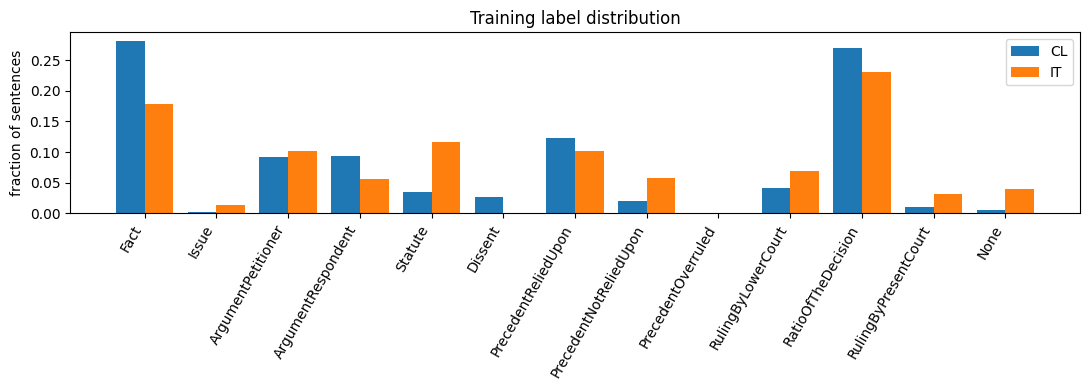

In [52]:
def hf(fn): return hf_hub_download(HF_REPO, fn, repo_type="dataset", token=HF_TOKEN)

lv = json.load(open(hf(f"{P3}/Train/label_vocab.json"), encoding="utf-8"))
if isinstance(lv, dict):
    if "labels" in lv and isinstance(lv["labels"], list): LABELS = lv["labels"]
    elif all(isinstance(v, int) for v in lv.values()):   LABELS = [k for k, _ in sorted(lv.items(), key=lambda kv: kv[1])]
    else: LABELS = list(lv.keys())
else: LABELS = list(lv)
LABELS = [str(x) for x in LABELS]; L2I = {l: i for i, l in enumerate(LABELS)}; NL = len(LABELS)
print(NL, "labels:", LABELS)

# def load_docs(path, domain, labelled=True):
#     raw = json.load(open(path, encoding="utf-8"))
#     items = raw.items() if isinstance(raw, dict) else [(str(d.get("id", i)), d) for i, d in enumerate(raw)]
#     docs = []
#     for k, d in items:
#         s = d["text"]; s = s.split("\n") if isinstance(s, str) else list(s)
#         y = None
#         if labelled and "labels" in d:
#             y = [L2I[str(l)] for l in d["labels"]]; assert len(y) == len(s), (k, len(y), len(s))
#         docs.append(dict(id=str(k), sents=[str(x) for x in s], y=y, domain=domain))
#     return docs

def load_docs(path, domain, labelled=True):
    with open(path, encoding="utf-8") as f:
        raw = json.load(f)

    items = raw.items() if isinstance(raw, dict) else [
        (str(d.get("id", i) if isinstance(d, dict) else i), d)
        for i, d in enumerate(raw)
    ]
    docs = []

    for k, d in items:
        if isinstance(d, dict):
            text_val = next(
                (d[key] for key in ("text", "content", "body", "judgment", "document")
                 if key in d and d[key] is not None),
                ""
            )
            y_raw = d.get("labels") if labelled else None
        else:
            text_val = d
            y_raw = None

        # Preserve an existing list of sentence strings.
        if isinstance(text_val, list):
            s_list = [clean_text(s) for s in text_val]
            s_list = [s for s in s_list if s]
        elif isinstance(text_val, str):
            s = clean_text(text_val)
            s_list = [x.strip() for x in s.split("\n") if x.strip()]
        else:
            raise TypeError(
                f"Unexpected text type for domain={domain}, doc_id={k}: "
                f"{type(text_val).__name__}"
            )

        y = None
        if y_raw is not None:
            if not isinstance(y_raw, list):
                raise TypeError(
                    f"Labels must be a list: domain={domain}, doc_id={k}"
                )
            if len(y_raw) != len(s_list):
                raise ValueError(
                    f"Alignment error: domain={domain}, doc_id={k}, "
                    f"text_type={type(text_val).__name__}, "
                    f"sentences={len(s_list)}, labels={len(y_raw)}"
                )
            unknown = sorted(set(map(str, y_raw)) - set(L2I))
            if unknown:
                raise ValueError(f"Unknown labels in {k}: {unknown}")
            y = [L2I[str(label)] for label in y_raw]

        docs.append(dict(
            id=str(k), sents=s_list, y=y, domain=domain
        ))

    return docs


DATA = {}
for dom in ("CL", "IT"):
    DATA[(dom, "train")] = load_docs(hf(f"{P3}/Train/{dom}_train.json"), dom)
    DATA[(dom, "dev")]   = load_docs(hf(f"{P3}/Train/{dom}_dev.json"), dom)
    DATA[(dom, "test")] = load_docs(hf(f"{P3}/Test/{dom}_test.json"), dom, labelled=False)
    # except Exception as e: print("test file not available for", dom, e); DATA[(dom, "test")] = []
if TRAIN_DOC_LIMIT:
    for dom in ("CL", "IT"): DATA[(dom, "train")] = DATA[(dom, "train")][:TRAIN_DOC_LIMIT]; DATA[(dom, "dev")] = DATA[(dom, "dev")][:max(5, TRAIN_DOC_LIMIT // 3)]

MAX_SENT_TOK = 160
def tokenize_docs(docs):
    for d in tqdm(docs, leave=False):
        d["ids"] = [tokenizer.encode(clean_text(s))[:MAX_SENT_TOK] + [tokenizer.eos_id] for s in d["sents"]]
for k, v in DATA.items(): tokenize_docs(v)

rows = []
for (dom, sp), docs in DATA.items():
    ns = sum(len(d["sents"]) for d in docs); nt = sum(sum(map(len, d["ids"])) for d in docs)
    rows.append(dict(domain=dom, split=sp, docs=len(docs), sents=ns, tokens=nt, tok_per_doc=nt / max(1, len(docs))))
print(pd.DataFrame(rows))
ids_all = [d["id"] for dom in ("CL", "IT") for d in DATA[(dom, "test")]]
print("duplicate test ids across domains:", len(ids_all) - len(set(ids_all)))

# label distribution plot
fig, ax = plt.subplots(figsize=(11, 4)); w = 0.4
for j, dom in enumerate(("CL", "IT")):
    c = Counter(l for d in DATA[(dom, "train")] for l in d["y"]); tot = sum(c.values())
    ax.bar(np.arange(NL) + (j - .5) * w, [c[i] / tot for i in range(NL)], w, label=dom)
ax.set_xticks(range(NL)); ax.set_xticklabels(LABELS, rotation=60, ha="right"); ax.set_ylabel("fraction of sentences"); ax.legend()
ax.set_title("Training label distribution"); plt.tight_layout(); plt.savefig(f"{WORK}/eda_labels.png", dpi=150); plt.show()

In [53]:
# Each chunk = [BOS] + sentences (context-only ones first, then targets). Decoder is causal, so a sentence's
# representation (its </s> token + mean pool) sees all earlier sentences inside the chunk.
CTX = {
    "sentence":   dict(max_len=192,  ctx_prev=0, max_tgt=1,   bs=64, accum=1, head="none"),
    "window3":    dict(max_len=512,  ctx_prev=3, max_tgt=1,   bs=24, accum=2, head="none"),
    "doc":        dict(max_len=1024, ctx_prev=6, max_tgt=999, bs=4,  accum=4, head="none"),
    "doc_bigru":  dict(max_len=1024, ctx_prev=6, max_tgt=999, bs=4,  accum=4, head="bigru"),
}

def make_chunks(docs, ctxc, eff_len, train=False, rng=None):
    out, budget = [], eff_len - 1
    for di, d in enumerate(docs):
        S, n, i, first = d["ids"], len(d["ids"]), 0, True
        while i < n:
            tb = budget * (rng.uniform(0.3, 1.0) if (train and first and ctxc["max_tgt"] > 1) else 1.0)
            j, used = i, 0
            while j < n and (j - i) < ctxc["max_tgt"] and (j == i or used + len(S[j]) <= tb):
                used += len(S[j]); j += 1
            c = i
            while c > 0 and (i - c) < ctxc["ctx_prev"] and used + len(S[c - 1]) <= budget:
                c -= 1; used += len(S[c])
            out.append((di, c, i, j)); i = j; first = False
    return out

def make_item(doc, c, i, j):
    ids, st, en = [tokenizer.bos_id], [], []
    for k in range(c, j):
        st.append(len(ids)); ids += doc["ids"][k]; en.append(len(ids))
    tm = [k >= i for k in range(c, j)]
    lab = [(doc["y"][k] if (doc["y"] is not None and k >= i) else -100) for k in range(c, j)]
    return dict(ids=ids, st=st, en=en, tm=tm, lab=lab, sidx=list(range(c, j)))

def collate(items, dis):
    B, T, S = len(items), max(len(x["ids"]) for x in items), max(len(x["st"]) for x in items)
    ids = torch.full((B, T), tokenizer.pad_id, dtype=torch.long)
    st = torch.zeros(B, S, dtype=torch.long); en = torch.ones(B, S, dtype=torch.long)
    sm = torch.zeros(B, S, dtype=torch.bool); tm = torch.zeros(B, S, dtype=torch.bool); lab = torch.full((B, S), -100, dtype=torch.long)
    for b, x in enumerate(items):
        n, s = len(x["ids"]), len(x["st"])
        ids[b, :n] = torch.tensor(x["ids"]); st[b, :s] = torch.tensor(x["st"]); en[b, :s] = torch.tensor(x["en"])
        sm[b, :s] = True; tm[b, :s] = torch.tensor(x["tm"]); lab[b, :s] = torch.tensor(x["lab"])
    return dict(ids=ids, st=st, en=en, sm=sm, tm=tm, y=lab, doc=dis, sidx=[x["sidx"] for x in items], tml=[x["tm"] for x in items])

def batches(docs, chunks, bs, shuffle=False, rng=None):
    idx = list(range(len(chunks)))
    if shuffle: rng.shuffle(idx)
    for s in range(0, len(idx), bs):
        sel = [chunks[k] for k in idx[s:s + bs]]
        yield collate([make_item(docs[a], c, i, j) for a, c, i, j in sel], [a for a, *_ in sel])

def to_dev(b): return {k: (v.to(DEVICE, non_blocking=True) if torch.is_tensor(v) else v) for k, v in b.items()}

In [54]:
# ---------------- backbone wrapper (replace this class for other Phase-1 architectures) ----------------
# class LMBackbone(nn.Module):
#     def __init__(self, lm):
#         super().__init__(); self.wte, self.blocks, self.ln_f = lm.wte, lm.blocks, lm.ln_f; self.dim = lm.cfg["dim"]
#     def hidden(self, x, gc=False):
#         for b in self.blocks:
#             x = ckpt_util.checkpoint(b.train_fwd, x, use_reentrant=False) if (gc and self.training) else b(x)[0]
#         return self.ln_f(x)

class LMBackbone(nn.Module):
    def __init__(self, lm):
        super().__init__()
        self.wte = lm.wte
        self.blocks = lm.blocks
        # Fix: map model's `norm_f` to backbone's expected `ln_f` attribute name
        self.ln_f = lm.norm_f
        # Ensure cfg exists safely
        if not hasattr(lm, "cfg"):
            lm.cfg = dict(
                vocab_size=lm.wte.num_embeddings,
                dim=lm.wte.embedding_dim,
                layers=len(lm.blocks),
                heads=12,
                kv_heads=6,
                block_size=1024
            )
        self.dim = lm.cfg["dim"]

    def hidden(self, x, gc=False):
        for b in self.blocks:
            x, _ = b(x, None, None, False)
        return self.ln_f(x)

def load_phase1(layers_keep=None, random_init=False):
    ck = torch.load(PHASE1_CKPT, map_location="cpu", weights_only=False)
    cfg = dict(ck["config"]) if "config" in ck else {}
    sd = {k.replace("_orig_mod.", ""): v for k, v in ck["model"].items()}

    if not cfg:
        cfg = dict(vocab_size=tokenizer.vocab_size, dim=768, layers=12, heads=12, kv_heads=6, block_size=1024)

    if layers_keep is None:
        lm = LegalLM(**cfg)
        if not random_init:
            lm.load_state_dict(sd)
    else:
        sub_cfg = dict(cfg, layers=len(layers_keep))
        lm = LegalLM(**sub_cfg)
        new = {}
        for k, v in sd.items():
            m = re.match(r"blocks\.(\d+)\.(.*)", k)
            if m is None:
                new[k] = v
            elif int(m[1]) in layers_keep:
                new[f"blocks.{layers_keep.index(int(m[1]))}.{m[2]}"] = v
        lm.load_state_dict(new, strict=True)

    # Attach config dictionary to the model instance
    lm.cfg = cfg
    return lm

# ---------------- classifier on top of backbone ----------------
class RRModel(nn.Module):
    def __init__(self, bb, n_labels, head="bigru", pool="last_mean", n_prompt=0, drop=0.1):
        super().__init__()
        self.bb, self.pool, D = bb, pool, bb.dim
        pdim = 2 * D if pool == "last_mean" else D
        self.proj = nn.Sequential(nn.LayerNorm(pdim), nn.Dropout(drop), nn.Linear(pdim, D), nn.GELU())
        self.ctx = nn.GRU(D, D // 2, batch_first=True, bidirectional=True) if head == "bigru" else None
        self.cls = nn.Sequential(nn.Dropout(drop), nn.Linear(D, n_labels))
        self.n_prompt = n_prompt
        if n_prompt:
            self.prompt = nn.Parameter(bb.wte.weight[torch.randint(0, bb.wte.weight.size(0), (n_prompt,))].detach().clone())
        self.ada = None; self.gc = False

    def forward(self, ids, st, en, sm):
        emb = self.bb.wte(ids); off = 0
        if self.n_prompt:
            emb = torch.cat([self.prompt.unsqueeze(0).expand(ids.size(0), -1, -1).to(emb.dtype), emb], 1); off = self.n_prompt
        h = self.bb.hidden(emb, self.gc).float()
        B, T, D = h.shape
        cs = F.pad(h.cumsum(1), (0, 0, 1, 0))
        s, e = st + off, en + off
        last = h.gather(1, (e - 1).unsqueeze(-1).expand(-1, -1, D))
        if self.pool == "last": rep = last
        else:
            mean = (cs.gather(1, e.unsqueeze(-1).expand(-1, -1, D)) - cs.gather(1, s.unsqueeze(-1).expand(-1, -1, D))) / (e - s).clamp(min=1).unsqueeze(-1)
            rep = torch.cat([last, mean], -1)
        z = self.proj(rep)
        if self.ctx is not None:
            S = z.size(1)
            pk = nn.utils.rnn.pack_padded_sequence(z.float(), sm.sum(1).cpu(), batch_first=True, enforce_sorted=False)
            o, _ = self.ctx(pk); o, _ = nn.utils.rnn.pad_packed_sequence(o, batch_first=True, total_length=S)
            z = z + o.to(z.dtype)
        return self.cls(z), z

# ---------------- adapters ----------------
class LoRALinear(nn.Module):                      # LoRA / rsLoRA (scale = a/r  vs  a/sqrt(r))
    def __init__(self, base, r=16, alpha=32, dropout=0.05, rs=False):
        super().__init__(); self.base = base
        self.A = nn.Parameter(torch.empty(r, base.in_features)); self.B = nn.Parameter(torch.zeros(base.out_features, r))
        nn.init.kaiming_uniform_(self.A, a=math.sqrt(5)); self.scale = alpha / (math.sqrt(r) if rs else r); self.drop = nn.Dropout(dropout)
    def forward(self, x): return self.base(x) + F.linear(F.linear(self.drop(x), self.A), self.B) * self.scale

class LoRMALinear(nn.Module):                     # multiplicative: W' = (I + B A) W   ->  y = h + B A h, h = W x
    def __init__(self, base, r=16, alpha=16):
        super().__init__(); self.base = base
        self.A = nn.Parameter(torch.empty(r, base.out_features)); self.B = nn.Parameter(torch.zeros(base.out_features, r))
        nn.init.kaiming_uniform_(self.A, a=math.sqrt(5)); self.scale = alpha / r
    def forward(self, x):
        h = self.base(x); return h + F.linear(F.linear(h, self.A), self.B) * self.scale

NF4 = torch.tensor([-1.0, -0.6961928009986877, -0.5250730514526367, -0.39491748809814453, -0.28444138169288635, -0.18477343022823334,
                    -0.09105003625154495, 0.0, 0.07958029955625534, 0.16093020141029358, 0.24611230194568634, 0.33791524171829224,
                    0.44070982933044434, 0.5626170039176941, 0.7229568362236023, 1.0])
class QLoRALinear(nn.Module):                     # frozen NF4 (4-bit, blockwise absmax, packed 2/byte) + LoRA
    def __init__(self, base, r=16, alpha=32, dropout=0.05, bs=64):
        super().__init__(); w = base.weight.data.float().to(DEVICE); self.shape, self.n, self.bs = w.shape, w.numel(), bs
        f = F.pad(w.flatten(), (0, (-w.numel()) % bs)).view(-1, bs); am = f.abs().amax(1, keepdim=True).clamp(min=1e-8); nrm = f / am
        idx = torch.empty(nrm.shape, dtype=torch.uint8, device=w.device); tab = NF4.to(w.device)
        for s in range(0, nrm.size(0), 8192): idx[s:s + 8192] = (nrm[s:s + 8192, :, None] - tab).abs().argmin(-1).to(torch.uint8)
        fl = idx.flatten(); self.register_buffer("packed", ((fl[0::2] << 4) | fl[1::2]).cpu()); self.register_buffer("absmax", am.half().cpu())
        self.in_features, self.out_features = base.in_features, base.out_features
        self.A = nn.Parameter(torch.empty(r, base.in_features)); self.B = nn.Parameter(torch.zeros(base.out_features, r))
        nn.init.kaiming_uniform_(self.A, a=math.sqrt(5)); self.scale = alpha / r; self.drop = nn.Dropout(dropout)
    def deq(self, dtype):
        p = self.packed; i = torch.stack([p >> 4, p & 15], -1).flatten().long()
        w = NF4.to(p.device)[i].view(-1, self.bs) * self.absmax.float(); return w.flatten()[:self.n].view(self.shape).to(dtype)
    def forward(self, x): return F.linear(x, self.deq(x.dtype)) + F.linear(F.linear(self.drop(x), self.A), self.B) * self.scale

class AdaLoRALinear(nn.Module):                   # dW = B diag(E) A, SVD-style, rank pruned by AdaLoRAManager
    def __init__(self, base, r=12, alpha=24, dropout=0.05):
        super().__init__(); self.base = base
        self.A = nn.Parameter(torch.randn(r, base.in_features) * 0.02); self.B = nn.Parameter(torch.randn(base.out_features, r) * 0.02)
        self.E = nn.Parameter(torch.zeros(r)); self.register_buffer("mask", torch.ones(r)); self.scale = alpha / r; self.drop = nn.Dropout(dropout)
    def forward(self, x):
        return self.base(x) + F.linear(F.linear(self.drop(x), self.A) * (self.E * self.mask).to(x.dtype), self.B) * self.scale
    def orth(self):
        I = torch.eye(self.E.numel(), device=self.A.device)
        return ((self.A @ self.A.t() - I) ** 2).sum() + ((self.B.t() @ self.B - I) ** 2).sum()

class AdaLoRAManager:
    def __init__(self, model, total_steps, target_rank=4, beta=0.85, ti=0.1, tf=0.2, dt=10):
        self.mods = [m for m in model.modules() if isinstance(m, AdaLoRALinear)]
        self.T, self.beta, self.ti, self.tf, self.dt = total_steps, beta, ti, tf, dt
        self.b0 = sum(m.E.numel() for m in self.mods); self.bT = target_rank * len(self.mods); self.I, self.U = {}, {}
    def budget(self, t):
        ti, tf = int(self.ti * self.T), int(self.tf * self.T)
        if t < ti: return self.b0
        if t >= self.T - tf: return self.bT
        return int(self.bT + (self.b0 - self.bT) * (1 - (t - ti) / max(1, self.T - tf - ti)) ** 3)
    def orth_loss(self): return sum(m.orth() for m in self.mods)
    @torch.no_grad()
    def update(self, t):
        for k, m in enumerate(self.mods):
            if m.E.grad is None or m.A.grad is None: return
            s = (m.E * m.E.grad).abs() + (m.A * m.A.grad).abs().mean(1) + (m.B * m.B.grad).abs().mean(0)
            if k not in self.I: self.I[k], self.U[k] = s.clone(), torch.zeros_like(s)
            else:
                self.I[k] = self.beta * self.I[k] + (1 - self.beta) * s
                self.U[k] = self.beta * self.U[k] + (1 - self.beta) * (s - self.I[k]).abs()
        if t % self.dt == 0 and len(self.I) == len(self.mods):
            sc = torch.cat([self.I[k] * self.U[k] for k in range(len(self.mods))]); keep = self.budget(t)
            mk = torch.zeros_like(sc); mk[sc.topk(min(keep, sc.numel())).indices] = 1; o = 0
            for m in self.mods:
                r = m.E.numel(); m.mask.copy_(mk[o:o + r]); m.E.mul_(m.mask); o += r
    def active_rank(self): return float(sum(m.mask.sum().item() for m in self.mods) / len(self.mods))

class IA3Linear(nn.Module):                       # learned rescaling vector on output (k,v) or input (FFN hidden)
    def __init__(self, base, where):
        super().__init__(); self.base, self.where = base, where
        self.s = nn.Parameter(torch.ones(base.out_features if where == "out" else base.in_features))
    def forward(self, x): return self.base(x * self.s.to(x.dtype)) if self.where == "in" else self.base(x) * self.s.to(x.dtype)

class PrefixAttn(nn.Module):                      # learned per-layer key/value prefix (shared across heads of a KV group)
    def __init__(self, attn, P):
        super().__init__(); self.attn = attn
        self.pk = nn.Parameter(torch.randn(attn.hk, P, attn.hd)); self.pv = nn.Parameter(torch.randn(attn.hk, P, attn.hd) * 0.1)
    def forward(self, x, mask=None, cache=None, start=0):
        a = self.attn; b, t, _ = x.shape; r = a.h // a.hk
        q = a.q(x).view(b, t, a.h, a.hd).transpose(1, 2)
        k, v = a.kv(x).view(b, t, 2, a.hk, a.hd).permute(2, 0, 3, 1, 4)
        q, k = a.rope(a.qn(q), start), a.rope(a.kn(k), start)
        P = self.pk.size(1)
        k = torch.cat([self.pk.unsqueeze(0).expand(b, -1, -1, -1).to(k.dtype), k], 2)
        v = torch.cat([self.pv.unsqueeze(0).expand(b, -1, -1, -1).to(v.dtype), v], 2)
        k, v = k.repeat_interleave(r, 1), v.repeat_interleave(r, 1)
        m = torch.ones(t, P + t, dtype=torch.bool, device=x.device).tril(diagonal=P)   # prefix visible to all, causal on tokens
        y = F.scaled_dot_product_attention(q, k, v, attn_mask=m)
        return a.o(y.transpose(1, 2).reshape(b, t, a.h * a.hd)), cache

# Corrected targets for ALiBi + GQA LegalLM architecture
TARGETS = ("attn.q", "attn.kv", "attn.proj", "ffn.w1", "ffn.w3", "ffn.w2")

def replace_linears(root, suffixes, factory):
    for name, mod in list(root.named_modules()):
        for cn, ch in list(mod.named_children()):
            full = f"{name}.{cn}" if name else cn
            # Check if any suffix matches the end of the full module path
            if isinstance(ch, nn.Linear) and any(full.endswith(s) for s in suffixes):
                setattr(mod, cn, factory(full, ch))

def apply_method(model, cfg):
    m, bb = cfg["method"], model.bb
    if m != "full":
        for p in bb.parameters(): p.requires_grad = False
    if m in ("lora", "rslora"):
        replace_linears(bb, TARGETS, lambda n, l: LoRALinear(l, cfg["r"], cfg["alpha"], 0.05, rs=(m == "rslora")))
    elif m == "qlora":  replace_linears(bb, TARGETS, lambda n, l: QLoRALinear(l, cfg["r"], cfg["alpha"]))
    elif m == "adalora": replace_linears(bb, TARGETS, lambda n, l: AdaLoRALinear(l, cfg["r"], cfg["alpha"]))
    elif m == "lorma":  replace_linears(bb, TARGETS, lambda n, l: LoRMALinear(l, cfg["r"], cfg["alpha"]))
    elif m == "ia3":
        replace_linears(bb, ("attn.kv",), lambda n, l: IA3Linear(l, "out")); replace_linears(bb, ("ffn.w2",), lambda n, l: IA3Linear(l, "in"))
    elif m == "prefix":
        for blk in bb.blocks: blk.attn = PrefixAttn(blk.attn, cfg["n_prefix"])
    elif m not in ("full", "linear_probe", "prompt"): raise ValueError(m)

def build_model(cfg):
    lm = load_phase1(cfg.get("layers_keep"), cfg.get("random_init", False)); bb = LMBackbone(lm)
    npr = cfg.get("n_prompt", 0) if cfg["method"] == "prompt" else 0
    model = RRModel(bb, NL, head=CTX[cfg["ctx"]]["head"], pool=cfg.get("pool", "last_mean"), n_prompt=npr)
    if cfg["method"] == "prompt":
        for p in bb.parameters(): p.requires_grad = False
    apply_method(model, cfg); model.gc = cfg.get("grad_ckpt", False)
    return model.to(DEVICE)

def model_stats(model):
    tr = sum(p.numel() for p in model.parameters() if p.requires_grad); tot = sum(p.numel() for p in model.parameters())
    mb = (sum(p.numel() * p.element_size() for p in model.parameters()) + sum(b.numel() * b.element_size() for b in model.buffers())) / 2**20
    return tr, tot, mb

In [55]:
RESULTS_PATH, PRED_PATH = f"{WORK}/results.json", f"{WORK}/dev_preds.pkl"
RESULTS = json.load(open(RESULTS_PATH)) if os.path.exists(RESULTS_PATH) else {}
PRED = pickle.load(open(PRED_PATH, "rb")) if os.path.exists(PRED_PATH) else {}
def save_all():
    json.dump(RESULTS, open(RESULTS_PATH, "w"), default=lambda o: o.item() if hasattr(o, "item") else str(o))
    pickle.dump(PRED, open(PRED_PATH, "wb"))

def class_weights(docs):
    c = np.bincount([l for d in docs for l in d["y"]], minlength=NL).astype(np.float64) + 1
    w = (c.sum() / (NL * c)) ** 0.5; return torch.tensor(w / w.mean(), dtype=torch.float32, device=DEVICE)

def rr_loss(logits, y, kind, w):
    m = y != -100; lg, yy = logits[m].float(), y[m]
    if kind == "focal":
        lp = F.log_softmax(lg, -1).gather(1, yy[:, None])[:, 0]; pt = lp.exp()
        return (-(1 - pt) ** 2 * lp * (w[yy] if w is not None else 1.0)).mean()
    return F.cross_entropy(lg, yy, weight=w if kind in ("wce", "focal") else None, label_smoothing=0.0)

def metrics(y, p):
    return dict(f1=f1_score(y, p, average="macro", zero_division=0), P=precision_score(y, p, average="macro", zero_division=0),
                R=recall_score(y, p, average="macro", zero_division=0), acc=accuracy_score(y, p),
                f1_all=f1_score(y, p, average="macro", labels=list(range(NL)), zero_division=0))

@torch.no_grad()
def predict(model, docs, ctxc, eff_len):
    model.eval(); chunks = make_chunks(docs, ctxc, eff_len)
    chunks.sort(key=lambda ch: sum(len(x) for x in docs[ch[0]]["ids"][ch[1]:ch[3]]))
    Lg = [np.zeros((len(d["sents"]), NL), np.float32) for d in docs]
    for b in batches(docs, chunks, ctxc["bs"] * 2):
        bd = to_dev(b)
        with torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=USE_AMP):
            lg, _ = model(bd["ids"], bd["st"], bd["en"], bd["sm"])
        lg = lg.float().cpu().numpy()
        for r, (di, sidx, tml) in enumerate(zip(b["doc"], b["sidx"], b["tml"])):
            for q, (k, t) in enumerate(zip(sidx, tml)):
                if t: Lg[di][k] = lg[r, q]
    return [l.argmax(1) for l in Lg], Lg

def eval_domains(model, dev_sets, ctxc, eff_len, doms):
    out = {}
    for dom in doms:
        P, _ = predict(model, dev_sets[dom], ctxc, eff_len)
        out[dom] = metrics(np.concatenate([d["y"] for d in dev_sets[dom]]), np.concatenate(P))
    return out

def load_teacher(tname):
    tc = RESULTS[tname]["cfg"]; t = build_model(tc); t.load_state_dict(torch.load(f"{CK}/{tname}.pt", map_location=DEVICE)); t.eval()
    for p in t.parameters(): p.requires_grad = False
    return t

def train_run(cfg):
    name = cfg["name"]
    if name in RESULTS: print("skip (done):", name); return RESULTS[name]
    print(f"\n=== {name} | {cfg['method']} | ctx={cfg['ctx']} | train={cfg['train_domains']} | loss={cfg['loss']} ===")
    set_seed(cfg.get("seed", SEED)); rng = random.Random(cfg.get("seed", SEED))
    ctxc = CTX[cfg["ctx"]]; eff_len = ctxc["max_len"] - (cfg.get("n_prompt", 0) if cfg["method"] == "prompt" else 0)
    train_docs = [d for dom in cfg["train_domains"] for d in DATA[(dom, "train")]]
    dev_sets = {dom: DATA[(dom, "dev")] for dom in ("CL", "IT")}
    model = build_model(cfg); tr, tot, mb = model_stats(model)
    print(f"params trainable {tr/1e6:.2f}M / total {tot/1e6:.1f}M | size {mb:.0f} MB")
    w = class_weights(train_docs) if cfg["loss"] in ("wce", "focal") else None
    teacher = load_teacher(cfg["kd"]["teacher"]) if cfg.get("kd") else None

    groups = {"bb": [], "head": []}
    for n, p in model.named_parameters():
        if p.requires_grad: groups["bb" if n.startswith("bb.") or n == "prompt" else "head"].append(p)
    opt = torch.optim.AdamW([dict(params=groups["bb"], lr=cfg["lr"], base=cfg["lr"]),
                             dict(params=groups["head"], lr=cfg["head_lr"], base=cfg["head_lr"])], weight_decay=0.01, betas=(0.9, 0.98))
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP and AMP_DTYPE == torch.float16)
    n_chunks = len(make_chunks(train_docs, ctxc, eff_len)); spe = max(1, math.ceil(n_chunks / (ctxc["bs"] * ctxc["accum"])))
    total = cfg["epochs"] * spe; warm = max(1, int(0.06 * total))
    if cfg["method"] == "adalora": model.ada = AdaLoRAManager(model, total, cfg.get("target_rank", 4))
    track = {n for n, p in model.named_parameters() if p.requires_grad} | {n for n, _ in model.named_buffers() if n.endswith(".mask")}
    sel_doms = cfg["train_domains"]; best, best_state, bad, hist, step, t0 = -1, None, 0, [], 0, time.time()
    # 2. Setup resume variables
    start_ep = 0
    best = -1
    best_state = None
    bad = 0
    hist = []
    step = 0
    # Resume from checkpoint if it exists
    ckpt_file = f"{CK}/{name}_ckpt.pt"
    if os.path.exists(ckpt_file):
        print(f"Resuming checkpoint from {ckpt_file}")
        checkpoint = torch.load(ckpt_file, map_location=DEVICE)
        model.load_state_dict(checkpoint["model_state"], strict=False)
        opt.load_state_dict(checkpoint["optimizer_state"])
        if "scaler_state" in checkpoint and checkpoint["scaler_state"] is not None:
            scaler.load_state_dict(checkpoint["scaler_state"])
        start_ep = checkpoint["epoch"] + 1
        best = checkpoint["best"]
        best_state = checkpoint["best_state"]
        bad = checkpoint["bad"]
        hist = checkpoint["hist"]
        step = checkpoint["step"]
    for ep in range(start_ep, cfg["epochs"]):
        model.train(); chunks = make_chunks(train_docs, ctxc, eff_len, train=True, rng=rng); run_loss, nb = 0.0, 0
        opt.zero_grad(set_to_none=True)
        pbar = tqdm(batches(train_docs, chunks, ctxc["bs"], True, rng), total=math.ceil(len(chunks) / ctxc["bs"]), desc=f"ep{ep+1}", leave=False)
        for mi, b in enumerate(pbar):
            bd = to_dev(b)
            with torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=USE_AMP):
                lg, z = model(bd["ids"], bd["st"], bd["en"], bd["sm"])
                loss = rr_loss(lg, bd["y"], cfg["loss"], w)
                if teacher is not None:
                    with torch.no_grad(): tl, tz = teacher(bd["ids"], bd["st"], bd["en"], bd["sm"])
                    m = bd["y"] != -100; T = cfg["kd"]["T"]
                    kd = F.kl_div(F.log_softmax(lg[m].float() / T, -1), F.softmax(tl[m].float() / T, -1), reduction="batchmean") * T * T
                    loss = cfg["kd"]["alpha"] * loss + (1 - cfg["kd"]["alpha"]) * kd
                    if cfg["kd"].get("beta", 0) > 0: loss = loss + cfg["kd"]["beta"] * (1 - F.cosine_similarity(z[m].float(), tz[m].float(), dim=-1)).mean()
                if model.ada is not None: loss = loss + 0.1 * model.ada.orth_loss()
            scaler.scale(loss / ctxc["accum"]).backward(); run_loss += loss.item(); nb += 1
            if (mi + 1) % ctxc["accum"] == 0:
                lr_f = (step + 1) / warm if step < warm else 0.5 * (1 + math.cos(math.pi * (step - warm) / max(1, total - warm)))
                for g in opt.param_groups: g["lr"] = g["base"] * max(lr_f, 0.02)
                scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_([p for g in groups.values() for p in g], 1.0)
                if model.ada is not None: model.ada.update(step)
                scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True); step += 1
            if (time.time() - t0) / 60 > MAX_MIN_PER_RUN: break
        dm = eval_domains(model, dev_sets, ctxc, eff_len, sel_doms); score = float(np.mean([dm[d]["f1"] for d in sel_doms]))
        hist.append(dict(epoch=ep + 1, loss=run_loss / max(1, nb), **{f"f1_{d}": dm[d]["f1"] for d in sel_doms}, score=score))
        print(f"ep{ep+1} loss {run_loss/max(1,nb):.4f} | dev macro-F1 " + " ".join(f"{d}:{dm[d]['f1']:.4f}" for d in sel_doms) + f" | {(time.time()-t0)/60:.1f} min")
        if score > best: best, bad, best_state = score, 0, {k: v.detach().cpu().clone() for k, v in model.state_dict().items() if k in track}
        else:
            bad += 1
            if bad >= cfg.get("patience", 3): break
        # 3. Save lightweight epoch checkpoint to keep storage footprint minimal
        torch.save({
            "epoch": ep,
            "step": step,
            "best": best,
            "bad": bad,
            "hist": hist,
            "model_state": {k: v.cpu() for k, v in model.state_dict().items() if k in track},
            "optimizer_state": opt.state_dict(),
            "scaler_state": scaler.state_dict() if USE_AMP else None,
            "best_state": best_state
        }, ckpt_file)
        if (time.time() - t0) / 60 > MAX_MIN_PER_RUN: print("time cap reached"); break
    train_min = (time.time() - t0) / 60
    model.load_state_dict(best_state, strict=False)
    if cfg.get("save_ckpt"): torch.save({k: v.cpu() for k, v in model.state_dict().items()}, f"{CK}/{name}.pt")

    # final evaluation on both dev domains (+ timing), test prediction
    res = dict(name=name, group=cfg["group"], cfg=cfg, trainable=tr, total=tot, size_mb=mb, train_min=train_min, hist=hist, dev={}, perclass={}, conf={})
    PRED[name] = {}; t1 = time.time(); nsent = 0
    for dom in ("CL", "IT"):
        P, Lg = predict(model, dev_sets[dom], ctxc, eff_len); y, p = np.concatenate([d["y"] for d in dev_sets[dom]]), np.concatenate(P); nsent += len(y)
        res["dev"][dom] = metrics(y, p); res["perclass"][dom] = f1_score(y, p, average=None, labels=list(range(NL)), zero_division=0).tolist()
        res["conf"][dom] = confusion_matrix(y, p, labels=list(range(NL))).tolist(); PRED[name][dom] = dict(y=y, p=p, logits=np.concatenate(Lg))
    res["infer_s_per_1k"] = (time.time() - t1) / nsent * 1000
    res["f1_CL"], res["f1_IT"] = res["dev"]["CL"]["f1"], res["dev"]["IT"]["f1"]; res["f1_mean"] = (res["f1_CL"] + res["f1_IT"]) / 2
    if model.ada is not None: res["active_rank"] = model.ada.active_rank()
    for dom in ("CL", "IT"):
        td = DATA[(dom, "test")]
        if td:
            P, _ = predict(model, td, ctxc, eff_len)
            json.dump({d["id"]: [LABELS[i] for i in p] for d, p in zip(td, P)}, open(f"{PRED_DIR}/{name}_{dom}.json", "w"))
    RESULTS[name] = res; save_all()
    print(f"-> {name}: CL {res['f1_CL']:.4f} | IT {res['f1_IT']:.4f} | mean {res['f1_mean']:.4f} | {train_min:.1f} min | {res['infer_s_per_1k']:.2f}s/1k sents")
    del model, opt, teacher; gc.collect(); torch.cuda.empty_cache()
    return res

In [56]:
BASE = dict(ctx="doc_bigru", loss="wce", train_domains=["CL", "IT"], epochs=8, patience=3, head_lr=1e-3, lr=5e-4, seed=SEED)
METHOD_HP = {
    "linear_probe": dict(head_lr=2e-3),
    "full":    dict(lr=1e-4, epochs=6),
    "lora":    dict(r=16, alpha=32, lr=5e-4),
    "rslora":  dict(r=64, alpha=16, lr=5e-4),            # scale alpha/sqrt(r)
    "qlora":   dict(r=16, alpha=32, lr=5e-4),
    "adalora": dict(r=12, alpha=24, target_rank=4, lr=1e-3),
    "lorma":   dict(r=16, alpha=16, lr=5e-4),
    "ia3":     dict(lr=3e-3),
    "prefix":  dict(n_prefix=32, lr=5e-3),
    "prompt":  dict(n_prompt=32, lr=3e-3),
}
def C(name, group, method="lora", **kw):
    c = dict(BASE); c.update(METHOD_HP.get(method, {})); c.update(name=name, group=group, method=method); c.update(kw); return c
def best_of(prefix, key="f1_mean"):
    c = {k: v for k, v in RESULTS.items() if k.startswith(prefix)}; return max(c, key=lambda k: c[k][key]) if c else None

# ---- Group 1: how much context helps (LoRA fixed) ----
# for ctx in ["sentence", "window3", "doc", "doc_bigru"]: train_run(C(f"ctx_{ctx}", "context", "lora", ctx=ctx, epochs=4))
for ctx in ["doc_bigru"]: train_run(C(f"ctx_{ctx}", "context", "lora", ctx=ctx, epochs=4))
BEST_CTX = RESULTS[best_of("ctx_")]["cfg"]["ctx"]; print("\nBEST CONTEXT MODE:", BEST_CTX)

# ---- Group 2: fine-tuning / PEFT techniques (all with BEST_CTX) ----
# for m in ["linear_probe", "full", "lora", "rslora", "qlora", "adalora", "lorma", "ia3", "prefix", "prompt"]:
#     train_run(C(f"m_{m}", "method", m, ctx=BEST_CTX, save_ckpt=(m == "full"), epochs=4))
for m in ["full", "lora", "rslora", "qlora", "lorma"]:
    train_run(C(f"m_{m}", "method", m, ctx=BEST_CTX, save_ckpt=(m == "full"), epochs=(6 if m == "full" else 4)))

skip (done): ctx_doc_bigru

BEST CONTEXT MODE: doc_bigru
skip (done): m_full
skip (done): m_lora
skip (done): m_rslora
skip (done): m_qlora
skip (done): m_lorma


In [57]:
# ---- Group 6: knowledge distillation ----
# Teacher = full FT of the 8-layer Phase-1 model (m_full). Student = 4 layers initialised from Phase-1 layers {0,2,5,7}.
STUDENT = dict(layers_keep=[0, 2, 5, 7], lr=2e-4, epochs=4)
# train_run(C("kd_student_ce", "kd", "full", ctx=BEST_CTX, **STUDENT))                                   # no-KD baseline
train_run(C("kd_student_logits", "kd", "full", ctx=BEST_CTX, kd=dict(teacher="m_full", T=2.0, alpha=0.3, beta=0.0), **STUDENT))
# train_run(C("kd_student_logits_rep", "kd", "full", ctx=BEST_CTX, kd=dict(teacher="m_full", T=2.0, alpha=0.3, beta=0.5), **STUDENT))

skip (done): kd_student_logits


{'name': 'kd_student_logits',
 'group': 'kd',
 'cfg': {'ctx': 'doc_bigru',
  'loss': 'wce',
  'train_domains': ['CL', 'IT'],
  'epochs': 4,
  'patience': 3,
  'head_lr': 0.001,
  'lr': 0.0002,
  'seed': 42,
  'name': 'kd_student_logits',
  'group': 'kd',
  'method': 'full',
  'kd': {'teacher': 'm_full', 'T': 2.0, 'alpha': 0.3, 'beta': 0.0},
  'layers_keep': [0, 2, 5, 7]},
 'trainable': 54387469,
 'total': 54387469,
 'size_mb': 207.47172927856445,
 'train_min': 10.6074729681015,
 'hist': [{'epoch': 1,
   'loss': 1.6078701125037285,
   'f1_CL': 0.2497788394088555,
   'f1_IT': 0.2053870170383126,
   'score': 0.22758292822358406},
  {'epoch': 2,
   'loss': 1.050037428256004,
   'f1_CL': 0.32878158568229654,
   'f1_IT': 0.21261738354064902,
   'score': 0.27069948461147275},
  {'epoch': 3,
   'loss': 0.657448334307284,
   'f1_CL': 0.41577725975635793,
   'f1_IT': 0.275360442260598,
   'score': 0.345568851008478},
  {'epoch': 4,
   'loss': 0.4996830836341188,
   'f1_CL': 0.35598541490609076,


             name   group method       ctx loss train  trainable_M  total_M  size_MB  train_min  infer_s_per_1k  F1_CL  F1_IT  F1_mean  P_mean  R_mean
    ctx_doc_bigru context   lora doc_bigru  wce CL,IT       4.7370 107.1890 408.8936    11.7948          4.2262 0.3401 0.2971   0.3186  0.3490  0.3486
kd_student_logits      kd   full doc_bigru  wce CL,IT      54.3875  54.3875 207.4717    10.6075          1.3817 0.4158 0.2754   0.3456  0.4051  0.3593
          m_qlora  method  qlora doc_bigru  wce CL,IT       4.7370  85.9553 338.6514    11.8582          4.2375 0.3671 0.3213   0.3442  0.3704  0.3735
           m_full  method   full doc_bigru  wce CL,IT     106.3043 106.3043 405.5186    24.1188          4.0333 0.3669 0.3212   0.3440  0.3926  0.3641
         m_rslora  method rslora doc_bigru  wce CL,IT       7.3912 109.8432 419.0186    11.9291          4.2640 0.3861 0.2522   0.3192  0.3698  0.3429
           m_lora  method   lora doc_bigru  wce CL,IT       4.7370 107.1890 408.8936    11.809

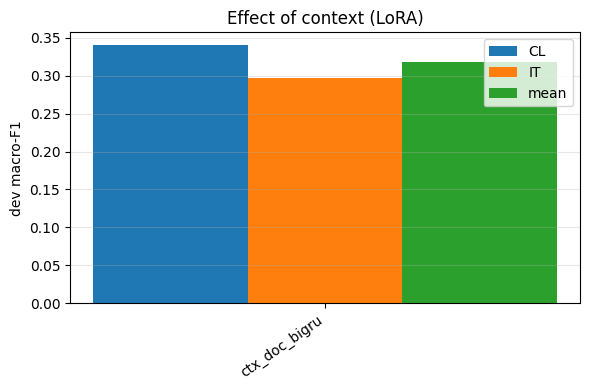

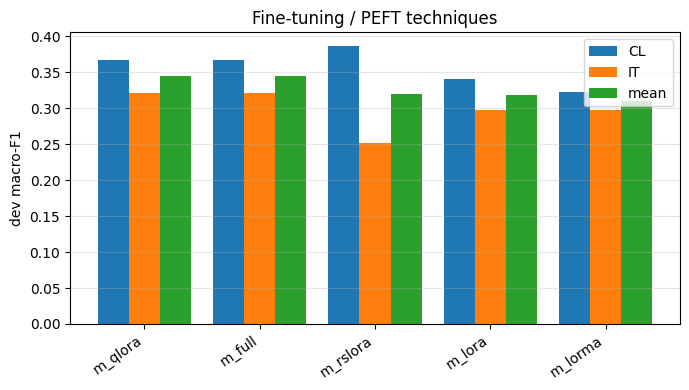

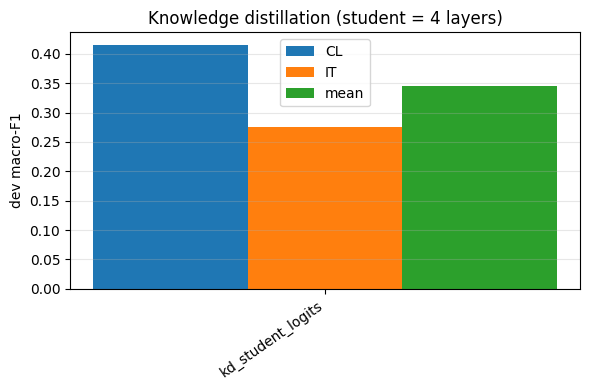

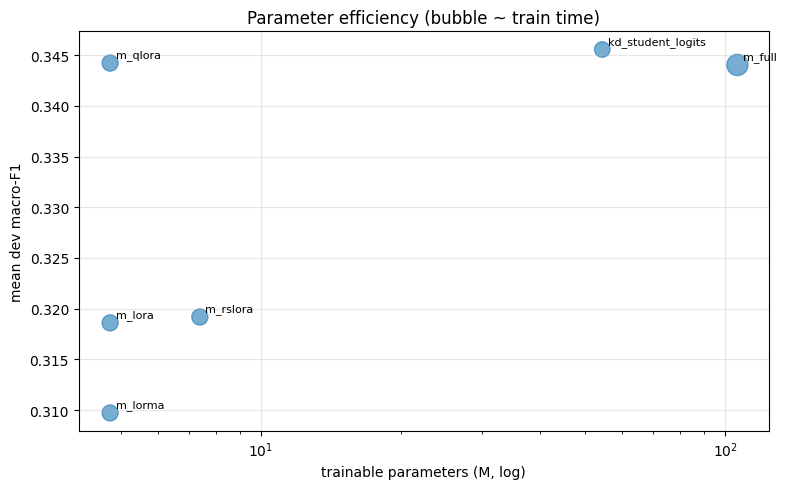

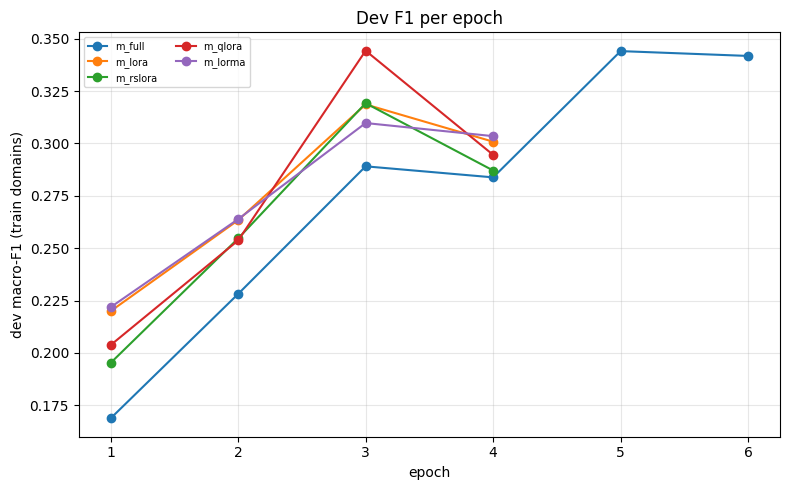

             name  total_M  size_MB  infer_s_per_1k  F1_CL  F1_IT  F1_mean
           m_full 106.3043 405.5186          4.0333 0.3669 0.3212   0.3440
kd_student_logits  54.3875 207.4717          1.3817 0.4158 0.2754   0.3456


In [58]:
def results_df():
    rows = []
    for n, r in RESULTS.items():
        c = r["cfg"]; rows.append(dict(name=n, group=r["group"], method=c["method"], ctx=c["ctx"], loss=c["loss"], train=",".join(c["train_domains"]),
            trainable_M=r["trainable"] / 1e6, total_M=r["total"] / 1e6, size_MB=r["size_mb"], train_min=r["train_min"], infer_s_per_1k=r["infer_s_per_1k"],
            F1_CL=r["f1_CL"], F1_IT=r["f1_IT"], F1_mean=r["f1_mean"],
            P_mean=(r["dev"]["CL"]["P"] + r["dev"]["IT"]["P"]) / 2, R_mean=(r["dev"]["CL"]["R"] + r["dev"]["IT"]["R"]) / 2))
    return pd.DataFrame(rows)
df = results_df(); pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)
print(df.sort_values(["group", "F1_mean"], ascending=[True, False]).round(4).to_string(index=False))
df.to_csv(f"{WORK}/summary.csv", index=False)

def bar_group(g, key="name", title=None, fn=None):
    d = df[df.group == g].sort_values("F1_mean", ascending=False)
    if g == "method" and "ctx_" + BEST_CTX in RESULTS: pass
    x = np.arange(len(d)); fig, ax = plt.subplots(figsize=(max(6, 1.0 * len(d) + 2), 4))
    ax.bar(x - .27, d.F1_CL, .27, label="CL"); ax.bar(x, d.F1_IT, .27, label="IT"); ax.bar(x + .27, d.F1_mean, .27, label="mean")
    ax.set_xticks(x); ax.set_xticklabels(d[key], rotation=35, ha="right"); ax.set_ylabel("dev macro-F1"); ax.set_title(title or g); ax.legend(); ax.grid(axis="y", alpha=.3)
    plt.tight_layout(); plt.savefig(f"{WORK}/{fn or g}.png", dpi=150); plt.show()

for g, t in [("context", "Effect of context (LoRA)"), ("method", "Fine-tuning / PEFT techniques"), ("loss", "Class-balancing strategy (LoRA)"),
             ("phase1", "Phase-1 pretrained vs random init"), ("kd", "Knowledge distillation (student = 4 layers)")]:
    if (df.group == g).any(): bar_group(g, title=t)

# efficiency: trainable params vs F1 (bubble = train minutes)
d = df[df.group.isin(["method", "kd"])]
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(d.trainable_M, d.F1_mean, s=40 + 8 * d.train_min, alpha=.6)
for _, r in d.iterrows(): ax.annotate(r["name"], (r.trainable_M, r.F1_mean), fontsize=8, xytext=(4, 4), textcoords="offset points")
ax.set_xscale("log"); ax.set_xlabel("trainable parameters (M, log)"); ax.set_ylabel("mean dev macro-F1"); ax.set_title("Parameter efficiency (bubble ~ train time)"); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(f"{WORK}/efficiency.png", dpi=150); plt.show()

# training curves
fig, ax = plt.subplots(figsize=(8, 5))
for n, r in RESULTS.items():
    if r["group"] == "method": ax.plot([h["epoch"] for h in r["hist"]], [h["score"] for h in r["hist"]], marker="o", label=n)
ax.set_xlabel("epoch"); ax.set_ylabel("dev macro-F1 (train domains)"); ax.legend(fontsize=7, ncol=2); ax.grid(alpha=.3); ax.set_title("Dev F1 per epoch")
plt.tight_layout(); plt.savefig(f"{WORK}/curves.png", dpi=150); plt.show()

# domain transfer matrix (rows = trained on, cols = evaluated on)
dm = {"CL-only": "dom_CL", "IT-only": "dom_IT", "joint": "m_lora"}
if all(v in RESULTS for v in dm.values()):
    M = np.array([[RESULTS[v]["f1_CL"], RESULTS[v]["f1_IT"]] for v in dm.values()])
    fig, ax = plt.subplots(figsize=(4.5, 3.5)); im = ax.imshow(M, cmap="viridis")
    ax.set_xticks([0, 1]); ax.set_xticklabels(["eval CL", "eval IT"]); ax.set_yticks(range(3)); ax.set_yticklabels(dm.keys())
    for i in range(3):
        for j in range(2): ax.text(j, i, f"{M[i,j]:.3f}", ha="center", va="center", color="w")
    ax.set_title("Domain transfer (macro-F1)"); plt.tight_layout(); plt.savefig(f"{WORK}/domain_matrix.png", dpi=150); plt.show()

# KD summary: size / latency / F1
k = df[df.name.isin(["m_full", "kd_student_ce", "kd_student_logits", "kd_student_logits_rep"])]
print(k[["name", "total_M", "size_MB", "infer_s_per_1k", "F1_CL", "F1_IT", "F1_mean"]].round(4).to_string(index=False))

best experiment: kd_student_logits


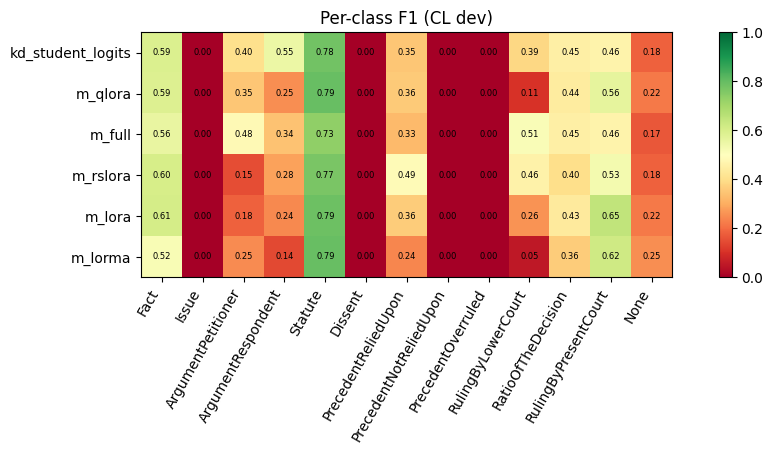

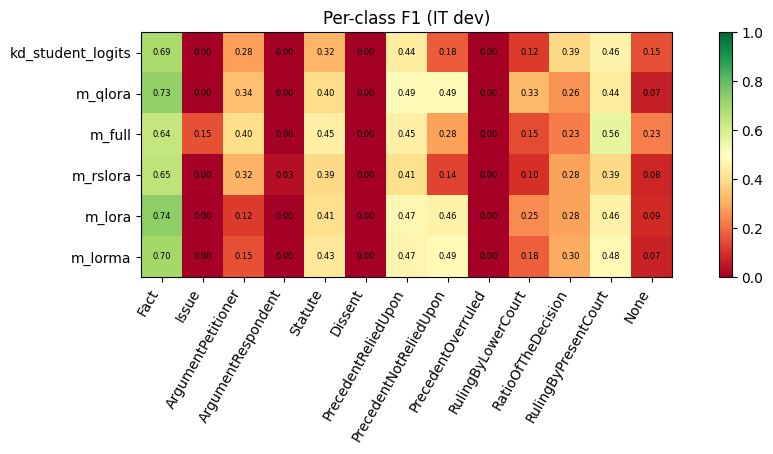

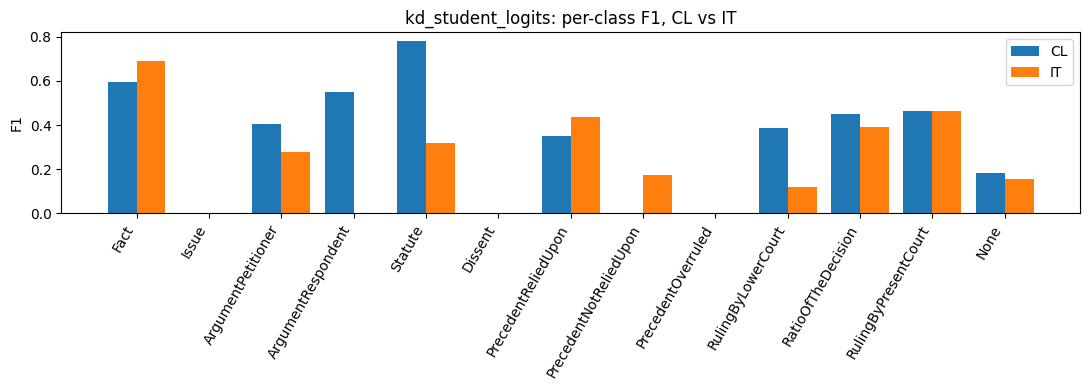

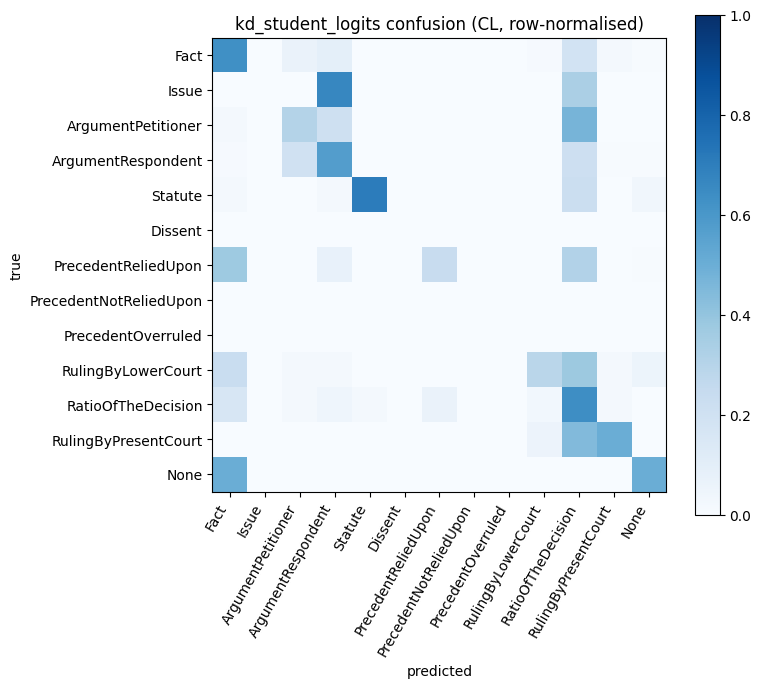


Top confusions [CL] (true -> pred):
               true               pred  count  row_frac
 ArgumentPetitioner RatioOfTheDecision    162     0.471
 ArgumentPetitioner ArgumentRespondent     71     0.206
PrecedentReliedUpon               Fact     53     0.373
 ArgumentRespondent RatioOfTheDecision     50     0.212
 ArgumentRespondent ArgumentPetitioner     47     0.199
 RatioOfTheDecision               Fact     47     0.163
               Fact RatioOfTheDecision     46     0.185
PrecedentReliedUpon RatioOfTheDecision     44     0.310
               Fact ArgumentRespondent     23     0.092
 RulingByLowerCourt RatioOfTheDecision     21     0.375


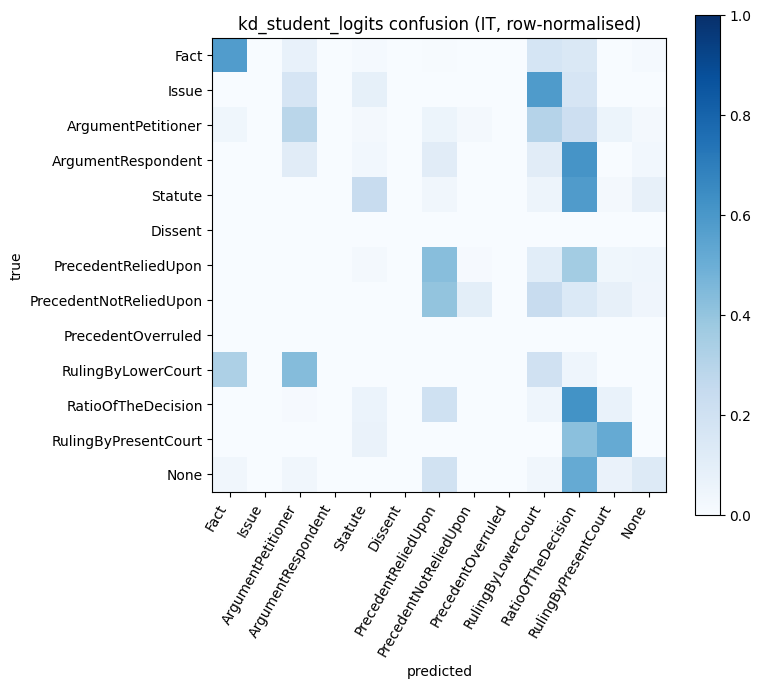


Top confusions [IT] (true -> pred):
                  true                pred  count  row_frac
   PrecedentReliedUpon  RatioOfTheDecision     40     0.357
               Statute  RatioOfTheDecision     36     0.581
                  Fact  RulingByLowerCourt     33     0.169
                  Fact  RatioOfTheDecision     28     0.144
    RatioOfTheDecision PrecedentReliedUpon     23     0.200
    ArgumentRespondent  RatioOfTheDecision     22     0.611
PrecedentNotReliedUpon PrecedentReliedUpon     20     0.400
    RulingByLowerCourt  ArgumentPetitioner     20     0.435
    ArgumentPetitioner  RulingByLowerCourt     17     0.304
                  None  RatioOfTheDecision     16     0.516

[CL] within-group confusion share (errors that stay inside the related group):
  Precedent*         errors from these classes:   108 | of which stay in-group: 0.00%
  Arguments          errors from these classes:   340 | of which stay in-group: 34.71%
  Reasoning/Ruling   errors from these classes:   

In [59]:
def best_name(groups=("method", "kd", "loss", "domain", "context")):
    d = df[df.group.isin(groups)]; return d.loc[d.F1_mean.idxmax(), "name"]
BEST = best_name(); print("best experiment:", BEST)

# per-class F1 heatmap, one per domain, across method-group experiments
for dom in ("CL", "IT"):
    names = [n for n in df[df.group.isin(["method", "kd"])].sort_values("F1_mean", ascending=False).name]
    M = np.array([RESULTS[n]["perclass"][dom] for n in names])
    fig, ax = plt.subplots(figsize=(11, 0.4 * len(names) + 2)); im = ax.imshow(M, vmin=0, vmax=1, cmap="RdYlGn")
    ax.set_xticks(range(NL)); ax.set_xticklabels(LABELS, rotation=60, ha="right"); ax.set_yticks(range(len(names))); ax.set_yticklabels(names)
    for i in range(M.shape[0]):
        for j in range(NL): ax.text(j, i, f"{M[i,j]:.2f}", ha="center", va="center", fontsize=6)
    ax.set_title(f"Per-class F1 ({dom} dev)"); plt.colorbar(im); plt.tight_layout(); plt.savefig(f"{WORK}/perclass_{dom}.png", dpi=150); plt.show()

# CL vs IT per-class for the best model
fig, ax = plt.subplots(figsize=(11, 4)); w = .4
for j, dom in enumerate(("CL", "IT")): ax.bar(np.arange(NL) + (j - .5) * w, RESULTS[BEST]["perclass"][dom], w, label=dom)
ax.set_xticks(range(NL)); ax.set_xticklabels(LABELS, rotation=60, ha="right"); ax.set_ylabel("F1"); ax.legend(); ax.set_title(f"{BEST}: per-class F1, CL vs IT")
plt.tight_layout(); plt.savefig(f"{WORK}/best_perclass_cl_it.png", dpi=150); plt.show()

# normalised confusion matrices + top confused pairs
for dom in ("CL", "IT"):
    C_ = np.array(RESULTS[BEST]["conf"][dom], float); Cn = C_ / np.maximum(C_.sum(1, keepdims=True), 1)
    fig, ax = plt.subplots(figsize=(8, 7)); im = ax.imshow(Cn, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(NL)); ax.set_xticklabels(LABELS, rotation=60, ha="right"); ax.set_yticks(range(NL)); ax.set_yticklabels(LABELS)
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(f"{BEST} confusion ({dom}, row-normalised)"); plt.colorbar(im)
    plt.tight_layout(); plt.savefig(f"{WORK}/confusion_{dom}.png", dpi=150); plt.show()
    off = [(LABELS[i], LABELS[j], int(C_[i, j]), Cn[i, j]) for i in range(NL) for j in range(NL) if i != j and C_[i, j] > 0]
    print(f"\nTop confusions [{dom}] (true -> pred):")
    print(pd.DataFrame(sorted(off, key=lambda t: -t[2])[:10], columns=["true", "pred", "count", "row_frac"]).round(3).to_string(index=False))

# related-role groups: accuracy inside the group vs leakage within the group
GROUPS = {"Precedent*": ["PrecedentReliedUpon", "PrecedentNotReliedUpon", "PrecedentOverruled"],
          "Arguments": ["ArgumentPetitioner", "ArgumentRespondent"],
          "Reasoning/Ruling": ["RatioOfTheDecision", "RulingByPresentCourt", "RulingByLowerCourt"]}
for dom in ("CL", "IT"):
    C_ = np.array(RESULTS[BEST]["conf"][dom]); print(f"\n[{dom}] within-group confusion share (errors that stay inside the related group):")
    for g, ls in GROUPS.items():
        ix = [L2I[l] for l in ls if l in L2I]
        if len(ix) < 2: continue
        err = C_[ix].sum() - np.trace(C_[np.ix_(ix, ix)]); inside = C_[np.ix_(ix, ix)].sum() - np.trace(C_[np.ix_(ix, ix)])
        print(f"  {g:18s} errors from these classes: {int(err):5d} | of which stay in-group: {inside/max(err,1):.2%}")

In [60]:
# Pick the 4 best experiments with different techniques; make sure the KD student is included. Override SUBMIT manually if you like.
cand = df[df.group.isin(["method", "kd"])].sort_values("F1_mean", ascending=False)
SUBMIT, seen = [], set()
# kd_best = cand[cand.group == "kd"].name.tolist()[:1]
# for _, r in cand.iterrows():
#     tech = "kd" if r.group == "kd" else r.method
#     if tech in seen or r.method == "linear_probe": continue
#     seen.add(tech); SUBMIT.append(r["name"])
#     if len(SUBMIT) == 4: break
# if kd_best and kd_best[0] not in SUBMIT: SUBMIT[-1] = kd_best[0]
SUBMIT = list(RESULTS.keys())
print("all submissions:", SUBMIT)

for n in SUBMIT:
    out, ok = {}, True
    for dom in ("CL", "IT"):
        f = f"{PRED_DIR}/{n}_{dom}.json"
        if not os.path.exists(f): print("missing test preds for", n, dom); ok = False; continue
        p = json.load(open(f))
        for d in DATA[(dom, "test")]:
            assert len(p[d["id"]]) == len(d["sents"]) and all(l in L2I for l in p[d["id"]]), d["id"]
        out.update(p)
    if not ok: continue
    sub_dir = f"{WORK}/submission_{n}"; os.makedirs(sub_dir, exist_ok=True)
    json.dump(out, open(f"{sub_dir}/prediction.json", "w"), ensure_ascii=False, indent=1)
    with zipfile.ZipFile(f"{sub_dir}/submission.zip", "w", zipfile.ZIP_DEFLATED) as z: z.write(f"{sub_dir}/prediction.json", arcname="prediction.json")
    print("wrote", sub_dir, "|", len(out), "docs")

all submissions: ['ctx_doc_bigru', 'm_full', 'm_lora', 'm_rslora', 'm_qlora', 'm_lorma', 'kd_student_logits']
wrote /kaggle/working/phase3-alibi-gqa/submission_ctx_doc_bigru | 10 docs
wrote /kaggle/working/phase3-alibi-gqa/submission_m_full | 10 docs
wrote /kaggle/working/phase3-alibi-gqa/submission_m_lora | 10 docs
wrote /kaggle/working/phase3-alibi-gqa/submission_m_rslora | 10 docs
wrote /kaggle/working/phase3-alibi-gqa/submission_m_qlora | 10 docs
wrote /kaggle/working/phase3-alibi-gqa/submission_m_lorma | 10 docs
wrote /kaggle/working/phase3-alibi-gqa/submission_kd_student_logits | 10 docs


In [61]:
# ═══ PHASE 3 – bundle everything (weights, resume ckpts, results, preds, submissions, plots) ═══
import zipfile
import os
import shutil
# !ls lner_runs/checkpoints
# ═══ PHASE 2 – bundle everything (ckpts, results, probs, submissions) ═══
P2_OUT = "/kaggle/working/phase3/"
P2_BUNDLE = f"{P2_OUT}/phase3_bundle.zip"
with zipfile.ZipFile(P2_BUNDLE, "w", zipfile.ZIP_DEFLATED) as z:
    for root, _, files in os.walk(P2_OUT):
        for f in files:
            if f == os.path.basename(P2_BUNDLE):
                continue
            p = os.path.join(root, f)
            z.write(p, arcname=os.path.relpath(p, P2_OUT))
print(f"wrote {P2_BUNDLE} ({os.path.getsize(P2_BUNDLE)/2**30:.2f} GB)")

wrote /kaggle/working/phase3//phase3_bundle.zip (0.00 GB)


---
## Architecture: `gqa_conv`

Source: `legal-gqa-conv.ipynb`


In [62]:
# ── Activate backbone: gqa_conv ──────────────────────────────────────────────
BACKBONE = "gqa_conv"
TOKENIZER_PATH = TOK_PATHS["gqa_conv"]
PHASE1_CKPT = CKPTS["gqa_conv"]
MODEL_PATH = PHASE1_CKPT
CKPT_PATH = PHASE1_CKPT
if "OUT_DIR" not in dir() or not OUT_DIR:
    OUT_DIR = "/kaggle/working/cs781_phase1" if os.path.isdir("/kaggle/working") else "./cs781_phase1"
DATA_DIR = os.path.join(OUT_DIR, "data")
os.makedirs(DATA_DIR, exist_ok=True)
print(f"[active] BACKBONE={BACKBONE}")
print(f"[active] TOKENIZER_PATH={TOKENIZER_PATH}  exists={os.path.exists(TOKENIZER_PATH)}")
print(f"[active] PHASE1_CKPT={PHASE1_CKPT}  exists={os.path.exists(PHASE1_CKPT)}")


[active] BACKBONE=gqa_conv
[active] TOKENIZER_PATH=/kaggle/working/cs781_phase1/legal_bpe_gqa_conv.json  exists=True
[active] PHASE1_CKPT=/kaggle/working/cs781_phase1/latest_checkpoint_gqa_conv.pt  exists=True


### Phase-1 classes for `gqa_conv` (tokenizer + model, needed to reload checkpoints)

These cells are taken from Phase 1 of the same source notebook. They define `BPETokenizer`,
the model stack (`LegalLM` / `DualPathLM` / …), and `load_model`. Internal bodies are unchanged.


In [63]:
import os, sys, re, gc, json, math, time, heapq, random, hashlib, unicodedata, zipfile, subprocess
import multiprocessing as mp
from collections import Counter, defaultdict, deque
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import torch.utils.checkpoint
from tqdm.auto import tqdm

try:
    import ijson
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "-q", "install", "ijson"])
    import ijson
from huggingface_hub import hf_hub_download, login

# ------------------------------- Configuration -------------------------------
SEED = 42
HF_REPO = "Exploration-Lab/CS-781-Capstone"
TRAIN_FILES = {
    "acts":          "Phase_1_Pretraining/Train/train_acts.json",
    "supreme_court": "Phase_1_Pretraining/Train/train_supreme_court.json",
    "high_courts":   "Phase_1_Pretraining/Train/train_high_courts.json",
    "tribunals":     "Phase_1_Pretraining/Train/train_tribunals.json",
}
TEST_FILE = "Phase_1_Pretraining/Test/test.json"

SOURCE_TOKENS = {"acts": 15_000_000, "supreme_court": 35_000_000, "high_courts": 35_000_000, "tribunals": 25_000_000}
SAMPLE_MIX = {"acts": 1.0, "supreme_court": 1.0, "high_courts": 0.30, "tribunals": 0.40}
VAL_TOKENS_PER_SOURCE = 500_000
VAL_MOD = 50
BYTES_PER_TOKEN = 4.0
NUM_WORKERS = 4

VOCAB_SIZE = 30000
TOK_CHARS_PER_SOURCE = 4_000_000

# Model: Decoder-only GQA + RoPE + Dual-path FFN
BLOCK_SIZE = 1024
N_EMBD = 768
N_LAYER = 8
N_HEAD = 12
KV_HEADS = 4                          # Grouped-Query Attention: 12 Q-heads share 4 KV-heads (3x KV reduction)
QK_NORM = True                        # QK-Norm via RMSNorm per head

FFN_MULT = 3                          # SwiGLU expansion multiplier
CONV_K = 4                            # Causal depthwise 1D conv kernel size
DUAL_PATH = True                      # Enable Dual-Path FFN (SwiGLU + lambda * DWConv)
LAMBDA_PER_CHANNEL = True             # Learnable lambda vector per channel (vs single scalar)
LAMBDA_INIT = 0.0                     # Initial sigmoid(a) = 0.5

# Training / Optimization Schedule
P_DOC_START = 0.5                     # 50% windows start at doc beginning, 50% mid-document
TOKENS_PER_STEP = 65_536
MICRO_TOKENS = 16_384
STAGES = [(1024, 0.50)]  # Context curriculum
TRAIN_TOKENS = 150_000_000
LR, MIN_LR, WEIGHT_DECAY, WARMUP_STEPS = 6e-4, 6e-5, 0.1, 100
EVAL_EVERY, EVAL_WINDOWS, LOG_EVERY, CKPT_EVERY = 10, 48, 10, 50
MAX_TRAIN_HOURS = 8.0
USE_GRAD_CKPT = False
DO_TRAIN = True

torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True

OUT_DIR = "/kaggle/working/cs781_phase1" if os.path.isdir("/kaggle/working") else "./cs781_phase1"
DATA_DIR = os.path.join(OUT_DIR, "data")
os.makedirs(DATA_DIR, exist_ok=True)
TOKENIZER_PATH = os.path.join(OUT_DIR, "legal_bpe_v2.json")
MODEL_PATH = os.path.join(OUT_DIR, "legal_lm_gqa_conv.pt")
CKPT_PATH = os.path.join(OUT_DIR, "latest_checkpoint_gqa_conv.pt")

# DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
import torch.distributed as dist
from torch.nn.parallel import DistributedDataParallel as DDP

def init_distributed():
    if "RANK" in os.environ and "WORLD_SIZE" in os.environ:
        dist.init_process_group(backend="nccl")
        local_rank = int(os.environ["LOCAL_RANK"])
        torch.cuda.set_device(local_rank)
        device = torch.device("cuda", local_rank)
        return device, local_rank, True
    elif torch.cuda.device_count() > 1:
        # Fallback multi-GPU single-process using DataParallel
        return torch.device("cuda:0"), 0, False
    else:
        return torch.device("cuda" if torch.cuda.is_available() else "cpu"), 0, False

DEVICE, LOCAL_RANK, IS_DISTRIBUTED = init_distributed()
USE_AMP = DEVICE.type == "cuda"
AMP_DTYPE = torch.bfloat16 if (USE_AMP and torch.cuda.is_bf16_supported()) else torch.float16
if DEVICE.type == "cuda":
    torch.backends.cuda.matmul.allow_tf32 = True
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

try:
    from kaggle_secrets import UserSecretsClient
    HF_TOKEN = UserSecretsClient().get_secret("HF")
except Exception:
    HF_TOKEN = os.environ.get("HF_TOKEN")
try:
    if HF_TOKEN: login(token=HF_TOKEN)
except Exception as e:
    print("HF login skipped:", e)

In [64]:
# ------------------------------- 1. Tokenizer -------------------------------
_QUOTES = str.maketrans({"“": '"', "”": '"', "„": '"', "‘": "'", "’": "'", "‚": "'", "`": "'", "´": "'",
                         "–": "-", "—": "-", "−": "-", "\u00ad": ""})
_CTRL = re.compile(r"[\x00-\x08\x0b\x0c\x0e-\x1f\x7f-\x9f]")
_WS = re.compile(r"[ \t\u00a0\u1680\u2000-\u200b\u202f\u205f\u3000\ufeff]+")
_DOTS = re.compile(r"\.{4,}|(?:\. ){4,}")
_RULE = re.compile(r"[_\-=*~#]{3,}")
_PAGE = re.compile(r"(?mi)^[ \t]*(?:page\s+)?\d{1,4}[ \t]*$\n?")
_HYPH = re.compile(r"(?<=[a-z])-\n(?=[a-z])")
_WRAP = re.compile(r"(?<=[a-z,;])\n(?=[a-z(])")

def clean_text(t):
    t = unicodedata.normalize("NFKC", str(t)).replace("\r\n", "\n").replace("\r", "\n")
    t = t.translate(_QUOTES)
    t = _CTRL.sub(" ", t)
    t = _HYPH.sub("", t)
    t = _DOTS.sub("...", t)
    t = _RULE.sub(" ", t)
    t = _PAGE.sub("", t)
    t = _WS.sub(" ", t)
    t = re.sub(r" *\n *", "\n", t)
    t = _WRAP.sub(" ", t)
    t = re.sub(r"\n{3,}", "\n\n", t)
    return t.strip()

def keep_doc(c):
    if len(c) < 600: return False
    head = c[:5000]
    if sum(ch.isalpha() for ch in head) / len(head) < 0.6: return False
    if sum(ord(ch) > 127 for ch in head) / len(head) > 0.2: return False
    w = c.split()
    if len(w) < 100: return False
    w = w[:3000]
    return len(set(w)) / len(w) >= 0.15

def extract_text(rec):
    if isinstance(rec, str): return rec
    if isinstance(rec, dict):
        for k in ("text", "train_text", "content", "body", "judgment", "document"):
            v = rec.get(k)
            if isinstance(v, str) and v.strip(): return v
        for v in rec.values():
            if isinstance(v, (dict, list)):
                s = extract_text(v)
                if s: return s
    if isinstance(rec, list):
        return "\n".join(filter(None, map(extract_text, rec)))
    return ""

def iter_docs(path):
    with open(path, "rb") as f:
        head = f.read(256).lstrip(b"\xef\xbb\xbf \n\r\t")[:1]
        f.seek(0)
        it = (v for _, v in ijson.kvitems(f, "")) if head == b"{" else ijson.items(f, "item")
        for rec in it:
            t = extract_text(rec)
            if t: yield t

In [65]:
class BPETokenizer:
    SPECIALS = ["<pad>", "<unk>", "<s>", "</s>"]
    _split = re.compile(r" ?[^\W\d_]+| ?\d+| ?[^\s\w]+| ?_+|\s+(?!\S)|\s+")

    def __init__(self, vocab_size=12000):
        self.vocab_size = vocab_size
        self.merges = []
        self._reset()

    def _reset(self):
        self.itos = list(self.SPECIALS) + [bytes([i]) for i in range(256)]
        self._cache = {}

    def _build(self):
        self.itos = list(self.SPECIALS) + [bytes([i]) for i in range(256)]
        seen = set(self.itos[4:])
        for a, b in self.merges:
            m = a + b
            if m not in seen:
                seen.add(m); self.itos.append(m)
        self.stoi = {t: i for i, t in enumerate(self.itos)}
        self.ranks = {pair: r for r, pair in enumerate(self.merges)}
        self.merged = {pair: pair[0] + pair[1] for pair in self.merges}
        self._cache = {}
        self.pad_id, self.unk_id, self.bos_id, self.eos_id = 0, 1, 2, 3
        self.vocab_size = len(self.itos)

    def train(self, texts, max_unique_words=200_000, min_freq=2):
        counts = Counter()
        for t in tqdm(texts, desc="counting pre-tokens"):
            counts.update(self._split.findall(t))
        if len(counts) > max_unique_words:
            counts = Counter(dict(counts.most_common(max_unique_words)))
        words, freqs = [], []
        pair_counts, pair_words = defaultdict(int), defaultdict(set)
        for wid, (w, c) in enumerate(counts.items()):
            toks = [bytes([b]) for b in w.encode("utf-8")]
            words.append(toks); freqs.append(c)
            for p in zip(toks, toks[1:]):
                pair_counts[p] += c; pair_words[p].add(wid)
        heap = [(-c, p) for p, c in pair_counts.items()]
        heapq.heapify(heap)
        self.merges = []
        n_target = self.vocab_size - (4 + 256)
        seen = set(bytes([i]) for i in range(256))
        pbar = tqdm(total=n_target, desc="BPE merges")
        while len(self.merges) < n_target and heap:
            best = None
            while heap:
                negc, p = heapq.heappop(heap)
                cur = pair_counts.get(p, 0)
                if cur <= 0: continue
                if cur != -negc:
                    heapq.heappush(heap, (-cur, p)); continue
                best = p; break
            if best is None or pair_counts[best] < min_freq: break
            a, b = best; merged = a + b
            self.merges.append(best); seen.add(merged)
            for wid in list(pair_words.pop(best, ())):
                w, f = words[wid], freqs[wid]
                new, i = [], 0
                while i < len(w):
                    if i < len(w) - 1 and w[i] == a and w[i + 1] == b:
                        new.append(merged); i += 2
                    else:
                        new.append(w[i]); i += 1
                if len(new) == len(w): continue
                for p in zip(w, w[1:]): pair_counts[p] -= f
                for p in zip(new, new[1:]):
                    pair_counts[p] += f; pair_words[p].add(wid)
                    heapq.heappush(heap, (-pair_counts[p], p))
                words[wid] = new
            pbar.update(1)
        pbar.close()
        self._build()
        return self

    def _word(self, w):
        r = self._cache.get(w)
        if r is not None: return r
        toks = [bytes([b]) for b in w.encode("utf-8")]
        while len(toks) > 1:
            best_i, best_r = -1, 1 << 60
            for i in range(len(toks) - 1):
                r_ = self.ranks.get((toks[i], toks[i + 1]), 1 << 60)
                if r_ < best_r: best_i, best_r = i, r_
            if best_i < 0: break
            toks[best_i:best_i + 2] = [toks[best_i] + toks[best_i + 1]]
        r = [self.stoi[t] for t in toks]
        if len(self._cache) > 500_000: self._cache.clear()
        self._cache[w] = r
        return r

    def encode(self, text, add_bos=False, add_eos=False):
        ids = [self.bos_id] if add_bos else []
        for ch in self._split.findall(text): ids.extend(self._word(ch))
        if add_eos: ids.append(self.eos_id)
        return ids

    def decode(self, ids):
        return b"".join(self.itos[i] for i in ids if 4 <= i < len(self.itos)).decode("utf-8", errors="replace")

    def save(self, path):
        with open(path, "w") as f:
            json.dump({"vocab_size": self.vocab_size, "merges": [[a.hex(), b.hex()] for a, b in self.merges]}, f)

    @classmethod
    def load(cls, path):
        d = json.load(open(path))
        t = cls(d["vocab_size"]); t.merges = [(bytes.fromhex(a), bytes.fromhex(b)) for a, b in d["merges"]]
        t._build(); return t

In [66]:
# ------------------------------- 3. Architecture Modules -------------------------------
class RMSNorm(nn.Module):
    def __init__(self, d, eps=1e-6):
        super().__init__(); self.w = nn.Parameter(torch.ones(d)); self.eps = eps
    def forward(self, x):
        xf = x.float()
        return (xf * torch.rsqrt(xf.pow(2).mean(-1, keepdim=True) + self.eps) * self.w).type_as(x)

class RoPE(nn.Module):
    def __init__(self, hd, max_len, base=10000.0):
        super().__init__()
        inv = 1.0 / (base ** (torch.arange(0, hd, 2).float() / hd))
        fr = torch.outer(torch.arange(max_len).float(), inv)
        self.register_buffer("cos", fr.cos(), persistent=False); self.register_buffer("sin", fr.sin(), persistent=False)
    def forward(self, x, start=0):                      # x: (b, heads, t, hd)
        t = x.size(2)
        cos, sin = self.cos[start:start + t].to(x.dtype), self.sin[start:start + t].to(x.dtype)
        x1, x2 = x.chunk(2, dim=-1)
        return torch.cat((x1 * cos - x2 * sin, x2 * cos + x1 * sin), dim=-1)

class GQAAttention(nn.Module):
    """Grouped-query attention + RoPE (+ QK-norm). The cache stores K/V with only `kv_heads` heads."""
    def __init__(self, c):
        super().__init__()
        d, self.h, self.hk = c["dim"], c["heads"], c["kv_heads"]
        assert self.h % self.hk == 0
        self.hd = d // self.h
        self.q = nn.Linear(d, self.h * self.hd, bias=False)
        self.kv = nn.Linear(d, 2 * self.hk * self.hd, bias=False)
        self.o = nn.Linear(self.h * self.hd, d, bias=False)
        self.qn = RMSNorm(self.hd) if c["qk_norm"] else nn.Identity()
        self.kn = RMSNorm(self.hd) if c["qk_norm"] else nn.Identity()
        self.rope = RoPE(self.hd, c["block_size"])

    def forward(self, x, mask=None, cache=None, start=0):
        b, t, _ = x.shape
        q = self.q(x).view(b, t, self.h, self.hd).transpose(1, 2)
        k, v = self.kv(x).view(b, t, 2, self.hk, self.hd).permute(2, 0, 3, 1, 4)
        q, k = self.rope(self.qn(q), start), self.rope(self.kn(k), start)
        if cache is not None:
            if cache[0] is not None: k, v = torch.cat([cache[0], k], 2), torch.cat([cache[1], v], 2)
            cache = (k, v)
        r = self.h // self.hk
        if t == 1 and cache is not None:           # decode step: fold query group into length axis
            y = F.scaled_dot_product_attention(q.reshape(b, self.hk, r, self.hd), k, v, attn_mask=mask)
            y = y.reshape(b, self.h, 1, self.hd)
        else:
            k, v = k.repeat_interleave(r, 1), v.repeat_interleave(r, 1)
            if mask is not None: y = F.scaled_dot_product_attention(q, k, v, attn_mask=mask)
            else:               y = F.scaled_dot_product_attention(q, k, v, is_causal=True)
        return self.o(y.transpose(1, 2).reshape(b, t, self.h * self.hd)), cache

class DualPathFFN(nn.Module):
    """Y = Wo[ SwiGLU(X) + lambda * DWConv(X) ],  lambda = sigmoid(a)   (Wo = self.w2)."""
    def __init__(self, c):
        super().__init__()
        d, self.k, self.dual = c["dim"], c["conv_k"], c["dual_path"]
        h = d * c["ffn_mult"]
        self.w13 = nn.Linear(d, 2 * h, bias=False)          # SwiGLU gate + value
        self.w2 = nn.Linear(h, d, bias=False)               # shared output projection Wo
        if self.dual:
            # depthwise (groups = d) with `ffn_mult` filters per input channel -> h channels
            self.dwconv = nn.Conv1d(d, h, self.k, groups=d, bias=False)
            nn.init.normal_(self.dwconv.weight, 0.0, 0.02 * math.sqrt(d / self.k))
            self.lam_logit = nn.Parameter(torch.full((h,) if c["lambda_per_channel"] else (1,), float(c["lambda_init"])))

    def lam(self):
        return torch.sigmoid(self.lam_logit.float()) if self.dual else None

    def forward(self, x, valid=None, state=None, want_state=False):
        a, g = self.w13(x).chunk(2, dim=-1)
        s = F.silu(a) * g                                    # nonlinear path
        new_state = None
        if self.dual:
            xm = x if valid is None else x * valid[..., None].to(x.dtype)
            xt = xm.transpose(1, 2)
            xt = F.pad(xt, (self.k - 1, 0)) if state is None else torch.cat([state.transpose(1, 2).to(xt.dtype), xt], 2)
            local = self.dwconv(xt).transpose(1, 2)          # local path, (b,t,h)
            if want_state: new_state = xt[:, :, -(self.k - 1):].transpose(1, 2)
            s = s + self.lam().to(s.dtype) * local
        return self.w2(s), new_state

class Block(nn.Module):
    def __init__(self, c):
        super().__init__()
        self.n1, self.n2 = RMSNorm(c["dim"]), RMSNorm(c["dim"])
        self.attn, self.ffn = GQAAttention(c), DualPathFFN(c)

    def forward(self, x, mask=None, cache=None, start=0):
        a_c, f_c = (None, None) if cache is None else (cache[:2], cache[2] if len(cache) > 2 else None)
        h, a_c = self.attn(self.n1(x), mask, a_c, start)
        x = x + h
        valid = mask[:, 0, -1, :] if (cache is not None and mask is not None and x.size(1) > 1) else None
        y, f_c = self.ffn(self.n2(x), valid, f_c, want_state=cache is not None)
        return x + y, (None if cache is None else (*a_c, f_c))

    def train_fwd(self, x): return self.forward(x)[0]

class DualPathLM(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.cfg, self.block_size = cfg, cfg["block_size"]
        self.wte = nn.Embedding(cfg["vocab_size"], cfg["dim"])
        self.blocks = nn.ModuleList([Block(cfg) for _ in range(cfg["layers"])])
        self.ln_f = RMSNorm(cfg["dim"])
        self.lm_head = nn.Linear(cfg["dim"], cfg["vocab_size"], bias=False)
        self.lm_head.weight = self.wte.weight                                          # weight tying
        self.apply(self._init)
        for n, p in self.named_parameters():
            if n.endswith("attn.o.weight") or n.endswith("ffn.w2.weight"):
                nn.init.normal_(p, 0.0, 0.02 / math.sqrt(2 * cfg["layers"]))

    @staticmethod
    def _init(m):
        if isinstance(m, (nn.Linear, nn.Embedding)): nn.init.normal_(m.weight, 0.0, 0.02)

    def forward(self, idx, targets=None, reduce=True):
        x = self.wte(idx)
        for blk in self.blocks:
            x = torch.utils.checkpoint.checkpoint(blk.train_fwd, x, use_reentrant=False) if (self.training and USE_GRAD_CKPT) else blk(x)[0]
        logits = self.lm_head(self.ln_f(x))
        if targets is None: return logits, None
        l = F.cross_entropy(logits.float().view(-1, logits.size(-1)), targets.reshape(-1), ignore_index=-100, reduction="none").view(targets.shape)
        if not reduce: return logits, l
        return logits, l.sum() / (targets != -100).sum().clamp_min(1)

    def step(self, idx, caches, start, mask):
        x = self.wte(idx); new = []
        for blk, c in zip(self.blocks, caches):
            x, c = blk(x, mask, c, start); new.append(c)
        return self.lm_head(self.ln_f(x[:, -1:]))[:, 0], new

    def lambda_report(self):
        return [(b.ffn.lam().mean().item(), b.ffn.lam().min().item(), b.ffn.lam().max().item()) if b.ffn.dual else None for b in self.blocks]

def make_cfg(vocab_size):
    return dict(vocab_size=vocab_size, dim=N_EMBD, layers=N_LAYER, heads=N_HEAD, kv_heads=KV_HEADS, block_size=BLOCK_SIZE,
                ffn_mult=FFN_MULT, conv_k=CONV_K, dual_path=DUAL_PATH, lambda_per_channel=LAMBDA_PER_CHANNEL,
                lambda_init=LAMBDA_INIT, qk_norm=QK_NORM)


def count_params(m):
    total = sum(p.numel() for p in m.parameters())
    routed = sum(p.numel() for n, p in m.named_parameters() if ".experts." in n)
    c = m.cfg
    return total, total - routed * (1 - c["topk_experts"] / c["n_routed"])


@torch.inference_mode()
def generate_batch(model, tok, prompts, max_new, temperature, top_p, top_k, rep_pen, target_words):
    """Batched sampling with left-padding on the MLA latent cache. Returns a list of generated id-lists."""
    model.eval()
    dev = next(model.parameters()).device
    b, L = len(prompts), max(len(p) for p in prompts)
    assert L + max_new <= model.block_size, "prompt too long for the context window"
    idx = torch.full((b, L), tok.pad_id, dtype=torch.long)
    valid = torch.zeros(b, L, dtype=torch.bool)
    for i, p in enumerate(prompts):
        idx[i, L - len(p):] = torch.tensor(p); valid[i, L - len(p):] = True
    idx, valid = idx.to(dev), valid.to(dev)
    causal = torch.ones(L, L, dtype=torch.bool, device=dev).tril()
    eye = torch.eye(L, dtype=torch.bool, device=dev)
    mask = causal[None, None] & (valid[:, None, None, :] | eye[None, None])   # pad rows attend to themselves (no NaN)
    V = len(tok.itos)
    seen = torch.zeros(b, V, dtype=torch.bool, device=dev)
    gen = []
    with torch.autocast(device_type=dev.type, dtype=AMP_DTYPE, enabled=dev.type == "cuda"):
        logits, caches = model.step(idx, [(None, None)] * len(model.blocks), 0, mask)
        for n in range(max_new):
            lg = logits.float()
            lg[:, [tok.pad_id, tok.unk_id, tok.bos_id, tok.eos_id]] = float("-inf")   # always keep writing text
            if rep_pen != 1.0:
                lg = torch.where(seen, torch.where(lg > 0, lg / rep_pen, lg * rep_pen), lg)
            lg = lg / max(temperature, 1e-5)
            if top_k:
                kth = lg.topk(min(top_k, V), dim=-1).values[:, -1:]
                lg = lg.masked_fill(lg < kth, float("-inf"))
            if top_p < 1.0:
                sl, si = lg.sort(descending=True)
                cp = sl.softmax(-1).cumsum(-1)
                rm = cp - sl.softmax(-1) > top_p
                lg = lg.masked_fill(rm.scatter(1, si, rm), float("-inf"))
            nxt = torch.multinomial(lg.softmax(-1), 1)
            gen.append(nxt); seen.scatter_(1, nxt, True)
            valid = torch.cat([valid, torch.ones(b, 1, dtype=torch.bool, device=dev)], 1)
            if (n + 1) % 32 == 0:
                g = torch.cat(gen, 1).tolist()
                if all(len(tok.decode(r).split()) >= target_words + 8 for r in g): break
            if n + 1 < max_new:
                logits, caches = model.step(nxt, caches, L + n, valid[:, None, None, :])
    return torch.cat(gen, 1).tolist()

In [67]:
# Load tokenizer from the path resolved for this backbone (handles 24k vs 30k vocabs)
if os.path.exists(TOKENIZER_PATH):
    try:
        tokenizer = BPETokenizer.load(TOKENIZER_PATH)
        print(f"Loaded tokenizer vocab={tokenizer.vocab_size} from {TOKENIZER_PATH}")
    except Exception as e:
        print("Tokenizer load failed:", e)
else:
    print(f"WARNING: tokenizer not found at {TOKENIZER_PATH}")


Loaded tokenizer vocab=30000 from /kaggle/working/cs781_phase1/legal_bpe_v2.json


In [68]:
TARGET_WORDS, CHUNK_TOKENS, GEN_BATCH = 128, 192, 16 
MAX_NEW_TOKENS = 768
TEMPERATURE = 0.8
TOP_P = 0.95
TOP_K = 50
REP_PENALTY = 1.1
def load_model(path=MODEL_PATH):
    if not os.path.exists(path):
        path = "/kaggle/working/cs781_phase1/latest_checkpoint_gqa_conv.pt"
    ck = torch.load(path, map_location=DEVICE, weights_only=False)
    m = DualPathLM(ck["config"]).to(DEVICE)
    m.load_state_dict({k.replace("_orig_mod.", ""): v for k, v in ck["model"].items()}); return m.eval()

def continue_texts(model, prompts, target_words=TARGET_WORDS, bs=GEN_BATCH, rounds=4, progress=True):
    max_ctx = BLOCK_SIZE - MAX_NEW_TOKENS
    ctx = [tokenizer.encode(clean_text(p))[-max_ctx:] for p in prompts]   # no </s> after the prompt
    gen = [[] for _ in prompts]
    todo = list(range(len(prompts)))
    for _ in range(rounds):
        if not todo: break
        todo.sort(key=lambda i: len(ctx[i]))
        bar = tqdm(range(0, len(todo), bs), desc="generating", disable=not progress)
        for s in bar:
            chunk = todo[s:s + bs]
            outs = generate_batch(model, tokenizer, [ctx[i] for i in chunk], MAX_NEW_TOKENS,
                                  TEMPERATURE, TOP_P, TOP_K, REP_PENALTY, target_words)
            for i, o in zip(chunk, outs):
                gen[i] += o; ctx[i] = (ctx[i] + o)[-max_ctx:]
        todo = [i for i in todo if len(tokenizer.decode(gen[i]).split()) < target_words]
    return [" ".join(tokenizer.decode(g).split()[:target_words]) for g in gen]

model = load_model()
samples = ["The respondent submits that the appeal should be dismissed.",
           "Section 302 of the Indian Penal Code shall apply.",
           "The Court, having considered the evidence, hereby orders"]
for p, o in zip(samples, continue_texts(model, samples, progress=False)):
    print(f"PROMPT: {p}\n -> [{len(o.split())} words] {o}\n")

PROMPT: The respondent submits that the appeal should be dismissed.
 -> [128 words] The learned counsel for the respondent submits that the appellant is not entitled to grant of refund of the amount of compensation. He further submitted that there is no merit in the writ petition and, therefore, the prayer made by the learned Advocate appearing on behalf of the appellant would be allowed to file a writ application before this Tribunal which is allowed and accordingly disposed of. I allow this Tribunal to grant relief to the petitioner within two weeks from today, if it is satisfied that the order dated 28.09.2018 passed in the appeal is directed to be remitted back to the applicant within three months. The learned counsel for the parties is directed to dispose of the application. After hearing learned Counsel for the parties and

PROMPT: Section 302 of the Indian Penal Code shall apply.
 -> [128 words] (2) The High Court shall, after considering the facts and circumstances of the case,

### Phase content (`p3`) – cells [42:61] from source


# Phase 3: Rhetorical Prediction

In [69]:
import os, sys, re, gc, json, math, time, random, copy, pickle, zipfile, unicodedata
from collections import Counter, defaultdict
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import torch.utils.checkpoint as ckpt_util
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score, precision_score, recall_score, accuracy_score, confusion_matrix
from huggingface_hub import hf_hub_download, login

SEED = 42
HF_REPO = "Exploration-Lab/CS-781-Capstone"
P3 = "Phase_3_RR"
KAGGLE = os.path.isdir("/kaggle/working")
WORK = "/kaggle/working/phase3-gqa-conv" if KAGGLE else "./phase3"
CK, PRED_DIR = f"{WORK}/ckpts", f"{WORK}/test_preds"
for d in (WORK, CK, PRED_DIR): os.makedirs(d, exist_ok=True)

# ---- Phase-1 artefacts (edit these paths; e.g. a Kaggle dataset under /kaggle/input/...) ----
PHASE1_DIR = "/kaggle/working/cs781_phase1" if KAGGLE else "./cs781_phase1"
TOKENIZER_PATH = f"{PHASE1_DIR}/legal_bpe_v2.json"
PHASE1_CKPT    = f"{PHASE1_DIR}/legal_lm_gqa_conv.pt"     # or latest_checkpoint_v3.pt

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
AMP_DTYPE = torch.bfloat16 if (USE_AMP and torch.cuda.is_bf16_supported()) else torch.float16
USE_GRAD_CKPT = False          # referenced by Phase-1 DualPathLM.forward (unused here)
if USE_AMP: torch.backends.cuda.matmul.allow_tf32 = True

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed(SEED)

try:
    from kaggle_secrets import UserSecretsClient
    HF_TOKEN = UserSecretsClient().get_secret("HF")
except Exception:
    HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN: login(token=HF_TOKEN)

# ---- run-time knobs ----
TRAIN_DOC_LIMIT = None      # e.g. 30 for a False test (docs per domain)
MAX_MIN_PER_RUN = 45        # wall-clock cap per experiment (minutes)
print(DEVICE, AMP_DTYPE)

cpu torch.float16


In [70]:
tokenizer = BPETokenizer.load(TOKENIZER_PATH)
print("vocab", tokenizer.vocab_size)

vocab 30000


13 labels: ['Fact', 'Issue', 'ArgumentPetitioner', 'ArgumentRespondent', 'Statute', 'Dissent', 'PrecedentReliedUpon', 'PrecedentNotReliedUpon', 'PrecedentOverruled', 'RulingByLowerCourt', 'RatioOfTheDecision', 'RulingByPresentCourt', 'None']
test file not available for CL list indices must be integers or slices, not str
test file not available for IT list indices must be integers or slices, not str


  0%|          | 0/40 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

0it [00:00, ?it/s]

  0%|          | 0/40 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

0it [00:00, ?it/s]

  domain  split  docs  sents  tokens  tok_per_doc
0     CL  train    40  10593  426723    10668.075
1     CL    dev     5   1396   58327    11665.400
2     CL   test     0      0       0        0.000
3     IT  train    40   6252  267320     6683.000
4     IT    dev     5    746   29673     5934.600
5     IT   test     0      0       0        0.000
duplicate test ids across domains: 0


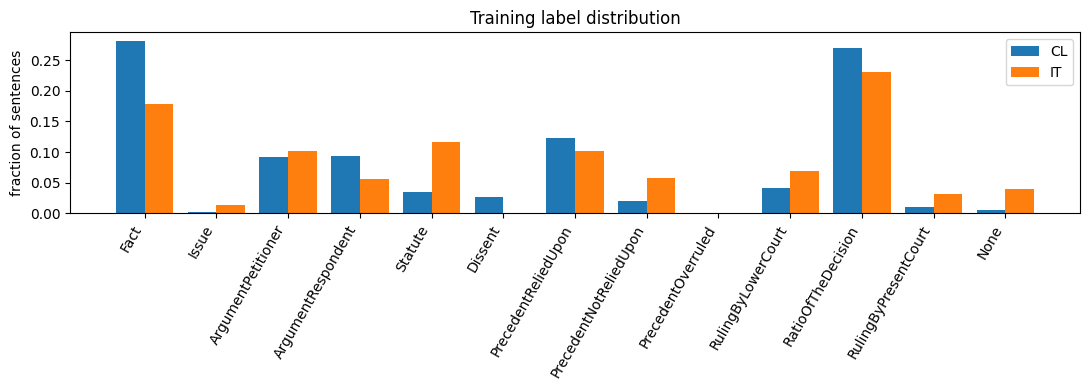

In [71]:
def hf(fn): return hf_hub_download(HF_REPO, fn, repo_type="dataset", token=HF_TOKEN)

lv = json.load(open(hf(f"{P3}/Train/label_vocab.json"), encoding="utf-8"))
if isinstance(lv, dict):
    if "labels" in lv and isinstance(lv["labels"], list): LABELS = lv["labels"]
    elif all(isinstance(v, int) for v in lv.values()):   LABELS = [k for k, _ in sorted(lv.items(), key=lambda kv: kv[1])]
    else: LABELS = list(lv.keys())
else: LABELS = list(lv)
LABELS = [str(x) for x in LABELS]; L2I = {l: i for i, l in enumerate(LABELS)}; NL = len(LABELS)
print(NL, "labels:", LABELS)

def load_docs(path, domain, labelled=True):
    raw = json.load(open(path, encoding="utf-8"))
    items = raw.items() if isinstance(raw, dict) else [(str(d.get("id", i)), d) for i, d in enumerate(raw)]
    docs = []
    for k, d in items:
        s = d["text"]; s = s.split("\n") if isinstance(s, str) else list(s)
        y = None
        if labelled and "labels" in d:
            y = [L2I[str(l)] for l in d["labels"]]; assert len(y) == len(s), (k, len(y), len(s))
        docs.append(dict(id=str(k), sents=[str(x) for x in s], y=y, domain=domain))
    return docs

DATA = {}
for dom in ("CL", "IT"):
    DATA[(dom, "train")] = load_docs(hf(f"{P3}/Train/{dom}_train.json"), dom)
    DATA[(dom, "dev")]   = load_docs(hf(f"{P3}/Train/{dom}_dev.json"), dom)
    try: DATA[(dom, "test")] = load_docs(hf(f"{P3}/Test/{dom}_test.json"), dom, labelled=False)
    except Exception as e: print("test file not available for", dom, e); DATA[(dom, "test")] = []
if TRAIN_DOC_LIMIT:
    for dom in ("CL", "IT"): DATA[(dom, "train")] = DATA[(dom, "train")][:TRAIN_DOC_LIMIT]; DATA[(dom, "dev")] = DATA[(dom, "dev")][:max(5, TRAIN_DOC_LIMIT // 3)]

MAX_SENT_TOK = 160
def tokenize_docs(docs):
    for d in tqdm(docs, leave=False):
        d["ids"] = [tokenizer.encode(clean_text(s))[:MAX_SENT_TOK] + [tokenizer.eos_id] for s in d["sents"]]
for k, v in DATA.items(): tokenize_docs(v)

rows = []
for (dom, sp), docs in DATA.items():
    ns = sum(len(d["sents"]) for d in docs); nt = sum(sum(map(len, d["ids"])) for d in docs)
    rows.append(dict(domain=dom, split=sp, docs=len(docs), sents=ns, tokens=nt, tok_per_doc=nt / max(1, len(docs))))
print(pd.DataFrame(rows))
ids_all = [d["id"] for dom in ("CL", "IT") for d in DATA[(dom, "test")]]
print("duplicate test ids across domains:", len(ids_all) - len(set(ids_all)))

# label distribution plot
fig, ax = plt.subplots(figsize=(11, 4)); w = 0.4
for j, dom in enumerate(("CL", "IT")):
    c = Counter(l for d in DATA[(dom, "train")] for l in d["y"]); tot = sum(c.values())
    ax.bar(np.arange(NL) + (j - .5) * w, [c[i] / tot for i in range(NL)], w, label=dom)
ax.set_xticks(range(NL)); ax.set_xticklabels(LABELS, rotation=60, ha="right"); ax.set_ylabel("fraction of sentences"); ax.legend()
ax.set_title("Training label distribution"); plt.tight_layout(); plt.savefig(f"{WORK}/eda_labels.png", dpi=150); plt.show()

In [72]:
# Each chunk = [BOS] + sentences (context-only ones first, then targets). Decoder is causal, so a sentence's
# representation (its </s> token + mean pool) sees all earlier sentences inside the chunk.
CTX = {
    "sentence":   dict(max_len=192,  ctx_prev=0, max_tgt=1,   bs=64, accum=1, head="none"),
    "window3":    dict(max_len=512,  ctx_prev=3, max_tgt=1,   bs=24, accum=2, head="none"),
    "doc":        dict(max_len=1024, ctx_prev=6, max_tgt=999, bs=4,  accum=4, head="none"),
    "doc_bigru":  dict(max_len=1024, ctx_prev=6, max_tgt=999, bs=4,  accum=4, head="bigru"),
}

def make_chunks(docs, ctxc, eff_len, train=False, rng=None):
    out, budget = [], eff_len - 1
    for di, d in enumerate(docs):
        S, n, i, first = d["ids"], len(d["ids"]), 0, True
        while i < n:
            tb = budget * (rng.uniform(0.3, 1.0) if (train and first and ctxc["max_tgt"] > 1) else 1.0)
            j, used = i, 0
            while j < n and (j - i) < ctxc["max_tgt"] and (j == i or used + len(S[j]) <= tb):
                used += len(S[j]); j += 1
            c = i
            while c > 0 and (i - c) < ctxc["ctx_prev"] and used + len(S[c - 1]) <= budget:
                c -= 1; used += len(S[c])
            out.append((di, c, i, j)); i = j; first = False
    return out

def make_item(doc, c, i, j):
    ids, st, en = [tokenizer.bos_id], [], []
    for k in range(c, j):
        st.append(len(ids)); ids += doc["ids"][k]; en.append(len(ids))
    tm = [k >= i for k in range(c, j)]
    lab = [(doc["y"][k] if (doc["y"] is not None and k >= i) else -100) for k in range(c, j)]
    return dict(ids=ids, st=st, en=en, tm=tm, lab=lab, sidx=list(range(c, j)))

def collate(items, dis):
    B, T, S = len(items), max(len(x["ids"]) for x in items), max(len(x["st"]) for x in items)
    ids = torch.full((B, T), tokenizer.pad_id, dtype=torch.long)
    st = torch.zeros(B, S, dtype=torch.long); en = torch.ones(B, S, dtype=torch.long)
    sm = torch.zeros(B, S, dtype=torch.bool); tm = torch.zeros(B, S, dtype=torch.bool); lab = torch.full((B, S), -100, dtype=torch.long)
    for b, x in enumerate(items):
        n, s = len(x["ids"]), len(x["st"])
        ids[b, :n] = torch.tensor(x["ids"]); st[b, :s] = torch.tensor(x["st"]); en[b, :s] = torch.tensor(x["en"])
        sm[b, :s] = True; tm[b, :s] = torch.tensor(x["tm"]); lab[b, :s] = torch.tensor(x["lab"])
    return dict(ids=ids, st=st, en=en, sm=sm, tm=tm, y=lab, doc=dis, sidx=[x["sidx"] for x in items], tml=[x["tm"] for x in items])

def batches(docs, chunks, bs, shuffle=False, rng=None):
    idx = list(range(len(chunks)))
    if shuffle: rng.shuffle(idx)
    for s in range(0, len(idx), bs):
        sel = [chunks[k] for k in idx[s:s + bs]]
        yield collate([make_item(docs[a], c, i, j) for a, c, i, j in sel], [a for a, *_ in sel])

def to_dev(b): return {k: (v.to(DEVICE, non_blocking=True) if torch.is_tensor(v) else v) for k, v in b.items()}

In [73]:
# ---------------- backbone wrapper (replace this class for other Phase-1 architectures) ----------------
class LMBackbone(nn.Module):
    def __init__(self, lm):
        super().__init__(); self.wte, self.blocks, self.ln_f = lm.wte, lm.blocks, lm.ln_f; self.dim = lm.cfg["dim"]
    def hidden(self, x, gc=False):
        for b in self.blocks:
            x = ckpt_util.checkpoint(b.train_fwd, x, use_reentrant=False) if (gc and self.training) else b(x)[0]
        return self.ln_f(x)

def load_phase1(layers_keep=None, random_init=False):
    ck = torch.load(PHASE1_CKPT, map_location="cpu", weights_only=False)
    cfg = dict(ck["config"]); sd = {k.replace("_orig_mod.", ""): v for k, v in ck["model"].items()}
    if layers_keep is None:
        lm = DualPathLM(cfg)
        if not random_init: lm.load_state_dict(sd)
    else:   # student: keep a subset of Phase-1 layers (initialised from Phase-1 weights)
        lm = DualPathLM(dict(cfg, layers=len(layers_keep))); new = {}
        for k, v in sd.items():
            m = re.match(r"blocks\.(\d+)\.(.*)", k)
            if m is None: new[k] = v
            elif int(m[1]) in layers_keep: new[f"blocks.{layers_keep.index(int(m[1]))}.{m[2]}"] = v
        lm.load_state_dict(new, strict=True)
    return lm

# ---------------- classifier on top of backbone ----------------
class RRModel(nn.Module):
    def __init__(self, bb, n_labels, head="bigru", pool="last_mean", n_prompt=0, drop=0.1):
        super().__init__()
        self.bb, self.pool, D = bb, pool, bb.dim
        pdim = 2 * D if pool == "last_mean" else D
        self.proj = nn.Sequential(nn.LayerNorm(pdim), nn.Dropout(drop), nn.Linear(pdim, D), nn.GELU())
        self.ctx = nn.GRU(D, D // 2, batch_first=True, bidirectional=True) if head == "bigru" else None
        self.cls = nn.Sequential(nn.Dropout(drop), nn.Linear(D, n_labels))
        self.n_prompt = n_prompt
        if n_prompt:
            self.prompt = nn.Parameter(bb.wte.weight[torch.randint(0, bb.wte.weight.size(0), (n_prompt,))].detach().clone())
        self.ada = None; self.gc = False

    def forward(self, ids, st, en, sm):
        emb = self.bb.wte(ids); off = 0
        if self.n_prompt:
            emb = torch.cat([self.prompt.unsqueeze(0).expand(ids.size(0), -1, -1).to(emb.dtype), emb], 1); off = self.n_prompt
        h = self.bb.hidden(emb, self.gc).float()
        B, T, D = h.shape
        cs = F.pad(h.cumsum(1), (0, 0, 1, 0))
        s, e = st + off, en + off
        last = h.gather(1, (e - 1).unsqueeze(-1).expand(-1, -1, D))
        if self.pool == "last": rep = last
        else:
            mean = (cs.gather(1, e.unsqueeze(-1).expand(-1, -1, D)) - cs.gather(1, s.unsqueeze(-1).expand(-1, -1, D))) / (e - s).clamp(min=1).unsqueeze(-1)
            rep = torch.cat([last, mean], -1)
        z = self.proj(rep)
        if self.ctx is not None:
            S = z.size(1)
            pk = nn.utils.rnn.pack_padded_sequence(z.float(), sm.sum(1).cpu(), batch_first=True, enforce_sorted=False)
            o, _ = self.ctx(pk); o, _ = nn.utils.rnn.pad_packed_sequence(o, batch_first=True, total_length=S)
            z = z + o.to(z.dtype)
        return self.cls(z), z

# ---------------- adapters ----------------
class LoRALinear(nn.Module):                      # LoRA / rsLoRA (scale = a/r  vs  a/sqrt(r))
    def __init__(self, base, r=16, alpha=32, dropout=0.05, rs=False):
        super().__init__(); self.base = base
        self.A = nn.Parameter(torch.empty(r, base.in_features)); self.B = nn.Parameter(torch.zeros(base.out_features, r))
        nn.init.kaiming_uniform_(self.A, a=math.sqrt(5)); self.scale = alpha / (math.sqrt(r) if rs else r); self.drop = nn.Dropout(dropout)
    def forward(self, x): return self.base(x) + F.linear(F.linear(self.drop(x), self.A), self.B) * self.scale

class LoRMALinear(nn.Module):                     # multiplicative: W' = (I + B A) W   ->  y = h + B A h, h = W x
    def __init__(self, base, r=16, alpha=16):
        super().__init__(); self.base = base
        self.A = nn.Parameter(torch.empty(r, base.out_features)); self.B = nn.Parameter(torch.zeros(base.out_features, r))
        nn.init.kaiming_uniform_(self.A, a=math.sqrt(5)); self.scale = alpha / r
    def forward(self, x):
        h = self.base(x); return h + F.linear(F.linear(h, self.A), self.B) * self.scale

NF4 = torch.tensor([-1.0, -0.6961928009986877, -0.5250730514526367, -0.39491748809814453, -0.28444138169288635, -0.18477343022823334,
                    -0.09105003625154495, 0.0, 0.07958029955625534, 0.16093020141029358, 0.24611230194568634, 0.33791524171829224,
                    0.44070982933044434, 0.5626170039176941, 0.7229568362236023, 1.0])
class QLoRALinear(nn.Module):                     # frozen NF4 (4-bit, blockwise absmax, packed 2/byte) + LoRA
    def __init__(self, base, r=16, alpha=32, dropout=0.05, bs=64):
        super().__init__(); w = base.weight.data.float().to(DEVICE); self.shape, self.n, self.bs = w.shape, w.numel(), bs
        f = F.pad(w.flatten(), (0, (-w.numel()) % bs)).view(-1, bs); am = f.abs().amax(1, keepdim=True).clamp(min=1e-8); nrm = f / am
        idx = torch.empty(nrm.shape, dtype=torch.uint8, device=w.device); tab = NF4.to(w.device)
        for s in range(0, nrm.size(0), 8192): idx[s:s + 8192] = (nrm[s:s + 8192, :, None] - tab).abs().argmin(-1).to(torch.uint8)
        fl = idx.flatten(); self.register_buffer("packed", ((fl[0::2] << 4) | fl[1::2]).cpu()); self.register_buffer("absmax", am.half().cpu())
        self.in_features, self.out_features = base.in_features, base.out_features
        self.A = nn.Parameter(torch.empty(r, base.in_features)); self.B = nn.Parameter(torch.zeros(base.out_features, r))
        nn.init.kaiming_uniform_(self.A, a=math.sqrt(5)); self.scale = alpha / r; self.drop = nn.Dropout(dropout)
    def deq(self, dtype):
        p = self.packed; i = torch.stack([p >> 4, p & 15], -1).flatten().long()
        w = NF4.to(p.device)[i].view(-1, self.bs) * self.absmax.float(); return w.flatten()[:self.n].view(self.shape).to(dtype)
    def forward(self, x): return F.linear(x, self.deq(x.dtype)) + F.linear(F.linear(self.drop(x), self.A), self.B) * self.scale

class AdaLoRALinear(nn.Module):                   # dW = B diag(E) A, SVD-style, rank pruned by AdaLoRAManager
    def __init__(self, base, r=12, alpha=24, dropout=0.05):
        super().__init__(); self.base = base
        self.A = nn.Parameter(torch.randn(r, base.in_features) * 0.02); self.B = nn.Parameter(torch.randn(base.out_features, r) * 0.02)
        self.E = nn.Parameter(torch.zeros(r)); self.register_buffer("mask", torch.ones(r)); self.scale = alpha / r; self.drop = nn.Dropout(dropout)
    def forward(self, x):
        return self.base(x) + F.linear(F.linear(self.drop(x), self.A) * (self.E * self.mask).to(x.dtype), self.B) * self.scale
    def orth(self):
        I = torch.eye(self.E.numel(), device=self.A.device)
        return ((self.A @ self.A.t() - I) ** 2).sum() + ((self.B.t() @ self.B - I) ** 2).sum()

class AdaLoRAManager:
    def __init__(self, model, total_steps, target_rank=4, beta=0.85, ti=0.1, tf=0.2, dt=10):
        self.mods = [m for m in model.modules() if isinstance(m, AdaLoRALinear)]
        self.T, self.beta, self.ti, self.tf, self.dt = total_steps, beta, ti, tf, dt
        self.b0 = sum(m.E.numel() for m in self.mods); self.bT = target_rank * len(self.mods); self.I, self.U = {}, {}
    def budget(self, t):
        ti, tf = int(self.ti * self.T), int(self.tf * self.T)
        if t < ti: return self.b0
        if t >= self.T - tf: return self.bT
        return int(self.bT + (self.b0 - self.bT) * (1 - (t - ti) / max(1, self.T - tf - ti)) ** 3)
    def orth_loss(self): return sum(m.orth() for m in self.mods)
    @torch.no_grad()
    def update(self, t):
        for k, m in enumerate(self.mods):
            if m.E.grad is None or m.A.grad is None: return
            s = (m.E * m.E.grad).abs() + (m.A * m.A.grad).abs().mean(1) + (m.B * m.B.grad).abs().mean(0)
            if k not in self.I: self.I[k], self.U[k] = s.clone(), torch.zeros_like(s)
            else:
                self.I[k] = self.beta * self.I[k] + (1 - self.beta) * s
                self.U[k] = self.beta * self.U[k] + (1 - self.beta) * (s - self.I[k]).abs()
        if t % self.dt == 0 and len(self.I) == len(self.mods):
            sc = torch.cat([self.I[k] * self.U[k] for k in range(len(self.mods))]); keep = self.budget(t)
            mk = torch.zeros_like(sc); mk[sc.topk(min(keep, sc.numel())).indices] = 1; o = 0
            for m in self.mods:
                r = m.E.numel(); m.mask.copy_(mk[o:o + r]); m.E.mul_(m.mask); o += r
    def active_rank(self): return float(sum(m.mask.sum().item() for m in self.mods) / len(self.mods))

class IA3Linear(nn.Module):                       # learned rescaling vector on output (k,v) or input (FFN hidden)
    def __init__(self, base, where):
        super().__init__(); self.base, self.where = base, where
        self.s = nn.Parameter(torch.ones(base.out_features if where == "out" else base.in_features))
    def forward(self, x): return self.base(x * self.s.to(x.dtype)) if self.where == "in" else self.base(x) * self.s.to(x.dtype)

class PrefixAttn(nn.Module):                      # learned per-layer key/value prefix (shared across heads of a KV group)
    def __init__(self, attn, P):
        super().__init__(); self.attn = attn
        self.pk = nn.Parameter(torch.randn(attn.hk, P, attn.hd)); self.pv = nn.Parameter(torch.randn(attn.hk, P, attn.hd) * 0.1)
    def forward(self, x, mask=None, cache=None, start=0):
        a = self.attn; b, t, _ = x.shape; r = a.h // a.hk
        q = a.q(x).view(b, t, a.h, a.hd).transpose(1, 2)
        k, v = a.kv(x).view(b, t, 2, a.hk, a.hd).permute(2, 0, 3, 1, 4)
        q, k = a.rope(a.qn(q), start), a.rope(a.kn(k), start)
        P = self.pk.size(1)
        k = torch.cat([self.pk.unsqueeze(0).expand(b, -1, -1, -1).to(k.dtype), k], 2)
        v = torch.cat([self.pv.unsqueeze(0).expand(b, -1, -1, -1).to(v.dtype), v], 2)
        k, v = k.repeat_interleave(r, 1), v.repeat_interleave(r, 1)
        m = torch.ones(t, P + t, dtype=torch.bool, device=x.device).tril(diagonal=P)   # prefix visible to all, causal on tokens
        y = F.scaled_dot_product_attention(q, k, v, attn_mask=m)
        return a.o(y.transpose(1, 2).reshape(b, t, a.h * a.hd)), cache

TARGETS = ("attn.q", "attn.kv", "attn.o", "ffn.w13", "ffn.w2")
def replace_linears(root, suffixes, factory):
    for name, mod in list(root.named_modules()):
        for cn, ch in list(mod.named_children()):
            full = f"{name}.{cn}" if name else cn
            if isinstance(ch, nn.Linear) and any(full.endswith(s) for s in suffixes): setattr(mod, cn, factory(full, ch))

def apply_method(model, cfg):
    m, bb = cfg["method"], model.bb
    if m != "full":
        for p in bb.parameters(): p.requires_grad = False
    if m in ("lora", "rslora"):
        replace_linears(bb, TARGETS, lambda n, l: LoRALinear(l, cfg["r"], cfg["alpha"], 0.05, rs=(m == "rslora")))
    elif m == "qlora":  replace_linears(bb, TARGETS, lambda n, l: QLoRALinear(l, cfg["r"], cfg["alpha"]))
    elif m == "adalora": replace_linears(bb, TARGETS, lambda n, l: AdaLoRALinear(l, cfg["r"], cfg["alpha"]))
    elif m == "lorma":  replace_linears(bb, TARGETS, lambda n, l: LoRMALinear(l, cfg["r"], cfg["alpha"]))
    elif m == "ia3":
        replace_linears(bb, ("attn.kv",), lambda n, l: IA3Linear(l, "out")); replace_linears(bb, ("ffn.w2",), lambda n, l: IA3Linear(l, "in"))
    elif m == "prefix":
        for blk in bb.blocks: blk.attn = PrefixAttn(blk.attn, cfg["n_prefix"])
    elif m not in ("full", "linear_probe", "prompt"): raise ValueError(m)

def build_model(cfg):
    lm = load_phase1(cfg.get("layers_keep"), cfg.get("random_init", False)); bb = LMBackbone(lm)
    npr = cfg.get("n_prompt", 0) if cfg["method"] == "prompt" else 0
    model = RRModel(bb, NL, head=CTX[cfg["ctx"]]["head"], pool=cfg.get("pool", "last_mean"), n_prompt=npr)
    if cfg["method"] == "prompt":
        for p in bb.parameters(): p.requires_grad = False
    apply_method(model, cfg); model.gc = cfg.get("grad_ckpt", False)
    return model.to(DEVICE)

def model_stats(model):
    tr = sum(p.numel() for p in model.parameters() if p.requires_grad); tot = sum(p.numel() for p in model.parameters())
    mb = (sum(p.numel() * p.element_size() for p in model.parameters()) + sum(b.numel() * b.element_size() for b in model.buffers())) / 2**20
    return tr, tot, mb

In [74]:
RESULTS_PATH, PRED_PATH = f"{WORK}/results.json", f"{WORK}/dev_preds.pkl"
RESULTS = json.load(open(RESULTS_PATH)) if os.path.exists(RESULTS_PATH) else {}
PRED = pickle.load(open(PRED_PATH, "rb")) if os.path.exists(PRED_PATH) else {}
def save_all():
    json.dump(RESULTS, open(RESULTS_PATH, "w"), default=lambda o: o.item() if hasattr(o, "item") else str(o))
    pickle.dump(PRED, open(PRED_PATH, "wb"))

def class_weights(docs):
    c = np.bincount([l for d in docs for l in d["y"]], minlength=NL).astype(np.float64) + 1
    w = (c.sum() / (NL * c)) ** 0.5; return torch.tensor(w / w.mean(), dtype=torch.float32, device=DEVICE)

def rr_loss(logits, y, kind, w):
    m = y != -100; lg, yy = logits[m].float(), y[m]
    if kind == "focal":
        lp = F.log_softmax(lg, -1).gather(1, yy[:, None])[:, 0]; pt = lp.exp()
        return (-(1 - pt) ** 2 * lp * (w[yy] if w is not None else 1.0)).mean()
    return F.cross_entropy(lg, yy, weight=w if kind in ("wce", "focal") else None, label_smoothing=0.0)

def metrics(y, p):
    return dict(f1=f1_score(y, p, average="macro", zero_division=0), P=precision_score(y, p, average="macro", zero_division=0),
                R=recall_score(y, p, average="macro", zero_division=0), acc=accuracy_score(y, p),
                f1_all=f1_score(y, p, average="macro", labels=list(range(NL)), zero_division=0))

@torch.no_grad()
def predict(model, docs, ctxc, eff_len):
    model.eval(); chunks = make_chunks(docs, ctxc, eff_len)
    chunks.sort(key=lambda ch: sum(len(x) for x in docs[ch[0]]["ids"][ch[1]:ch[3]]))
    Lg = [np.zeros((len(d["sents"]), NL), np.float32) for d in docs]
    for b in batches(docs, chunks, ctxc["bs"] * 2):
        bd = to_dev(b)
        with torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=USE_AMP):
            lg, _ = model(bd["ids"], bd["st"], bd["en"], bd["sm"])
        lg = lg.float().cpu().numpy()
        for r, (di, sidx, tml) in enumerate(zip(b["doc"], b["sidx"], b["tml"])):
            for q, (k, t) in enumerate(zip(sidx, tml)):
                if t: Lg[di][k] = lg[r, q]
    return [l.argmax(1) for l in Lg], Lg

def eval_domains(model, dev_sets, ctxc, eff_len, doms):
    out = {}
    for dom in doms:
        P, _ = predict(model, dev_sets[dom], ctxc, eff_len)
        out[dom] = metrics(np.concatenate([d["y"] for d in dev_sets[dom]]), np.concatenate(P))
    return out

def load_teacher(tname):
    tc = RESULTS[tname]["cfg"]; t = build_model(tc); t.load_state_dict(torch.load(f"{CK}/{tname}.pt", map_location=DEVICE)); t.eval()
    for p in t.parameters(): p.requires_grad = False
    return t

def train_run(cfg):
    name = cfg["name"]
    if name in RESULTS: print("skip (done):", name); return RESULTS[name]
    print(f"\n=== {name} | {cfg['method']} | ctx={cfg['ctx']} | train={cfg['train_domains']} | loss={cfg['loss']} ===")
    set_seed(cfg.get("seed", SEED)); rng = random.Random(cfg.get("seed", SEED))
    ctxc = CTX[cfg["ctx"]]; eff_len = ctxc["max_len"] - (cfg.get("n_prompt", 0) if cfg["method"] == "prompt" else 0)
    train_docs = [d for dom in cfg["train_domains"] for d in DATA[(dom, "train")]]
    dev_sets = {dom: DATA[(dom, "dev")] for dom in ("CL", "IT")}
    model = build_model(cfg); tr, tot, mb = model_stats(model)
    print(f"params trainable {tr/1e6:.2f}M / total {tot/1e6:.1f}M | size {mb:.0f} MB")
    w = class_weights(train_docs) if cfg["loss"] in ("wce", "focal") else None
    teacher = load_teacher(cfg["kd"]["teacher"]) if cfg.get("kd") else None

    groups = {"bb": [], "head": []}
    for n, p in model.named_parameters():
        if p.requires_grad: groups["bb" if n.startswith("bb.") or n == "prompt" else "head"].append(p)
    opt = torch.optim.AdamW([dict(params=groups["bb"], lr=cfg["lr"], base=cfg["lr"]),
                             dict(params=groups["head"], lr=cfg["head_lr"], base=cfg["head_lr"])], weight_decay=0.01, betas=(0.9, 0.98))
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP and AMP_DTYPE == torch.float16)
    n_chunks = len(make_chunks(train_docs, ctxc, eff_len)); spe = max(1, math.ceil(n_chunks / (ctxc["bs"] * ctxc["accum"])))
    total = cfg["epochs"] * spe; warm = max(1, int(0.06 * total))
    if cfg["method"] == "adalora": model.ada = AdaLoRAManager(model, total, cfg.get("target_rank", 4))
    track = {n for n, p in model.named_parameters() if p.requires_grad} | {n for n, _ in model.named_buffers() if n.endswith(".mask")}
    sel_doms = cfg["train_domains"]; best, best_state, bad, hist, step, t0 = -1, None, 0, [], 0, time.time()
    # 2. Setup resume variables
    start_ep = 0
    best = -1
    best_state = None
    bad = 0
    hist = []
    step = 0
    # Resume from checkpoint if it exists
    ckpt_file = f"{CK}/{name}_ckpt.pt"
    print(ckpt_file)
    if os.path.exists(ckpt_file):
        print(f"Resuming checkpoint from {ckpt_file}")
        checkpoint = torch.load(ckpt_file, map_location=DEVICE)
        model.load_state_dict(checkpoint["model_state"], strict=False)
        opt.load_state_dict(checkpoint["optimizer_state"])
        if "scaler_state" in checkpoint and checkpoint["scaler_state"] is not None:
            scaler.load_state_dict(checkpoint["scaler_state"])
        start_ep = checkpoint["epoch"] + 1
        best = checkpoint["best"]
        best_state = checkpoint["best_state"]
        bad = checkpoint["bad"]
        hist = checkpoint["hist"]
        step = checkpoint["step"]
        print("Ep resumed: ", start_ep)
    for ep in range(start_ep, cfg["epochs"]):
        model.train(); chunks = make_chunks(train_docs, ctxc, eff_len, train=True, rng=rng); run_loss, nb = 0.0, 0
        opt.zero_grad(set_to_none=True)
        pbar = tqdm(batches(train_docs, chunks, ctxc["bs"], True, rng), total=math.ceil(len(chunks) / ctxc["bs"]), desc=f"ep{ep+1}", leave=False)
        for mi, b in enumerate(pbar):
            bd = to_dev(b)
            with torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=USE_AMP):
                lg, z = model(bd["ids"], bd["st"], bd["en"], bd["sm"])
                loss = rr_loss(lg, bd["y"], cfg["loss"], w)
                if teacher is not None:
                    with torch.no_grad(): tl, tz = teacher(bd["ids"], bd["st"], bd["en"], bd["sm"])
                    m = bd["y"] != -100; T = cfg["kd"]["T"]
                    kd = F.kl_div(F.log_softmax(lg[m].float() / T, -1), F.softmax(tl[m].float() / T, -1), reduction="batchmean") * T * T
                    loss = cfg["kd"]["alpha"] * loss + (1 - cfg["kd"]["alpha"]) * kd
                    if cfg["kd"].get("beta", 0) > 0: loss = loss + cfg["kd"]["beta"] * (1 - F.cosine_similarity(z[m].float(), tz[m].float(), dim=-1)).mean()
                if model.ada is not None: loss = loss + 0.1 * model.ada.orth_loss()
            scaler.scale(loss / ctxc["accum"]).backward(); run_loss += loss.item(); nb += 1
            if (mi + 1) % ctxc["accum"] == 0:
                lr_f = (step + 1) / warm if step < warm else 0.5 * (1 + math.cos(math.pi * (step - warm) / max(1, total - warm)))
                for g in opt.param_groups: g["lr"] = g["base"] * max(lr_f, 0.02)
                scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_([p for g in groups.values() for p in g], 1.0)
                if model.ada is not None: model.ada.update(step)
                scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True); step += 1
            if (time.time() - t0) / 60 > MAX_MIN_PER_RUN: break
        dm = eval_domains(model, dev_sets, ctxc, eff_len, sel_doms); score = float(np.mean([dm[d]["f1"] for d in sel_doms]))
        hist.append(dict(epoch=ep + 1, loss=run_loss / max(1, nb), **{f"f1_{d}": dm[d]["f1"] for d in sel_doms}, score=score))
        print(f"ep{ep+1} loss {run_loss/max(1,nb):.4f} | dev macro-F1 " + " ".join(f"{d}:{dm[d]['f1']:.4f}" for d in sel_doms) + f" | {(time.time()-t0)/60:.1f} min")
        if score > best: best, bad, best_state = score, 0, {k: v.detach().cpu().clone() for k, v in model.state_dict().items() if k in track}
        else:
            bad += 1
            if bad >= cfg.get("patience", 3): break
        # 3. Save lightweight epoch checkpoint to keep storage footprint minimal
        torch.save({
            "epoch": ep,
            "step": step,
            "best": best,
            "bad": bad,
            "hist": hist,
            "model_state": {k: v.cpu() for k, v in model.state_dict().items() if k in track},
            "optimizer_state": opt.state_dict(),
            "scaler_state": scaler.state_dict() if USE_AMP else None,
            "best_state": best_state
        }, ckpt_file)
        if (time.time() - t0) / 60 > MAX_MIN_PER_RUN: print("time cap reached"); break
    train_min = (time.time() - t0) / 60
    model.load_state_dict(best_state, strict=False)
    if cfg.get("save_ckpt"): torch.save({k: v.cpu() for k, v in model.state_dict().items()}, f"{CK}/{name}.pt")

    # final evaluation on both dev domains (+ timing), test prediction
    res = dict(name=name, group=cfg["group"], cfg=cfg, trainable=tr, total=tot, size_mb=mb, train_min=train_min, hist=hist, dev={}, perclass={}, conf={})
    PRED[name] = {}; t1 = time.time(); nsent = 0
    for dom in ("CL", "IT"):
        P, Lg = predict(model, dev_sets[dom], ctxc, eff_len); y, p = np.concatenate([d["y"] for d in dev_sets[dom]]), np.concatenate(P); nsent += len(y)
        res["dev"][dom] = metrics(y, p); res["perclass"][dom] = f1_score(y, p, average=None, labels=list(range(NL)), zero_division=0).tolist()
        res["conf"][dom] = confusion_matrix(y, p, labels=list(range(NL))).tolist(); PRED[name][dom] = dict(y=y, p=p, logits=np.concatenate(Lg))
    res["infer_s_per_1k"] = (time.time() - t1) / nsent * 1000
    res["f1_CL"], res["f1_IT"] = res["dev"]["CL"]["f1"], res["dev"]["IT"]["f1"]; res["f1_mean"] = (res["f1_CL"] + res["f1_IT"]) / 2
    if model.ada is not None: res["active_rank"] = model.ada.active_rank()
    for dom in ("CL", "IT"):
        td = DATA[(dom, "test")]
        if td:
            P, _ = predict(model, td, ctxc, eff_len)
            json.dump({d["id"]: [LABELS[i] for i in p] for d, p in zip(td, P)}, open(f"{PRED_DIR}/{name}_{dom}.json", "w"))
    RESULTS[name] = res; save_all()
    print(f"-> {name}: CL {res['f1_CL']:.4f} | IT {res['f1_IT']:.4f} | mean {res['f1_mean']:.4f} | {train_min:.1f} min | {res['infer_s_per_1k']:.2f}s/1k sents")
    del model, opt, teacher; gc.collect(); torch.cuda.empty_cache()
    return res

In [75]:
BASE = dict(ctx="doc_bigru", loss="wce", train_domains=["CL", "IT"], epochs=8, patience=3, head_lr=1e-3, lr=5e-4, seed=SEED)
METHOD_HP = {
    "linear_probe": dict(head_lr=2e-3),
    "full":    dict(lr=1e-4, epochs=6),
    "lora":    dict(r=16, alpha=32, lr=5e-4),
    "rslora":  dict(r=64, alpha=16, lr=5e-4),            # scale alpha/sqrt(r)
    "qlora":   dict(r=16, alpha=32, lr=5e-4),
    "adalora": dict(r=12, alpha=24, target_rank=4, lr=1e-3),
    "lorma":   dict(r=16, alpha=16, lr=5e-4),
    "ia3":     dict(lr=3e-3),
    "prefix":  dict(n_prefix=32, lr=5e-3),
    "prompt":  dict(n_prompt=32, lr=3e-3),
}
def C(name, group, method="lora", **kw):
    c = dict(BASE); c.update(METHOD_HP.get(method, {})); c.update(name=name, group=group, method=method); c.update(kw); return c
def best_of(prefix, key="f1_mean"):
    c = {k: v for k, v in RESULTS.items() if k.startswith(prefix)}; return max(c, key=lambda k: c[k][key]) if c else None

# ---- Group 1: how much context helps (LoRA fixed) ----
for ctx in ["sentence", "window3", "doc_bigru"]: train_run(C(f"ctx_{ctx}", "context", "lora", ctx=ctx, epochs=2))
BEST_CTX = RESULTS[best_of("ctx_")]["cfg"]["ctx"]; print("\nBEST CONTEXT MODE:", BEST_CTX)

# ---- Group 2: fine-tuning / PEFT techniques (all with BEST_CTX) ----
for m in ["full", "rslora", "qlora", "lorma"]:
    train_run(C(f"m_{m}", "method", m, ctx=BEST_CTX, save_ckpt=(m == "full"), epochs=2))

skip (done): ctx_sentence

=== ctx_window3 | lora | ctx=window3 | train=['CL', 'IT'] | loss=wce ===
params trainable 2.83M / total 81.0M | size 311 MB
/kaggle/working/phase3-gqa-conv/ckpts/ctx_window3_ckpt.pt
Resuming checkpoint from /kaggle/working/phase3-gqa-conv/ckpts/ctx_window3_ckpt.pt
Ep resumed:  2
-> ctx_window3: CL 0.2855 | IT 0.4250 | mean 0.3553 | 0.0 min | 238.95s/1k sents
skip (done): ctx_doc_bigru

BEST CONTEXT MODE: doc_bigru
skip (done): m_full
skip (done): m_rslora
skip (done): m_qlora
skip (done): m_lorma


In [76]:
# ---- Group 3: class-balancing (LoRA, BEST_CTX; 'wce' already = m_lora) ----
for lo in ["ce", "focal"]: train_run(C(f"loss_{lo}", "loss", "lora", ctx=BEST_CTX, loss=lo))
# ---- Group 4: domain study (train on one domain, evaluate on both) ----
# for dom in ["CL", "IT"]: train_run(C(f"dom_{dom}", "domain", "lora", ctx=BEST_CTX, train_domains=[dom]))
# ---- Group 5: value of Phase-1 pre-training (random init, same arch) ----
# train_run(C("p1_random_full", "phase1", "full", ctx=BEST_CTX, random_init=True))
# train_run(C("p1_random_lora", "phase1", "lora", ctx=BEST_CTX, random_init=True))

skip (done): loss_ce
skip (done): loss_focal


In [77]:
# ---- Group 6: knowledge distillation ----
# Teacher = full FT of the 8-layer Phase-1 model (m_full). Student = 4 layers initialised from Phase-1 layers {0,2,5,7}.
STUDENT = dict(layers_keep=[0, 2, 5, 7], lr=2e-4, epochs=4)
# train_run(C("kd_student_ce", "kd", "full", ctx=BEST_CTX, **STUDENT))                                   # no-KD baseline
train_run(C("kd_student_logits", "kd", "full", ctx=BEST_CTX, kd=dict(teacher="m_full", T=2.0, alpha=0.3, beta=0.0), **STUDENT))
# train_run(C("kd_student_logits_rep", "kd", "full", ctx=BEST_CTX, kd=dict(teacher="m_full", T=2.0, alpha=0.3, beta=0.5), **STUDENT))

skip (done): kd_student_logits


{'name': 'kd_student_logits',
 'group': 'kd',
 'cfg': {'ctx': 'doc_bigru',
  'loss': 'wce',
  'train_domains': ['CL', 'IT'],
  'epochs': 4,
  'patience': 3,
  'head_lr': 0.001,
  'lr': 0.0002,
  'seed': 42,
  'name': 'kd_student_logits',
  'group': 'kd',
  'method': 'full',
  'kd': {'teacher': 'm_full', 'T': 2.0, 'alpha': 0.3, 'beta': 0.0},
  'layers_keep': [0, 2, 5, 7]},
 'trainable': 54470925,
 'total': 54470925,
 'size_mb': 208.79008865356445,
 'train_min': 11.128723148504893,
 'hist': [{'epoch': 1,
   'loss': 2.3988235648721457,
   'f1_CL': 0.28697042602510253,
   'f1_IT': 0.28570041577436817,
   'score': 0.28633542089973535},
  {'epoch': 2,
   'loss': 1.341410518619063,
   'f1_CL': 0.30770552874803975,
   'f1_IT': 0.3644000646877437,
   'score': 0.33605279671789173},
  {'epoch': 3,
   'loss': 0.7508584726601839,
   'f1_CL': 0.37770911428370374,
   'f1_IT': 0.4295575064670928,
   'score': 0.4036333103753983},
  {'epoch': 4,
   'loss': 0.4647658032350515,
   'f1_CL': 0.4098852597432

In [78]:
def results_df():
    rows = []
    for n, r in RESULTS.items():
        c = r["cfg"]; rows.append(dict(name=n, group=r["group"], method=c["method"], ctx=c["ctx"], loss=c["loss"], train=",".join(c["train_domains"]),
            trainable_M=r["trainable"] / 1e6, total_M=r["total"] / 1e6, size_MB=r["size_mb"], train_min=r["train_min"], infer_s_per_1k=r["infer_s_per_1k"],
            F1_CL=r["f1_CL"], F1_IT=r["f1_IT"], F1_mean=r["f1_mean"],
            P_mean=(r["dev"]["CL"]["P"] + r["dev"]["IT"]["P"]) / 2, R_mean=(r["dev"]["CL"]["R"] + r["dev"]["IT"]["R"]) / 2))
    return pd.DataFrame(rows)
df = results_df(); pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)

             name   group method       ctx  loss train  trainable_M  total_M  size_MB  train_min  infer_s_per_1k  F1_CL  F1_IT  F1_mean  P_mean  R_mean
    ctx_doc_bigru context   lora doc_bigru   wce CL,IT       5.4907  83.6872 321.2413    11.5378          4.2979 0.3628 0.4510   0.4069  0.4250  0.4352
      ctx_window3 context   lora   window3   wce CL,IT       2.8319  81.0284 311.0987     0.0041        238.9504 0.2855 0.4250   0.3553  0.3868  0.3538
     ctx_sentence context   lora  sentence   wce CL,IT       2.8319  81.0284 311.0987    24.8067          3.4692 0.2387 0.3385   0.2886  0.3015  0.2970
kd_student_logits      kd   full doc_bigru   wce CL,IT      54.4709  54.4709 208.7901    11.1287          1.9650 0.4099 0.4152   0.4125  0.4393  0.4134
          loss_ce    loss   lora doc_bigru    ce CL,IT       5.4907  83.6872 321.2413    23.4022          4.2871 0.3930 0.4734   0.4332  0.4755  0.4443
       loss_focal    loss   lora doc_bigru focal CL,IT       5.4907  83.6872 321.2413   

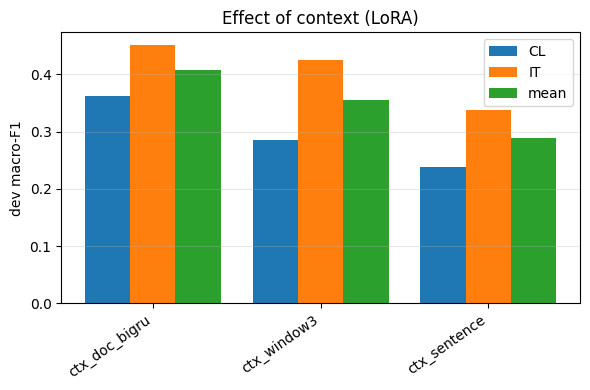

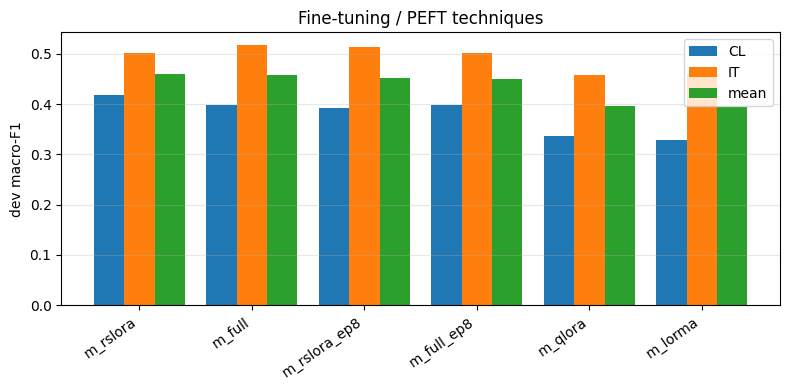

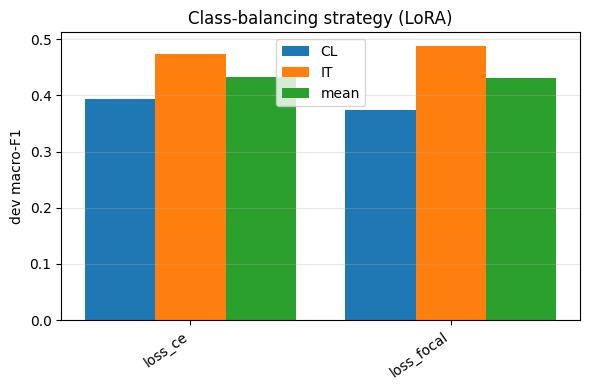

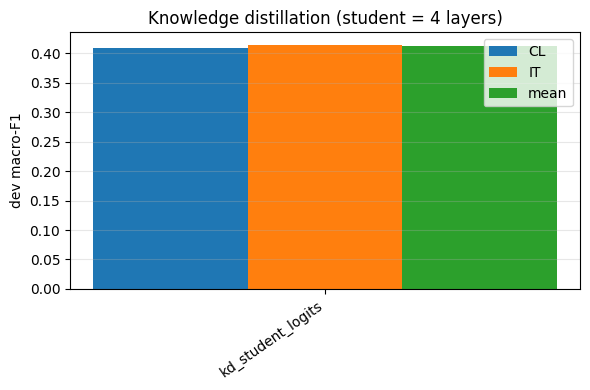

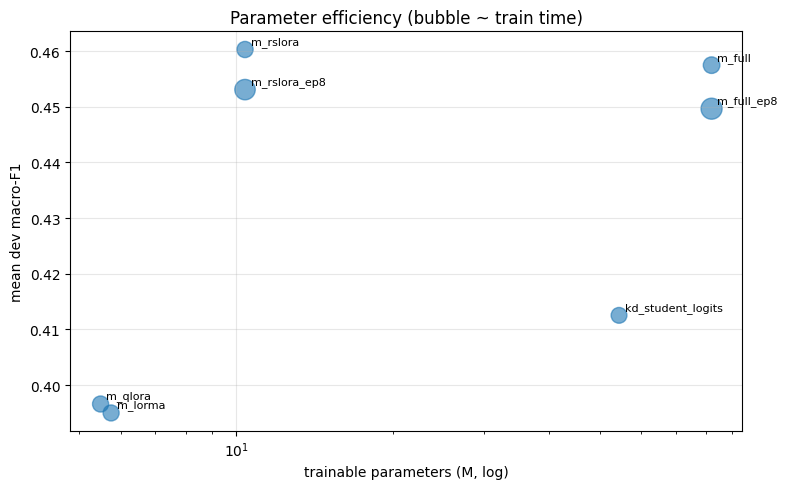

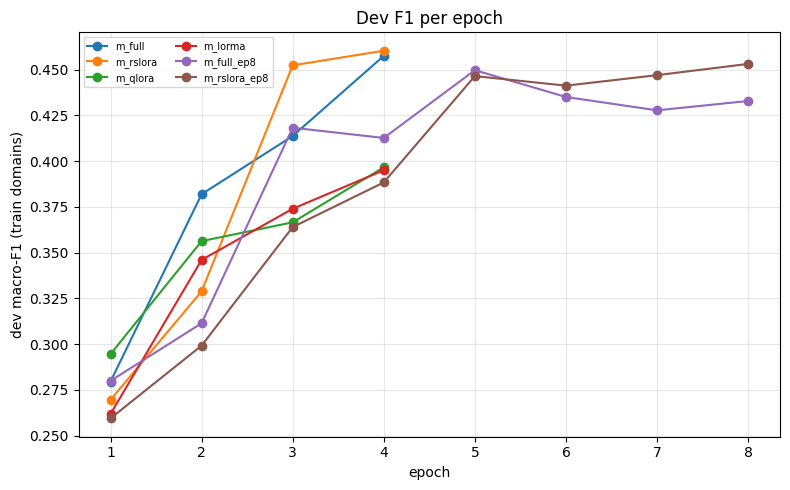

             name  total_M  size_MB  infer_s_per_1k  F1_CL  F1_IT  F1_mean
           m_full  82.0488 314.9913          3.9192 0.3977 0.5172   0.4575
kd_student_logits  54.4709 208.7901          1.9650 0.4099 0.4152   0.4125


In [79]:
def results_df():
    rows = []
    for n, r in RESULTS.items():
        c = r["cfg"]; rows.append(dict(name=n, group=r["group"], method=c["method"], ctx=c["ctx"], loss=c["loss"], train=",".join(c["train_domains"]),
            trainable_M=r["trainable"] / 1e6, total_M=r["total"] / 1e6, size_MB=r["size_mb"], train_min=r["train_min"], infer_s_per_1k=r["infer_s_per_1k"],
            F1_CL=r["f1_CL"], F1_IT=r["f1_IT"], F1_mean=r["f1_mean"],
            P_mean=(r["dev"]["CL"]["P"] + r["dev"]["IT"]["P"]) / 2, R_mean=(r["dev"]["CL"]["R"] + r["dev"]["IT"]["R"]) / 2))
    return pd.DataFrame(rows)
df = results_df(); pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)
print(df.sort_values(["group", "F1_mean"], ascending=[True, False]).round(4).to_string(index=False))
df.to_csv(f"{WORK}/summary.csv", index=False)

def bar_group(g, key="name", title=None, fn=None):
    d = df[df.group == g].sort_values("F1_mean", ascending=False)
    if g == "method" and "ctx_" + BEST_CTX in RESULTS: pass
    x = np.arange(len(d)); fig, ax = plt.subplots(figsize=(max(6, 1.0 * len(d) + 2), 4))
    ax.bar(x - .27, d.F1_CL, .27, label="CL"); ax.bar(x, d.F1_IT, .27, label="IT"); ax.bar(x + .27, d.F1_mean, .27, label="mean")
    ax.set_xticks(x); ax.set_xticklabels(d[key], rotation=35, ha="right"); ax.set_ylabel("dev macro-F1"); ax.set_title(title or g); ax.legend(); ax.grid(axis="y", alpha=.3)
    plt.tight_layout(); plt.savefig(f"{WORK}/{fn or g}.png", dpi=150); plt.show()

for g, t in [("context", "Effect of context (LoRA)"), ("method", "Fine-tuning / PEFT techniques"), ("loss", "Class-balancing strategy (LoRA)"),
             ("phase1", "Phase-1 pretrained vs random init"), ("kd", "Knowledge distillation (student = 4 layers)")]:
    if (df.group == g).any(): bar_group(g, title=t)

# efficiency: trainable params vs F1 (bubble = train minutes)
d = df[df.group.isin(["method", "kd"])]
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(d.trainable_M, d.F1_mean, s=40 + 8 * d.train_min, alpha=.6)
for _, r in d.iterrows(): ax.annotate(r["name"], (r.trainable_M, r.F1_mean), fontsize=8, xytext=(4, 4), textcoords="offset points")
ax.set_xscale("log"); ax.set_xlabel("trainable parameters (M, log)"); ax.set_ylabel("mean dev macro-F1"); ax.set_title("Parameter efficiency (bubble ~ train time)"); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(f"{WORK}/efficiency.png", dpi=150); plt.show()

# training curves
fig, ax = plt.subplots(figsize=(8, 5))
for n, r in RESULTS.items():
    if r["group"] == "method": ax.plot([h["epoch"] for h in r["hist"]], [h["score"] for h in r["hist"]], marker="o", label=n)
ax.set_xlabel("epoch"); ax.set_ylabel("dev macro-F1 (train domains)"); ax.legend(fontsize=7, ncol=2); ax.grid(alpha=.3); ax.set_title("Dev F1 per epoch")
plt.tight_layout(); plt.savefig(f"{WORK}/curves.png", dpi=150); plt.show()

# domain transfer matrix (rows = trained on, cols = evaluated on)
dm = {"CL-only": "dom_CL", "IT-only": "dom_IT", "joint": "m_lora"}
if all(v in RESULTS for v in dm.values()):
    M = np.array([[RESULTS[v]["f1_CL"], RESULTS[v]["f1_IT"]] for v in dm.values()])
    fig, ax = plt.subplots(figsize=(4.5, 3.5)); im = ax.imshow(M, cmap="viridis")
    ax.set_xticks([0, 1]); ax.set_xticklabels(["eval CL", "eval IT"]); ax.set_yticks(range(3)); ax.set_yticklabels(dm.keys())
    for i in range(3):
        for j in range(2): ax.text(j, i, f"{M[i,j]:.3f}", ha="center", va="center", color="w")
    ax.set_title("Domain transfer (macro-F1)"); plt.tight_layout(); plt.savefig(f"{WORK}/domain_matrix.png", dpi=150); plt.show()

# KD summary: size / latency / F1
k = df[df.name.isin(["m_full", "kd_student_ce", "kd_student_logits", "kd_student_logits_rep"])]
print(k[["name", "total_M", "size_MB", "infer_s_per_1k", "F1_CL", "F1_IT", "F1_mean"]].round(4).to_string(index=False))

best experiment: m_rslora


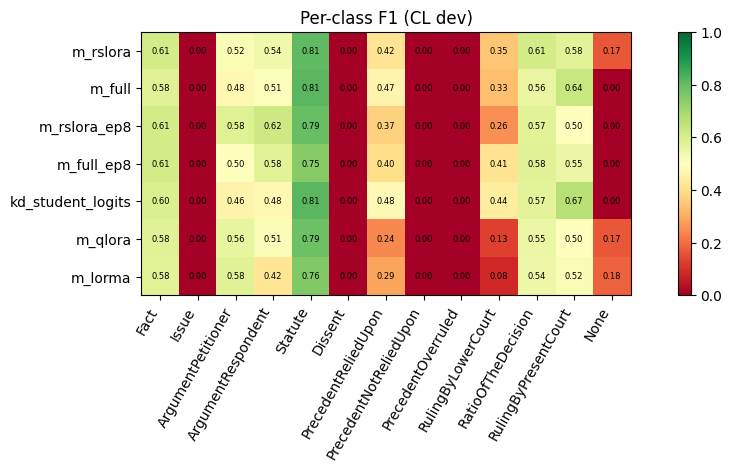

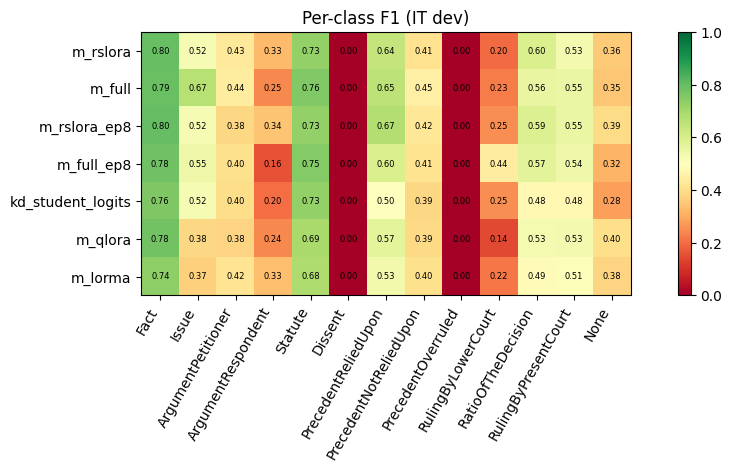

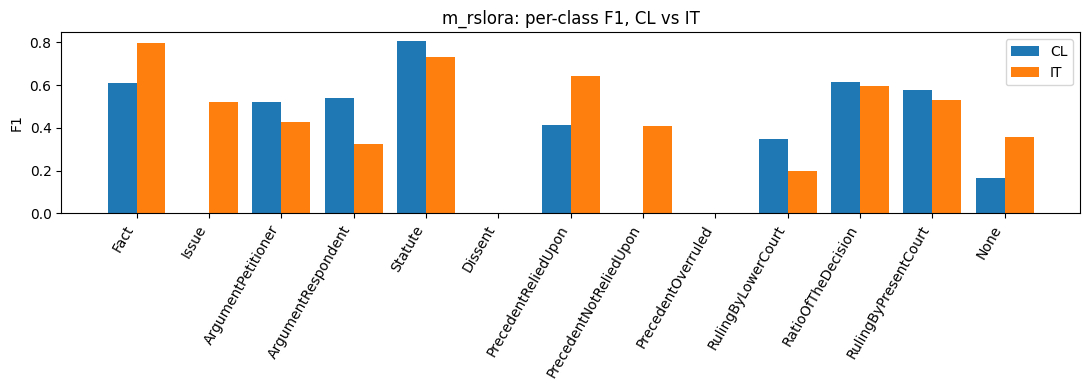

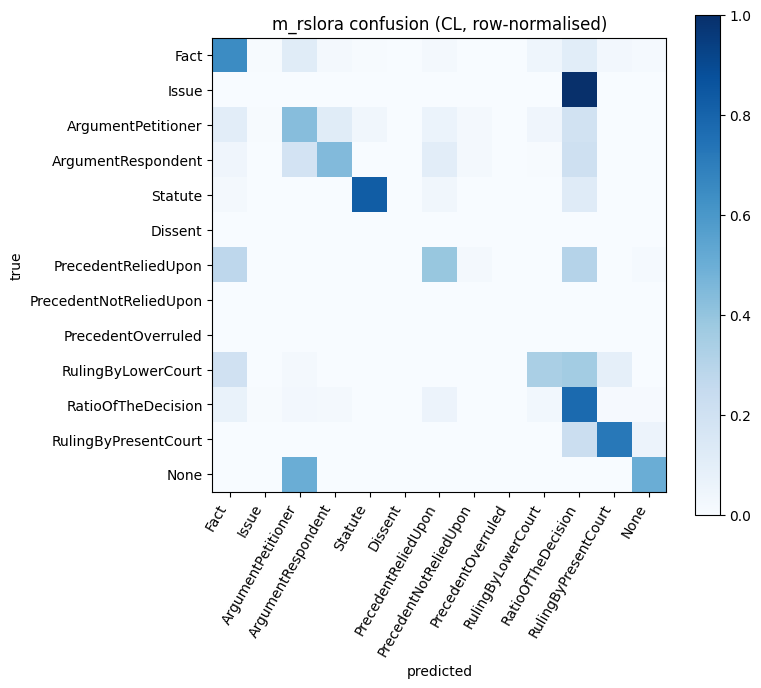


Top confusions [CL] (true -> pred):
               true                pred  count  row_frac
 ArgumentPetitioner  RatioOfTheDecision     65     0.189
 ArgumentRespondent  RatioOfTheDecision     48     0.203
 ArgumentRespondent  ArgumentPetitioner     43     0.182
PrecedentReliedUpon  RatioOfTheDecision     43     0.303
 ArgumentPetitioner  ArgumentRespondent     39     0.113
PrecedentReliedUpon                Fact     39     0.275
 ArgumentPetitioner                Fact     36     0.105
               Fact  ArgumentPetitioner     29     0.116
               Fact  RatioOfTheDecision     27     0.108
 ArgumentRespondent PrecedentReliedUpon     24     0.102


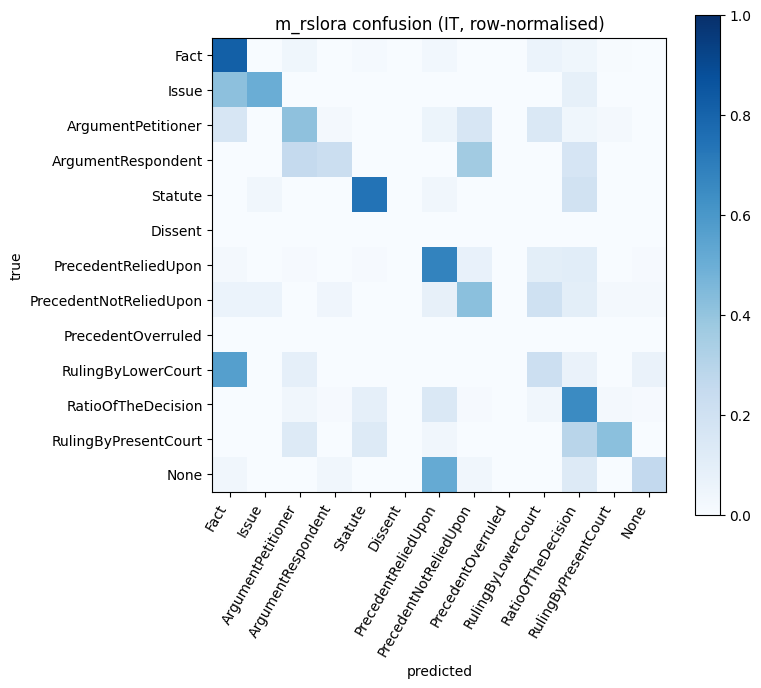


Top confusions [IT] (true -> pred):
                  true                   pred  count  row_frac
    RulingByLowerCourt                   Fact     26     0.565
    RatioOfTheDecision    PrecedentReliedUpon     17     0.148
                  None    PrecedentReliedUpon     16     0.516
    ArgumentRespondent PrecedentNotReliedUpon     13     0.361
                  Fact     RulingByLowerCourt     12     0.062
               Statute     RatioOfTheDecision     12     0.194
   PrecedentReliedUpon     RatioOfTheDecision     12     0.107
   PrecedentReliedUpon     RulingByLowerCourt     11     0.098
PrecedentNotReliedUpon     RulingByLowerCourt     10     0.200
    RatioOfTheDecision                Statute     10     0.087

[CL] within-group confusion share (errors that stay inside the related group):
  Precedent*         errors from these classes:    87 | of which stay in-group: 3.45%
  Arguments          errors from these classes:   326 | of which stay in-group: 25.15%
  Reasoning/Rulin

In [80]:
def best_name(groups=("method", "kd", "loss", "domain", "context")):
    d = df[df.group.isin(groups)]; return d.loc[d.F1_mean.idxmax(), "name"]
BEST = best_name(); print("best experiment:", BEST)

# per-class F1 heatmap, one per domain, across method-group experiments
for dom in ("CL", "IT"):
    names = [n for n in df[df.group.isin(["method", "kd"])].sort_values("F1_mean", ascending=False).name]
    M = np.array([RESULTS[n]["perclass"][dom] for n in names])
    fig, ax = plt.subplots(figsize=(11, 0.4 * len(names) + 2)); im = ax.imshow(M, vmin=0, vmax=1, cmap="RdYlGn")
    ax.set_xticks(range(NL)); ax.set_xticklabels(LABELS, rotation=60, ha="right"); ax.set_yticks(range(len(names))); ax.set_yticklabels(names)
    for i in range(M.shape[0]):
        for j in range(NL): ax.text(j, i, f"{M[i,j]:.2f}", ha="center", va="center", fontsize=6)
    ax.set_title(f"Per-class F1 ({dom} dev)"); plt.colorbar(im); plt.tight_layout(); plt.savefig(f"{WORK}/perclass_{dom}.png", dpi=150); plt.show()

# CL vs IT per-class for the best model
fig, ax = plt.subplots(figsize=(11, 4)); w = .4
for j, dom in enumerate(("CL", "IT")): ax.bar(np.arange(NL) + (j - .5) * w, RESULTS[BEST]["perclass"][dom], w, label=dom)
ax.set_xticks(range(NL)); ax.set_xticklabels(LABELS, rotation=60, ha="right"); ax.set_ylabel("F1"); ax.legend(); ax.set_title(f"{BEST}: per-class F1, CL vs IT")
plt.tight_layout(); plt.savefig(f"{WORK}/best_perclass_cl_it.png", dpi=150); plt.show()

# normalised confusion matrices + top confused pairs
for dom in ("CL", "IT"):
    C_ = np.array(RESULTS[BEST]["conf"][dom], float); Cn = C_ / np.maximum(C_.sum(1, keepdims=True), 1)
    fig, ax = plt.subplots(figsize=(8, 7)); im = ax.imshow(Cn, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(NL)); ax.set_xticklabels(LABELS, rotation=60, ha="right"); ax.set_yticks(range(NL)); ax.set_yticklabels(LABELS)
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(f"{BEST} confusion ({dom}, row-normalised)"); plt.colorbar(im)
    plt.tight_layout(); plt.savefig(f"{WORK}/confusion_{dom}.png", dpi=150); plt.show()
    off = [(LABELS[i], LABELS[j], int(C_[i, j]), Cn[i, j]) for i in range(NL) for j in range(NL) if i != j and C_[i, j] > 0]
    print(f"\nTop confusions [{dom}] (true -> pred):")
    print(pd.DataFrame(sorted(off, key=lambda t: -t[2])[:10], columns=["true", "pred", "count", "row_frac"]).round(3).to_string(index=False))

# related-role groups: accuracy inside the group vs leakage within the group
GROUPS = {"Precedent*": ["PrecedentReliedUpon", "PrecedentNotReliedUpon", "PrecedentOverruled"],
          "Arguments": ["ArgumentPetitioner", "ArgumentRespondent"],
          "Reasoning/Ruling": ["RatioOfTheDecision", "RulingByPresentCourt", "RulingByLowerCourt"]}
for dom in ("CL", "IT"):
    C_ = np.array(RESULTS[BEST]["conf"][dom]); print(f"\n[{dom}] within-group confusion share (errors that stay inside the related group):")
    for g, ls in GROUPS.items():
        ix = [L2I[l] for l in ls if l in L2I]
        if len(ix) < 2: continue
        err = C_[ix].sum() - np.trace(C_[np.ix_(ix, ix)]); inside = C_[np.ix_(ix, ix)].sum() - np.trace(C_[np.ix_(ix, ix)])
        print(f"  {g:18s} errors from these classes: {int(err):5d} | of which stay in-group: {inside/max(err,1):.2%}")

In [81]:
# Pick the 4 best experiments with different techniques; make sure the KD student is included. Override SUBMIT manually if you like.
cand = df[df.group.isin(["method", "kd"])].sort_values("F1_mean", ascending=False)
SUBMIT, seen = [], set()
kd_best = cand[cand.group == "kd"].name.tolist()[:1]
for _, r in cand.iterrows():
    tech = "kd" if r.group == "kd" else r.method
    if tech in seen or r.method == "linear_probe": continue
    seen.add(tech); SUBMIT.append(r["name"])
    if len(SUBMIT) == 4: break
if kd_best and kd_best[0] not in SUBMIT: SUBMIT[-1] = kd_best[0]
print("submissions:", SUBMIT)

for n in SUBMIT:
    out, ok = {}, True
    for dom in ("CL", "IT"):
        f = f"{PRED_DIR}/{n}_{dom}.json"
        if not os.path.exists(f): print("missing test preds for", n, dom); ok = False; continue
        p = json.load(open(f))
        for d in DATA[(dom, "test")]:
            assert len(p[d["id"]]) == len(d["sents"]) and all(l in L2I for l in p[d["id"]]), d["id"]
        out.update(p)
    if not ok: continue
    sub_dir = f"{WORK}/submission_{n}"; os.makedirs(sub_dir, exist_ok=True)
    json.dump(out, open(f"{sub_dir}/prediction.json", "w"), ensure_ascii=False, indent=1)
    with zipfile.ZipFile(f"{sub_dir}/submission.zip", "w", zipfile.ZIP_DEFLATED) as z: z.write(f"{sub_dir}/prediction.json", arcname="prediction.json")
    print("wrote", sub_dir, "|", len(out), "docs")

submissions: ['m_rslora', 'm_full', 'kd_student_logits', 'm_qlora']
wrote /kaggle/working/phase3-gqa-conv/submission_m_rslora | 10 docs
wrote /kaggle/working/phase3-gqa-conv/submission_m_full | 10 docs
wrote /kaggle/working/phase3-gqa-conv/submission_kd_student_logits | 10 docs
wrote /kaggle/working/phase3-gqa-conv/submission_m_qlora | 10 docs
